In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np

# 1. Define your file and destination paths
csv_path = r"C:\Users\sanojan\Desktop\Sano\day23.csv"
shp_path = r"C:\Users\sanojan\Desktop\Sano\Practical\ADM1_EN_Western.shp"
output_path = r"D:\final_grid_with_y_variables.csv"

print("Loading Western Province boundary shapefile...")
gdf_poly = gpd.read_file(shp_path)

print("Starting high-speed chunked processing (2M rows per batch)...")

# Optimization: Only load the exact columns needed to save memory and disk I/O time
use_cols = ['mmes1apid', 'lon_pred', 'lat_pred', 'utm_e', 'utm_n', 'datetime']
chunk_size = 2000000  # Balanced sweet spot for speed and safety
clipped_chunks = []

# 2. Read and process CSV in optimized chunks
for i, chunk in enumerate(pd.read_csv(csv_path, encoding='latin-1', on_bad_lines='skip', chunksize=chunk_size, usecols=use_cols)):
    print(f"Processing chunk {i+1} (~{chunk_size:,} rows)...")
    
    if not chunk.empty:
        # Drop missing spatial records early
        chunk = chunk.dropna(subset=['lon_pred', 'lat_pred', 'utm_e', 'utm_n'])
        
        # Fast regex coordinate cleaning to handle malformed strings (like stray symbols)
        chunk['lon_pred'] = pd.to_numeric(chunk['lon_pred'].astype(str).str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')
        chunk['lat_pred'] = pd.to_numeric(chunk['lat_pred'].astype(str).str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')
        chunk['utm_e'] = pd.to_numeric(chunk['utm_e'].astype(str).str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')
        chunk['utm_n'] = pd.to_numeric(chunk['utm_n'].astype(str).str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')
        
        chunk = chunk.dropna(subset=['lon_pred', 'lat_pred', 'utm_e', 'utm_n'])
        if chunk.empty:
            continue

        # Convert chunk to GeoDataFrame
        gdf_points = gpd.GeoDataFrame(
            chunk, 
            geometry=gpd.points_from_xy(chunk['lon_pred'], chunk['lat_pred']),
            crs="EPSG:4326"
        )
        
        # Reproject if CRS differs
        if gdf_poly.crs != gdf_points.crs:
            gdf_points = gdf_points.to_crs(gdf_poly.crs)
            
        # Spatial clip to Western Province boundary
        gdf_clipped = gpd.sjoin(gdf_points, gdf_poly, how="inner", predicate="within")
        
        if not gdf_clipped.empty:
            df_clipped = pd.DataFrame(gdf_clipped.drop(columns='geometry'))
            
            # Create 500m Grid Bins using UTM coordinates
            grid_size = 500
            df_clipped['x_bin'] = (df_clipped['utm_e'] // grid_size) * grid_size
            df_clipped['y_bin'] = (df_clipped['utm_n'] // grid_size) * grid_size
            df_clipped['grid_id'] = df_clipped['x_bin'].astype(str) + '_' + df_clipped['y_bin'].astype(str)
            
            # Process Datetime and Hour Slots
            df_clipped['datetime'] = pd.to_datetime(df_clipped['datetime'], errors='coerce')
            df_clipped = df_clipped.dropna(subset=['datetime'])
            df_clipped['hour_slot'] = df_clipped['datetime'].dt.strftime('%H:00')
            
            # Keep only lightweight aggregated attributes to preserve memory
            df_trimmed = df_clipped[['grid_id', 'x_bin', 'y_bin', 'hour_slot']]
            clipped_chunks.append(df_trimmed)

print("Combining all processed spatial chunks...")
if len(clipped_chunks) > 0:
    all_clipped_df = pd.concat(clipped_chunks, ignore_index=True)
    
    # ==========================================
    # TARGET VARIABLE 1 (Y1): Total Activity Count
    # ==========================================
    print("Computing Target Variable 1 (Total Activity per Grid)...")
    y1_total = all_clipped_df.groupby(
        ['grid_id', 'x_bin', 'y_bin']
    ).size().reset_index(name='total_activity_count')

    # ==========================================
    # TARGET VARIABLE 2 (Y2): Hourly Time-Based Pulse
    # ==========================================
    print("Computing Target Variable 2 (Hourly Pulse Profile per Grid)...")
    hourly_counts = all_clipped_df.groupby(
        ['grid_id', 'x_bin', 'y_bin', 'hour_slot']
    ).size().reset_index(name='activity_count')

    y2_pulse = hourly_counts.pivot_table(
        index=['grid_id', 'x_bin', 'y_bin'],
        columns='hour_slot',
        values='activity_count',
        fill_value=0
    ).reset_index()

    y2_pulse.columns.name = None

    # ==========================================
    # MERGE & SAVE DIRECTLY TO D:\ DRIVE
    # ==========================================
    print("Merging Y1 and Y2 into the final grid dataset...")
    final_grid = pd.merge(y1_total, y2_pulse, on=['grid_id', 'x_bin', 'y_bin'])

    final_grid.to_csv(output_path, index=False)

    print(f"\nSuccess! Final grid saved securely to: {output_path}")
    print(f"Total 500m grid cells inside Western Province: {len(final_grid):,}")
else:
    print("No valid records found within the Western Province boundary.")

Loading Western Province boundary shapefile...
Starting high-speed chunked processing (2M rows per batch)...


ValueError: Number of passed names did not match number of header fields in the file

In [3]:
import pandas as pd

csv_path = r"C:\Users\sanojan\Desktop\Sano\day23.csv"

# Count total rows quickly without loading everything into memory
total_rows = sum(1 for row in open(csv_path, 'r', encoding='latin-1'))
print(f"Total rows in day23.csv: {total_rows:,}")

# Find out how many chunks it will run (1 million rows per chunk)
total_chunks = (total_rows // 1_000_000) + 1
print(f"Total chunks to process: {total_chunks}")

Total rows in day23.csv: 274,552,194
Total chunks to process: 275


In [5]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import box

# 1. Load your aggregated CSV
csv_path = r"D:\final_grid_with_y_variables.csv"
print("Loading aggregated grid CSV...")
df = pd.read_csv(csv_path)

print("Converting grid bins into 500m square polygons...")
grid_size = 500

# 2. Create a square polygon for each grid cell using x_bin and y_bin as the bottom-left corner
# box(xmin, ymin, xmax, ymax)
polygons = [
    box(row['x_bin'], row['y_bin'], row['x_bin'] + grid_size, row['y_bin'] + grid_size)
    for _, row in df.iterrows()
]

# 3. Convert to a GeoDataFrame
# Note: EPSG:32644 is standard WGS 84 / UTM Zone 44N for Sri Lanka. 
# Update this if your original UTM coordinates used a different zone or local CRS.
crs_utm = "EPSG:32644" 
gdf_grid = gpd.GeoDataFrame(df, geometry=polygons, crs=crs_utm)

# 4. Save as a spatial GeoPackage (.gpkg) file (great for QGIS)
output_gpkg = r"D:\western_province_500m_grid.gpkg"
gdf_grid.to_file(output_gpkg, driver="GPKG")

print(f"\nSuccess! Spatial grid saved to: {output_gpkg}")
print(f"Total 500m grid polygons created: {len(gdf_grid):,}")

Loading aggregated grid CSV...
Converting grid bins into 500m square polygons...

Success! Spatial grid saved to: D:\western_province_500m_grid.gpkg
Total 500m grid polygons created: 11,847


In [9]:
pip install mapclassify

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Loading aggregated grid CSV...
Converting grid bins into 500m square polygons...
Plotting 0 valid grid cells...


C:\Users\sanojan\AppData\Local\Temp\ipykernel_20236\2191896173.py:33: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  gdf_filtered.plot(


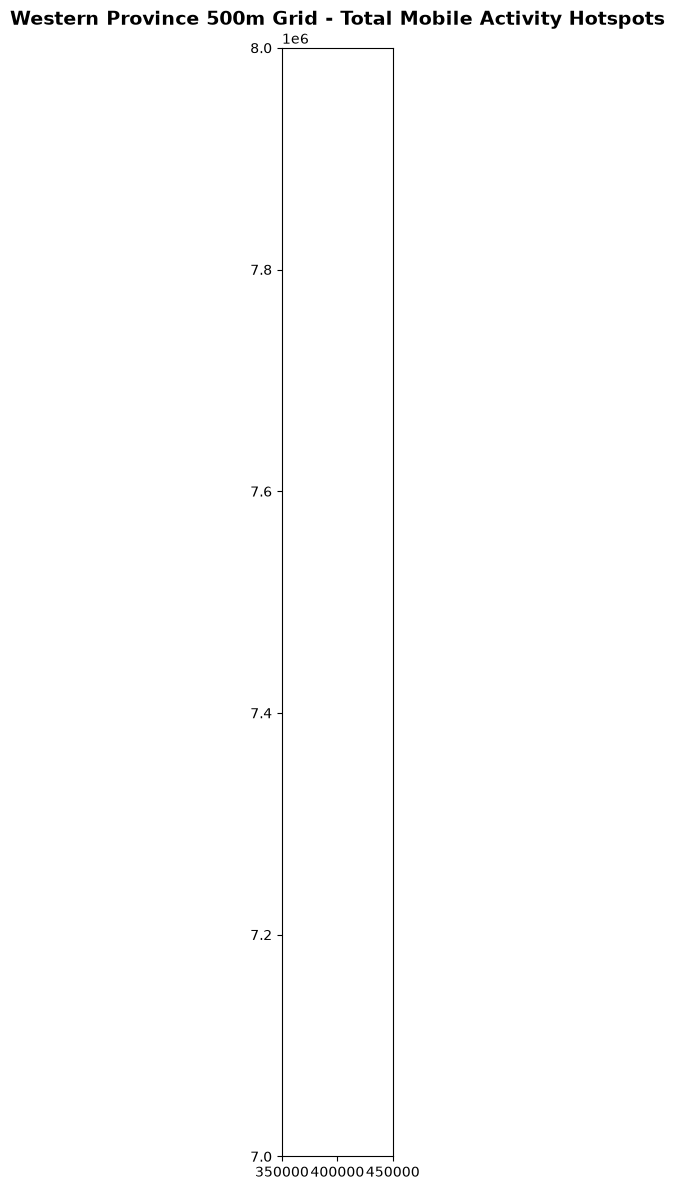

In [14]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt

# 1. Load your aggregated CSV
csv_path = r"D:\final_grid_with_y_variables.csv"
print("Loading aggregated grid CSV...")
df = pd.read_csv(csv_path)

print("Converting grid bins into 500m square polygons...")
grid_size = 500

# 2. Create square polygons using x_bin and y_bin bottom-left corners
polygons = [
    box(row['x_bin'], row['y_bin'], row['x_bin'] + grid_size, row['y_bin'] + grid_size)
    for _, row in df.iterrows()
]

# 3. Create GeoDataFrame
gdf = gpd.GeoDataFrame(df, geometry=polygons, crs="EPSG:32644")

# 4. Filter strictly to Western Province UTM spatial extents to prevent empty/zoomed-out plots
gdf_filtered = gdf[
    (gdf['x_bin'] > 350000) & (gdf['x_bin'] < 450000) &
    (gdf['y_bin'] > 7000000) & (gdf['y_bin'] < 8000000)
]

print(f"Plotting {len(gdf_filtered):,} valid grid cells...")

# 5. Plot Total Activity Count Hotspots
fig, ax = plt.subplots(1, 1, figsize=(10, 12))
gdf_filtered.plot(
    column='total_activity_count',
    ax=ax,
    legend=True,
    cmap='OrRd',          # Orange-Red colormap for hot spots
    scheme='quantiles',   # Natural quantile classification
    k=5,                  # 5 distinct classes
    missing_kwds={'color': 'lightgrey'}
)

# Lock coordinate frame to Western Province region
ax.set_xlim(350000, 450000)
ax.set_ylim(7000000, 8000000)
ax.set_aspect('equal')

plt.title('Western Province 500m Grid - Total Mobile Activity Hotspots', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
pip install geopandas matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 1.2 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/9.3 MB 1.1 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/9.3 MB 1.1 MB/s eta 0:00:08
   ---- ----------------------------------- 1.0/9.3 MB 1.1 MB/s eta 0:00:08
   ----- ---------------------------------- 1.3/9.3 MB 1.1 MB/s eta 0:00:08
   ------ --------------------------------- 1.6/9.3 MB 1.1 MB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.3 MB 1.1 MB/s eta 0:00:07
   ------- -------------------------------- 1.8/9.3 MB 1.1 MB/s eta 0:00:07
   -------- ------------------------------- 2.1/9.3 MB 1.1 MB/s eta 0:00:07
   ---------- ----------------------------- 2.4/9.3 MB 1.1 MB/s eta 0:00:07
   ----------- ---------------------------- 2.6/9.3 MB 1.1 MB/s eta 0:00:07
   ------------ ----------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ultralytics 8.4.41 requires torch!=2.4.0,>=1.8.0; sys_platform == "win32", which is not installed.
ultralytics 8.4.41 requires torch>=1.8.0, which is not installed.
ultralytics 8.4.41 requires torchvision>=0.9.0, which is not installed.
streamlit 1.46.1 requires packaging<26,>=20, but you have packaging 26.0 which is incompatible.
streamlit 1.46.1 requires pandas<3,>=1.4.0, but you have pandas 3.0.1 which is incompatible.
streamlit 1.46.1 requires pillow<12,>=7.1.0, but you have pillow 13.0.0 which is incompatible.

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Loading aggregated grid CSV...
Plotting 11,571 valid grid cells...


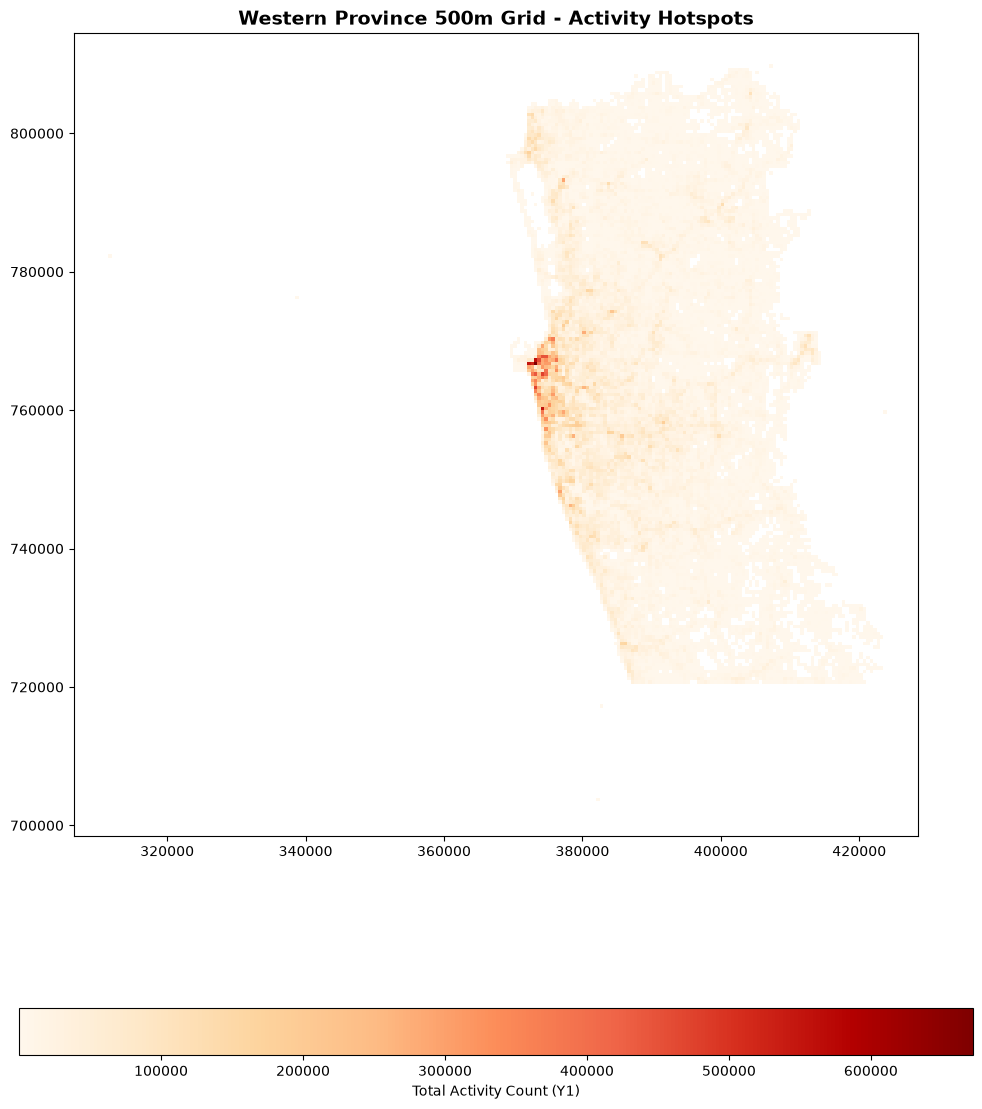

In [17]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt

# 1. Load your aggregated CSV
csv_path = r"D:\final_grid_with_y_variables.csv"
print("Loading aggregated grid CSV...")
df = pd.read_csv(csv_path)

# 2. Filter strictly to the main Western Province coordinate cluster
# (Excluding outlying coordinate noise from raw data artifacts)
df_clean = df[
    (df['x_bin'] >= 300000) & (df['x_bin'] <= 500000) &
    (df['y_bin'] >= 700000) & (df['y_bin'] <= 900000)
].copy()

print(f"Plotting {len(df_clean):,} valid grid cells...")

# 3. Create 500m square polygons
grid_size = 500
polygons = [
    box(row['x_bin'], row['y_bin'], row['x_bin'] + grid_size, row['y_bin'] + grid_size)
    for _, row in df_clean.iterrows()
]

gdf = gpd.GeoDataFrame(df_clean, geometry=polygons, crs="EPSG:32644")

# 4. Plot using standard quantile/linear bins or direct column values
fig, ax = plt.subplots(1, 1, figsize=(10, 12))

gdf.plot(
    column='total_activity_count',
    ax=ax,
    legend=True,
    cmap='OrRd',          # Orange-Red colormap for hot spots
    legend_kwds={'label': 'Total Activity Count (Y1)', 'orientation': 'horizontal'},
    missing_kwds={'color': 'lightgrey'}
)

# 5. Lock axis limits precisely to the Western Province extent
ax.set_xlim(df_clean['x_bin'].min() - 5000, df_clean['x_bin'].max() + 5000)
ax.set_ylim(df_clean['y_bin'].min() - 5000, df_clean['y_bin'].max() + 5000)
ax.set_aspect('equal')

plt.title('Western Province 500m Grid - Activity Hotspots', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:

import pandas as pd
import geopandas as gpd
import numpy as np
from pathlib import Path

# ============================================================
# 1. FILE PATHS - REPLACE WITH YOUR ACTUAL WINDOWS PATHS
# ============================================================

csv_path = Path(r"C:\Users\sanojan\Desktop\Sano\day23.csv")

shp_path = Path(
    r"C:\Users\sanojan\Desktop\Sano\Practical\ADM1_EN_Western.shp"
)

output_path = Path(r"D:\final_grid_with_y_variables.csv")

# ============================================================
# 2. RESEARCH SETTINGS
# ============================================================

GRID_SIZE = 500
CHUNK_SIZE = 500_000

# Sri Lanka Western Province: UTM Zone 44N, metres
GRID_CRS = "EPSG:32644"

# Input coordinates are longitude and latitude
INPUT_CRS = "EPSG:4326"

# ============================================================
# 3. CHECK INPUT FILES
# ============================================================

if not csv_path.exists():
    raise FileNotFoundError(f"CSV file not found: {csv_path}")

if not shp_path.exists():
    raise FileNotFoundError(f"Shapefile not found: {shp_path}")

output_path.parent.mkdir(parents=True, exist_ok=True)

required_columns = [
    "lon_pred",
    "lat_pred",
    "datetime"
]

# ============================================================
# 4. LOAD AND PREPARE WESTERN PROVINCE BOUNDARY
# ============================================================

print("Loading Western Province boundary...")

boundary = gpd.read_file(shp_path)

if boundary.empty:
    raise ValueError("The boundary shapefile contains no features.")

if boundary.crs is None:
    raise ValueError(
        "The boundary CRS is missing. Define its actual CRS "
        "before running this script."
    )

# Convert the boundary to the same projected CRS used for the grid.
boundary = boundary.to_crs(GRID_CRS)

# Dissolve all administrative features into one province boundary.
# This prevents duplicate matches along overlapping features.
boundary = boundary[["geometry"]].dissolve()

# Repair invalid geometries where possible.
boundary["geometry"] = boundary.geometry.make_valid()

# ============================================================
# 5. PROCESS CSV IN CHUNKS
# ============================================================

print("Starting chunked spatial processing...")

partial_results = []

total_rows_read = 0
valid_coordinate_rows = 0
rows_inside_boundary = 0
rows_with_valid_datetime = 0

for chunk_number, chunk in enumerate(
    pd.read_csv(
        csv_path,
        usecols=required_columns,
        encoding="latin-1",
        on_bad_lines="skip",
        chunksize=CHUNK_SIZE
    ),
    start=1
):

    total_rows_read += len(chunk)

    print(f"Processing chunk {chunk_number:,}...")

    # Convert coordinates to numeric values.
    chunk["lon_pred"] = pd.to_numeric(
        chunk["lon_pred"], errors="coerce"
    )

    chunk["lat_pred"] = pd.to_numeric(
        chunk["lat_pred"], errors="coerce"
    )

    # Parse timestamps.
    chunk["datetime"] = pd.to_datetime(
        chunk["datetime"], errors="coerce"
    )

    # Remove invalid coordinates and timestamps.
    chunk = chunk.dropna(
        subset=["lon_pred", "lat_pred", "datetime"]
    )

    # Exclude impossible longitude and latitude values.
    chunk = chunk[
        chunk["lon_pred"].between(-180, 180)
        & chunk["lat_pred"].between(-90, 90)
    ]

    if chunk.empty:
        continue

    valid_coordinate_rows += len(chunk)
    rows_with_valid_datetime += len(chunk)

    # Create geographic points from longitude and latitude.
    points = gpd.GeoDataFrame(
        chunk,
        geometry=gpd.points_from_xy(
            chunk["lon_pred"],
            chunk["lat_pred"]
        ),
        crs=INPUT_CRS
    )

    # Reproject points into the metric CRS used by the grid.
    points = points.to_crs(GRID_CRS)

    # Spatially select observations inside Western Province.
    points = gpd.sjoin(
        points,
        boundary[["geometry"]],
        how="inner",
        predicate="within"
    )

    if points.empty:
        continue

    rows_inside_boundary += len(points)

    # ========================================================
    # 6. CREATE CONSISTENT 500 m GRID IDENTIFIERS
    # ========================================================

    # Derive coordinates from the projected point geometry.
    # Do not mix these with potentially inconsistent UTM fields.
    points["x_bin"] = (
        np.floor(points.geometry.x / GRID_SIZE) * GRID_SIZE
    ).astype("int64")

    points["y_bin"] = (
        np.floor(points.geometry.y / GRID_SIZE) * GRID_SIZE
    ).astype("int64")

    # Extract hour of day: 0 through 23.
    points["hour"] = points["datetime"].dt.hour.astype("int8")

    # ========================================================
    # 7. AGGREGATE EACH CHUNK BEFORE RETAINING RESULTS
    # ========================================================

    chunk_counts = (
        points.groupby(
            ["x_bin", "y_bin", "hour"],
            observed=True
        )
        .size()
        .reset_index(name="activity_count")
    )

    partial_results.append(chunk_counts)

    del points, chunk, chunk_counts

# ============================================================
# 8. COMBINE PARTIAL AGGREGATIONS
# ============================================================

print("Combining aggregated results...")

if not partial_results:
    raise ValueError(
        "No valid mobile-activity records were found inside "
        "the Western Province boundary."
    )

hourly_counts = pd.concat(
    partial_results,
    ignore_index=True
)

# Sum counts across chunks for each grid and hour.
hourly_counts = (
    hourly_counts.groupby(
        ["x_bin", "y_bin", "hour"],
        as_index=False,
        observed=True
    )["activity_count"]
    .sum()
)

del partial_results

# ============================================================
# 9. CREATE Y1: TOTAL FUNCTIONAL ACTIVITY
# ============================================================

print("Calculating Y1: total activity per grid...")

y1 = (
    hourly_counts.groupby(
        ["x_bin", "y_bin"],
        as_index=False
    )["activity_count"]
    .sum()
    .rename(
        columns={"activity_count": "total_activity_count"}
    )
)

# ============================================================
# 10. CREATE Y2: 24-HOUR URBAN PULSE PROFILE
# ============================================================

print("Calculating Y2: hourly pulse profile...")

pulse = hourly_counts.pivot(
    index=["x_bin", "y_bin"],
    columns="hour",
    values="activity_count"
)

# Ensure every grid has all 24 hourly columns.
# Missing hours become zero observed records.
pulse = pulse.reindex(
    columns=range(24),
    fill_value=0
).fillna(0)

pulse.columns = [
    f"activity_{hour:02d}"
    for hour in range(24)
]

pulse = pulse.reset_index()
pulse.columns.name = None

# ============================================================
# 11. MERGE TARGET VARIABLES
# ============================================================

print("Merging target variables...")

final_grid = y1.merge(
    pulse,
    on=["x_bin", "y_bin"],
    how="left",
    validate="one_to_one"
)

# Create stable grid identifiers.
final_grid["grid_id"] = (
    final_grid["x_bin"].astype(str)
    + "_"
    + final_grid["y_bin"].astype(str)
)

# Reorder columns.
activity_columns = [
    f"activity_{hour:02d}"
    for hour in range(24)
]

final_grid = final_grid[
    [
        "grid_id",
        "x_bin",
        "y_bin",
        "total_activity_count",
        *activity_columns
    ]
]

# ============================================================
# 12. NORMALIZE Y2: RELATIVE HOURLY PULSE
# ============================================================

# Each hour represents its share of the grid's total activity.
# These variables describe the daily profile, not its magnitude.

for hour in range(24):
    activity_col = f"activity_{hour:02d}"
    pulse_col = f"pulse_{hour:02d}"

    final_grid[pulse_col] = (
        final_grid[activity_col]
        / final_grid["total_activity_count"].replace(0, np.nan)
    )

# ============================================================
# 13. SAVE FINAL GRID DATASET
# ============================================================

final_grid.to_csv(output_path, index=False)

print("\nProcessing completed successfully.")
print(f"CSV rows read: {total_rows_read:,}")
print(f"Rows with valid coordinates and timestamps: "
      f"{valid_coordinate_rows:,}")
print(f"Rows inside Western Province: {rows_inside_boundary:,}")
print(f"500 m grid cells with observed activity: {len(final_grid):,}")
print(f"Output saved to: {output_path}")

print("\nOutput variables:")
print("- grid_id, x_bin, y_bin")
print("- total_activity_count (Y1)")
print("- activity_00 to activity_23 (hourly counts)")
print("- pulse_00 to pulse_23 (normalized hourly profile, Y2)")


Loading Western Province boundary...
Starting chunked spatial processing...
Processing chunk 1...
Processing chunk 2...
Processing chunk 3...
Processing chunk 4...
Processing chunk 5...
Processing chunk 6...
Processing chunk 7...
Processing chunk 8...
Processing chunk 9...
Processing chunk 10...
Processing chunk 11...
Processing chunk 12...
Processing chunk 13...
Processing chunk 14...
Processing chunk 15...
Processing chunk 16...
Processing chunk 17...
Processing chunk 18...
Processing chunk 19...
Processing chunk 20...


C:\Users\sanojan\AppData\Local\Temp\ipykernel_20236\2939791643.py:89: DtypeWarning: Columns (0: lat_pred, 1: datetime) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk_number, chunk in enumerate(


Processing chunk 21...
Processing chunk 22...


C:\Users\sanojan\AppData\Local\Temp\ipykernel_20236\2939791643.py:89: DtypeWarning: Columns (0: lat_pred, 1: datetime) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk_number, chunk in enumerate(


Processing chunk 23...
Processing chunk 24...


C:\Users\sanojan\AppData\Local\Temp\ipykernel_20236\2939791643.py:89: DtypeWarning: Columns (0: lat_pred, 1: datetime) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk_number, chunk in enumerate(


... (203 outputs left out)

C:\Users\sanojan\AppData\Local\Temp\ipykernel_20236\2939791643.py:89: DtypeWarning: Columns (0: lat_pred, 1: datetime) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk_number, chunk in enumerate(


Processing chunk 506...
Processing chunk 507...
Processing chunk 508...


C:\Users\sanojan\AppData\Local\Temp\ipykernel_20236\2939791643.py:89: DtypeWarning: Columns (0: lat_pred, 1: datetime) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk_number, chunk in enumerate(


Processing chunk 509...
Processing chunk 510...
Processing chunk 511...
Processing chunk 512...
Processing chunk 513...
Processing chunk 514...
Processing chunk 515...
Processing chunk 516...
Processing chunk 517...
Combining aggregated results...
Calculating Y1: total activity per grid...
Calculating Y2: hourly pulse profile...
Merging target variables...

Processing completed successfully.
CSV rows read: 258,084,954
Rows with valid coordinates and timestamps: 257,888,663
Rows inside Western Province: 236,485,151
500 m grid cells with observed activity: 11,564
Output saved to: D:\final_grid_with_y_variables.csv

Output variables:
- grid_id, x_bin, y_bin
- total_activity_count (Y1)
- activity_00 to activity_23 (hourly counts)
- pulse_00 to pulse_23 (normalized hourly profile, Y2)


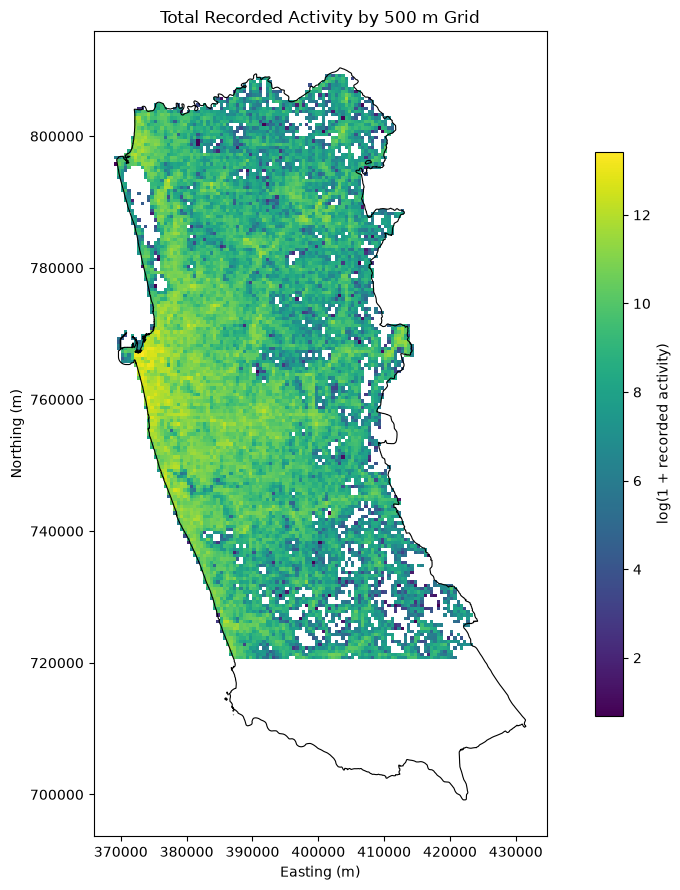

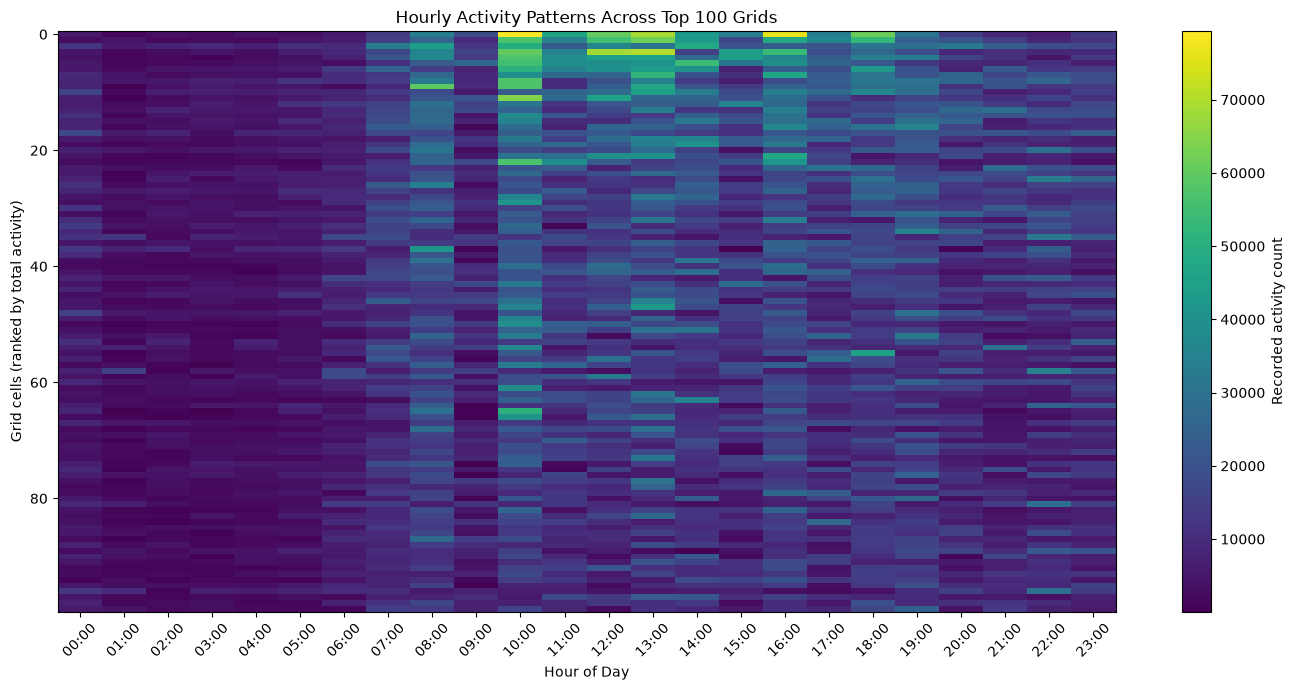

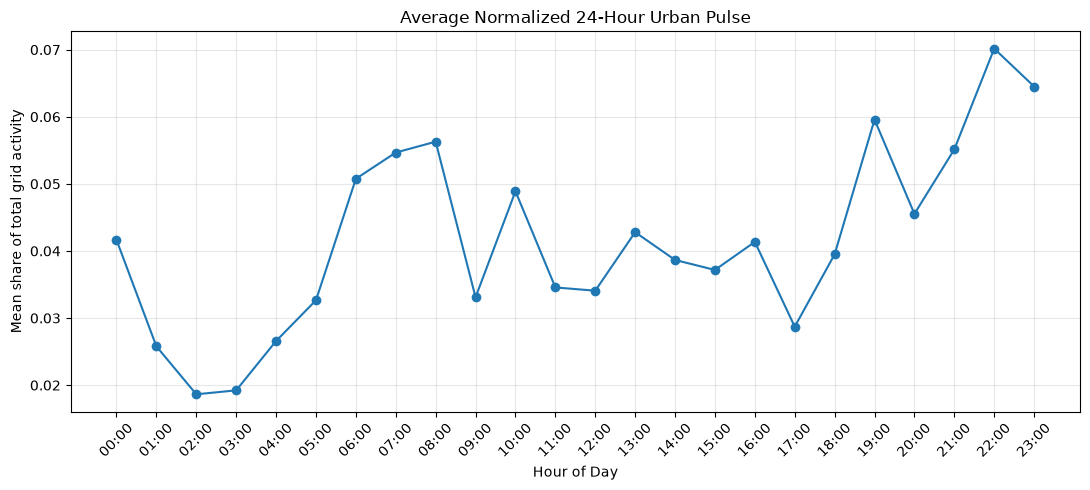

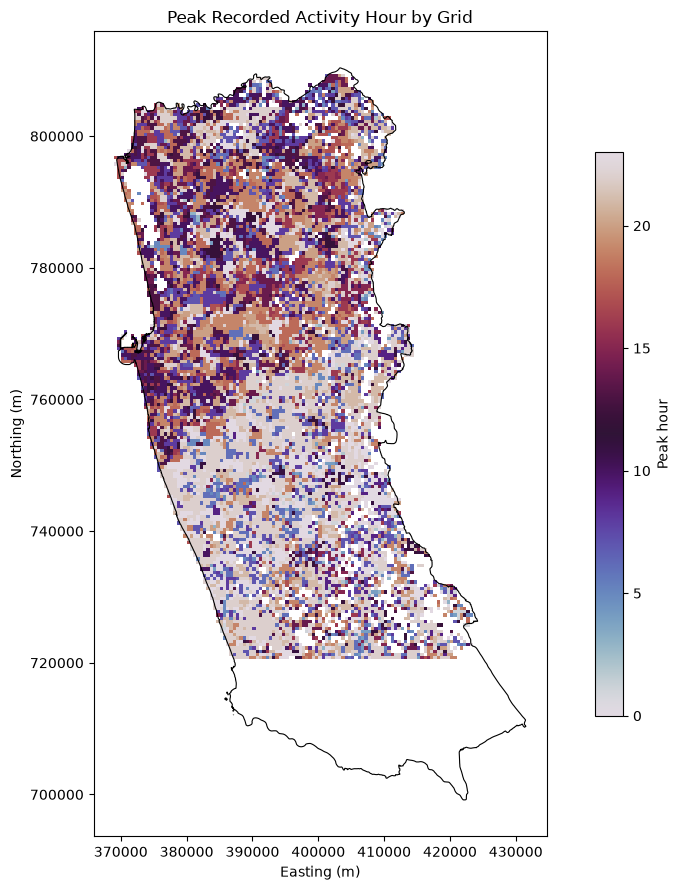


All visualizations completed.
Grid cells: 11,564
Saved to: D:\urban_activity_visualizations


In [19]:

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import box

# ======================================================
# 1. SET YOUR ACTUAL FILE PATHS
# ======================================================

csv_path = Path(r"D:\final_grid_with_y_variables.csv")

shp_path = Path(
    r"C:\Users\sanojan\Desktop\Sano\Practical\ADM1_EN_Western.shp"
)

output_dir = Path(r"D:\urban_activity_visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

GRID_SIZE = 500
CRS = "EPSG:32644"

if not csv_path.exists():
    raise FileNotFoundError(
        f"CSV not found: {csv_path}\n"
        "Update csv_path to the actual location of your output CSV."
    )

# ======================================================
# 2. LOAD DATA
# ======================================================

df = pd.read_csv(csv_path)

hourly_cols = [f"activity_{h:02d}" for h in range(24)]
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

required = [
    "grid_id", "x_bin", "y_bin", "total_activity_count"
] + hourly_cols

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns in CSV: {missing}")

for col in ["x_bin", "y_bin", "total_activity_count"] + hourly_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=["x_bin", "y_bin", "total_activity_count"]
).copy()

# Recalculate normalized pulse consistently.
denominator = df["total_activity_count"].replace(0, np.nan)

for h in range(24):
    df[f"pulse_{h:02d}"] = (
        df[f"activity_{h:02d}"] / denominator
    )

# Construct the 500 m grid polygons.
df["geometry"] = [
    box(x, y, x + GRID_SIZE, y + GRID_SIZE)
    for x, y in zip(df["x_bin"], df["y_bin"])
]

grid = gpd.GeoDataFrame(df, geometry="geometry", crs=CRS)

# Load study-area boundary if available.
boundary = None

if shp_path.exists():
    boundary = gpd.read_file(shp_path)

    if boundary.crs is None:
        raise ValueError(
            "Boundary CRS is missing. Assign its correct CRS first."
        )

    boundary = boundary.to_crs(CRS)

# ======================================================
# 3. MAP 1: TOTAL FUNCTIONAL ACTIVITY
# ======================================================

# Log scale improves visibility when activity counts are skewed.
grid["log_activity"] = np.log1p(
    grid["total_activity_count"].clip(lower=0)
)

fig, ax = plt.subplots(figsize=(10, 9))

grid.plot(
    column="log_activity",
    cmap="viridis",
    legend=True,
    linewidth=0,
    ax=ax,
    legend_kwds={
        "label": "log(1 + recorded activity)",
        "shrink": 0.7
    }
)

if boundary is not None:
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)

ax.set_title("Total Recorded Activity by 500 m Grid")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(output_dir / "01_total_activity_map.png",
            dpi=300, bbox_inches="tight")
plt.show()

# ======================================================
# 4. HEATMAP: ACTIVITY BY HOUR AND GRID
# ======================================================

# Show up to 100 highest-activity grids for readability.
top = grid.nlargest(100, "total_activity_count")

heat = top[hourly_cols].to_numpy()

fig, ax = plt.subplots(figsize=(14, 7))

im = ax.imshow(
    heat,
    aspect="auto",
    interpolation="nearest",
    cmap="viridis"
)

ax.set_title("Hourly Activity Patterns Across Top 100 Grids")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Grid cells (ranked by total activity)")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)],
                   rotation=45)

fig.colorbar(im, ax=ax, label="Recorded activity count")
plt.tight_layout()
plt.savefig(output_dir / "02_hourly_activity_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()

# ======================================================
# 5. CHART: NORMALIZED URBAN PULSE
# ======================================================

# Average normalized hourly profiles across observed grids.
pulse = grid[pulse_cols].mean(axis=0)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    range(24),
    pulse.to_numpy(),
    marker="o"
)

ax.set_title("Average Normalized 24-Hour Urban Pulse")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean share of total grid activity")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)],
                   rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(output_dir / "03_normalized_urban_pulse.png",
            dpi=300, bbox_inches="tight")
plt.show()

# ======================================================
# 6. MAP: PEAK ACTIVITY HOUR
# ======================================================

grid["peak_hour"] = grid[hourly_cols].to_numpy().argmax(axis=1)

grid.loc[
    grid["total_activity_count"] <= 0, "peak_hour"
] = np.nan

fig, ax = plt.subplots(figsize=(10, 9))

grid.plot(
    column="peak_hour",
    cmap="twilight",
    vmin=0,
    vmax=23,
    legend=True,
    linewidth=0,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "No recorded activity"
    },
    legend_kwds={
        "label": "Peak hour",
        "shrink": 0.7
    }
)

if boundary is not None:
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)

ax.set_title("Peak Recorded Activity Hour by Grid")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.savefig(output_dir / "04_peak_activity_hour_map.png",
            dpi=300, bbox_inches="tight")
plt.show()

# ======================================================
# 7. EXPORT SUMMARY
# ======================================================

grid.drop(columns="geometry").to_csv(
    output_dir / "grid_activity_visualization_data.csv",
    index=False
)

print("\nAll visualizations completed.")
print(f"Grid cells: {len(grid):,}")
print(f"Saved to: {output_dir}")


In [2]:

import pandas as pd
import numpy as np

csv_path = r"D:\final_grid_with_y_variables.csv"

df = pd.read_csv(csv_path)

hourly_cols = [f"activity_{h:02d}" for h in range(24)]

# Check grids represented in the current output
print("Total grid cells in CSV:", len(df))

# Identify cells with zero total activity
zero_cells = df[df["total_activity_count"] == 0]

print("Cells with zero total activity:", len(zero_cells))

# Check cells where all hourly counts are zero
all_zero_hourly = (
    df[hourly_cols].fillna(0).sum(axis=1) == 0
)

print("Cells with all hourly counts zero:", all_zero_hourly.sum())

# Check for missing hourly values
print(
    "Missing hourly values:",
    df[hourly_cols].isna().sum().sum()
)

# Export grids with no recorded activity, if any
zero_cells.to_csv(
    r"D:\zero_activity_grid_cells.csv",
    index=False
)

print("Check complete.")


Total grid cells in CSV: 11564
Cells with zero total activity: 0
Cells with all hourly counts zero: 0
Missing hourly values: 0
Check complete.


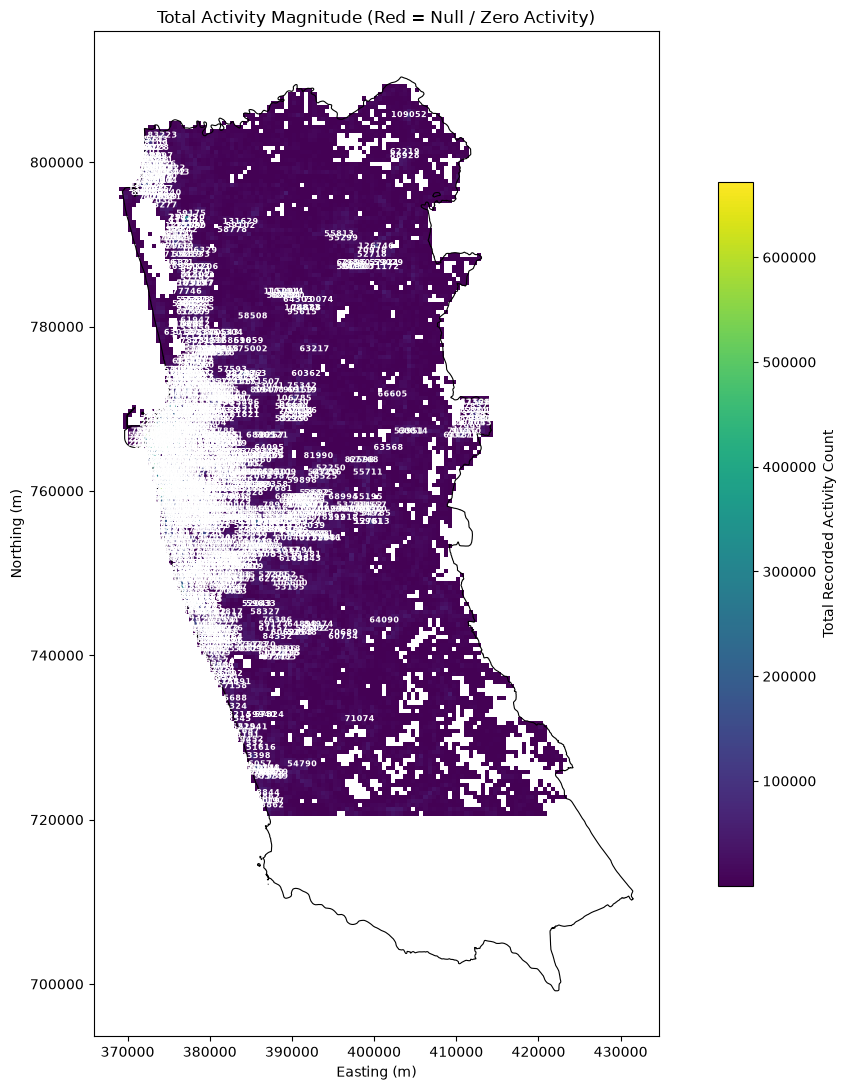

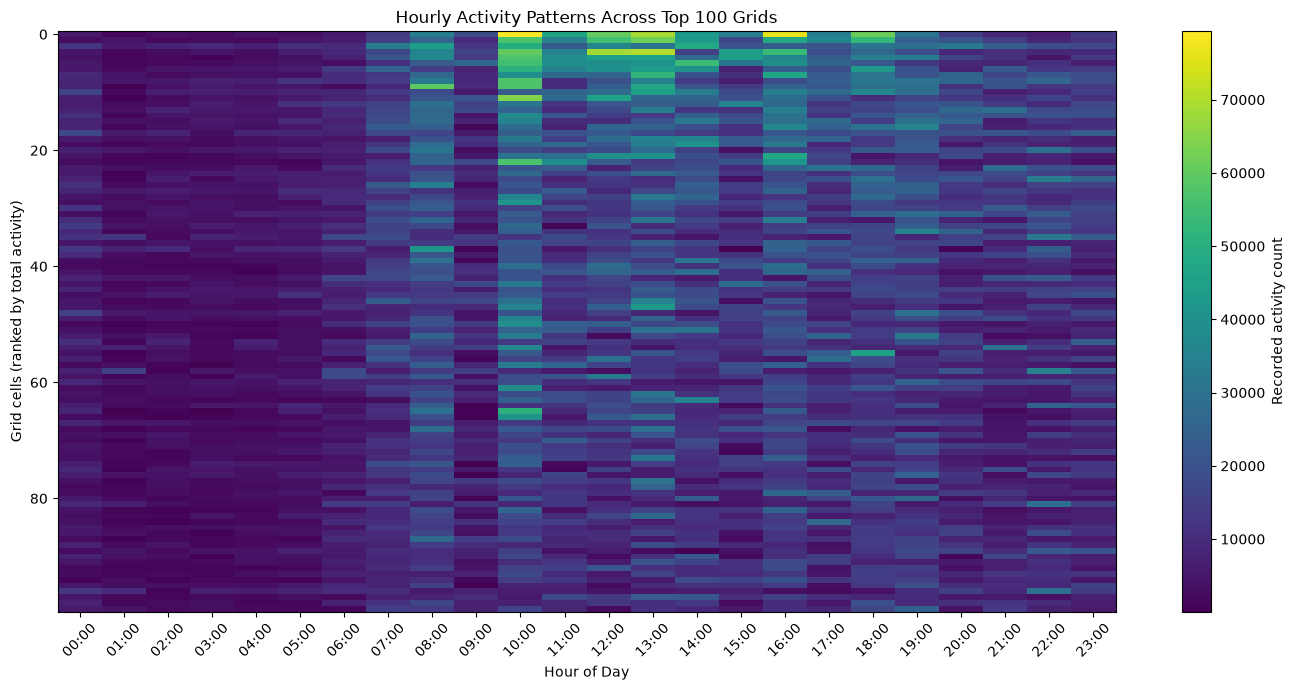

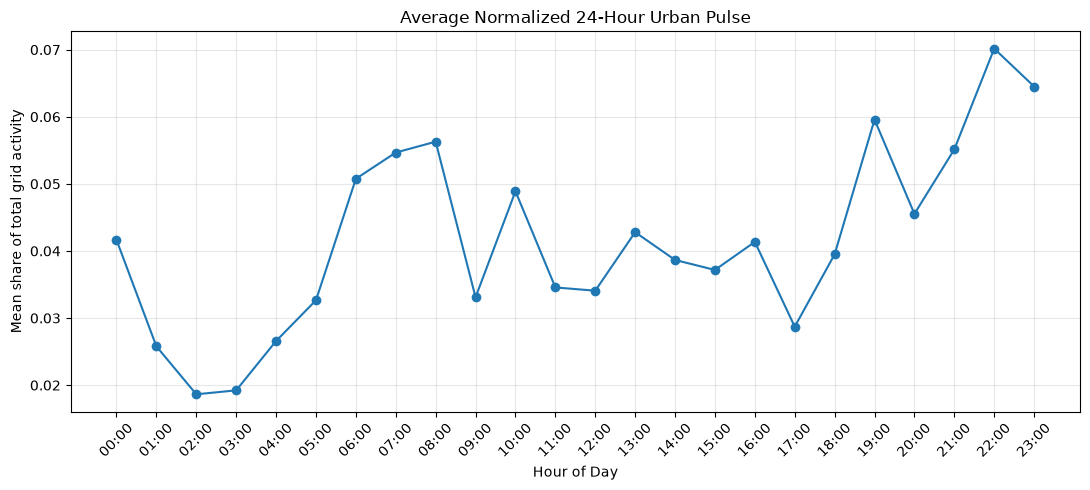

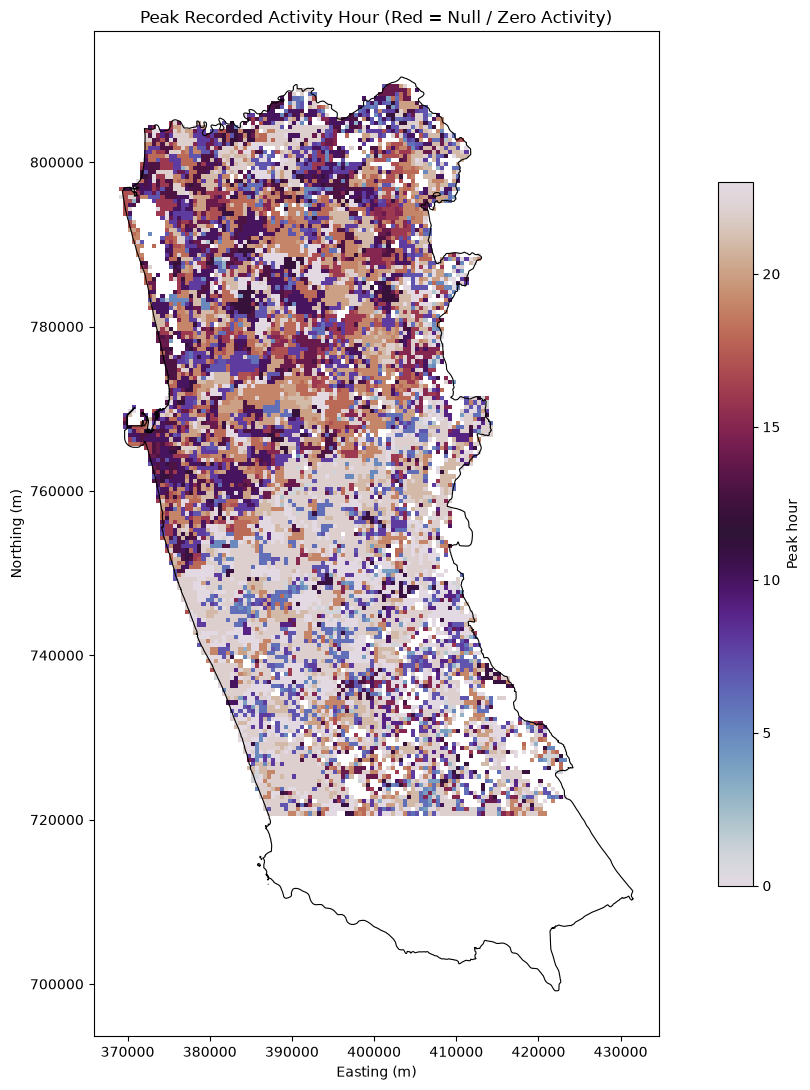


All visualizations displayed interactively.
Total processed grid cells: 11,564
Null/Zero activity cells highlighted in red: 0


In [4]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import box

# ======================================================
# 1. SET YOUR ACTUAL FILE PATHS
# ======================================================

csv_path = Path(r"D:\final_grid_with_y_variables.csv")
shp_path = Path(
    r"C:\Users\sanojan\Desktop\Sano\Practical\ADM1_EN_Western.shp"
)

GRID_SIZE = 500
CRS = "EPSG:32644"

if not csv_path.exists():
    raise FileNotFoundError(
        f"CSV not found: {csv_path}\n"
        "Update csv_path to the actual location of your output CSV."
    )

# ======================================================
# 2. LOAD DATA & HANDLE NULLS EXPLICITLY
# ======================================================

df = pd.read_csv(csv_path)

hourly_cols = [f"activity_{h:02d}" for h in range(24)]
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

required = [
    "grid_id", "x_bin", "y_bin", "total_activity_count"
] + hourly_cols

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns in CSV: {missing}")

for col in ["x_bin", "y_bin", "total_activity_count"] + hourly_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Instead of dropping nulls, we keep them so we can color them red!
# We flag valid vs missing/zero activity cells.
df["is_missing_or_zero"] = (
    df["x_bin"].isna() | 
    df["y_bin"].isna() | 
    df["total_activity_count"].isna() | 
    (df["total_activity_count"] <= 0)
)

# Recalculate normalized pulse consistently.
denominator = df["total_activity_count"].replace(0, np.nan)

for h in range(24):
    df[f"pulse_{h:02d}"] = (
        df[f"activity_{h:02d}"] / denominator
    )

# Construct the 500 m grid polygons.
df["geometry"] = [
    box(x, y, x + GRID_SIZE, y + GRID_SIZE)
    if pd.notna(x) and pd.notna(y) else None
    for x, y in zip(df["x_bin"], df["y_bin"])
]

# Drop rows where geometry couldn't be formed
df = df.dropna(subset=["geometry"]).copy()
grid = gpd.GeoDataFrame(df, geometry="geometry", crs=CRS)

# Load study-area boundary if available.
boundary = None

if shp_path.exists():
    boundary = gpd.read_file(shp_path)

    if boundary.crs is None:
        raise ValueError(
            "Boundary CRS is missing. Assign its correct CRS first."
        )

    boundary = boundary.to_crs(CRS)

# ======================================================
# 3. MAP 1: RAW TOTAL ACTIVITY (NULLS/ZEROES IN RED)
# ======================================================

fig, ax = plt.subplots(figsize=(12, 11))

# Split into valid data and missing/zero data
valid_grid = grid[~grid["is_missing_or_zero"]]
null_grid = grid[grid["is_missing_or_zero"]]

# Plot valid activity magnitude
valid_grid.plot(
    column="total_activity_count",
    cmap="viridis",
    legend=True,
    linewidth=0,
    ax=ax,
    legend_kwds={
        "label": "Total Recorded Activity Count",
        "shrink": 0.7
    }
)

# Plot missing/zero activity cells in bright red
if not null_grid.empty:
    null_grid.plot(
        color="red",
        linewidth=0,
        ax=ax,
        label="Null / Zero Activity"
    )

if boundary is not None:
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)

# Print activity values on top 10% highest activity cells for clarity
label_threshold = valid_grid["total_activity_count"].quantile(0.90)
for _, row in valid_grid[valid_grid["total_activity_count"] >= label_threshold].iterrows():
    centroid = row["geometry"].centroid
    ax.text(
        centroid.x, centroid.y, 
        f"{int(row['total_activity_count'])}", 
        fontsize=6, 
        ha="center", 
        va="center", 
        color="white",
        weight="bold"
    )

ax.set_title("Total Activity Magnitude (Red = Null / Zero Activity)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# ======================================================
# 4. HEATMAP: ACTIVITY BY HOUR AND GRID
# ======================================================

top = valid_grid.nlargest(100, "total_activity_count")
heat = top[hourly_cols].to_numpy()

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(
    heat,
    aspect="auto",
    interpolation="nearest",
    cmap="viridis"
)

ax.set_title("Hourly Activity Patterns Across Top 100 Grids")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Grid cells (ranked by total activity)")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45)

fig.colorbar(im, ax=ax, label="Recorded activity count")
plt.tight_layout()
plt.show()

# ======================================================
# 5. CHART: NORMALIZED URBAN PULSE
# ======================================================

pulse = valid_grid[pulse_cols].mean(axis=0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(range(24), pulse.to_numpy(), marker="o")
ax.set_title("Average Normalized 24-Hour Urban Pulse")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean share of total grid activity")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ======================================================
# 6. MAP: PEAK ACTIVITY HOUR (NULLS/ZEROES IN RED)
# ======================================================

grid["peak_hour"] = grid[hourly_cols].to_numpy().argmax(axis=1)

fig, ax = plt.subplots(figsize=(12, 11))

valid_peak = grid[~grid["is_missing_or_zero"]]
null_peak = grid[grid["is_missing_or_zero"]]

valid_peak.plot(
    column="peak_hour",
    cmap="twilight",
    vmin=0,
    vmax=23,
    legend=True,
    linewidth=0,
    ax=ax,
    legend_kwds={"label": "Peak hour", "shrink": 0.7}
)

if not null_peak.empty:
    null_peak.plot(
        color="red",
        linewidth=0,
        ax=ax
    )

if boundary is not None:
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)

ax.set_title("Peak Recorded Activity Hour (Red = Null / Zero Activity)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

print("\nAll visualizations displayed interactively.")
print(f"Total processed grid cells: {len(grid):,}")
print(f"Null/Zero activity cells highlighted in red: {len(null_grid):,}")

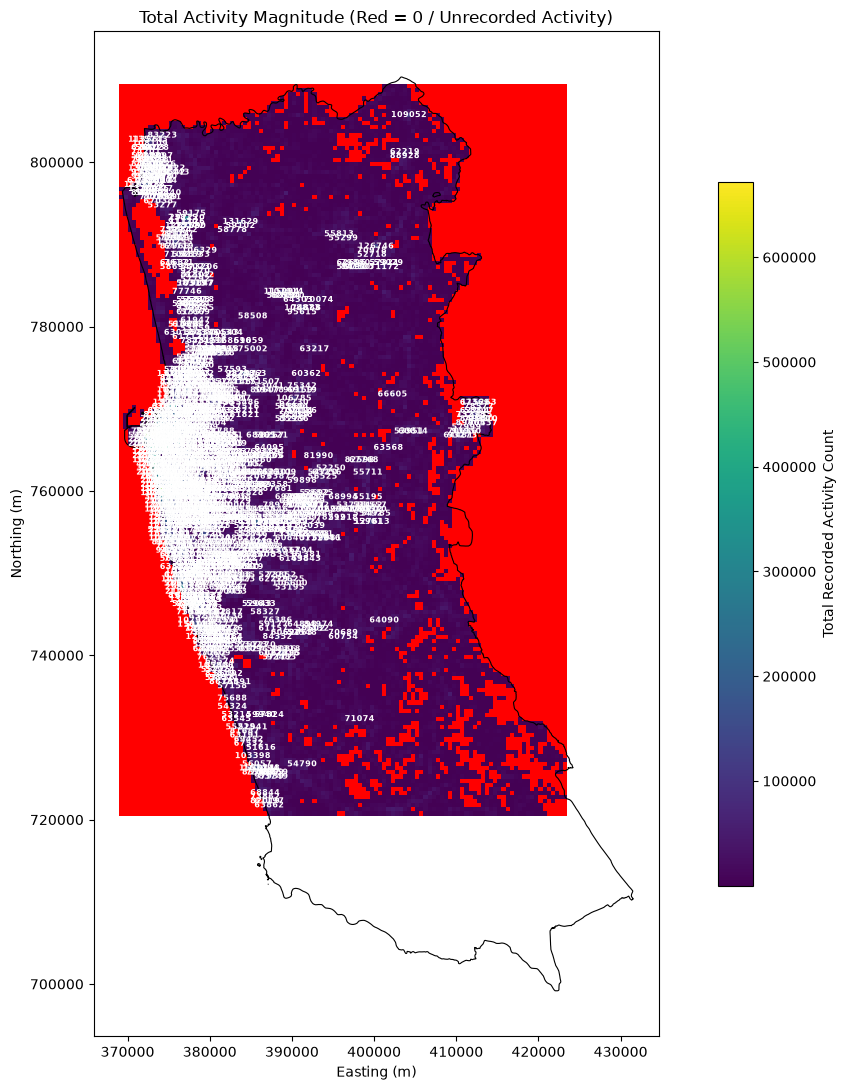

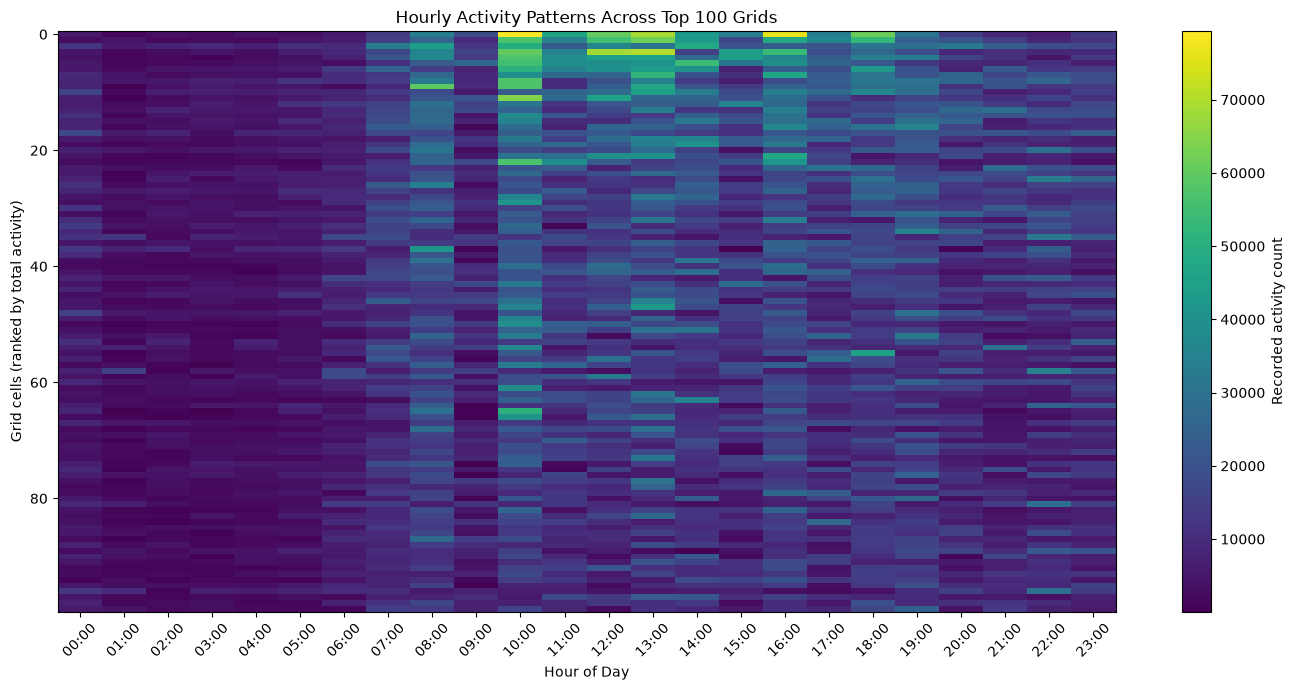

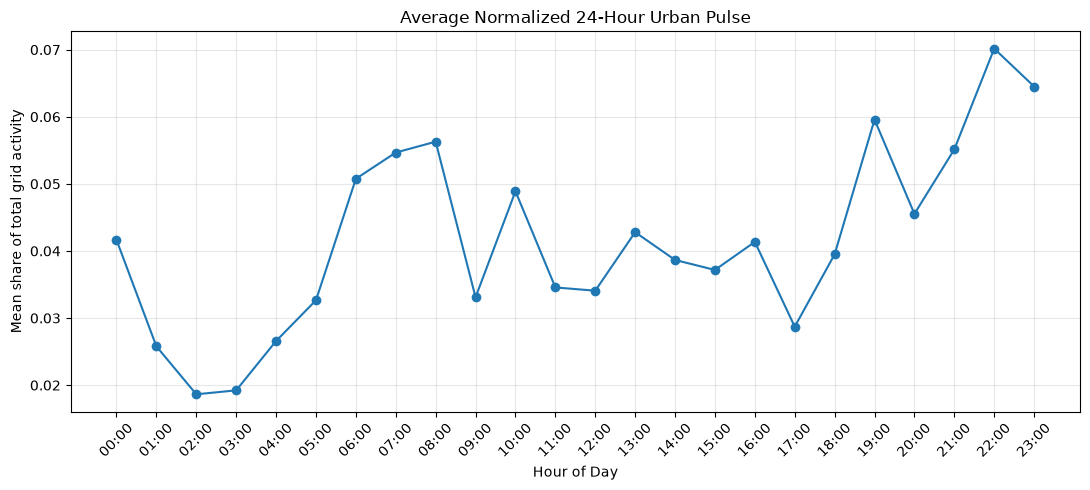

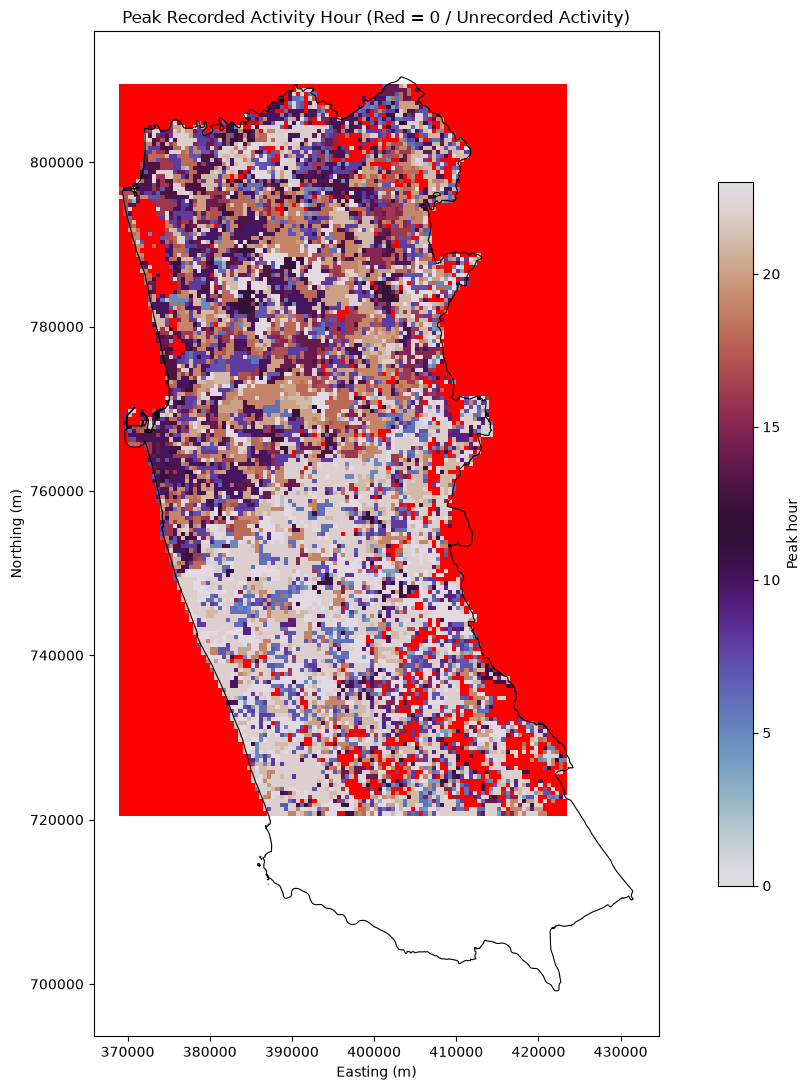


All visualizations displayed interactively.
Total grid cells in full mesh: 19,402
Cells with activity: 11,564
Cells with 0 / unrecorded activity (colored red): 7,838


In [5]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import box

# ======================================================
# 1. SET YOUR ACTUAL FILE PATHS
# ======================================================

csv_path = Path(r"D:\final_grid_with_y_variables.csv")
shp_path = Path(
    r"C:\Users\sanojan\Desktop\Sano\Practical\ADM1_EN_Western.shp"
)

GRID_SIZE = 500
CRS = "EPSG:32644"

if not csv_path.exists():
    raise FileNotFoundError(
        f"CSV not found: {csv_path}\n"
        "Update csv_path to the actual location of your output CSV."
    )

# ======================================================
# 2. LOAD DATA & CREATE FULL RECTANGULAR MESH
# ======================================================

df = pd.read_csv(csv_path)

hourly_cols = [f"activity_{h:02d}" for h in range(24)]
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

# Generate a complete grid mesh covering all x and y bins
x_min, x_max = df["x_bin"].min(), df["x_bin"].max()
y_min, y_max = df["y_bin"].min(), df["y_bin"].max()

x_vals = np.arange(x_min, x_max + GRID_SIZE, GRID_SIZE)
y_vals = np.arange(y_min, y_max + GRID_SIZE, GRID_SIZE)
xx, yy = np.meshgrid(x_vals, y_vals)
full_mesh = pd.DataFrame({"x_bin": xx.ravel(), "y_bin": yy.ravel()})

# Merge original data into the full mesh (left join ensures all grid cells exist)
df = pd.merge(full_mesh, df, on=["x_bin", "y_bin"], how="left")

# Fill unrecorded/missing cells with 0 activity
df["total_activity_count"] = df["total_activity_count"].fillna(0)
for col in hourly_cols:
    df[col] = df[col].fillna(0)

df["grid_id"] = df["grid_id"].fillna("empty_cell")

# Flag cells with zero activity
df["is_zero_activity"] = df["total_activity_count"] <= 0

# Recalculate normalized pulse safely
denominator = df["total_activity_count"].replace(0, np.nan)
for h in range(24):
    df[f"pulse_{h:02d}"] = df[f"activity_{h:02d}"] / denominator

# Construct the 500 m grid polygons for ALL cells
df["geometry"] = [
    box(x, y, x + GRID_SIZE, y + GRID_SIZE)
    for x, y in zip(df["x_bin"], df["y_bin"])
]

grid = gpd.GeoDataFrame(df, geometry="geometry", crs=CRS)

# Load study-area boundary if available.
boundary = None
if shp_path.exists():
    boundary = gpd.read_file(shp_path)
    if boundary.crs is None:
        raise ValueError("Boundary CRS is missing. Assign its correct CRS first.")
    boundary = boundary.to_crs(CRS)

# ======================================================
# 3. MAP 1: RAW TOTAL ACTIVITY (ZERO/UNRECORDED IN RED)
# ======================================================

fig, ax = plt.subplots(figsize=(12, 11))

valid_grid = grid[~grid["is_zero_activity"]]
zero_grid = grid[grid["is_zero_activity"]]

# Plot valid activity magnitude
valid_grid.plot(
    column="total_activity_count",
    cmap="viridis",
    legend=True,
    linewidth=0,
    ax=ax,
    legend_kwds={
        "label": "Total Recorded Activity Count",
        "shrink": 0.7
    }
)

# Plot zero activity / unrecorded cells in bright red
if not zero_grid.empty:
    zero_grid.plot(
        color="red",
        linewidth=0,
        ax=ax
    )

if boundary is not None:
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)

# Print activity values on top 10% highest activity cells for clarity
label_threshold = valid_grid["total_activity_count"].quantile(0.90)
for _, row in valid_grid[valid_grid["total_activity_count"] >= label_threshold].iterrows():
    centroid = row["geometry"].centroid
    ax.text(
        centroid.x, centroid.y, 
        f"{int(row['total_activity_count'])}", 
        fontsize=6, 
        ha="center", 
        va="center", 
        color="white",
        weight="bold"
    )

ax.set_title("Total Activity Magnitude (Red = 0 / Unrecorded Activity)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# ======================================================
# 4. HEATMAP: ACTIVITY BY HOUR AND GRID
# ======================================================

top = valid_grid.nlargest(100, "total_activity_count")
heat = top[hourly_cols].to_numpy()

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(
    heat,
    aspect="auto",
    interpolation="nearest",
    cmap="viridis"
)

ax.set_title("Hourly Activity Patterns Across Top 100 Grids")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Grid cells (ranked by total activity)")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45)

fig.colorbar(im, ax=ax, label="Recorded activity count")
plt.tight_layout()
plt.show()

# ======================================================
# 5. CHART: NORMALIZED URBAN PULSE
# ======================================================

pulse = valid_grid[pulse_cols].mean(axis=0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(range(24), pulse.to_numpy(), marker="o")
ax.set_title("Average Normalized 24-Hour Urban Pulse")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean share of total grid activity")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ======================================================
# 6. MAP: PEAK ACTIVITY HOUR (ZERO/UNRECORDED IN RED)
# ======================================================

grid["peak_hour"] = grid[hourly_cols].to_numpy().argmax(axis=1)
grid.loc[grid["is_zero_activity"], "peak_hour"] = np.nan

fig, ax = plt.subplots(figsize=(12, 11))

valid_peak = grid[~grid["is_zero_activity"]]
zero_peak = grid[grid["is_zero_activity"]]

valid_peak.plot(
    column="peak_hour",
    cmap="twilight",
    vmin=0,
    vmax=23,
    legend=True,
    linewidth=0,
    ax=ax,
    legend_kwds={"label": "Peak hour", "shrink": 0.7}
)

if not zero_peak.empty:
    zero_peak.plot(
        color="red",
        linewidth=0,
        ax=ax
    )

if boundary is not None:
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)

ax.set_title("Peak Recorded Activity Hour (Red = 0 / Unrecorded Activity)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

print("\nAll visualizations displayed interactively.")
print(f"Total grid cells in full mesh: {len(grid):,}")
print(f"Cells with activity: {len(valid_grid):,}")
print(f"Cells with 0 / unrecorded activity (colored red): {len(zero_grid):,}")

In [2]:
pip install exactextract

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 3.3 MB/s eta 0:00:01
   ------------ --------------------------- 0.5/1.7 MB 3.3 MB/s eta 0:00:01
   ------------------ --------------------- 0.8/1.7 MB 1.8 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 1.4 MB/s eta 0:00:01
   ------------------------------- -------- 1.3/1.7 MB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 1.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

from exactextract import exact_extract

print("Calculating building heights using exactextract...")

# Keep valid polygon geometries and a stable identifier
valid_mask = (
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
    & buildings.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
)

buildings = buildings.loc[valid_mask].copy()
buildings = buildings.reset_index(drop=True)

# ExactExtract calculates raster statistics for polygons efficiently.
# Ensure the vector layer and raster use their respective correct CRSs.
height_results = exact_extract(
    RASTER_PATH,
    buildings[["building_id", "geometry"]],
    ["mean"],
    include_cols=["building_id"],
    output="pandas"
)

# Match results by building ID rather than assuming row order
height_results = height_results.rename(
    columns={"mean": "height"}
)

height_results["height"] = pd.to_numeric(
    height_results["height"], errors="coerce"
)

height_lookup = height_results.set_index(
    "building_id"
)["height"]

buildings["height"] = buildings["building_id"].map(
    height_lookup
)

print("Height extraction completed.")
print("Buildings processed:", len(buildings))
print("Valid heights:", buildings["height"].notna().sum())
print("Missing heights:", buildings["height"].isna().sum())


Calculating building heights using exactextract...


NameError: name 'buildings' is not defined

In [8]:
import rasterio
from pathlib import Path

raster_path = Path(
    r"D:\Centrality\western_building_heights_2023.tif"
)

print("File exists:", raster_path.exists())
print("Rasterio version:", rasterio.__version__)

File exists: True
Rasterio version: 1.4.3


In [9]:
gdal_translate -of GTiff -co TILED=YES -co COMPRESS=DEFLATE "D:\Centrality\western_building_heights_2023.tif" "D:\Centrality\western_building_heights_2023_fixed.tif"

SyntaxError: invalid syntax (815793573.py, line 1)

In [ ]:
pip install geopandas rasterio rasterstats fiona pandas numpy

In [6]:
pip install fiona

  Using cached fiona-1.10.1-cp313-cp313-win_amd64.whl.metadata (58 kB)
   ---------------------------------------- 0.0/24.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.5 MB ? eta -:--:--
    --------------------------------------- 0.5/24.5 MB 3.2 MB/s eta 0:00:08
   - -------------------------------------- 1.0/24.5 MB 1.7 MB/s eta 0:00:15
   - -------------------------------------- 1.0/24.5 MB 1.7 MB/s eta 0:00:15
   -- ------------------------------------- 1.3/24.5 MB 1.4 MB/s eta 0:00:17
   -- ------------------------------------- 1.6/24.5 MB 1.4 MB/s eta 0:00:16
   --- ------------------------------------ 1.8/24.5 MB 1.4 MB/s eta 0:00:17
   --- ------------------------------------ 2.1/24.5 MB 1.4 MB/s eta 0:00:17
   --- ------------------------------------ 2.4/24.5 MB 1.3 MB/s eta 0:00:17
   ---- ----------------------------------- 2.6/24.5 MB 1.3 MB/s eta 0:00:17
   ---- ----------------------------------- 2.9/24.5 MB 1.3 MB/s eta 0:00:17
   ----- ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import geopandas as gpd
import numpy as np
import pandas as pd

# 1. Define file paths
grid_path = r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
roads_path = r"C:\Users\sanojan\Downloads\Roaddd\cliped Roads SDNA.shp"

print("Loading grid and sDNA road layers...")
grid_df = gpd.read_file(grid_path)
roads_df = gpd.read_file(roads_path)

# 2. Ensure matching projected CRS
if grid_df.crs.is_geographic:
  grid_df = grid_df.to_crs(epsg=32644)  # Adjust EPSG if necessary
if roads_df.crs != grid_df.crs:
  roads_df = roads_df.to_crs(grid_df.crs)

print("Performing spatial intersection of lines with grid polygons...")
intersected_roads = gpd.overlay(roads_df, grid_df, how="intersection")

# Calculate segment lengths for weighting
intersected_roads["seg_len"] = intersected_roads.geometry.length

# 3. Define the new multi-radius sDNA metrics to calculate
new_metrics = {
    "MAD1500": "MAD1500",
    "BtA1500": "BtA1500",
    "MAD5000": "MAD5000",
    "BtA5000": "BtA5000",
    "MAD7500": "MAD7500",
    "BtA7500": "BtA7500",
}


# Function to calculate length-weighted mean
def weighted_mean(group, value_col, weight_col):
  weights = group[weight_col]
  values = group[value_col]
  if weights.sum() == 0 or values.isna().all():
    return np.nan
  valid = ~values.isna() & ~weights.isna()
  if not valid.any():
    return np.nan
  return np.average(values[valid], weights=weights[valid])


print("Aggregating new multi-radius network measures to grid level...")

# Initialize aggregation table with unique grid IDs from the existing grid file
aggregated_data = pd.DataFrame({"grid_id": grid_df["grid_id"].unique()})

# Compute length-weighted mean for each new target metric
for metric_name, col in new_metrics.items():
  if col in intersected_roads.columns:
    weighted_vals = []
    for g_id, group in intersected_roads.groupby("grid_id"):
      wm = weighted_mean(group, col, "seg_len")
      weighted_vals.append({"grid_id": g_id, f"{col}_wt": wm})
    temp_df = pd.DataFrame(weighted_vals)
    aggregated_data = aggregated_data.merge(temp_df, on="grid_id", how="left")
  else:
    print(f"Warning: Column '{col}' not found in road layer attributes.")

# 4. Merge results back into the main grid layer (updating the existing file)
final_grid = grid_df.merge(aggregated_data, on="grid_id", how="left")

# Fill missing values with 0 for cells lacking roads across the new columns
for col in aggregated_data.columns:
  if col != "grid_id" and col in final_grid.columns:
    final_grid[col] = final_grid[col].fillna(0)

# 5. Save the updated grid layer back out
output_path = r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork_Updated.shp"
final_grid.to_file(output_path)

print(f"Success! Updated grid with multi-radius metrics saved to: {output_path}")

Loading grid and sDNA road layers...
Performing spatial intersection of lines with grid polygons...
Aggregating new multi-radius network measures to grid level...
Success! Updated grid with multi-radius metrics saved to: C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork_Updated.shp


In [5]:

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import shapely

# ============================================================
# 1. INPUT AND OUTPUT PATHS
# ============================================================

BUILDINGS_PATH = r"C:\Users\sanojan\Downloads\Buildings_with_Height_Floors.gpkg"
BUILDINGS_LAYER = "buildings"

# CHANGE THIS to your actual uploaded grid file
GRID_PATH = r"D:\Centrality\Grid_500m.shp"

OUTPUT_PATH = r"D:\Centrality\Grid_BCR_FAR.gpkg"

BATCH_SIZE = 25000

# ============================================================
# 2. LOAD AND PREPARE GRID
# ============================================================

grid = gpd.read_file(GRID_PATH).reset_index(drop=True)

if grid.crs is None:
    raise ValueError("Grid CRS is missing. Define the correct CRS first.")

# The study uses metric areas in UTM Zone 44N
TARGET_CRS = "EPSG:32644"

grid = grid.to_crs(TARGET_CRS)
grid["grid_id"] = np.arange(len(grid), dtype=np.int64)

# Use actual polygon area rather than assuming every cell
# has precisely 250,000 square metres.
grid["grid_area_m2"] = grid.geometry.area

if (grid["grid_area_m2"] <= 0).any():
    raise ValueError("Some grid cells have zero or invalid area.")

n_grid = len(grid)

# Accumulators
building_footprint_area = np.zeros(n_grid, dtype=np.float64)
estimated_floor_area = np.zeros(n_grid, dtype=np.float64)
footprint_with_known_floors = np.zeros(n_grid, dtype=np.float64)

print("Grid cells:", n_grid)
print("Grid CRS:", grid.crs)
print("Building batch size:", BATCH_SIZE)

# ============================================================
# 3. READ BUILDING COUNT AND PROCESS IN BATCHES
# ============================================================

info = pyogrio.read_info(
    BUILDINGS_PATH,
    layer=BUILDINGS_LAYER
)

total_buildings = info["features"]
print("Total input buildings:", total_buildings)

for start in range(0, total_buildings, BATCH_SIZE):

    batch = pyogrio.read_dataframe(
        BUILDINGS_PATH,
        layer=BUILDINGS_LAYER,
        skip_features=start,
        max_features=BATCH_SIZE,
        columns=["estimated_floors"],
        read_geometry=True
    )

    if batch.empty:
        continue

    # Align the building and grid coordinate systems
    if batch.crs != grid.crs:
        batch = batch.to_crs(grid.crs)

    # Ignore null and empty geometries
    batch = batch[
        batch.geometry.notna() & ~batch.geometry.is_empty
    ].copy()

    if batch.empty:
        continue

    # Convert floor estimates to numeric values.
    floors = pd.to_numeric(
        batch["estimated_floors"],
        errors="coerce"
    ).to_numpy(dtype=float)

    # Find all grid cells intersecting each building.
    joined = gpd.sjoin(
        batch[["estimated_floors", "geometry"]],
        grid[["grid_id", "geometry"]],
        how="inner",
        predicate="intersects"
    )

    if not joined.empty:

        # Get the relevant grid polygon for each building-grid pair.
        grid_positions = joined["index_right"].to_numpy(dtype=int)

        grid_geometries = grid.geometry.iloc[
            grid_positions
        ].array

        # Calculate the portion of each building inside each cell.
        intersections = shapely.intersection(
            joined.geometry.array,
            grid_geometries
        )

        intersection_areas = shapely.area(intersections)

        # Keep only finite, positive intersection areas.
        valid = (
            np.isfinite(intersection_areas)
            & (intersection_areas > 0)
        )

        joined = joined.iloc[np.flatnonzero(valid)].copy()
        intersection_areas = intersection_areas[valid]

        if len(joined):

            ids = joined["grid_id"].to_numpy(dtype=int)

            # BCR: all valid building footprints contribute,
            # including buildings whose heights are missing.
            building_footprint_area += np.bincount(
                ids,
                weights=intersection_areas,
                minlength=n_grid
            )

            # FAR: only buildings with valid floor estimates
            # contribute to estimated floor area.
            floors_joined = pd.to_numeric(
                joined["estimated_floors"],
                errors="coerce"
            ).to_numpy(dtype=float)

            valid_floors = (
                np.isfinite(floors_joined)
                & (floors_joined >= 1)
            )

            if valid_floors.any():
                known_ids = ids[valid_floors]
                known_areas = intersection_areas[valid_floors]
                known_floors = floors_joined[valid_floors]

                estimated_floor_area += np.bincount(
                    known_ids,
                    weights=known_areas * known_floors,
                    minlength=n_grid
                )

                footprint_with_known_floors += np.bincount(
                    known_ids,
                    weights=known_areas,
                    minlength=n_grid
                )

    completed = min(start + BATCH_SIZE, total_buildings)

    print(
        f"Processed {completed:,} / {total_buildings:,} buildings "
        f"({100 * completed / total_buildings:.1f}%)"
    )

# ============================================================
# 4. CALCULATE BCR AND FAR
# ============================================================

grid["building_footprint_m2"] = building_footprint_area
grid["estimated_floor_area_m2"] = estimated_floor_area

# Building Coverage Ratio: dimensionless proportion
grid["BCR"] = (
    grid["building_footprint_m2"] / grid["grid_area_m2"]
)

# Percentage version, useful for maps and interpretation
grid["BCR_percent"] = grid["BCR"] * 100

# Floor Area Ratio / Floor Area Intensity
grid["FAR"] = (
    grid["estimated_floor_area_m2"] / grid["grid_area_m2"]
)

# How much of the total footprint area has a valid floor estimate?
grid["floor_coverage_percent"] = np.where(
    grid["building_footprint_m2"] > 0,
    100 * footprint_with_known_floors
    / grid["building_footprint_m2"],
    np.nan
)

# Flag cells where the summed footprints exceed the cell area.
# This can indicate overlapping building polygons or data errors.
grid["BCR_over_100_percent_flag"] = grid["BCR"] > 1.0

# ============================================================
# 5. QUALITY CHECKS
# ============================================================

print("\n--- BCR AND FAR SUMMARY ---")
print(grid[[
    "BCR", "BCR_percent", "FAR", "floor_coverage_percent"
]].describe())

print("\nGrid cells with no mapped building footprints:",
      int((grid["building_footprint_m2"] == 0).sum()))

print("Grid cells with BCR above 100%:",
      int(grid["BCR_over_100_percent_flag"].sum()))

print("Grid cells with incomplete floor coverage:",
      int((
          (grid["building_footprint_m2"] > 0)
          & (grid["floor_coverage_percent"] < 100)
      ).sum()))

# ============================================================
# 6. SAVE RESULTS
# ============================================================

if os.path.exists(OUTPUT_PATH):
    os.remove(OUTPUT_PATH)

grid.to_file(
    OUTPUT_PATH,
    layer="grid_bcr_far",
    driver="GPKG",
    engine="pyogrio"
)

print("\nProcessing complete.")
print("Saved output:", OUTPUT_PATH)
print("Output grid cells:", len(grid))


c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Value '6' of field Grid_500m.col_index parsed incompletely to real 6.
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Value ''       5731' of field Grid_500m.id parsed incompletely to real 0.
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Value '402134.373882q89393044' of field Grid_500m.left parsed incompletely to real 402134.373882.
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Could not decode error message to UTF-8. Raw error: b"Value '402&35.37388218\x19\xb393044' of field Grid_500m.right parsed incompletely to real 402."
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Value '80s)36.63304349277720' of field Grid_500m.bottom parsed incompletel

Grid cells: 15493
Grid CRS: EPSG:32644
Building batch size: 25000
Total input buildings: 2595031
Processed 25,000 / 2,595,031 buildings (1.0%)
Processed 50,000 / 2,595,031 buildings (1.9%)
Processed 75,000 / 2,595,031 buildings (2.9%)
Processed 100,000 / 2,595,031 buildings (3.9%)
Processed 125,000 / 2,595,031 buildings (4.8%)
Processed 150,000 / 2,595,031 buildings (5.8%)
Processed 175,000 / 2,595,031 buildings (6.7%)
Processed 200,000 / 2,595,031 buildings (7.7%)
Processed 225,000 / 2,595,031 buildings (8.7%)
Processed 250,000 / 2,595,031 buildings (9.6%)
Processed 275,000 / 2,595,031 buildings (10.6%)
Processed 300,000 / 2,595,031 buildings (11.6%)
Processed 325,000 / 2,595,031 buildings (12.5%)
Processed 350,000 / 2,595,031 buildings (13.5%)
Processed 375,000 / 2,595,031 buildings (14.5%)
Processed 400,000 / 2,595,031 buildings (15.4%)
Processed 425,000 / 2,595,031 buildings (16.4%)
Processed 450,000 / 2,595,031 buildings (17.3%)
Processed 475,000 / 2,595,031 buildings (18.3%)
Proc

In [1]:
pip install geopandas rasterio rasterstats shapely pandas tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import geopandas as gpd
import pandas as pd
from rasterstats import zonal_stats
from tqdm import tqdm

# 1. Define File Paths
grid_path = r"C:\Users\sanojan\Downloads\Roaddd\Grid_500m.shp"
pois_path = r"C:\Users\sanojan\Downloads\Roaddd\pois.shp"
raster_path = r"C:\Users\sanojan\Downloads\Roaddd\DistanceRaster.tif"
morph_grid_path = r"C:\Users\sanojan\Downloads\Grid_Morph_Indicators.shp"
buildings_path = r"C:\Users\sanojan\Downloads\Buildings_with_Height_Floors.gpkg"
output_path = r"C:\Users\sanojan\Downloads\Roaddd\Grid_500m_Final_Indicators.shp"

# --- STEP 1: LOAD DATASETS ---
print("\n[1/6] Loading datasets...")
with tqdm(total=4, desc="Loading Files", ncols=80) as pbar:
    grid = gpd.read_file(grid_path)
    pbar.update(1)
    pois = gpd.read_file(pois_path)
    pbar.update(1)
    morph_grid = gpd.read_file(morph_grid_path)
    pbar.update(1)
    # Load only necessary columns from buildings to save RAM and time
    buildings = gpd.read_file(buildings_path, rows=None) 
    pbar.update(1)

# --- STEP 2: CRS ALIGNMENT ---
print("\n[2/6] Aligning Coordinate Reference Systems (CRS)...")
target_crs = grid.crs
with tqdm(total=3, desc="Projecting Layers", ncols=80) as pbar:
    if pois.crs != target_crs:
        pois = pois.to_crs(target_crs)
    pbar.update(1)
    if buildings.crs != target_crs:
        buildings = buildings.to_crs(target_crs)
    pbar.update(1)
    if morph_grid.crs != target_crs:
        morph_grid = morph_grid.to_crs(target_crs)
    pbar.update(1)

# Setup unique IDs and baseline grid areas
if 'grid_id' not in grid.columns:
    grid['grid_id'] = range(len(grid))

grid['grid_area_m2'] = grid.geometry.area
grid['grid_area_km2'] = grid['grid_area_m2'] / 1e6

# --- STEP 3: BUILDINGS (Building Coverage & Floor Area Intensity) ---
print("\n[3/6] Calculating Building Coverage and Floor Area Intensity (Using Spatial Index)...")
buildings['footprint_area'] = buildings.geometry.area
buildings['floors'] = buildings['estimated_floors'].fillna(1)
buildings['total_floor_area'] = buildings['footprint_area'] * buildings['floors']

# Optimized fast spatial join using spatial index
print(" > Performing optimized spatial join for buildings...")
bldg_join = gpd.sjoin(buildings, grid[['grid_id', 'geometry']], how='inner', predicate='intersects')

print(" > Aggregating building metrics per grid cell...")
bldg_agg = bldg_join.groupby('grid_id').agg({
    'footprint_area': 'sum',
    'total_floor_area': 'sum'
}).reset_index()

grid = grid.merge(bldg_agg, on='grid_id', how='left')
grid['footprint_area'] = grid['footprint_area'].fillna(0)
grid['total_floor_area'] = grid['total_floor_area'].fillna(0)

grid['Bldg_Cov'] = grid['footprint_area'] / grid['grid_area_m2']
grid['Floor_Intensity'] = grid['total_floor_area'] / grid['grid_area_m2']

# --- STEP 4: POI DENSITY ---
print("\n[4/6] Calculating POI Density...")
print(" > Performing optimized spatial join for POIs...")
pois_join = gpd.sjoin(pois, grid[['grid_id', 'geometry']], how='inner', predicate='within')
poi_counts = pois_join.groupby('grid_id').size().reset_index(name='poi_count')

grid = grid.merge(poi_counts, on='grid_id', how='left')
grid['poi_count'] = grid['poi_count'].fillna(0)
grid['POI_Density'] = grid['poi_count'] / grid['grid_area_km2']

# --- STEP 5: TRANSIT ACCESSIBILITY (Raster Zonal Stats) ---
print("\n[5/6] Extracting Transit Accessibility from Distance Raster...")
# zonal_stats is heavily optimized using rasterio underlying C-extensions
zstats = zonal_stats(grid, raster_path, stats="mean", progressbar=True)
grid['Transit_Acc'] = [zs['mean'] if zs['mean'] is not None else 0 for zs in zstats]

# --- STEP 6: INTERSECTION DENSITY & SAVE ---
print("\n[6/6] Integrating Intersection Density and Exporting...")
morph_join = gpd.sjoin(grid[['grid_id', 'geometry']], morph_grid[['IntDen_km2', 'geometry']], how='left', predicate='intersects')
morph_agg = morph_join.groupby('grid_id')['IntDen_km2'].mean().reset_index()

grid = grid.merge(morph_agg, on='grid_id', how='left')
grid['IntDen_km2'] = grid['IntDen_km2'].fillna(0)

# Clean up helper columns
columns_to_drop = ['grid_area_m2', 'grid_area_km2', 'footprint_area', 'total_floor_area', 'poi_count']
grid = grid.drop(columns=[col for col in columns_to_drop if col in grid.columns])

print(f" > Saving final dataset to: {output_path}")
grid.to_file(output_path)
print("\n🎉 Processing completed successfully with all tracking attributes added!")


[1/6] Loading datasets...


Loading Files:   0%|                                      | 0/4 [00:00<?, ?it/s]c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Value '6' of field Grid_500m.col_index parsed incompletely to real 6.
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Value ''       5731' of field Grid_500m.id parsed incompletely to real 0.
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Value '402134.373882q89393044' of field Grid_500m.left parsed incompletely to real 402134.373882.
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Could not decode error message to UTF-8. Raw error: b"Value '402&35.37388218\x19\xb393044' of field Grid_500m.right parsed incompletely to real 402."
  return ogr_read(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarn


[2/6] Aligning Coordinate Reference Systems (CRS)...


Projecting Layers: 100%|████████████████████████| 3/3 [00:00<00:00, 1647.19it/s]



[3/6] Calculating Building Coverage and Floor Area Intensity (Using Spatial Index)...
 > Performing optimized spatial join for buildings...
 > Aggregating building metrics per grid cell...

[4/6] Calculating POI Density...
 > Performing optimized spatial join for POIs...

[5/6] Extracting Transit Accessibility from Distance Raster...

[6/6] Integrating Intersection Density and Exporting...
 > Saving final dataset to: C:\Users\sanojan\Downloads\Roaddd\Grid_500m_Final_Indicators.shp


C:\Users\sanojan\AppData\Local\Temp\ipykernel_4100\1818427061.py:100: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  grid.to_file(output_path)
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'Floor_Intensity' to 'Floor_Inte'
  ogr_write(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'POI_Density' to 'POI_Densit'
  ogr_write(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'Transit_Acc' to 'Transit_Ac'
  ogr_write(



🎉 Processing completed successfully with all tracking attributes added!


In [2]:
import geopandas as gpd
import pandas as pd

# 1. Define paths
shapefile_path = r"C:\Users\sanojan\Downloads\Roaddd\Grid_500m_Final_Indicators.shp"
csv_path = r"C:\Users\sanojan\Downloads\final_grid_with_y_variables.csv"
output_path = r"C:\Users\sanojan\Downloads\Roaddd\Grid_500m_Updated_With_CSV.shp"

print("Loading data...")
grid_gdf = gpd.read_file(shapefile_path)
csv_df = pd.read_csv(csv_path)

# 2. Convert CSV to spatial Points using x_bin and y_bin
# (Change 'x_bin' and 'y_bin' if your coordinate columns have different names)
print("Converting CSV coordinates to points...")
points_gdf = gpd.GeoDataFrame(
    csv_df, 
    geometry=gpd.points_from_xy(csv_df['x_bin'], csv_df['y_bin']),
    crs="EPSG:4326"  # Change to your CSV's initial coordinate system EPSG code if not WGS84
)

# 3. Match Coordinate Reference System (CRS) with the Shapefile
if grid_gdf.crs is not None:
    points_gdf = points_gdf.to_crs(grid_gdf.crs)
    print(f"Reprojected points to match shapefile CRS: {grid_gdf.crs}")

# 4. Perform Spatial Join (intersects: if point touches or is inside the grid polygon)
print("Performing spatial join...")
joined_gdf = gpd.sjoin(grid_gdf, points_gdf, how="left", predicate="intersects")

# 5. Save output
print(f"Saving to: {output_path}")
joined_gdf.to_file(output_path)
print("Done!")

Loading data...
Converting CSV coordinates to points...
Reprojected points to match shapefile CRS: EPSG:32644
Performing spatial join...
Saving to: C:\Users\sanojan\Downloads\Roaddd\Grid_500m_Updated_With_CSV.shp


C:\Users\sanojan\AppData\Local\Temp\ipykernel_14692\4210742150.py:33: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  joined_gdf.to_file(output_path)
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'grid_id_left' to 'grid_id_le'
  ogr_write(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'index_right' to 'index_righ'
  ogr_write(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'grid_id_right' to 'grid_id_ri'
  ogr_write(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'total_activity_count' to 'total_acti'
  ogr_write(
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered fiel

Done!


In [3]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. INPUT AND OUTPUT PATHS
# ============================================================
input_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"
)

output_dir = input_path.parent / "Grid_Validation_Reports"
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD SHAPEFILE
# ============================================================
gdf = gpd.read_file(input_path)

print("=" * 70)
print("GRID DATASET VALIDATION")
print("=" * 70)

print(f"\nTotal grid records: {len(gdf):,}")
print(f"Total columns: {len(gdf.columns):,}")
print(f"CRS: {gdf.crs}")

# ============================================================
# 3. CHECK REQUIRED ID COLUMNS
# ============================================================
print("\n--- GRID ID CHECK ---")

for col in ["id", "grid_id"]:
    if col in gdf.columns:
        print(f"\nColumn: {col}")
        print("Missing IDs:", gdf[col].isna().sum())
        print("Unique IDs:", gdf[col].nunique(dropna=True))
        print("Duplicate ID records:", gdf[col].duplicated(
            keep=False
        ).sum())
        print("Number of duplicated ID values:", 
              gdf.loc[gdf[col].duplicated(keep=False), col]
              .nunique(dropna=True))

# Save rows with duplicate IDs
duplicate_parts = []

for col in ["id", "grid_id"]:
    if col in gdf.columns:
        duplicated = gdf[col].notna() & gdf[col].duplicated(
            keep=False
        )
        if duplicated.any():
            temp = gdf.loc[duplicated].copy()
            temp["duplicate_column"] = col
            duplicate_parts.append(temp)

if duplicate_parts:
    duplicate_ids = gpd.GeoDataFrame(
        pd.concat(duplicate_parts, ignore_index=True),
        geometry="geometry",
        crs=gdf.crs
    )
    duplicate_ids.to_file(
        output_dir / "duplicate_grid_ids.gpkg",
        driver="GPKG"
    )
    print("\nDuplicate ID records saved.")
else:
    print("\nNo duplicate ID records found.")

# ============================================================
# 4. CHECK DUPLICATE GEOMETRIES
# ============================================================
print("\n--- GEOMETRY DUPLICATE CHECK ---")

geometry_missing = gdf.geometry.isna()
geometry_empty = gdf.geometry.is_empty
geometry_invalid = ~gdf.geometry.is_valid
geometry_duplicate = gdf.geometry.duplicated(keep=False)

print("Missing geometries:", geometry_missing.sum())
print("Empty geometries:", geometry_empty.sum())
print("Invalid geometries:", geometry_invalid.sum())
print("Duplicate geometry records:", geometry_duplicate.sum())

if geometry_duplicate.any():
    gdf.loc[geometry_duplicate].to_file(
        output_dir / "duplicate_grid_geometries.gpkg",
        driver="GPKG"
    )

# ============================================================
# 5. CHECK GRID DIMENSIONS
# ============================================================
print("\n--- GRID DIMENSION CHECK ---")

bounds_cols = ["left", "top", "right", "bottom"]

if all(col in gdf.columns for col in bounds_cols):
    width = gdf["right"] - gdf["left"]
    height = gdf["top"] - gdf["bottom"]

    print("Grid width frequency:")
    print(width.value_counts(dropna=False).head(10))

    print("\nGrid height frequency:")
    print(height.value_counts(dropna=False).head(10))

    print("\nRecords with non-positive width:", (width <= 0).sum())
    print("Records with non-positive height:", (height <= 0).sum())

    print("\nGrid width summary:")
    print(width.describe())

    print("\nGrid height summary:")
    print(height.describe())
else:
    print("Grid bounds columns not all available.")

# ============================================================
# 6. IDENTIFY PREDICTOR COLUMNS
# ============================================================
print("\n--- PREDICTOR COLUMN CHECK ---")

expected_predictors = [
    "Bldg_Cov",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2"
]

predictors = [
    col for col in expected_predictors
    if col in gdf.columns
]

print("Predictor columns found:", predictors)
print("Predictor columns missing:",
      [col for col in expected_predictors if col not in gdf.columns])

# Network predictors may have different names, so show all columns.
print("\nAll attribute columns:")
print(gdf.columns.tolist())

# ============================================================
# 7. CHECK MISSING AND INFINITE VALUES
# ============================================================
print("\n--- MISSING AND INFINITE VALUES ---")

numeric_cols = gdf.select_dtypes(
    include=[np.number]
).columns.tolist()

excluded_cols = {
    "id", "row_index", "col_index",
    "x_bin", "y_bin"
}

numeric_data_cols = [
    col for col in numeric_cols if col not in excluded_cols
]

missing_counts = gdf[numeric_data_cols].isna().sum()

infinite_counts = pd.Series({
    col: int(np.isinf(
        pd.to_numeric(gdf[col], errors="coerce")
    ).sum())
    for col in numeric_data_cols
})

quality_report = pd.DataFrame({
    "missing_count": missing_counts,
    "infinite_count": infinite_counts
})

print(quality_report.to_string())

quality_report.to_csv(
    output_dir / "missing_infinite_report.csv"
)

# ============================================================
# 8. CHECK PREDICTOR VALUES AND ZERO COUNTS
# ============================================================
print("\n--- PREDICTOR SUMMARY ---")

if predictors:
    predictor_data = gdf[predictors].apply(
        pd.to_numeric, errors="coerce"
    )

    predictor_summary = predictor_data.describe().T
    predictor_summary["zero_count"] = (
        predictor_data == 0
    ).sum()
    predictor_summary["negative_count"] = (
        predictor_data < 0
    ).sum()

    print(predictor_summary.to_string())

    predictor_summary.to_csv(
        output_dir / "predictor_summary.csv"
    )

# ============================================================
# 9. CHECK ACTIVITY AND PULSE COLUMNS
# ============================================================
print("\n--- ACTIVITY AND PULSE CHECK ---")

activity_cols = [
    col for col in gdf.columns
    if col.startswith("activity_")
    or col.startswith("activity")
    and col not in ["total_activity", "total_acti"]
]

pulse_cols = [
    col for col in gdf.columns
    if col.startswith("pulse_")
]

print("Hourly activity columns found:", len(activity_cols))
print("Pulse columns found:", len(pulse_cols))

for col in ["total_acti", "total_activity"]:
    if col in gdf.columns:
        print(f"{col} missing values:", gdf[col].isna().sum())
        print(f"{col} zero values:", (gdf[col] == 0).sum())

# ============================================================
# 10. SAVE GENERAL VALIDATION SUMMARY
# ============================================================
summary = pd.DataFrame({
    "check": [
        "Total records",
        "Unique grid_id values",
        "Missing grid_id values",
        "Duplicate grid_id records",
        "Missing geometries",
        "Empty geometries",
        "Invalid geometries",
        "Duplicate geometry records",
        "Missing numeric attribute values"
    ],
    "result": [
        len(gdf),
        gdf["grid_id"].nunique(dropna=True)
            if "grid_id" in gdf.columns else np.nan,
        gdf["grid_id"].isna().sum()
            if "grid_id" in gdf.columns else np.nan,
        gdf["grid_id"].duplicated(keep=False).sum()
            if "grid_id" in gdf.columns else np.nan,
        geometry_missing.sum(),
        geometry_empty.sum(),
        geometry_invalid.sum(),
        geometry_duplicate.sum(),
        gdf[numeric_data_cols].isna().sum().sum()
    ]
})

summary.to_csv(
    output_dir / "validation_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("VALIDATION COMPLETE")
print("Reports saved in:", output_dir)
print("Original Shapefile was not modified.")
print("=" * 70)


GRID DATASET VALIDATION

Total grid records: 15,493
Total columns: 65
CRS: EPSG:32644

--- GRID ID CHECK ---

Column: id
Missing IDs: 3
Unique IDs: 15464
Duplicate ID records: 30
Number of duplicated ID values: 1

Column: grid_id
Missing IDs: 0
Unique IDs: 15493
Duplicate ID records: 0
Number of duplicated ID values: 0

Duplicate ID records saved.

--- GEOMETRY DUPLICATE CHECK ---
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0
Duplicate geometry records: 0

--- GRID DIMENSION CHECK ---
Grid width frequency:
 500.000000       15449
 500.000882           2
 402635.373880        1
-402135.373882        1
 40263.000000         1
 500.000000           1
 499.627000           1
-401693.373000        1
-402135.773882        1
 398614.373882        1
Name: count, dtype: int64

Grid height frequency:
 500.000000       15453
 NaN                  2
 500.000046           2
 499.366954           2
 0.000000             2
 500.633046           1
 500.000006           1
-7791.000000

In [4]:
pip install geopandas pandas numpy statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ============================================================
# 1. FILE PATHS
# ============================================================
input_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"
)

output_dir = input_path.parent / "Correlation_VIF_Reports"
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD DATA
# ============================================================
gdf = gpd.read_file(input_path)
df = pd.DataFrame(gdf.drop(columns="geometry", errors="ignore"))

print("Total grid cells:", len(df))

# ============================================================
# 3. SELECT PREDICTORS ONLY
# ============================================================
metadata_cols = {
    "id", "grid_id", "left", "top", "right", "bottom",
    "row_index", "col_index", "x_bin", "y_bin",
    "total_acti", "total_activity"
}

predictor_cols = []

for col in df.columns:
    if col in metadata_cols:
        continue

    # Exclude observed activity and pulse outcome profiles.
    if col.startswith("activity") or col.startswith("pulse"):
        continue

    if pd.api.types.is_numeric_dtype(df[col]):
        predictor_cols.append(col)

print("\nPredictors selected:")
for col in predictor_cols:
    print("-", col)

print("\nNumber of predictors:", len(predictor_cols))

if len(predictor_cols) < 2:
    raise ValueError("At least two numeric predictors are required.")

# ============================================================
# 4. CLEAN VALUES FOR DIAGNOSTIC CALCULATIONS
# Do not change the original dataset.
# ============================================================
X = df[predictor_cols].copy()
X = X.replace([np.inf, -np.inf], np.nan)

print("\nMissing values by predictor:")
print(X.isna().sum().to_string())

# Remove constant predictors from correlation/VIF calculations.
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

print("\nConstant predictors:", constant_cols)

variable_cols = [
    col for col in X.columns if col not in constant_cols
]

X = X[variable_cols]

if len(variable_cols) < 2:
    raise ValueError("Not enough variable predictors for VIF.")

# Median imputation is used here for the diagnostic only.
# The final ML preprocessing must be fitted within each
# training fold during spatial cross-validation.
X = X.fillna(X.median())

# Drop any columns still unusable after imputation.
X = X.dropna(axis=1, how="any")

if X.shape[1] < 2:
    raise ValueError("Not enough usable predictors remain.")

# ============================================================
# 5. CORRELATION MATRIX
# ============================================================
corr = X.corr(method="pearson")

corr.to_csv(output_dir / "correlation_matrix.csv")

print("\n--- HIGH CORRELATIONS: ABS(r) >= 0.80 ---")

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = upper.stack()
high_corr = high_corr[high_corr.abs() >= 0.80]
high_corr = high_corr.reindex(
    high_corr.abs().sort_values(ascending=False).index
)

if high_corr.empty:
    print("No predictor pairs exceed the threshold.")
else:
    for (var1, var2), value in high_corr.items():
        print(f"{var1} <-> {var2}: r = {value:.3f}")

# ============================================================
# 6. VARIANCE INFLATION FACTOR (VIF)
# ============================================================
# VIF measures linear redundancy among predictors.
# It is not affected by ordinary linear rescaling.
vif_results = []

for i, col in enumerate(X.columns):
    try:
        vif_value = variance_inflation_factor(
            X.to_numpy(dtype=float), i
        )
    except Exception:
        vif_value = np.nan

    if pd.isna(vif_value):
        status = "Check manually"
    elif vif_value >= 5:
        status = "Investigate: VIF >= 5"
    else:
        status = "Below threshold"

    vif_results.append({
        "Predictor": col,
        "VIF": vif_value,
        "Status": status
    })

vif_df = pd.DataFrame(vif_results).sort_values(
    "VIF", ascending=False, na_position="last"
)

vif_df.to_csv(output_dir / "VIF_results.csv", index=False)

print("\n--- VIF RESULTS ---")
print(vif_df.to_string(index=False))

# ============================================================
# 7. SAVE VARIABLE AUDIT
# ============================================================
audit = pd.DataFrame({
    "Predictor": predictor_cols,
    "Missing_count": [
        df[c].isna().sum() for c in predictor_cols
    ],
    "Infinite_count": [
        np.isinf(pd.to_numeric(
            df[c], errors="coerce"
        )).sum() for c in predictor_cols
    ],
    "Unique_values": [
        df[c].nunique(dropna=True) for c in predictor_cols
    ],
    "Zero_count": [
        (df[c] == 0).sum() for c in predictor_cols
    ]
})

audit.to_csv(output_dir / "predictor_audit.csv", index=False)

print("\nReports saved to:")
print(output_dir)
print("\nOriginal Shapefile was not modified.")


Total grid cells: 15493

Predictors selected:
- Bldg_Cov
- Floor_Inte
- POI_Densit
- Transit_Ac
- IntDen_km2

Number of predictors: 5

Missing values by predictor:
Bldg_Cov      0
Floor_Inte    0
POI_Densit    0
Transit_Ac    0
IntDen_km2    0

Constant predictors: []

--- HIGH CORRELATIONS: ABS(r) >= 0.80 ---
Bldg_Cov <-> Floor_Inte: r = 0.949
Bldg_Cov <-> IntDen_km2: r = 0.811
Floor_Inte <-> IntDen_km2: r = 0.808

--- VIF RESULTS ---
 Predictor       VIF                Status
  Bldg_Cov 17.224512 Investigate: VIF >= 5
Floor_Inte 15.891679 Investigate: VIF >= 5
IntDen_km2  4.935221       Below threshold
POI_Densit  1.396091       Below threshold
Transit_Ac  1.105978       Below threshold

Reports saved to:
C:\Users\sanojan\Downloads\Roaddd\Correlation_VIF_Reports

Original Shapefile was not modified.


In [7]:

import geopandas as gpd
import pandas as pd

path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"

gdf = gpd.read_file(path)

cols = ["Bldg_Cov", "Floor_Inte"]

print("Correlation between Building Coverage and Floor Intensity:")
print(gdf[cols].corr().round(4))

print("\nDescriptive statistics:")
print(gdf[cols].describe().round(4))


Correlation between Building Coverage and Floor Intensity:
            Bldg_Cov  Floor_Inte
Bldg_Cov      1.0000      0.9486
Floor_Inte    0.9486      1.0000

Descriptive statistics:
         Bldg_Cov  Floor_Inte
count  15493.0000  15493.0000
mean       0.0771      0.1298
std        0.0955      0.1945
min        0.0000      0.0000
25%        0.0104      0.0147
50%        0.0399      0.0577
75%        0.1046      0.1561
max        0.6123      2.7420


In [8]:

import geopandas as gpd
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"

gdf = gpd.read_file(path)

# Current numeric predictor candidates
excluded = {
    "id", "grid_id", "left", "top", "right", "bottom",
    "row_index", "col_index", "x_bin", "y_bin",
    "total_acti", "total_activity"
}

predictors = [
    c for c in gdf.select_dtypes(include=np.number).columns
    if c not in excluded
    and not c.startswith("activity")
    and not c.startswith("pulse")
]

# Diagnostic comparison: exclude Building Coverage
predictors = [c for c in predictors if c != "Bldg_Cov"]

X = gdf[predictors].replace([np.inf, -np.inf], np.nan)

# Remove constant columns
X = X.loc[:, X.nunique(dropna=True) > 1]

# Imputation for this diagnostic only
X = X.fillna(X.median()).dropna(axis=1, how="any")

results = []

for i, col in enumerate(X.columns):
    vif = variance_inflation_factor(X.to_numpy(dtype=float), i)
    results.append({"Predictor": col, "VIF": vif})

result = pd.DataFrame(results).sort_values("VIF", ascending=False)

print(result.to_string(index=False))


 Predictor      VIF
IntDen_km2 4.290544
Floor_Inte 4.262984
POI_Densit 1.290924
Transit_Ac 1.081612


In [1]:

import geopandas as gpd
import pandas as pd
import numpy as np

path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"
gdf = gpd.read_file(path)

predictors = [
    "IntDen_km2",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac"
]

print("Grid cells:", len(gdf))
print("CRS:", gdf.crs)

X = gdf[predictors].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

print("\n1. Missing values")
print(X.isna().sum())

print("\n2. Negative values")
print((X < 0).sum())

print("\n3. Zero values")
print((X == 0).sum())

print("\n4. Descriptive statistics")
print(X.describe().round(4))

print("\n5. Potential outliers (IQR method)")
for col in predictors:
    s = X[col].dropna()
    if s.empty:
        print(f"{col}: no valid values")
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((s < lower) | (s > upper)).sum()

    print(f"{col}: {count} potential outliers")

print("\n6. Duplicate IDs")
id_col = "grid_id" if "grid_id" in gdf.columns else "id"
if id_col in gdf.columns:
    print(gdf[id_col].duplicated().sum())
else:
    print("No grid_id or id column found")

print("\n7. Geometry checks")
print("Duplicate geometries:", gdf.geometry.duplicated().sum())
print(
    "Missing or empty geometries:",
    (gdf.geometry.isna() | gdf.geometry.is_empty).sum()
)


Grid cells: 15493
CRS: EPSG:32644

1. Missing values
IntDen_km2    0
Floor_Inte    0
POI_Densit    0
Transit_Ac    0
dtype: int64

2. Negative values
IntDen_km2    0
Floor_Inte    0
POI_Densit    0
Transit_Ac    0
dtype: int64

3. Zero values
IntDen_km2      608
Floor_Inte     1186
POI_Densit    13629
Transit_Ac      281
dtype: int64

4. Descriptive statistics
       IntDen_km2  Floor_Inte  POI_Densit  Transit_Ac
count  15493.0000  15493.0000  15493.0000  15493.0000
mean      29.4208      0.1298      2.4375   2641.8596
std       37.4204      0.1945     15.4119   2344.8004
min        0.0000      0.0000      0.0000      0.0000
25%        5.7778      0.0147      0.0000   1022.3727
50%       14.2222      0.0577      0.0000   2062.0181
75%       38.6667      0.1561      0.0000   3523.5002
max      353.7778      2.7420    618.2615  18016.8151

5. Potential outliers (IQR method)
IntDen_km2: 1275 potential outliers
Floor_Inte: 1483 potential outliers
POI_Densit: 1864 potential outliers
Transit

In [2]:

import geopandas as gpd
import pandas as pd
import numpy as np

path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"
gdf = gpd.read_file(path)

# 1. List all attribute fields
print("=" * 60)
print("1. ALL AVAILABLE FIELDS")
print("=" * 60)

for col in gdf.columns:
    print(col)

# 2. Check predictor distribution and skewness
predictors = [
    "IntDen_km2",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac"
]

X = gdf[predictors].apply(pd.to_numeric, errors="coerce")

print("\n" + "=" * 60)
print("2. SKEWNESS AND PERCENTILES")
print("=" * 60)

for col in predictors:
    s = X[col].dropna()

    print(f"\n{col}")
    print("Skewness:", round(s.skew(), 3))
    print("90th percentile:", round(s.quantile(0.90), 4))
    print("95th percentile:", round(s.quantile(0.95), 4))
    print("99th percentile:", round(s.quantile(0.99), 4))
    print("Maximum:", round(s.max(), 4))

# 3. Show the 10 highest values for each predictor
print("\n" + "=" * 60)
print("3. HIGHEST VALUES")
print("=" * 60)

for col in predictors:
    print(f"\nHighest 10 values for {col}:")
    print(gdf.nlargest(10, col)[["grid_id", col]].to_string(index=False)
          if "grid_id" in gdf.columns
          else gdf.nlargest(10, col)[[col]].to_string(index=False))


1. ALL AVAILABLE FIELDS
id
left
top
right
bottom
row_index
col_index
grid_id
Bldg_Cov
Floor_Inte
POI_Densit
Transit_Ac
IntDen_km2
x_bin
y_bin
total_acti
activity_0
activity_1
activity_2
activity_3
activity_4
activity_5
activity_6
activity_7
activity_8
activity_9
activity10
activity11
activity12
activity13
activity14
activity15
activity16
activity17
activity18
activity19
activity20
activity21
activity22
activity23
pulse_00
pulse_01
pulse_02
pulse_03
pulse_04
pulse_05
pulse_06
pulse_07
pulse_08
pulse_09
pulse_10
pulse_11
pulse_12
pulse_13
pulse_14
pulse_15
pulse_16
pulse_17
pulse_18
pulse_19
pulse_20
pulse_21
pulse_22
pulse_23
geometry

2. SKEWNESS AND PERCENTILES

IntDen_km2
Skewness: 2.465
90th percentile: 80.1598
95th percentile: 105.6721
99th percentile: 171.5911
Maximum: 353.7778

Floor_Inte
Skewness: 3.082
90th percentile: 0.3584
95th percentile: 0.523
99th percentile: 0.9448
Maximum: 2.742

POI_Densit
Skewness: 16.898
90th percentile: 4.0
95th percentile: 8.0
99th percentile: 59.2

Load and Inspect the Dataset

In [3]:
import geopandas as gpd
import pandas as pd

# Load the spatial dataset
shapefile_path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"
gdf = gpd.read_file(shapefile_path)

# Verify available columns
print("Columns in dataset:", gdf.columns.tolist())

# Define your predictor features (Morphology / Built Environment) and target variable
feature_cols = [
    "Bldg_Cov",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
]
target_col = (
    "total_acti"  # You can switch this to hourly columns like 'activity_0' later
)

# Check for missing values in these columns
print(gdf[feature_cols + [target_col]].isnull().sum())

Columns in dataset: ['id', 'left', 'top', 'right', 'bottom', 'row_index', 'col_index', 'grid_id', 'Bldg_Cov', 'Floor_Inte', 'POI_Densit', 'Transit_Ac', 'IntDen_km2', 'x_bin', 'y_bin', 'total_acti', 'activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23', 'pulse_00', 'pulse_01', 'pulse_02', 'pulse_03', 'pulse_04', 'pulse_05', 'pulse_06', 'pulse_07', 'pulse_08', 'pulse_09', 'pulse_10', 'pulse_11', 'pulse_12', 'pulse_13', 'pulse_14', 'pulse_15', 'pulse_16', 'pulse_17', 'pulse_18', 'pulse_19', 'pulse_20', 'pulse_21', 'pulse_22', 'pulse_23', 'geometry']
Bldg_Cov         0
Floor_Inte       0
POI_Densit       0
Transit_Ac       0
IntDen_km2       0
total_acti    4175
dtype: int64


Feature Filtering (Correlation & VIF Diagnostics)

In [4]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Correlation Matrix
X = gdf[feature_cols].copy()
corr_matrix = X.corr(method="pearson")
print("Correlation Matrix:\n", corr_matrix)

# 2. Variance Inflation Factor (VIF)
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i) for i in range(len(X.columns))
]
print("\nVIF Diagnostics:\n", vif_data)
# Rule of thumb: If VIF > 5 or 10, consider dropping or combining that feature

Correlation Matrix:
             Bldg_Cov  Floor_Inte  POI_Densit  Transit_Ac  IntDen_km2
Bldg_Cov    1.000000    0.948582    0.372176   -0.398909    0.811128
Floor_Inte  0.948582    1.000000    0.451073   -0.359044    0.807695
POI_Densit  0.372176    0.451073    1.000000   -0.140443    0.445889
Transit_Ac -0.398909   -0.359044   -0.140443    1.000000   -0.394840
IntDen_km2  0.811128    0.807695    0.445889   -0.394840    1.000000

VIF Diagnostics:
       Feature        VIF
0    Bldg_Cov  17.224512
1  Floor_Inte  15.891679
2  POI_Densit   1.396091
3  Transit_Ac   1.105978
4  IntDen_km2   4.935221


In [ ]:
Spatial Block Cross-Validation Setup

In [5]:
from sklearn.model_selection import GroupKFold

# Ensure valid data without NaNs for modeling
model_df = gdf.dropna(subset=feature_cols + [target_col]).copy()

X = model_df[feature_cols]
y = model_df[target_col]

# Use spatial bins ('x_bin', 'y_bin') as groups for spatial cross-validation
# If x_bin/y_bin aren't present, you can substitute with 'row_index' or 'col_index'
group_col = "x_bin" if "x_bin" in model_df.columns else "grid_id"
groups = model_df[group_col]

# Set up GroupKFold (Spatial Block CV equivalent)
gkf = GroupKFold(n_splits=5)
print(f"Number of spatial folds: {gkf.get_n_splits(X, y, groups)}")

Number of spatial folds: 5


Model Preprocessing & Supervised ML Training (with OOF Predictions)

In [6]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Initialize OOF prediction array
oof_predictions = np.zeros(len(model_df))

# Define model pipeline (StandardScaler + Random Forest)
pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100, random_state=42, n_jobs=-1
            ),
        ),
    ]
)

# Perform Spatial Block Cross-Validation training
for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups)):
  X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
  y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

  # Train model
  pipeline.fit(X_train, y_train)

  # Predict on validation fold (Out-Of-Fold)
  oof_predictions[val_idx] = pipeline.predict(X_val)

  print(f"Finished training fold {fold + 1}")

Finished training fold 1
Finished training fold 2
Finished training fold 3
Finished training fold 4
Finished training fold 5


Model Evaluation & Mismatch Analysis

In [ ]:
import csv

file_path = r"C:\Users\sanojan\Desktop\Sano\day_27.csv"

row_count = 0
print("Reading file headers and counting rows...")

with open(file_path, mode="r", encoding="utf-8", errors="ignore") as f:
  reader = csv.reader(f)

  # Print the header row
  header = next(reader, None)
  print("\n--- Header Row ---")
  print(header)

  # Print the first 3 rows of data
  print("\n--- First 3 Rows ---")
  for i in range(3):
    row = next(reader, None)
    if row:
      print(row)

  # Count total rows (this might take a minute or two for a 25GB file)
  f.seek(0)
  row_count = sum(1 for row in f)

print(f"\nTotal rows in file: {row_count}")

Reading file headers and counting rows...

--- Header Row ---
['.2640471121', '2024-10-27 02:45:22']

--- First 3 Rows ---
['515934095', '80.2612', '7.0239', '418400.7315396785', '776455.2640471121', '2024-10-27 02:46:22']
['515934095', '80.2612', '7.0239', '418400.7315396785', '776455.2640471121', '2024-10-27 02:47:22']
['515934095', '80.2612', '7.0239', '418400.7315396785', '776455.2640471121', '2024-10-27 02:48:22']


In [ ]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

# ============================================================
# 1. FILE PATHS AND SETTINGS
# ============================================================
csv_path = Path(r"C:\Users\sanojan\Desktop\Sano\day_27.csv")
shp_path = Path(
    r"C:\Users\sanojan\Desktop\Sano\Practical\ADM1_EN_Western.shp"
)
output_path = Path(r"D:\final_grid_with_y_27_variables.csv")

GRID_SIZE = 500
BATCH_SIZE = 100_000
EXPECTED_COLUMNS = 6
MAX_LINE_LENGTH = 10_000

COLS = [
    "mmes1apid",
    "lon_pred",
    "lat_pred",
    "utm_e",
    "utm_n",
    "datetime",
]

# ============================================================
# 2. LOAD AND CHECK BOUNDARY
# ============================================================
print("Loading Western Province boundary...")

if not csv_path.exists():
    raise FileNotFoundError(f"CSV not found: {csv_path}")

if not shp_path.exists():
    raise FileNotFoundError(f"Boundary not found: {shp_path}")

boundary = gpd.read_file(shp_path)

if boundary.crs is None:
    raise ValueError("The boundary shapefile has no defined CRS.")

province_geometry = boundary.geometry.union_all()

if province_geometry.is_empty:
    raise ValueError("The province boundary geometry is empty.")

# ============================================================
# 3. PROCESS A BATCH OF VALID CSV RECORDS
# ============================================================
def process_batch(records):
    """Return hourly activity counts aggregated within the province."""

    if not records:
        return pd.DataFrame(
            columns=[
                "grid_id", "x_bin", "y_bin",
                "hour_slot", "activity_count"
            ]
        )

    df = pd.DataFrame(records, columns=COLS)

    # Convert coordinates safely
    for col in ["lon_pred", "lat_pred", "utm_e", "utm_n"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(
        subset=["lon_pred", "lat_pred", "utm_e", "utm_n"]
    )

    # Basic Sri Lanka longitude/latitude check
    df = df[
        df["lon_pred"].between(79, 82)
        & df["lat_pred"].between(5, 11)
    ].copy()

    if df.empty:
        return pd.DataFrame(
            columns=[
                "grid_id", "x_bin", "y_bin",
                "hour_slot", "activity_count"
            ]
        )

    # Parse datetime
    df["datetime"] = pd.to_datetime(
        df["datetime"].str.strip(),
        errors="coerce",
    )
    df = df.dropna(subset=["datetime"])

    if df.empty:
        return pd.DataFrame(
            columns=[
                "grid_id", "x_bin", "y_bin",
                "hour_slot", "activity_count"
            ]
        )

    # Create spatial points from longitude/latitude
    points = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(
            df["lon_pred"], df["lat_pred"]
        ),
        crs="EPSG:4326",
    )

    points = points.to_crs(boundary.crs)

    # Filter to Western Province
    points = points[
        points.geometry.within(province_geometry)
    ].copy()

    if points.empty:
        return pd.DataFrame(
            columns=[
                "grid_id", "x_bin", "y_bin",
                "hour_slot", "activity_count"
            ]
        )

    # IMPORTANT: utm_e/utm_n must be EPSG:32644 and aligned
    # to the same grid origin as your predictor grid.
    points["x_bin"] = (
        (points["utm_e"] // GRID_SIZE) * GRID_SIZE
    ).astype("int64")

    points["y_bin"] = (
        (points["utm_n"] // GRID_SIZE) * GRID_SIZE
    ).astype("int64")

    points["grid_id"] = (
        points["x_bin"].astype(str)
        + "_"
        + points["y_bin"].astype(str)
    )

    points["hour_slot"] = points["datetime"].dt.hour

    # Aggregate immediately to limit memory consumption
    return (
        points.groupby(
            ["grid_id", "x_bin", "y_bin", "hour_slot"]
        )
        .size()
        .reset_index(name="activity_count")
    )


# ============================================================
# 4. READ RAW LINES WITHOUT PANDAS CSV PARSING
# ============================================================
print("Reading raw CSV lines...")

aggregated_batches = []

valid_records = []
line_count = 0
malformed_lines = 0
oversized_lines = 0
valid_lines = 0

with open(
    csv_path,
    "r",
    encoding="latin-1",
    errors="replace",
) as f:

    for line_number, line in enumerate(f, start=1):
        line_count += 1

        # Protect against unexpectedly huge malformed lines
        if len(line) > MAX_LINE_LENGTH:
            oversized_lines += 1
            continue

        # Split based on the six-field format in your sample.
        # The datetime field contains no commas.
        fields = line.rstrip("\r\n").split(",")

        if len(fields) != EXPECTED_COLUMNS:
            malformed_lines += 1
            continue

        # Ignore empty or invalid required fields
        if not fields[0].strip() or not fields[5].strip():
            malformed_lines += 1
            continue

        valid_records.append(fields)
        valid_lines += 1

        if len(valid_records) >= BATCH_SIZE:
            partial = process_batch(valid_records)

            if not partial.empty:
                aggregated_batches.append(partial)

            print(
                f"Lines scanned: {line_count:,} | "
                f"valid records: {valid_lines:,} | "
                f"malformed: {malformed_lines:,}"
            )

            valid_records = []

# Process the final incomplete batch
if valid_records:
    partial = process_batch(valid_records)

    if not partial.empty:
        aggregated_batches.append(partial)

print("\nRaw file reading completed.")

# ============================================================
# 5. COMBINE HOURLY COUNTS
# ============================================================
if not aggregated_batches:
    raise ValueError(
        "No activity records were found inside Western Province. "
        "Check the coordinates and input columns."
    )

hourly_counts = (
    pd.concat(aggregated_batches, ignore_index=True)
    .groupby(
        ["grid_id", "x_bin", "y_bin", "hour_slot"],
        as_index=False,
    )["activity_count"]
    .sum()
)

# ============================================================
# 6. Y1: TOTAL ACTIVITY COUNT
# ============================================================
y1_total = (
    hourly_counts.groupby(
        ["grid_id", "x_bin", "y_bin"],
        as_index=False,
    )["activity_count"]
    .sum()
    .rename(
        columns={"activity_count": "total_activity_count"}
    )
)

# ============================================================
# 7. Y2: 24-HOUR ACTIVITY PROFILE
# ============================================================
y2_pulse = hourly_counts.pivot(
    index=["grid_id", "x_bin", "y_bin"],
    columns="hour_slot",
    values="activity_count",
)

y2_pulse = y2_pulse.reindex(
    columns=range(24),
    fill_value=0,
).fillna(0)

y2_pulse.columns = [
    f"hour_{hour:02d}" for hour in range(24)
]

y2_pulse = y2_pulse.reset_index()

# ============================================================
# 8. MERGE AND VALIDATE
# ============================================================
final_grid = y1_total.merge(
    y2_pulse,
    on=["grid_id", "x_bin", "y_bin"],
    how="outer",
    validate="one_to_one",
)

hour_cols = [f"hour_{h:02d}" for h in range(24)]

final_grid[hour_cols] = final_grid[hour_cols].fillna(0)

assert (
    final_grid[hour_cols].sum(axis=1).astype("int64")
    == final_grid["total_activity_count"].astype("int64")
).all(), "Validation failed: hourly and total counts differ."

# ============================================================
# 9. SAVE OUTPUT AND PRINT QA SUMMARY
# ============================================================
output_path.parent.mkdir(parents=True, exist_ok=True)
final_grid.to_csv(output_path, index=False)

print("\n========== FINAL QA REPORT ==========")
print(f"Total lines scanned: {line_count:,}")
print(f"Valid six-field records: {valid_lines:,}")
print(f"Malformed lines skipped: {malformed_lines:,}")
print(f"Oversized lines skipped: {oversized_lines:,}")
print(f"Grid cells with activity: {len(final_grid):,}")
print(f"Total activity records counted: "
      f"{final_grid['total_activity_count'].sum():,}")
print(f"Output saved: {output_path}")
print("Hourly-total consistency check: PASSED")


Loading Western Province boundary...
Reading raw CSV lines...
Lines scanned: 100,001 | valid records: 100,000 | malformed: 1
Lines scanned: 200,001 | valid records: 200,000 | malformed: 1
Lines scanned: 300,001 | valid records: 300,000 | malformed: 1
Lines scanned: 400,001 | valid records: 400,000 | malformed: 1
Lines scanned: 500,001 | valid records: 500,000 | malformed: 1
Lines scanned: 600,001 | valid records: 600,000 | malformed: 1
Lines scanned: 700,001 | valid records: 700,000 | malformed: 1
Lines scanned: 800,001 | valid records: 800,000 | malformed: 1
Lines scanned: 900,001 | valid records: 900,000 | malformed: 1
Lines scanned: 1,000,001 | valid records: 1,000,000 | malformed: 1
Lines scanned: 1,100,001 | valid records: 1,100,000 | malformed: 1
Lines scanned: 1,200,001 | valid records: 1,200,000 | malformed: 1
Lines scanned: 1,300,001 | valid records: 1,300,000 | malformed: 1
Lines scanned: 1,400,001 | valid records: 1,400,000 | malformed: 1
Lines scanned: 1,500,001 | valid rec

In [1]:
import geopandas as gpd
import numpy as np
import pandas as pd

# 1. Define file paths
grid_path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid.shp"
landuse_path = r"C:\Users\sanojan\Downloads\Roaddd\Landuse.shp"

print("Loading shapefiles...")
# Load layers
grid_df = gpd.read_file(grid_path)
landuse_df = gpd.read_file(landuse_path)

# 2. Ensure both layers use a projected coordinate system (e.g., UTM) for accurate area calculations
if grid_df.crs.is_geographic:
  # EPSG:32644 is an example UTM zone (modify if your study area is in a different zone)
  grid_df = grid_df.to_crs(epsg=32644)
if landuse_df.crs != grid_df.crs:
  landuse_df = landuse_df.to_crs(grid_df.crs)

print("Performing spatial intersection (overlay)...")
# Intersect the grid with the land use polygons
intersected = gpd.overlay(grid_df, landuse_df, how="intersection")

# 3. Calculate the area of each intersected polygon piece
intersected["intersect_area"] = intersected.geometry.area

# 4. Aggregate to find the total area of each land-use category (MCode) within each grid (i)
lu_sum = (
    intersected.groupby(["grid_id", "MCode"])["intersect_area"].sum().reset_index()
)

# 5. Calculate total area for each grid (Ai)
grid_total_area = (
    lu_sum.groupby("grid_id")["intersect_area"]
    .sum()
    .reset_index(name="total_grid_area")
)
lu_sum = lu_sum.merge(grid_total_area, on="grid_id")

# 6. Calculate the share of each land-use category: pik = area_ik / total_grid_area
lu_sum["pik"] = lu_sum["intersect_area"] / lu_sum["total_grid_area"]

# 7. Calculate pik * ln(pik)
lu_sum["pik_ln_pik"] = lu_sum["pik"] * np.log(lu_sum["pik"])

# 8. Determine K (Total number of unique land-use categories present in the dataset)
# Alternatively, you can explicitly set K = 8 since you provided 8 categories.
K = lu_sum["MCode"].nunique()
print(f"Total number of unique land-use categories found (K): {K}")

# 9. Compute Entropy (Hi) for each grid: Hi = -sum(pik * ln(pik)) / ln(K)
if K > 1:
  entropy_df = (
      lu_sum.groupby("grid_id")["pik_ln_pik"]
      .sum()
      .reset_index(name="entropy_sum")
  )
  entropy_df["land_use_entropy"] = (
      -entropy_df["entropy_sum"] / np.log(K)
  )
else:
  entropy_df = lu_sum[["grid_id"]].drop_duplicates().reset_index(drop=True)
  entropy_df["land_use_entropy"] = 0.0

# 10. Merge the calculated entropy back into the original grid layer
final_grid = grid_df.merge(
    entropy_df[["grid_id", "land_use_entropy"]], on="grid_id", how="left"
)

# Fill NaN values with 0 for grids that have no intersecting land-use data
final_grid["land_use_entropy"] = final_grid["land_use_entropy"].fillna(0)

# 11. Save the updated grid to a new shapefile
output_path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid_Entropy.shp"
final_grid.to_file(output_path)

print(f"Success! Processed grid saved to: {output_path}")

Loading shapefiles...


c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(


Performing spatial intersection (overlay)...
Total number of unique land-use categories found (K): 8


C:\Users\sanojan\AppData\Local\Temp\ipykernel_13632\1885904433.py:76: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_grid.to_file(output_path)
c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'land_use_entropy' to 'land_use_e'
  ogr_write(


Success! Processed grid saved to: C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid_Entropy.shp


In [2]:
import geopandas as gpd
import numpy as np
import pandas as pd

# 1. Define file paths
grid_path = r"C:\Users\sanojan\Downloads\Roaddd\with_Csv_Grid_Entropy.shp"
roads_path = r"C:\Users\sanojan\Downloads\Roaddd\cliped Roads SDNA.shp"

print("Loading grid and sDNA road layers...")
grid_df = gpd.read_file(grid_path)
roads_df = gpd.read_file(roads_path)

# 2. Ensure matching projected CRS
if grid_df.crs.is_geographic:
  grid_df = grid_df.to_crs(epsg=32644)  # Adjust EPSG if necessary
if roads_df.crs != grid_df.crs:
  roads_df = roads_df.to_crs(grid_df.crs)

print("Performing spatial intersection of lines with grid polygons...")
intersected_roads = gpd.overlay(roads_df, grid_df, how="intersection")

# Calculate segment lengths for weighting
intersected_roads["seg_len"] = intersected_roads.geometry.length

# 3. Select only the core metrics for Connectivity, Integration, and Betweenness
# You can adjust these column names if your specific sDNA run uses alternative fields (e.g., MAD500 for integration, BtA500 for betweenness)
core_metrics = {
    "Connectivity": "LConn",
    "Integration": "MAD500",  # Mean Angular Depth / Integration proxy
    "Betweenness": "BtA500",  # Betweenness Angular
}


# Function to calculate length-weighted mean
def weighted_mean(group, value_col, weight_col):
  weights = group[weight_col]
  values = group[value_col]
  if weights.sum() == 0 or values.isna().all():
    return np.nan
  valid = ~values.isna() & ~weights.isna()
  if not valid.any():
    return np.nan
  return np.average(values[valid], weights=weights[valid])


print("Aggregating core network measures to grid level...")

# Initialize aggregation table with unique grid IDs
aggregated_data = pd.DataFrame(
    {"grid_id": intersected_roads["grid_id"].unique()}
)

# Compute length-weighted mean for each target metric
for metric_name, col in core_metrics.items():
  if col in intersected_roads.columns:
    weighted_vals = []
    for g_id, group in intersected_roads.groupby("grid_id"):
      wm = weighted_mean(group, col, "seg_len")
      weighted_vals.append({"grid_id": g_id, f"{col}_wt": wm})
    temp_df = pd.DataFrame(weighted_vals)
    aggregated_data = aggregated_data.merge(temp_df, on="grid_id", how="left")
  else:
    print(
        f"Warning: Column '{col}' for {metric_name} not found in road layer"
        " attributes."
    )

# 4. Merge results back into the main grid layer
final_grid = grid_df.merge(aggregated_data, on="grid_id", how="left")

# Fill missing values with 0 for cells lacking roads
for col in aggregated_data.columns:
  if col != "grid_id":
    final_grid[col] = final_grid[col].fillna(0)

# 5. Save the final updated grid
output_path = r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
final_grid.to_file(output_path)

print(f"Success! Core network grid saved to: {output_path}")

Loading grid and sDNA road layers...
Performing spatial intersection of lines with grid polygons...
Aggregating core network measures to grid level...
Success! Core network grid saved to: C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp


In [5]:

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. FILE PATH
# ============================================================
csv_path = Path(
    r"C:\Users\sanojan\Downloads\final_grid_with_y_variables.csv"
)

report_path = csv_path.with_name(
    "activity_pulse_validation_report.csv"
)

TOL = 1e-6

# ============================================================
# 2. LOAD DATA
# ============================================================
df = pd.read_csv(csv_path, low_memory=False)

hourly_cols = [f"activity_{h:02d}" for h in range(24)]
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

required_cols = [
    "grid_id",
    "total_activity_count",
    *hourly_cols,
    *pulse_cols
]

missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

# Convert fields to numeric
numeric_cols = ["total_activity_count"] + hourly_cols + pulse_cols

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("=" * 65)
print("ACTIVITY AND PULSE VALIDATION")
print("=" * 65)
print(f"Total rows: {len(df):,}")
print(f"Unique grid IDs: {df['grid_id'].nunique():,}")
print(f"Duplicate grid IDs: {df['grid_id'].duplicated().sum():,}")

# ============================================================
# 3. MISSING VALUES
# ============================================================
print("\n--- Missing values ---")

missing = df[required_cols].isna().sum()
print(missing[missing > 0].to_string() if missing.any()
      else "PASS: No missing values in required columns.")

# ============================================================
# 4. TOTAL ACTIVITY VS HOURLY SUM
# ============================================================
print("\n--- Total activity check ---")

df["hourly_sum"] = df[hourly_cols].sum(axis=1, min_count=24)

count_checkable = (
    df["total_activity_count"].notna()
    & df[hourly_cols].notna().all(axis=1)
)

df["count_difference"] = (
    df["total_activity_count"] - df["hourly_sum"]
)

count_mismatch = count_checkable & (
    df["count_difference"].abs() > 0
)

print(f"Rows checked: {count_checkable.sum():,}")
print(f"Total/hourly mismatches: {count_mismatch.sum():,}")

if count_mismatch.any():
    print(df.loc[
        count_mismatch,
        ["grid_id", "total_activity_count", "hourly_sum",
         "count_difference"]
    ].head(10).to_string(index=False))
else:
    print("PASS: All checkable totals equal the sum of hourly counts.")

# ============================================================
# 5. EACH PULSE VALUE VS HOURLY COUNT / TOTAL
# ============================================================
print("\n--- Individual pulse proportion check ---")

positive_total = df["total_activity_count"] > 0
hourly_complete = df[hourly_cols].notna().all(axis=1)
pulse_complete = df[pulse_cols].notna().all(axis=1)

pulse_checkable = (
    positive_total & hourly_complete & pulse_complete
    & df["total_activity_count"].notna()
)

pulse_mismatch = pd.Series(False, index=df.index)

for h in range(24):
    expected = (
        df[f"activity_{h:02d}"] / df["total_activity_count"]
    )

    actual = df[f"pulse_{h:02d}"]

    matches = np.isclose(
        actual, expected,
        atol=TOL, rtol=0,
        equal_nan=False
    )

    pulse_mismatch |= pulse_checkable & ~matches

print(f"Rows checked: {pulse_checkable.sum():,}")
print(f"Rows with incorrect pulse values: "
      f"{pulse_mismatch.sum():,}")

if pulse_mismatch.any():
    print(df.loc[
        pulse_mismatch,
        ["grid_id", "total_activity_count"]
    ].head(10).to_string(index=False))
else:
    print("PASS: All checked pulse values match hourly count / total.")

# ============================================================
# 6. SUM OF PULSE PROPORTIONS
# ============================================================
print("\n--- Pulse sum check ---")

df["pulse_sum"] = df[pulse_cols].sum(axis=1, min_count=24)

pulse_sum_checkable = positive_total & pulse_complete

pulse_sum_mismatch = pulse_sum_checkable & ~np.isclose(
    df["pulse_sum"], 1.0,
    atol=TOL, rtol=0,
    equal_nan=False
)

print(f"Positive-activity rows checked: "
      f"{pulse_sum_checkable.sum():,}")
print(f"Rows whose pulse sum differs from 1: "
      f"{pulse_sum_mismatch.sum():,}")

# ============================================================
# 7. ZERO ACTIVITY AND NEGATIVE VALUES
# ============================================================
print("\n--- Zero-activity check ---")

zero_total = df["total_activity_count"].eq(0)
hourly_zero = df[hourly_cols].eq(0).all(axis=1)
hourly_complete = df[hourly_cols].notna().all(axis=1)

print(f"Grids with zero total activity: {zero_total.sum():,}")
print("Zero-total grids with nonzero hourly counts:",
      int((zero_total & hourly_complete & ~hourly_zero).sum()))

print("\n--- Negative values ---")

count_negative = int((df[["total_activity_count"] + hourly_cols] < 0)
                     .sum().sum())
pulse_negative = int((df[pulse_cols] < 0).sum().sum())

print(f"Negative activity counts: {count_negative:,}")
print(f"Negative pulse values: {pulse_negative:,}")

# A zero-total grid has no defined normalised pulse profile.
zero_pulse_nonzero = (
    zero_total
    & df[pulse_cols].notna().all(axis=1)
    & df[pulse_cols].abs().sum(axis=1).gt(TOL)
)

print("Zero-total grids with nonzero pulse proportions:",
      int(zero_pulse_nonzero.sum()))

# ============================================================
# 8. SAVE ROW-LEVEL REPORT
# ============================================================
report = pd.DataFrame({
    "grid_id": df["grid_id"],
    "total_activity_count": df["total_activity_count"],
    "hourly_sum": df["hourly_sum"],
    "count_difference": df["count_difference"],
    "pulse_sum": df["pulse_sum"],
    "count_check_pass": count_checkable & ~count_mismatch,
    "pulse_values_pass": pulse_checkable & ~pulse_mismatch,
    "pulse_sum_pass": pulse_sum_checkable & ~pulse_sum_mismatch,
    "has_missing_required_values": df[required_cols].isna().any(axis=1),
    "duplicate_grid_id": df["grid_id"].duplicated(keep=False),
    "zero_total_activity": zero_total
})

report.to_csv(report_path, index=False)

# ============================================================
# 9. FINAL SUMMARY
# ============================================================
print("\n" + "=" * 65)
print("FINAL SUMMARY")
print("=" * 65)
print(f"Total/hourly mismatches: {count_mismatch.sum():,}")
print(f"Rows with pulse-value mismatches: {pulse_mismatch.sum():,}")
print(f"Pulse-sum mismatches: {pulse_sum_mismatch.sum():,}")
print(f"Missing rows: {df[required_cols].isna().any(axis=1).sum():,}")
print(f"Duplicate grid IDs: {df['grid_id'].duplicated().sum():,}")
print(f"Negative count values: {count_negative:,}")
print(f"Negative pulse values: {pulse_negative:,}")
print(f"\nDetailed report saved to:\n{report_path}")


ACTIVITY AND PULSE VALIDATION
Total rows: 11,564
Unique grid IDs: 11,564
Duplicate grid IDs: 0

--- Missing values ---
PASS: No missing values in required columns.

--- Total activity check ---
Rows checked: 11,564
Total/hourly mismatches: 0
PASS: All checkable totals equal the sum of hourly counts.

--- Individual pulse proportion check ---
Rows checked: 11,564
Rows with incorrect pulse values: 0
PASS: All checked pulse values match hourly count / total.

--- Pulse sum check ---
Positive-activity rows checked: 11,564
Rows whose pulse sum differs from 1: 0

--- Zero-activity check ---
Grids with zero total activity: 0
Zero-total grids with nonzero hourly counts: 0

--- Negative values ---
Negative activity counts: 0
Negative pulse values: 0
Zero-total grids with nonzero pulse proportions: 0

FINAL SUMMARY
Total/hourly mismatches: 0
Rows with pulse-value mismatches: 0
Pulse-sum mismatches: 0
Missing rows: 0
Duplicate grid IDs: 0
Negative count values: 0
Negative pulse values: 0

Detaile

In [6]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# File paths
# --------------------------------------------------
shp_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

csv_path = Path(
    r"C:\Users\sanojan\Downloads\final_grid_with_y_variables.csv"
)

# --------------------------------------------------
# Load data
# --------------------------------------------------
gdf = gpd.read_file(shp_path)
df = pd.read_csv(csv_path)

print("=" * 60)
print("GRID SHAPEFILE")
print("=" * 60)
print("Number of features:", len(gdf))
print("CRS:", gdf.crs)
print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())
print("\nShapefile columns:")
print(gdf.columns.tolist())

print("\nFirst five grid IDs:")
print(gdf["grid_id"].head().tolist() if "grid_id" in gdf.columns
      else "grid_id field not found")

print("\n" + "=" * 60)
print("ACTIVITY CSV")
print("=" * 60)
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Has grid_id:", "grid_id" in df.columns)

if "grid_id" not in gdf.columns or "grid_id" not in df.columns:
    raise ValueError(
        "A grid_id field is missing. Check the actual field names."
    )

# Normalize IDs to strings for comparison
gdf["grid_id"] = gdf["grid_id"].astype("string").str.strip()
df["grid_id"] = df["grid_id"].astype("string").str.strip()

print("\nDuplicate shapefile grid IDs:", gdf["grid_id"].duplicated().sum())
print("Duplicate CSV grid IDs:", df["grid_id"].duplicated().sum())

shape_ids = set(gdf["grid_id"].dropna())
csv_ids = set(df["grid_id"].dropna())

print("Grid IDs in shapefile:", len(shape_ids))
print("Grid IDs in CSV:", len(csv_ids))
print("IDs present in both:", len(shape_ids & csv_ids))
print("IDs only in shapefile:", len(shape_ids - csv_ids))
print("IDs only in CSV:", len(csv_ids - shape_ids))

print("\nPotential predictor fields:")
predictor_candidates = [
    "LConn_wt", "MAD500_wt", "BtA500_wt",
    "Bldg_Cov", "Floor_Inte", "POI_Densit",
    "Transit_Ac", "IntDen_km2", "land_use_e"
]

for col in predictor_candidates:
    print(f"{col}: {'FOUND' if col in gdf.columns else 'NOT FOUND'}")


GRID SHAPEFILE
Number of features: 15493
CRS: EPSG:32644
Geometry types: {'Polygon': 15446, 'MultiPolygon': 47}

Shapefile columns:
['id', 'left', 'top', 'right', 'bottom', 'row_index', 'col_index', 'grid_id', 'Bldg_Cov', 'Floor_Inte', 'POI_Densit', 'Transit_Ac', 'IntDen_km2', 'x_bin', 'y_bin', 'total_acti', 'activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23', 'pulse_00', 'pulse_01', 'pulse_02', 'pulse_03', 'pulse_04', 'pulse_05', 'pulse_06', 'pulse_07', 'pulse_08', 'pulse_09', 'pulse_10', 'pulse_11', 'pulse_12', 'pulse_13', 'pulse_14', 'pulse_15', 'pulse_16', 'pulse_17', 'pulse_18', 'pulse_19', 'pulse_20', 'pulse_21', 'pulse_22', 'pulse_23', 'land_use_e', 'LConn_wt', 'MAD500_wt', 'BtA500_wt', 'geometry']

F

INPUT DATA
Number of grid features: 15493
CRS: EPSG:32644

Hourly pulse fields found: 24

PULSE VALIDATION
Total grid features: 15493
Valid pulse profiles: 11318
Invalid pulse profiles: 4175

Validation status counts:
Valid                          11318
Missing_or_nonfinite_values     4175
Name: count, dtype: int64

Valid profiles normalized.
Maximum deviation from a row sum of 1: 4.440892098500626e-16

ILR transformation complete.
ILR matrix shape: (11318, 23)

WARD HIERARCHICAL CLUSTERING
Building the hierarchical clustering tree...
Valid profiles to cluster: 11318
Ward clustering tree completed.
k = 2: clusters = 2, sampled silhouette = 0.0844
k = 3: clusters = 3, sampled silhouette = 0.0393
k = 4: clusters = 4, sampled silhouette = 0.0410
k = 5: clusters = 5, sampled silhouette = 0.0331
k = 6: clusters = 6, sampled silhouette = 0.0281
k = 7: clusters = 7, sampled silhouette = 0.0076
k = 8: clusters = 8, sampled silhouette = 0.0104

INITIAL CLUSTER SELECTION
Selected number of clus

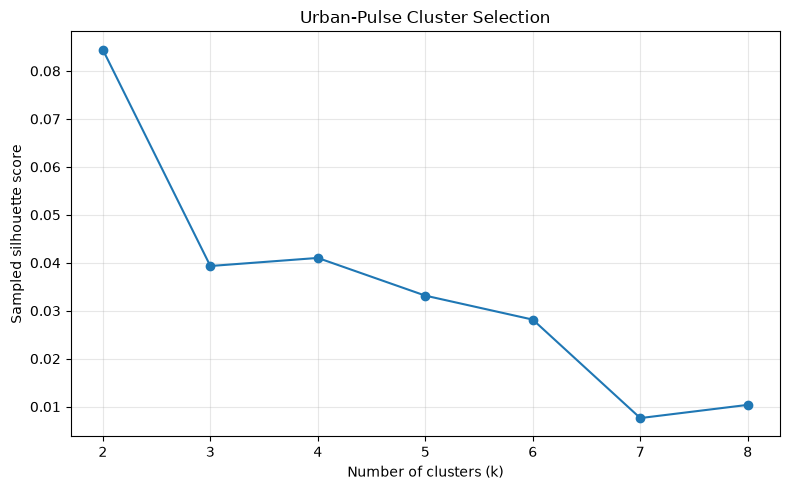

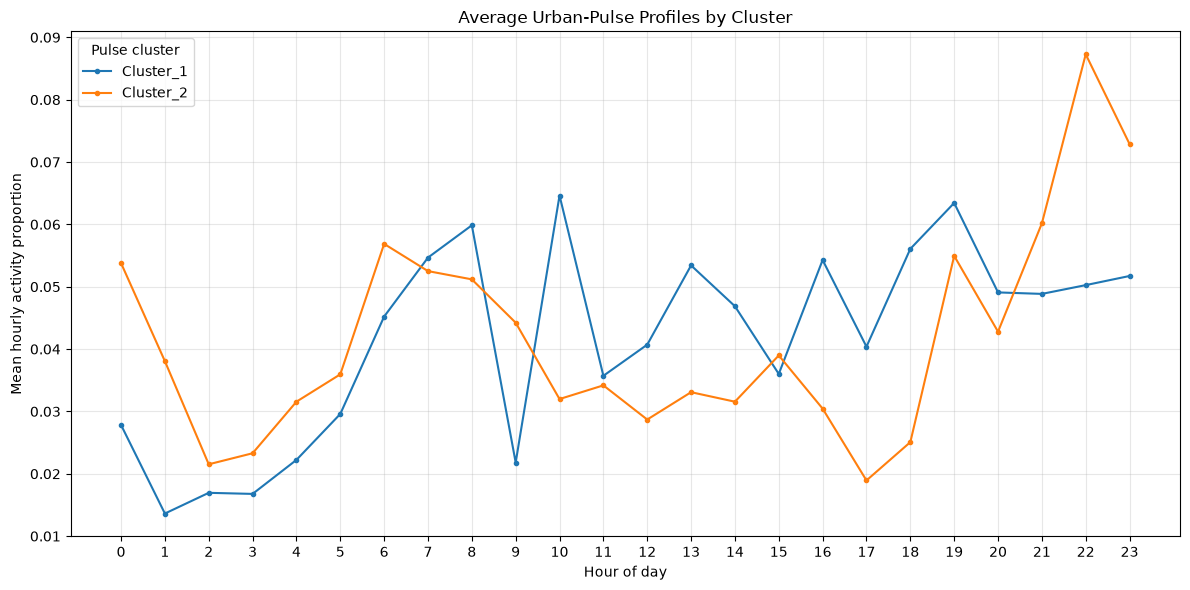


PROCESS COMPLETED
Input shapefile:
C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp

Output folder:
C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results

Selected cluster count: 2
Valid profiles clustered: 11318
Invalid profiles excluded: 4175

Files created:
1. C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\grid_pulse_clusters.gpkg
2. C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\pulse_cluster_selection.csv
3. C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\pulse_cluster_sizes.csv
4. C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\pulse_cluster_mean_profiles.csv
5. C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\pulse_validation_report.csv
6. C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\pulse_cluster_silhouette.png
7. C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\pulse_cluster_mean_profiles.png

Open grid_pulse_clusters.gpkg in QGIS
to map the pulse clusters.


In [7]:

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.linalg import helmert
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.metrics import silhouette_score


# ============================================================
# 1. FILE PATHS
# ============================================================

input_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_gpkg = output_dir / "grid_pulse_clusters.gpkg"

selection_csv = output_dir / "pulse_cluster_selection.csv"
sizes_csv = output_dir / "pulse_cluster_sizes.csv"
profiles_csv = output_dir / "pulse_cluster_mean_profiles.csv"
validation_csv = output_dir / "pulse_validation_report.csv"

silhouette_png = output_dir / "pulse_cluster_silhouette.png"
profiles_png = output_dir / "pulse_cluster_mean_profiles.png"


# ============================================================
# 2. SETTINGS
# ============================================================

MIN_CLUSTERS = 2
MAX_CLUSTERS = 8

# Silhouette is estimated using a reproducible sample.
SILHOUETTE_SAMPLE_SIZE = 5000
RANDOM_STATE = 42

# Ward linkage on all grids can require substantial RAM.
# Check available memory before running on a large dataset.


# ============================================================
# 3. READ THE EXISTING SHAPEFILE
# ============================================================

if not input_path.exists():
    raise FileNotFoundError(
        f"Input shapefile not found:\n{input_path}"
    )

gdf = gpd.read_file(input_path)

print("=" * 60)
print("INPUT DATA")
print("=" * 60)
print("Number of grid features:", len(gdf))
print("CRS:", gdf.crs)


# ============================================================
# 4. IDENTIFY THE 24 HOURLY PULSE FIELDS
# ============================================================

pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

missing_cols = [
    col for col in pulse_cols
    if col not in gdf.columns
]

if missing_cols:
    raise ValueError(
        "The following hourly pulse fields are missing:\n"
        + "\n".join(missing_cols)
    )

# Convert pulse fields to numeric.
# Text or invalid values become NaN.
pulse_df = gdf[pulse_cols].apply(
    pd.to_numeric, errors="coerce"
)

pulse_values = pulse_df.to_numpy(dtype=float)

print("\nHourly pulse fields found:", len(pulse_cols))


# ============================================================
# 5. VALIDATE THE PULSE PROFILES
# ============================================================

# A valid profile must have:
# - 24 finite values
# - No negative values
# - A positive total across the 24 hours

finite_rows = np.isfinite(pulse_values).all(axis=1)
nonnegative_rows = (pulse_values >= 0).all(axis=1)

row_sums = np.nansum(pulse_values, axis=1)

positive_sum_rows = (
    np.isfinite(row_sums) & (row_sums > 0)
)

valid_mask = (
    finite_rows
    & nonnegative_rows
    & positive_sum_rows
)

n_total = len(gdf)
n_valid = int(valid_mask.sum())
n_invalid = n_total - n_valid

# Record why a row failed validation.
validation_status = np.full(
    n_total, "Valid", dtype=object
)

validation_status[~finite_rows] = "Missing_or_nonfinite_values"

validation_status[
    finite_rows & ~nonnegative_rows
] = "Negative_values"

validation_status[
    finite_rows
    & nonnegative_rows
    & ~positive_sum_rows
] = "Zero_or_invalid_total"

gdf["pulse_valid"] = valid_mask
gdf["pulse_cluster"] = "Excluded_Invalid_Profile"

validation_report = pd.DataFrame({
    "grid_id": (
        gdf["grid_id"].to_numpy()
        if "grid_id" in gdf.columns
        else np.arange(n_total)
    ),
    "pulse_sum_before_normalization": row_sums,
    "validation_status": validation_status
})

validation_report.to_csv(
    validation_csv, index=False
)

print("\n" + "=" * 60)
print("PULSE VALIDATION")
print("=" * 60)
print("Total grid features:", n_total)
print("Valid pulse profiles:", n_valid)
print("Invalid pulse profiles:", n_invalid)
print("\nValidation status counts:")
print(pd.Series(validation_status).value_counts())

if n_valid < 3:
    raise ValueError(
        "There are too few valid pulse profiles for clustering."
    )

if n_valid <= MAX_CLUSTERS:
    raise ValueError(
        f"Only {n_valid} valid profiles are available. "
        "Reduce MAX_CLUSTERS."
    )


# ============================================================
# 6. NORMALIZE VALID PULSE PROFILES
# ============================================================

# Use only valid rows for clustering.
valid_values = pulse_values[valid_mask].copy()

# Each row becomes a 24-hour proportion profile summing to 1.
# This also handles pulse values that are counts rather than
# proportions, provided all values are nonnegative.

row_totals = valid_values.sum(axis=1, keepdims=True)

profiles = valid_values / row_totals


# ============================================================
# 7. REPLACE ZERO PROPORTIONS FOR THE ILR TRANSFORMATION
# ============================================================

# ILR requires strictly positive proportions.
# Replace each zero with half the smallest positive proportion
# in that profile, then re-normalize.

for i in range(profiles.shape[0]):
    zero_mask = profiles[i] == 0

    if zero_mask.any():
        positive_values = profiles[i, ~zero_mask]

        if len(positive_values) == 0:
            raise ValueError(
                "An all-zero profile passed validation unexpectedly."
            )

        replacement = positive_values.min() * 0.5
        profiles[i, zero_mask] = replacement

        profiles[i] /= profiles[i].sum()

print("\nValid profiles normalized.")
print(
    "Maximum deviation from a row sum of 1:",
    float(np.max(np.abs(profiles.sum(axis=1) - 1)))
)


# ============================================================
# 8. APPLY THE ILR TRANSFORMATION
# ============================================================

# A 24-part composition is transformed into 23 ILR coordinates.
# Helmert rows form an orthonormal contrast basis.

helmert_basis = helmert(24, full=False)

ilr_data = np.log(profiles) @ helmert_basis.T

print("\nILR transformation complete.")
print("ILR matrix shape:", ilr_data.shape)


# ============================================================
# 9. COMPUTE WARD HIERARCHICAL LINKAGE ONCE
# ============================================================

# IMPORTANT:
# This step can require substantial memory because conventional
# Ward hierarchical clustering uses pairwise distances.
# It is performed once, then reused to test different k values.

print("\n" + "=" * 60)
print("WARD HIERARCHICAL CLUSTERING")
print("=" * 60)
print("Building the hierarchical clustering tree...")
print("Valid profiles to cluster:", len(ilr_data))

ward_tree = linkage(
    ilr_data,
    method="ward",
    metric="euclidean",
    optimal_ordering=False
)

print("Ward clustering tree completed.")


# ============================================================
# 10. TEST DIFFERENT NUMBERS OF CLUSTERS
# ============================================================

cluster_counts = range(
    MIN_CLUSTERS,
    min(MAX_CLUSTERS, n_valid - 1) + 1
)

selection_results = []
labels_by_k = {}

sample_size = min(
    SILHOUETTE_SAMPLE_SIZE,
    n_valid
)

for k in cluster_counts:

    # Cut the same hierarchical tree at k clusters.
    labels = cut_tree(
        ward_tree,
        n_clusters=[k]
    ).ravel()

    labels_by_k[k] = labels

    # Estimate silhouette on a sample to reduce computation.
    score = silhouette_score(
        ilr_data,
        labels,
        metric="euclidean",
        sample_size=sample_size,
        random_state=RANDOM_STATE
    )

    actual_clusters = len(np.unique(labels))

    selection_results.append({
        "requested_k": k,
        "actual_clusters": actual_clusters,
        "silhouette_score_sampled": score,
        "silhouette_sample_size": sample_size
    })

    print(
        f"k = {k}: "
        f"clusters = {actual_clusters}, "
        f"sampled silhouette = {score:.4f}"
    )


# Save the comparison table.
selection_df = pd.DataFrame(selection_results)

selection_df.to_csv(
    selection_csv, index=False
)

# Select the highest silhouette score as the initial candidate.
# Final selection should also consider cluster sizes and
# whether the average profiles are meaningfully different.

best_row = selection_df.loc[
    selection_df["silhouette_score_sampled"].idxmax()
]

best_k = int(best_row["requested_k"])
best_labels = labels_by_k[best_k]

print("\n" + "=" * 60)
print("INITIAL CLUSTER SELECTION")
print("=" * 60)
print("Selected number of clusters:", best_k)
print(
    "Sampled silhouette score:",
    round(float(best_row["silhouette_score_sampled"]), 4)
)


# ============================================================
# 11. ASSIGN CLUSTER LABELS TO THE ORIGINAL GRID FEATURES
# ============================================================

# Keep invalid profiles explicitly marked as excluded.
# Cluster numbers are assigned only to valid profiles.

valid_positions = np.flatnonzero(valid_mask)

gdf.loc[
    gdf.index[valid_positions],
    "pulse_cluster"
] = [
    f"Cluster_{label + 1}"
    for label in best_labels
]

print("\nCluster labels assigned to valid grid features.")


# ============================================================
# 12. EXPORT CLUSTER SIZES
# ============================================================

cluster_sizes = (
    gdf.loc[valid_mask, "pulse_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("pulse_cluster")
    .reset_index(name="grid_count")
)

cluster_sizes["percentage_of_valid_grids"] = (
    cluster_sizes["grid_count"] / n_valid * 100
)

cluster_sizes.to_csv(
    sizes_csv, index=False
)

print("\nCluster sizes:")
print(cluster_sizes.to_string(index=False))


# ============================================================
# 13. CALCULATE MEAN 24-HOUR PROFILE FOR EACH CLUSTER
# ============================================================

# Use the normalized hourly profiles, not the ILR coordinates,
# so the results remain interpretable as hourly proportions.

cluster_profiles = pd.DataFrame(
    profiles,
    columns=pulse_cols
)

cluster_profiles["pulse_cluster"] = [
    f"Cluster_{label + 1}"
    for label in best_labels
]

mean_profiles = (
    cluster_profiles
    .groupby("pulse_cluster")[pulse_cols]
    .mean()
    .sort_index()
)

mean_profiles.to_csv(profiles_csv)

print("\nMean hourly profiles saved.")
print(mean_profiles.round(4).to_string())


# ============================================================
# 14. PLOT SILHOUETTE SCORES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    selection_df["requested_k"],
    selection_df["silhouette_score_sampled"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Sampled silhouette score")
plt.title("Urban-Pulse Cluster Selection")
plt.xticks(selection_df["requested_k"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    silhouette_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 15. PLOT THE MEAN HOURLY PROFILE FOR EACH CLUSTER
# ============================================================

hours = np.arange(24)

plt.figure(figsize=(12, 6))

for cluster_name, row in mean_profiles.iterrows():

    plt.plot(
        hours,
        row.to_numpy(),
        marker="o",
        markersize=3,
        label=cluster_name
    )

plt.xlabel("Hour of day")
plt.ylabel("Mean hourly activity proportion")
plt.title("Average Urban-Pulse Profiles by Cluster")
plt.xticks(hours)
plt.legend(title="Pulse cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    profiles_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 16. EXPORT THE GRID RESULTS TO A GEOPACKAGE
# ============================================================

# Use a new output file, leaving the original shapefile unchanged.

if output_gpkg.exists():
    output_gpkg.unlink()

gdf.to_file(
    output_gpkg,
    layer="grid_pulse_clusters",
    driver="GPKG",
    index=False
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("PROCESS COMPLETED")
print("=" * 60)

print("Input shapefile:")
print(input_path)

print("\nOutput folder:")
print(output_dir)

print("\nSelected cluster count:", best_k)
print("Valid profiles clustered:", n_valid)
print("Invalid profiles excluded:", n_invalid)

print("\nFiles created:")
print("1.", output_gpkg)
print("2.", selection_csv)
print("3.", sizes_csv)
print("4.", profiles_csv)
print("5.", validation_csv)
print("6.", silhouette_png)
print("7.", profiles_png)

print("\nOpen grid_pulse_clusters.gpkg in QGIS")
print("to map the pulse clusters.")


In [13]:
import geopandas as gpd
import pandas as pd

# Load your shapefile
df = gpd.read_file(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

# Define activity columns
activity_cols = [f"activity_{i}" for i in range(10)] + [
    f"activity{i}" for i in range(10, 24)
]

# Ensure activity columns and total_acti are numeric (convert any text/nulls to numbers)
df["total_acti"] = pd.to_numeric(df["total_acti"], errors="coerce").fillna(0)
for col in activity_cols:
  df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Recalculate sum
df["calculated_sum"] = df[activity_cols].sum(axis=1)

# Find mismatches
mismatches = df[df["calculated_sum"] != df["total_acti"]]

print(f"Total mismatch rows: {len(mismatches)}")
print("\nSample of mismatches (showing total_acti vs calculated_sum):")
print(mismatches[["grid_id", "total_acti", "calculated_sum"]].head(10))

# Optional: If you want to automatically overwrite/fix 'total_acti' to match the correct sum of hourly activities:
# df['total_acti'] = df['calculated_sum']
# df.to_file(r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork_Fixed.shp")

Total mismatch rows: 0

Sample of mismatches (showing total_acti vs calculated_sum):
Empty DataFrame
Columns: [grid_id, total_acti, calculated_sum]
Index: []


In [15]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. FILE PATHS
# ============================================================
gpkg_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\grid_pulse_clusters.gpkg"
)

output_dir = gpkg_path.parent

if not gpkg_path.exists():
    raise FileNotFoundError(f"GeoPackage not found: {gpkg_path}")

# ============================================================
# 2. READ DATA
# ============================================================
gdf = gpd.read_file(gpkg_path, layer="grid_pulse_clusters")

def activity_col(h):
    return f"activity_{h}" if h < 10 else f"activity{h}"

activity_cols = [activity_col(h) for h in range(24)]
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

required = ["total_acti", "pulse_cluster"] + activity_cols + pulse_cols
missing = [c for c in required if c not in gdf.columns]

if missing:
    raise ValueError(f"Missing fields: {missing}")

# Retain grids with valid observed pulse profiles and actual cluster labels
labels = gdf["pulse_cluster"].astype(str)
mask = labels.isin(["Cluster_1", "Cluster_2"])

if "pulse_valid" in gdf.columns:
    mask &= gdf["pulse_valid"].fillna(False).astype(bool)

df = gdf.loc[mask].copy()

for c in ["total_acti"] + activity_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["total_acti"] + activity_cols)
df = df[df["total_acti"] >= 0].copy()

# ============================================================
# 3. VERIFY TOTAL ACTIVITY
# ============================================================
df["hourly_sum"] = df[activity_cols].sum(axis=1)
df["total_difference"] = (df["total_acti"] - df["hourly_sum"]).abs()

print("=" * 65)
print("DATA VALIDATION")
print("=" * 65)
print("All features in GeoPackage:", len(gdf))
print("Grids included in analysis:", len(df))
print("Hourly activity fields:", len(activity_cols))
print("Grids where total differs from hourly sum by > 0.01:",
      int((df["total_difference"] > 0.01).sum()))

# ============================================================
# 4. COMPARE ACTIVITY MAGNITUDE BY CLUSTER
# ============================================================
summary = (
    df.groupby("pulse_cluster")["total_acti"]
    .agg(
        grid_count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        p10=lambda x: x.quantile(0.10),
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        maximum="max"
    )
    .reset_index()
)

summary["percentage_of_clustered_grids"] = (
    summary["grid_count"] / len(df) * 100
)

print("\n" + "=" * 65)
print("TOTAL ACTIVITY BY CLUSTER")
print("=" * 65)
print(summary.round(3).to_string(index=False))

# ============================================================
# 5. CHECK LOW-ACTIVITY CONCENTRATION
# Define the bottom 10% of total activity among clustered grids.
# This is a diagnostic threshold, not a definition of inactivity.
# ============================================================
low_activity_cutoff = df["total_acti"].quantile(0.10)
df["low_activity_bottom10pct"] = (
    df["total_acti"] <= low_activity_cutoff
)

low_summary = (
    df.groupby("pulse_cluster")
    .agg(
        grids=("total_acti", "size"),
        low_activity_grids=("low_activity_bottom10pct", "sum"),
        median_total_activity=("total_acti", "median")
    )
    .reset_index()
)

low_summary["low_activity_percent_within_cluster"] = (
    low_summary["low_activity_grids"] / low_summary["grids"] * 100
)

print("\nBottom-10% activity cutoff:", low_activity_cutoff)
print("\nLOW-ACTIVITY SHARE WITHIN EACH CLUSTER")
print(low_summary.round(3).to_string(index=False))

# ============================================================
# 6. SAVE RESULTS
# ============================================================
summary.to_csv(
    output_dir / "cluster_activity_summary.csv", index=False
)

low_summary.to_csv(
    output_dir / "cluster_low_activity_check.csv", index=False
)

print("\nSaved:")
print(output_dir / "cluster_activity_summary.csv")
print(output_dir / "cluster_low_activity_check.csv")


DATA VALIDATION
All features in GeoPackage: 15493
Grids included in analysis: 11318
Hourly activity fields: 24
Grids where total differs from hourly sum by > 0.01: 0

TOTAL ACTIVITY BY CLUSTER
pulse_cluster  grid_count      mean  median       std  minimum   p10    p25     p75     p90  maximum  percentage_of_clustered_grids
    Cluster_1        5411 25617.178  9394.0 47951.736      5.0 774.0 2800.5 27337.0 63432.0 671734.0                         47.809
    Cluster_2        5907 15289.689  6869.0 22147.090      1.0 315.0 1755.0 19240.0 41439.8 295985.0                         52.191

Bottom-10% activity cutoff: 504.70000000000005

LOW-ACTIVITY SHARE WITHIN EACH CLUSTER
pulse_cluster  grids  low_activity_grids  median_total_activity  low_activity_percent_within_cluster
    Cluster_1   5411                 373                 9394.0                                6.893
    Cluster_2   5907                 759                 6869.0                               12.849

Saved:
C:\Users\san


DATA QUALITY REPORT
 predictor  missing_count  missing_percent  unique_nonmissing_values  standard_deviation
  LConn_wt              0              0.0                      6945              1.6599
 MAD500_wt              0              0.0                     11385             54.4975
 BtA500_wt              0              0.0                      9049              5.1313
  Bldg_Cov              0              0.0                     14307              0.0955
Floor_Inte              0              0.0                     14307              0.1945
POI_Densit              0              0.0                       205             15.4119
Transit_Ac              0              0.0                      2724           2344.8004
IntDen_km2              0              0.0                      1633             37.4204
land_use_e              0              0.0                     14614              0.1546

Rows in original dataset: 15493
Complete rows used for screening: 15493
Rows omitted due

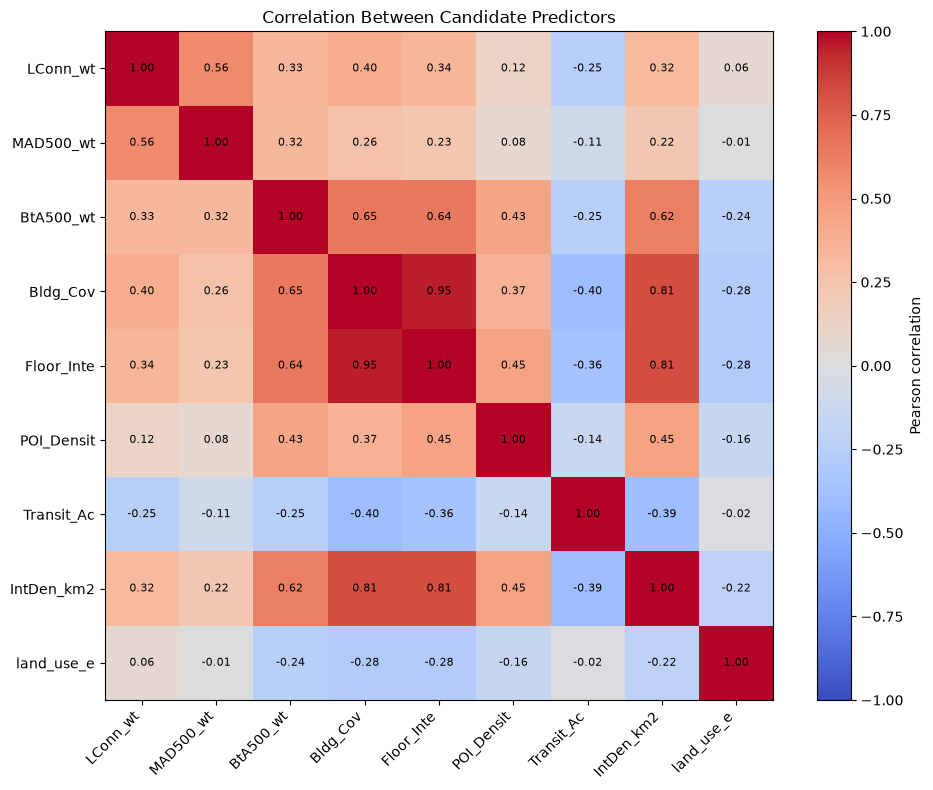


VARIANCE INFLATION FACTORS
 predictor    VIF     screening_flag
  Bldg_Cov 12.512       High concern
Floor_Inte 11.672       High concern
IntDen_km2  3.353 Usually acceptable
 BtA500_wt  2.013 Usually acceptable
  LConn_wt  1.727 Usually acceptable
 MAD500_wt  1.528 Usually acceptable
POI_Densit  1.441 Usually acceptable
Transit_Ac  1.263 Usually acceptable
land_use_e  1.170 Usually acceptable

Reports saved in:
C:\Users\sanojan\Downloads\Roaddd\Feature_Screening


In [16]:

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# ============================================================
# 1. FILE PATHS
# ============================================================
input_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

output_dir = input_path.parent / "Feature_Screening"
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. CANDIDATE PREDICTORS
# ============================================================
predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Bldg_Cov",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

if not input_path.exists():
    raise FileNotFoundError(f"Input file not found: {input_path}")

gdf = gpd.read_file(input_path)

missing_cols = [c for c in predictors if c not in gdf.columns]
if missing_cols:
    raise ValueError(
        "These predictors are missing from the file:\n"
        + "\n".join(missing_cols)
        + "\nCheck your actual field names before continuing."
    )

# ============================================================
# 3. CONVERT TO NUMERIC AND CHECK DATA QUALITY
# ============================================================
X = gdf[predictors].copy()

for col in predictors:
    X[col] = pd.to_numeric(X[col], errors="coerce")

quality_report = pd.DataFrame({
    "predictor": predictors,
    "missing_count": X.isna().sum().values,
    "missing_percent": (X.isna().mean().values * 100),
    "unique_nonmissing_values": X.nunique(dropna=True).values,
    "standard_deviation": X.std().values,
})

print("\nDATA QUALITY REPORT")
print(quality_report.round(4).to_string(index=False))
quality_report.to_csv(output_dir / "predictor_data_quality.csv", index=False)

# VIF and correlation need complete, nonconstant numeric columns.
# We use complete cases for this initial diagnostic only.
X_complete = X.dropna().copy()

constant_cols = [
    c for c in predictors
    if X_complete[c].nunique() < 2
]

if constant_cols:
    raise ValueError(
        "Constant or non-varying predictors found: "
        + ", ".join(constant_cols)
        + ". Investigate them before calculating VIF."
    )

if len(X_complete) < 30:
    raise ValueError(
        "Too few complete rows for a useful initial screening."
    )

print("\nRows in original dataset:", len(gdf))
print("Complete rows used for screening:", len(X_complete))
print("Rows omitted due to missing predictors:", len(X) - len(X_complete))

# ============================================================
# 4. PEARSON CORRELATION MATRIX
# ============================================================
corr = X_complete.corr(method="pearson")

corr.to_csv(output_dir / "predictor_correlation_matrix.csv")

print("\nPEARSON CORRELATION MATRIX")
print(corr.round(3).to_string())

# Identify strongly correlated pairs, without removing them.
pair_rows = []

for i in range(len(predictors)):
    for j in range(i + 1, len(predictors)):
        a, b = predictors[i], predictors[j]
        r = corr.loc[a, b]

        if abs(r) >= 0.80:
            pair_rows.append({
                "predictor_1": a,
                "predictor_2": b,
                "correlation": r,
                "absolute_correlation": abs(r),
            })

pairs_df = pd.DataFrame(
    pair_rows,
    columns=[
        "predictor_1", "predictor_2",
        "correlation", "absolute_correlation"
    ]
)

pairs_df.to_csv(output_dir / "high_correlation_pairs.csv", index=False)

print("\nHIGH-CORRELATION PAIRS (|r| >= 0.80)")
if pairs_df.empty:
    print("No predictor pairs exceeded the screening threshold.")
else:
    print(pairs_df.round(3).to_string(index=False))

# Save a correlation heatmap
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(predictors)))
ax.set_yticks(range(len(predictors)))
ax.set_xticklabels(predictors, rotation=45, ha="right")
ax.set_yticklabels(predictors)

for i in range(len(predictors)):
    for j in range(len(predictors)):
        ax.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=8
        )

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation Between Candidate Predictors")
fig.tight_layout()
fig.savefig(
    output_dir / "predictor_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 5. VARIANCE INFLATION FACTOR (VIF)
# ============================================================
# VIF is scale-invariant under ordinary linear regression.
# Add a constant only for the VIF calculation.
X_vif = X_complete.astype(float)

# Drop the intercept column from the resulting VIF report.
X_with_constant = add_constant(X_vif, has_constant="add")

vif_rows = []

for i, col in enumerate(X_with_constant.columns):
    if col == "const":
        continue

    vif_value = variance_inflation_factor(
        X_with_constant.values, i
    )

    vif_rows.append({
        "predictor": col,
        "VIF": vif_value,
        "screening_flag": (
            "High concern" if vif_value >= 10
            else "Review" if vif_value >= 5
            else "Usually acceptable"
        )
    })

vif_df = pd.DataFrame(vif_rows).sort_values(
    "VIF", ascending=False
)

vif_df.to_csv(output_dir / "predictor_vif_results.csv", index=False)

print("\nVARIANCE INFLATION FACTORS")
print(vif_df.round(3).to_string(index=False))

print("\nReports saved in:")
print(output_dir)


In [17]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# --------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------
input_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

output_dir = input_path.parent / "Feature_Screening"
output_dir.mkdir(parents=True, exist_ok=True)

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Bldg_Cov",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

# --------------------------------------------------
# 2. LOAD AND VALIDATE DATA
# --------------------------------------------------
gdf = gpd.read_file(input_path)

missing_columns = [c for c in predictors if c not in gdf.columns]
if missing_columns:
    raise ValueError(f"Missing predictor columns: {missing_columns}")

X = gdf[predictors].apply(pd.to_numeric, errors="coerce")

# Remove rows with missing or infinite predictor values
X = X.replace([np.inf, -np.inf], np.nan).dropna()

# Remove constant predictors, if any
constant_cols = [
    c for c in X.columns if X[c].nunique() <= 1
]
if constant_cols:
    print("Constant predictors excluded from VIF:", constant_cols)
    X = X.drop(columns=constant_cols)

if len(X) == 0:
    raise ValueError("No valid rows remain for VIF calculation.")

# --------------------------------------------------
# 3. STANDARDIZE FOR NUMERICAL STABILITY
# VIF is invariant to linear rescaling.
# --------------------------------------------------
X_scaled = (X - X.mean()) / X.std(ddof=0)

if not np.isfinite(X_scaled.to_numpy()).all():
    raise ValueError("Non-finite values remain after scaling.")

X_with_constant = add_constant(X_scaled, has_constant="add")

# --------------------------------------------------
# 4. CALCULATE VIF
# --------------------------------------------------
results = []

for i, col in enumerate(X_scaled.columns, start=1):
    try:
        vif_value = variance_inflation_factor(
            X_with_constant.to_numpy(), i
        )
    except Exception:
        vif_value = np.nan

    if not np.isfinite(vif_value):
        interpretation = "Check for exact/redundant linear dependence"
    elif vif_value < 5:
        interpretation = "Generally acceptable"
    elif vif_value < 10:
        interpretation = "Investigate overlap"
    else:
        interpretation = "High multicollinearity concern"

    results.append({
        "predictor": col,
        "VIF": vif_value,
        "interpretation": interpretation
    })

vif_df = pd.DataFrame(results).sort_values(
    "VIF", ascending=False, na_position="first"
)

# --------------------------------------------------
# 5. SAVE AND PRINT RESULTS
# --------------------------------------------------
output_path = output_dir / "predictor_vif_results.csv"
vif_df.to_csv(output_path, index=False)

print("\nVIF RESULTS")
print(vif_df.to_string(index=False))

print("\nRows used:", len(X), "of", len(gdf))
print("Saved to:", output_path)



VIF RESULTS
 predictor       VIF                 interpretation
  Bldg_Cov 12.512220 High multicollinearity concern
Floor_Inte 11.671765 High multicollinearity concern
IntDen_km2  3.353041           Generally acceptable
 BtA500_wt  2.013289           Generally acceptable
  LConn_wt  1.726518           Generally acceptable
 MAD500_wt  1.527648           Generally acceptable
POI_Densit  1.440698           Generally acceptable
Transit_Ac  1.262690           Generally acceptable
land_use_e  1.169794           Generally acceptable

Rows used: 15493 of 15493
Saved to: C:\Users\sanojan\Downloads\Roaddd\Feature_Screening\predictor_vif_results.csv


In [18]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------
input_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

output_dir = input_path.parent / "Feature_Screening_Final"
output_dir.mkdir(parents=True, exist_ok=True)

# Final candidate set: eight predictors
predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

# --------------------------------------------------
# 2. LOAD AND VALIDATE
# --------------------------------------------------
gdf = gpd.read_file(input_path)

missing_cols = [c for c in predictors if c not in gdf.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

X = gdf[predictors].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan).dropna()

if len(X) == 0:
    raise ValueError("No complete predictor rows available.")

constant_cols = [c for c in X if X[c].nunique() <= 1]
if constant_cols:
    raise ValueError(f"Constant predictors found: {constant_cols}")

print("Original grid count:", len(gdf))
print("Complete rows used:", len(X))
print("Predictors tested:", len(predictors))

# --------------------------------------------------
# 3. CORRELATION SCREENING
# --------------------------------------------------
corr = X.corr(method="pearson")
corr.to_csv(output_dir / "final8_correlation_matrix.csv")

threshold = 0.80
pairs = []

for i in range(len(predictors)):
    for j in range(i + 1, len(predictors)):
        r = corr.iloc[i, j]
        if abs(r) >= threshold:
            pairs.append({
                "predictor_1": predictors[i],
                "predictor_2": predictors[j],
                "correlation": r,
                "absolute_correlation": abs(r)
            })

pairs_df = pd.DataFrame(
    pairs,
    columns=[
        "predictor_1", "predictor_2",
        "correlation", "absolute_correlation"
    ]
)
pairs_df.to_csv(
    output_dir / "final8_high_correlation_pairs.csv",
    index=False
)

print("\nCORRELATION PAIRS WITH |r| >= 0.80")
if pairs_df.empty:
    print("None")
else:
    print(pairs_df.to_string(index=False))

# --------------------------------------------------
# 4. RECALCULATE VIF
# --------------------------------------------------
# Standardizing improves numerical stability.
# VIF is unchanged by linear rescaling.
X_scaled = (X - X.mean()) / X.std(ddof=0)
X_const = add_constant(X_scaled, has_constant="add")

vif_results = []

for i, col in enumerate(X_scaled.columns, start=1):
    value = variance_inflation_factor(
        X_const.to_numpy(), i
    )

    if not np.isfinite(value):
        status = "Check linear dependence"
    elif value < 5:
        status = "Generally acceptable"
    elif value < 10:
        status = "Investigate overlap"
    else:
        status = "High concern"

    vif_results.append({
        "predictor": col,
        "VIF": value,
        "interpretation": status
    })

vif_df = pd.DataFrame(vif_results).sort_values(
    "VIF", ascending=False
)

vif_df.to_csv(
    output_dir / "final8_vif_results.csv",
    index=False
)

print("\nFINAL EIGHT-PREDICTOR VIF RESULTS")
print(vif_df.to_string(index=False))

print("\nSaved results to:", output_dir)


Original grid count: 15493
Complete rows used: 15493
Predictors tested: 8

CORRELATION PAIRS WITH |r| >= 0.80
predictor_1 predictor_2  correlation  absolute_correlation
 Floor_Inte  IntDen_km2     0.807695              0.807695

FINAL EIGHT-PREDICTOR VIF RESULTS
 predictor      VIF       interpretation
Floor_Inte 3.387733 Generally acceptable
IntDen_km2 3.183429 Generally acceptable
 BtA500_wt 1.984807 Generally acceptable
  LConn_wt 1.661577 Generally acceptable
 MAD500_wt 1.527380 Generally acceptable
POI_Densit 1.344265 Generally acceptable
Transit_Ac 1.238282 Generally acceptable
land_use_e 1.152659 Generally acceptable

Saved results to: C:\Users\sanojan\Downloads\Roaddd\Feature_Screening_Final


In [19]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. INPUT FILES
# ============================================================
grid_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

cluster_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\grid_pulse_clusters.gpkg"
)

cluster_layer = "grid_pulse_clusters"

# ============================================================
# 2. READ THE FILES
# ============================================================
print("=" * 70)
print("TARGET VARIABLE VALIDATION")
print("=" * 70)

grid = gpd.read_file(grid_path)
cluster = gpd.read_file(cluster_path, layer=cluster_layer)

print("\nGRID DATA")
print("Rows:", len(grid))
print("CRS:", grid.crs)

print("\nCLUSTER DATA")
print("Rows:", len(cluster))
print("CRS:", cluster.crs)

# ============================================================
# 3. IDENTIFY RELEVANT FIELDS
# ============================================================
def activity_col(hour):
    return f"activity_{hour}" if hour < 10 else f"activity{hour}"

hourly_cols = [activity_col(h) for h in range(24)]
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

def find_fields(columns, expected):
    return [c for c in expected if c in columns]

print("\n" + "=" * 70)
print("RELEVANT FIELDS")
print("=" * 70)

print("\nHourly activity fields found in original grid:")
print(find_fields(grid.columns, hourly_cols))

print("\nTotal activity field in original grid:")
print("total_acti" if "total_acti" in grid.columns else "Not found")

print("\nPulse profile fields in cluster file:")
print(find_fields(cluster.columns, pulse_cols))

print("\nPossible cluster-label fields:")
cluster_candidates = [
    c for c in cluster.columns
    if any(word in c.lower() for word in
           ["cluster", "label", "ward", "class", "pulse_type"])
]
print(cluster_candidates)

print("\nPossible grid identifier fields:")
id_candidates = [
    c for c in list(grid.columns) + list(cluster.columns)
    if any(word in c.lower() for word in
           ["grid_id", "gridid", "gid", "cell_id", "id"])
]
print(sorted(set(id_candidates)))

# ============================================================
# 4. CHECK HOURLY ACTIVITY DATA
# ============================================================
available_hours = find_fields(grid.columns, hourly_cols)

if len(available_hours) == 24:
    hourly = grid[available_hours].apply(
        pd.to_numeric, errors="coerce"
    )

    calculated_total = hourly.sum(axis=1, min_count=24)

    print("\n" + "=" * 70)
    print("HOURLY ACTIVITY QUALITY")
    print("=" * 70)
    print("Hourly fields found:", len(available_hours))
    print("Rows with at least one missing hour:",
          int(hourly.isna().any(axis=1).sum()))
    print("Rows with negative hourly values:",
          int((hourly < 0).any(axis=1).sum()))
    print("Rows with all 24 hours equal to zero:",
          int(hourly.eq(0).all(axis=1).sum()))
    print("Rows with positive total activity:",
          int((calculated_total > 0).sum()))
    print("Rows with zero total activity:",
          int((calculated_total == 0).sum()))
    print("Rows with missing calculated total:",
          int(calculated_total.isna().sum()))

    if "total_acti" in grid.columns:
        existing_total = pd.to_numeric(
            grid["total_acti"], errors="coerce"
        )
        comparable = existing_total.notna() & calculated_total.notna()
        differences = (
            existing_total[comparable] -
            calculated_total[comparable]
        ).abs()

        print("Existing total field matches hourly sum:",
              bool(np.allclose(
                  existing_total[comparable],
                  calculated_total[comparable],
                  rtol=1e-6,
                  atol=1e-8
              )) if comparable.any() else "No comparable rows")
        print("Rows with total mismatch > 0.001:",
              int((differences > 0.001).sum()))
else:
    print(
        "\nWARNING: Expected 24 hourly activity fields, but found",
        len(available_hours)
    )

# ============================================================
# 5. CHECK PULSE PROFILE FIELDS
# ============================================================
available_pulses = find_fields(cluster.columns, pulse_cols)

if len(available_pulses) == 24:
    pulse = cluster[available_pulses].apply(
        pd.to_numeric, errors="coerce"
    )

    row_sums = pulse.sum(axis=1, min_count=24)

    print("\n" + "=" * 70)
    print("PULSE PROFILE QUALITY")
    print("=" * 70)
    print("Pulse fields found:", len(available_pulses))
    print("Rows with missing pulse values:",
          int(pulse.isna().any(axis=1).sum()))
    print("Rows with negative pulse values:",
          int((pulse < 0).any(axis=1).sum()))
    print("Rows with all pulse values equal to zero:",
          int(pulse.eq(0).all(axis=1).sum()))
    print("Minimum profile sum:",
          row_sums.min())
    print("Maximum profile sum:",
          row_sums.max())
    print("Rows whose profile sum differs from 1 by > 0.001:",
          int(((row_sums - 1).abs() > 0.001).sum()))
else:
    print(
        "\nWARNING: Expected 24 pulse profile fields, but found",
        len(available_pulses)
    )

# ============================================================
# 6. CHECK CLUSTER LABEL COUNTS
# ============================================================
print("\n" + "=" * 70)
print("CLUSTER LABEL SUMMARY")
print("=" * 70)

for col in cluster_candidates:
    print(f"\nField: {col}")
    print("Non-missing labels:", int(cluster[col].notna().sum()))
    print("Missing labels:", int(cluster[col].isna().sum()))
    print("Unique values:", int(cluster[col].nunique(dropna=True)))
    print("Value counts:")
    print(cluster[col].value_counts(dropna=False).head(15))

print("\n" + "=" * 70)
print("INSPECTION COMPLETE — NO FILES MODIFIED")
print("=" * 70)


TARGET VARIABLE VALIDATION

GRID DATA
Rows: 15493
CRS: EPSG:32644

CLUSTER DATA
Rows: 15493
CRS: EPSG:32644

RELEVANT FIELDS

Hourly activity fields found in original grid:
['activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23']

Total activity field in original grid:
total_acti

Pulse profile fields in cluster file:
['pulse_00', 'pulse_01', 'pulse_02', 'pulse_03', 'pulse_04', 'pulse_05', 'pulse_06', 'pulse_07', 'pulse_08', 'pulse_09', 'pulse_10', 'pulse_11', 'pulse_12', 'pulse_13', 'pulse_14', 'pulse_15', 'pulse_16', 'pulse_17', 'pulse_18', 'pulse_19', 'pulse_20', 'pulse_21', 'pulse_22', 'pulse_23']

Possible cluster-label fields:
['pulse_cluster']

Possible grid identifier fields:
['grid_id', 'id', 'pulse_va

In [22]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. FILE PATHS
# ============================================================

grid_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

clusters_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Pulse_Clustering_Results\grid_pulse_clusters.gpkg"
)

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_gpkg = output_dir / "validated_targets_all_grids.gpkg"
output_csv = output_dir / "validated_modelling_dataset.csv"

# ============================================================
# 2. PREDICTORS AND TARGETS
# ============================================================

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

def activity_col(hour):
    return f"activity_{hour}" if hour < 10 else f"activity{hour}"

activity_cols = [activity_col(h) for h in range(24)]
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

target_fields = pulse_cols + ["pulse_cluster"]

# ============================================================
# 3. LOAD BOTH DATASETS
# ============================================================

print("=" * 65)
print("LOADING DATA")
print("=" * 65)

if not grid_path.exists():
    raise FileNotFoundError(f"Grid file not found: {grid_path}")

if not clusters_path.exists():
    raise FileNotFoundError(
        f"Clustering file not found: {clusters_path}"
    )

grid = gpd.read_file(grid_path)

clusters = gpd.read_file(
    clusters_path,
    layer="grid_pulse_clusters"
)

print("Original grid rows:", len(grid))
print("Clustering rows:", len(clusters))

# ============================================================
# 4. CHECK REQUIRED COLUMNS
# ============================================================

grid_required = (
    ["grid_id", "total_acti"]
    + activity_cols
    + predictors
)

cluster_required = ["grid_id"] + target_fields

missing_grid = [
    col for col in grid_required
    if col not in grid.columns
]

missing_clusters = [
    col for col in cluster_required
    if col not in clusters.columns
]

if missing_grid:
    raise ValueError(
        "Missing columns in the original grid:\n"
        + "\n".join(missing_grid)
    )

if missing_clusters:
    raise ValueError(
        "Missing columns in the clustering file:\n"
        + "\n".join(missing_clusters)
    )

print("Required columns: OK")

# ============================================================
# 5. PREPARE JOIN KEYS
# ============================================================

def normalize_key(series):
    """
    Standardize grid IDs, including IDs read as 123 or 123.0.
    Non-numeric IDs remain strings.
    """
    s = series.astype("string").str.strip()
    numeric = pd.to_numeric(s, errors="coerce")

    result = s.copy()
    numeric_mask = numeric.notna()

    integer_mask = (
        numeric_mask
        & np.isclose(
            numeric.fillna(0).to_numpy(dtype=float),
            np.round(numeric.fillna(0).to_numpy(dtype=float))
        )
    )

    result.loc[integer_mask] = (
        numeric.loc[integer_mask]
        .round()
        .astype("int64")
        .astype("string")
    )

    return result

grid = grid.copy()
clusters = clusters.copy()

grid["_join_key"] = normalize_key(grid["grid_id"])
clusters["_join_key"] = normalize_key(clusters["grid_id"])

if grid["_join_key"].isna().any():
    raise ValueError("Missing grid IDs in the original grid.")

if clusters["_join_key"].isna().any():
    raise ValueError("Missing grid IDs in the clustering file.")

if grid["_join_key"].duplicated().any():
    raise ValueError(
        "Duplicate grid IDs found in the original grid."
    )

if clusters["_join_key"].duplicated().any():
    raise ValueError(
        "Duplicate grid IDs found in the clustering file."
    )

grid_keys = set(grid["_join_key"])
cluster_keys = set(clusters["_join_key"])

print("Grid IDs unique: OK")
print("Clustering IDs unique: OK")
print("Grid IDs without a clustering match:", len(grid_keys - cluster_keys))
print("Clustering IDs not found in the grid:", len(cluster_keys - grid_keys))

# ============================================================
# 6. REMOVE OLD PULSE FIELDS BEFORE JOINING
# ============================================================

# The original grid already has pulse columns.
# Remove them so that the clustering-file fields do not
# become pulse_00_x and pulse_00_y.

existing_pulse_cols = [
    col for col in grid.columns
    if col.startswith("pulse_")
]

grid_clean = grid.drop(
    columns=existing_pulse_cols,
    errors="ignore"
).copy()

# Retain only the key and the targets from the clustering file.
cluster_targets = clusters[
    ["_join_key"] + target_fields
].copy()

# ============================================================
# 7. JOIN THE TARGETS TO THE GRID
# ============================================================

joined = grid_clean.merge(
    cluster_targets,
    on="_join_key",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\n" + "=" * 65)
print("JOIN VALIDATION")
print("=" * 65)

print("Joined grid rows:", len(joined))
print("Matched rows:", (joined["_merge"] == "both").sum())
print("Unmatched rows:", (joined["_merge"] == "left_only").sum())

if len(joined) != len(grid):
    raise ValueError("The join changed the original grid row count.")

if (joined["_merge"] == "left_only").any():
    print(
        "WARNING: Some grids have no matching clustering record."
    )

joined.drop(columns=["_merge"], inplace=True)

# Confirm pulse columns have their expected names.
missing_pulse_cols = [
    col for col in pulse_cols
    if col not in joined.columns
]

if missing_pulse_cols:
    raise ValueError(
        "Pulse columns missing after joining:\n"
        + "\n".join(missing_pulse_cols)
    )

print("Pulse columns correctly named: pulse_00 to pulse_23")

# ============================================================
# 8. CONVERT MODEL FIELDS TO NUMERIC
# ============================================================

numeric_cols = (
    predictors
    + ["total_acti"]
    + activity_cols
    + pulse_cols
)

for col in numeric_cols:
    joined[col] = pd.to_numeric(
        joined[col],
        errors="coerce"
    )

# ============================================================
# 9. VALIDATE PREDICTORS
# ============================================================

predictors_finite = np.isfinite(
    joined[predictors].to_numpy(dtype=float)
).all(axis=1)

print("\n" + "=" * 65)
print("PREDICTOR VALIDATION")
print("=" * 65)

print("Total grids:", len(joined))
print("Rows with all 8 finite predictors:", predictors_finite.sum())
print("Rows with missing/non-finite predictors:",
      (~predictors_finite).sum())

# ============================================================
# 10. VALIDATE FUNCTIONAL ACTIVITY MAGNITUDE
# ============================================================

activity_array = joined[activity_cols].to_numpy(dtype=float)

hourly_complete = np.isfinite(activity_array).all(axis=1)

hourly_sum = np.where(
    hourly_complete,
    activity_array.sum(axis=1),
    np.nan
)

total_activity = joined["total_acti"].to_numpy(dtype=float)

total_activity_finite = np.isfinite(total_activity)

activity_consistent = (
    hourly_complete
    & total_activity_finite
    & np.isclose(
        hourly_sum,
        total_activity,
        rtol=0,
        atol=0.001
    )
)

activity_nonnegative = (
    hourly_complete
    & (activity_array >= 0).all(axis=1)
)

print("\n" + "=" * 65)
print("FUNCTIONAL ACTIVITY VALIDATION")
print("=" * 65)

print("Rows with all 24 hourly values:", hourly_complete.sum())
print("Rows with finite total activity:", total_activity_finite.sum())
print("Rows matching hourly sum:", activity_consistent.sum())
print("Rows with complete, nonnegative hourly activity:",
      activity_nonnegative.sum())

# ============================================================
# 11. VALIDATE NORMALIZED PULSE PROFILES
# ============================================================

pulse_array = joined[pulse_cols].to_numpy(dtype=float)

pulse_complete = np.isfinite(pulse_array).all(axis=1)

pulse_nonnegative = (
    pulse_complete
    & (pulse_array >= 0).all(axis=1)
)

pulse_sum = np.where(
    pulse_complete,
    pulse_array.sum(axis=1),
    np.nan
)

pulse_normalized = (
    pulse_complete
    & pulse_nonnegative
    & np.isclose(
        pulse_sum,
        1.0,
        rtol=0,
        atol=0.001
    )
)

print("\n" + "=" * 65)
print("PULSE PROFILE VALIDATION")
print("=" * 65)

print("Rows with 24 complete pulse values:", pulse_complete.sum())
print("Rows with nonnegative pulse profiles:", pulse_nonnegative.sum())
print("Rows with profiles summing to approximately 1:",
      pulse_normalized.sum())

# ============================================================
# 12. VALIDATE PULSE CLASSES
# ============================================================

valid_classes = {"Cluster_1", "Cluster_2"}

cluster_label_valid = (
    joined["pulse_cluster"]
    .astype("string")
    .isin(valid_classes)
    .to_numpy()
)

print("\n" + "=" * 65)
print("PULSE CLUSTER VALIDATION")
print("=" * 65)

print("Cluster labels, including unavailable profiles:")
print(
    joined["pulse_cluster"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nRows in valid pulse classes:", cluster_label_valid.sum())

# ============================================================
# 13. CREATE FINAL TARGET VALIDITY FLAG
# ============================================================

# A row is suitable for supervised modelling only when:
# 1. All eight predictors are finite.
# 2. Total activity is finite.
# 3. All 24 hourly observations are complete and nonnegative.
# 4. Total activity matches the hourly sum.
# 5. The 24-hour pulse profile is complete and normalized.
# 6. The pulse cluster is one of the two valid classes.

target_valid = (
    predictors_finite
    & total_activity_finite
    & activity_nonnegative
    & activity_consistent
    & pulse_normalized
    & cluster_label_valid
)

joined["target_valid"] = target_valid

print("\n" + "=" * 65)
print("FINAL MODELLING ELIGIBILITY")
print("=" * 65)

print("Total grid cells:", len(joined))
print("Valid modelling rows:", int(target_valid.sum()))
print("Excluded from supervised modelling:",
      int((~target_valid).sum()))

print("\nValid pulse-cluster counts:")
print(
    joined.loc[target_valid, "pulse_cluster"]
    .value_counts()
    .to_string()
)

# ============================================================
# 14. SAVE ALL GRIDS WITH VALIDATION RESULTS
# ============================================================

# Remove the temporary join key.
joined.drop(columns=["_join_key"], inplace=True, errors="ignore")

# Save spatial data for all grids, including unavailable targets.
joined.to_file(
    output_gpkg,
    layer="validated_targets_all_grids",
    driver="GPKG"
)

# ============================================================
# 15. SAVE VALID MODELLING DATASET
# ============================================================

# Keep only valid observed targets for supervised training.
model_df = joined.loc[target_valid].copy()

# A CSV does not need the geometry column.
if "geometry" in model_df.columns:
    model_df = model_df.drop(columns=["geometry"])

model_df.to_csv(
    output_csv,
    index=False,
    encoding="utf-8"
)

# ============================================================
# 16. FINAL REPORT
# ============================================================

print("\n" + "=" * 65)
print("PROCESS COMPLETED")
print("=" * 65)

print("All-grid GeoPackage:")
print(output_gpkg)

print("\nValid modelling CSV:")
print(output_csv)

print("\nAll-grid count:", len(joined))
print("Valid modelling rows:", len(model_df))
print("Excluded rows:", len(joined) - len(model_df))

print("\nFinal modelling dataset shape:", model_df.shape)

print("\nRequired pulse columns present:",
      all(col in model_df.columns for col in pulse_cols))

print("All predictor columns present:",
      all(col in model_df.columns for col in predictors))

print("Final target validity counts:")
print(joined["target_valid"].value_counts().to_string())

print("\nFirst five modelling rows:")
print(
    model_df[
        ["grid_id", "total_acti", "pulse_cluster"]
        + predictors[:3]
    ].head().to_string(index=False)
)


LOADING DATA
Original grid rows: 15493
Clustering rows: 15493
Required columns: OK
Grid IDs unique: OK
Clustering IDs unique: OK
Grid IDs without a clustering match: 0
Clustering IDs not found in the grid: 0

JOIN VALIDATION
Joined grid rows: 15493
Matched rows: 15493
Unmatched rows: 0
Pulse columns correctly named: pulse_00 to pulse_23

PREDICTOR VALIDATION
Total grids: 15493
Rows with all 8 finite predictors: 15493
Rows with missing/non-finite predictors: 0

FUNCTIONAL ACTIVITY VALIDATION
Rows with all 24 hourly values: 11318
Rows with finite total activity: 11318
Rows matching hourly sum: 11318
Rows with complete, nonnegative hourly activity: 11318

PULSE PROFILE VALIDATION
Rows with 24 complete pulse values: 11318
Rows with nonnegative pulse profiles: 11318
Rows with profiles summing to approximately 1: 11318

PULSE CLUSTER VALIDATION
Cluster labels, including unavailable profiles:
pulse_cluster
Cluster_2                   5907
Cluster_1                   5411
Excluded_Invalid_Prof

In [21]:
# Check pulse columns in the clustering GeoPackage
print("PULSE COLUMNS IN CLUSTERING FILE:")
print([col for col in clusters.columns if "pulse" in col.lower()])

# Check pulse columns after joining
print("\nPULSE COLUMNS IN JOINED DATA:")
print([col for col in joined.columns if "pulse" in col.lower()])

# Check the first few column names
print("\nALL JOINED COLUMN NAMES:")
print(joined.columns.tolist())

PULSE COLUMNS IN CLUSTERING FILE:
['pulse_00', 'pulse_01', 'pulse_02', 'pulse_03', 'pulse_04', 'pulse_05', 'pulse_06', 'pulse_07', 'pulse_08', 'pulse_09', 'pulse_10', 'pulse_11', 'pulse_12', 'pulse_13', 'pulse_14', 'pulse_15', 'pulse_16', 'pulse_17', 'pulse_18', 'pulse_19', 'pulse_20', 'pulse_21', 'pulse_22', 'pulse_23', 'pulse_valid', 'pulse_cluster']

PULSE COLUMNS IN JOINED DATA:
['pulse_00_x', 'pulse_01_x', 'pulse_02_x', 'pulse_03_x', 'pulse_04_x', 'pulse_05_x', 'pulse_06_x', 'pulse_07_x', 'pulse_08_x', 'pulse_09_x', 'pulse_10_x', 'pulse_11_x', 'pulse_12_x', 'pulse_13_x', 'pulse_14_x', 'pulse_15_x', 'pulse_16_x', 'pulse_17_x', 'pulse_18_x', 'pulse_19_x', 'pulse_20_x', 'pulse_21_x', 'pulse_22_x', 'pulse_23_x', 'pulse_cluster', 'pulse_00_y', 'pulse_01_y', 'pulse_02_y', 'pulse_03_y', 'pulse_04_y', 'pulse_05_y', 'pulse_06_y', 'pulse_07_y', 'pulse_08_y', 'pulse_09_y', 'pulse_10_y', 'pulse_11_y', 'pulse_12_y', 'pulse_13_y', 'pulse_14_y', 'pulse_15_y', 'pulse_16_y', 'pulse_17_y', 'pulse_1

In [24]:

import pandas as pd
from pathlib import Path

input_csv = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_modelling_dataset.csv"
)

df = pd.read_csv(input_csv)

coord_cols = ["left", "right", "top", "bottom"]

print("=" * 60)
print("COORDINATE DATA QUALITY CHECK")
print("=" * 60)

for col in coord_cols:
    numeric_values = pd.to_numeric(df[col], errors="coerce")
    bad = numeric_values.isna()

    print(f"\n{col}")
    print("Missing or non-numeric values:", int(bad.sum()))

    if bad.any():
        print(
            df.loc[bad, ["grid_id", col]].head(10).to_string(index=False)
        )

print("\nRows with any invalid boundary coordinate:")
numeric_coords = df[coord_cols].apply(pd.to_numeric, errors="coerce")
bad_rows = numeric_coords.isna().any(axis=1)

print(int(bad_rows.sum()))

if bad_rows.any():
    print("\nExample affected rows:")
    print(
        df.loc[bad_rows, ["grid_id"] + coord_cols]
        .head(15)
        .to_string(index=False)
    )


COORDINATE DATA QUALITY CHECK

left
Missing or non-numeric values: 0

right
Missing or non-numeric values: 0

top
Missing or non-numeric values: 0

bottom
Missing or non-numeric values: 2
 grid_id  bottom
   11286     NaN
   11266     NaN

Rows with any invalid boundary coordinate:
2

Example affected rows:
 grid_id  left  right           top  bottom
   11286   4.0    4.0      0.000000     NaN
   11266   0.0 4056.0 781936.633046     NaN


In [25]:

import geopandas as gpd
import pandas as pd

gpkg_path = (
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation"
    r"\validated_targets_all_grids.gpkg"
)

gdf = gpd.read_file(
    gpkg_path,
    layer="validated_targets_all_grids"
)

print("CRS:", gdf.crs)
print("Total grid cells:", len(gdf))

check_ids = [11286, 11266]

check = gdf[gdf["grid_id"].isin(check_ids)].copy()

check["geometry_missing"] = check.geometry.isna()
check["geometry_empty"] = check.geometry.is_empty
check["geometry_valid"] = check.geometry.is_valid

check["centroid_x"] = check.geometry.centroid.x
check["centroid_y"] = check.geometry.centroid.y

print(
    check[
        [
            "grid_id",
            "left", "right", "top", "bottom",
            "geometry_missing",
            "geometry_empty",
            "geometry_valid",
            "centroid_x",
            "centroid_y",
        ]
    ].to_string(index=False)
)


CRS: EPSG:32644
Total grid cells: 15493
 grid_id  left  right           top  bottom  geometry_missing  geometry_empty  geometry_valid    centroid_x    centroid_y
   11286   4.0    4.0      0.000000     NaN             False           False            True 405385.373882 771686.633046
   11266   0.0 4056.0 781936.633046     NaN             False           False            True 405385.373882 781686.633046


In [26]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.cluster import KMeans

# ============================================================
# 1. FILE PATHS
# ============================================================

gpkg_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_targets_all_grids.gpkg"
)

csv_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_modelling_dataset.csv"
)

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation"
)
output_dir.mkdir(parents=True, exist_ok=True)

output_csv = output_dir / "spatial_folds_5.csv"
output_gpkg = output_dir / "spatial_folds_5.gpkg"

# ============================================================
# 2. SETTINGS
# ============================================================

N_FOLDS = 5
BLOCK_SIZE_M = 2500

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

# ============================================================
# 3. LOAD THE VALIDATED CSV AND SPATIAL GEOPACKAGE
# ============================================================

print("=" * 65)
print("LOADING VALIDATED DATA")
print("=" * 65)

df = pd.read_csv(csv_path)

gdf = gpd.read_file(
    gpkg_path,
    layer="validated_targets_all_grids"
)

if gdf.crs is None:
    raise ValueError("The GeoPackage has no defined CRS.")

if gdf.crs.to_epsg() != 32644:
    raise ValueError(
        f"Expected EPSG:32644, found {gdf.crs}. "
        "Confirm the projected CRS before continuing."
    )

if "grid_id" not in df.columns or "grid_id" not in gdf.columns:
    raise ValueError("grid_id is required in both files.")

if df["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid IDs in the modelling CSV.")

if gdf["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid IDs in the GeoPackage.")

if len(df) != 11318:
    raise ValueError(
        f"Expected 11318 modelling rows; found {len(df)}."
    )

# ============================================================
# 4. GET CENTROIDS FROM THE ACTUAL GRID GEOMETRY
# ============================================================

gdf = gdf[
    ["grid_id", "geometry"]
].copy()

if gdf.geometry.isna().any() or gdf.geometry.is_empty.any():
    raise ValueError("Missing or empty grid geometries detected.")

gdf["centroid_x"] = gdf.geometry.centroid.x
gdf["centroid_y"] = gdf.geometry.centroid.y

if not np.isfinite(
    gdf[["centroid_x", "centroid_y"]].to_numpy(dtype=float)
).all():
    raise ValueError("Non-finite centroids detected.")

print("GeoPackage CRS:", gdf.crs)
print("All-grid geometry count:", len(gdf))

# ============================================================
# 5. JOIN CENTROIDS TO THE VALID MODELLING DATA
# ============================================================

centroid_df = gdf.drop(columns="geometry")

df = df.merge(
    centroid_df,
    on="grid_id",
    how="left",
    validate="one_to_one"
)

if df[["centroid_x", "centroid_y"]].isna().any().any():
    raise ValueError("Some modelling rows have no matching centroid.")

print("Modelling rows after centroid join:", len(df))

# ============================================================
# 6. ASSIGN EACH CELL TO A 2.5 KM BLOCK
# ============================================================

df["block_x"] = np.floor(
    df["centroid_x"] / BLOCK_SIZE_M
).astype(int)

df["block_y"] = np.floor(
    df["centroid_y"] / BLOCK_SIZE_M
).astype(int)

df["spatial_block"] = (
    df["block_x"].astype(str)
    + "_"
    + df["block_y"].astype(str)
)

# ============================================================
# 7. GROUP OCCUPIED BLOCKS INTO FIVE GEOGRAPHIC FOLDS
# ============================================================

blocks = (
    df.groupby("spatial_block", as_index=False)
    .agg(
        block_x_coord=("centroid_x", "mean"),
        block_y_coord=("centroid_y", "mean"),
        cell_count=("grid_id", "size")
    )
)

print("Occupied spatial blocks:", len(blocks))

if len(blocks) < N_FOLDS:
    raise ValueError(
        "There are fewer than five occupied blocks."
    )

# K-means is used only to group block locations geographically.
# Activity targets and predictor values are not used here.

kmeans = KMeans(
    n_clusters=N_FOLDS,
    random_state=42,
    n_init=20
)

blocks["fold"] = (
    kmeans.fit_predict(
        blocks[["block_x_coord", "block_y_coord"]]
    ) + 1
)

block_to_fold = blocks.set_index("spatial_block")["fold"]

df["fold"] = df["spatial_block"].map(block_to_fold).astype(int)

# ============================================================
# 8. VALIDATE THE FOLD ASSIGNMENTS
# ============================================================

fold_summary = (
    df.groupby("fold")
    .agg(
        grid_cells=("grid_id", "size"),
        spatial_blocks=("spatial_block", "nunique"),
        cluster_1=(
            "pulse_cluster",
            lambda s: (s == "Cluster_1").sum()
        ),
        cluster_2=(
            "pulse_cluster",
            lambda s: (s == "Cluster_2").sum()
        )
    )
    .sort_index()
)

print("\n" + "=" * 65)
print("SPATIAL FOLD SUMMARY")
print("=" * 65)

print(fold_summary.to_string())

assert len(df) == 11318
assert df["fold"].nunique() == N_FOLDS
assert df.groupby("spatial_block")["fold"].nunique().max() == 1
assert fold_summary["grid_cells"].sum() == 11318

# ============================================================
# 9. SAVE THE MODELLING DATA WITH FOLD ASSIGNMENTS
# ============================================================

df.to_csv(
    output_csv,
    index=False,
    encoding="utf-8"
)

# Save the modelling cells as a spatial layer.
# Use the grid geometry already verified above.

spatial_output = gdf.merge(
    df[["grid_id", "spatial_block", "fold"]],
    on="grid_id",
    how="inner",
    validate="one_to_one"
)

spatial_output.to_file(
    output_gpkg,
    layer="spatial_folds_5",
    driver="GPKG"
)

print("\n" + "=" * 65)
print("SPATIAL FOLD ASSIGNMENT COMPLETED")
print("=" * 65)

print("CSV:", output_csv)
print("GeoPackage:", output_gpkg)
print("Total modelling rows:", len(df))
print("Total occupied blocks:", len(blocks))
print("Fold labels:", sorted(df["fold"].unique().tolist()))

print(
    "\nNote: These are geographically grouped folds. "
    "Check their map and spatial separation before reporting "
    "cross-validation performance."
)


LOADING VALIDATED DATA
GeoPackage CRS: EPSG:32644
All-grid geometry count: 15493
Modelling rows after centroid join: 11318
Occupied spatial blocks: 550

SPATIAL FOLD SUMMARY
      grid_cells  spatial_blocks  cluster_1  cluster_2
fold                                                  
1           2255             106       1920        335
2           2647             141        279       2368
3           2459             108        940       1519
4           2175             103        873       1302
5           1782              92       1399        383

SPATIAL FOLD ASSIGNMENT COMPLETED
CSV: C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\spatial_folds_5.csv
GeoPackage: C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\spatial_folds_5.gpkg
Total modelling rows: 11318
Total occupied blocks: 550
Fold labels: [1, 2, 3, 4, 5]

Note: These are geographically grouped folds. Check their map and spatial separation before reporting cross-validation performance.


CRS: EPSG:32644
Rows: 11318
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


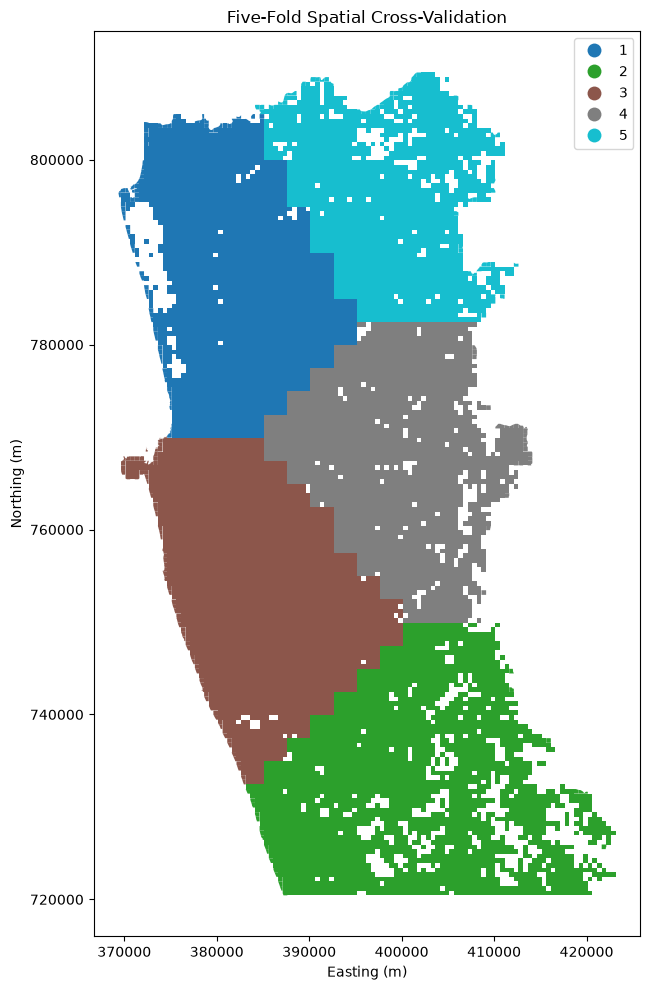


Map saved to:
C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\spatial_folds_map.png

Grid cells per fold:
fold
1    2255
2    2647
3    2459
4    2175
5    1782
Name: count, dtype: int64

Pulse class counts per fold:
pulse_cluster  Cluster_1  Cluster_2    All
fold                                      
1                   1920        335   2255
2                    279       2368   2647
3                    940       1519   2459
4                    873       1302   2175
5                   1399        383   1782
All                 5411       5907  11318

Pulse class percentages within each fold:
pulse_cluster  Cluster_1  Cluster_2
fold                               
1                   85.1       14.9
2                   10.5       89.5
3                   38.2       61.8
4                   40.1       59.9
5                   78.5       21.5


In [27]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. FILE PATHS
# ============================================================

gpkg_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\spatial_folds_5.gpkg"
)

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation"
)

map_path = output_dir / "spatial_folds_map.png"

# ============================================================
# 2. LOAD SPATIAL FOLDS
# ============================================================

gdf = gpd.read_file(
    gpkg_path,
    layer="spatial_folds_5"
)

print("CRS:", gdf.crs)
print("Rows:", len(gdf))
print("Folds:", sorted(gdf["fold"].unique()))

# ============================================================
# 3. PLOT THE FIVE FOLDS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 10))

gdf.plot(
    column="fold",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="none"
)

ax.set_title("Five-Fold Spatial Cross-Validation")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.savefig(map_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nMap saved to:")
print(map_path)

# ============================================================
# 4. CHECK FOLD AND PULSE-CLASS DISTRIBUTIONS
# ============================================================

csv_path = (
    r"C:\Users\sanojan\Downloads\Roaddd"
    r"\Spatial_Cross_Validation\spatial_folds_5.csv"
)

df = pd.read_csv(csv_path)

print("\nGrid cells per fold:")
print(df["fold"].value_counts().sort_index())

print("\nPulse class counts per fold:")
print(
    pd.crosstab(
        df["fold"],
        df["pulse_cluster"],
        margins=True
    )
)

print("\nPulse class percentages within each fold:")
print(
    (
        pd.crosstab(
            df["fold"],
            df["pulse_cluster"],
            normalize="index"
        ) * 100
    ).round(1)
)


In [28]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

base_dir = Path(r"C:\Users\sanojan\Downloads\Roaddd")

full_grid_path = base_dir / "with_Grid_Entropy_CoreNetwork.shp"
fold_path = base_dir / "Spatial_Cross_Validation" / "spatial_folds_5.gpkg"

# Load the complete grid and the spatial-fold grid
full_grid = gpd.read_file(full_grid_path)
fold_grid = gpd.read_file(fold_path, layer="spatial_folds_5")

print("COMPLETE GRID")
print("Rows:", len(full_grid))
print("Unique grid IDs:", full_grid["grid_id"].nunique())

print("\nSPATIAL-FOLD GRID")
print("Rows:", len(fold_grid))
print("Unique grid IDs:", fold_grid["grid_id"].nunique())

# Compare grid IDs
full_ids = set(full_grid["grid_id"])
fold_ids = set(fold_grid["grid_id"])

print("\nGRID COVERAGE CHECK")
print("IDs in complete grid but absent from folds:", len(full_ids - fold_ids))
print("IDs in folds but absent from complete grid:", len(fold_ids - full_ids))

print("\nFold grid columns:")
print(fold_grid.columns.tolist())


COMPLETE GRID
Rows: 15493
Unique grid IDs: 15493

SPATIAL-FOLD GRID
Rows: 11318
Unique grid IDs: 11318

GRID COVERAGE CHECK
IDs in complete grid but absent from folds: 4175
IDs in folds but absent from complete grid: 0

Fold grid columns:
['grid_id', 'centroid_x', 'centroid_y', 'spatial_block', 'fold', 'geometry']


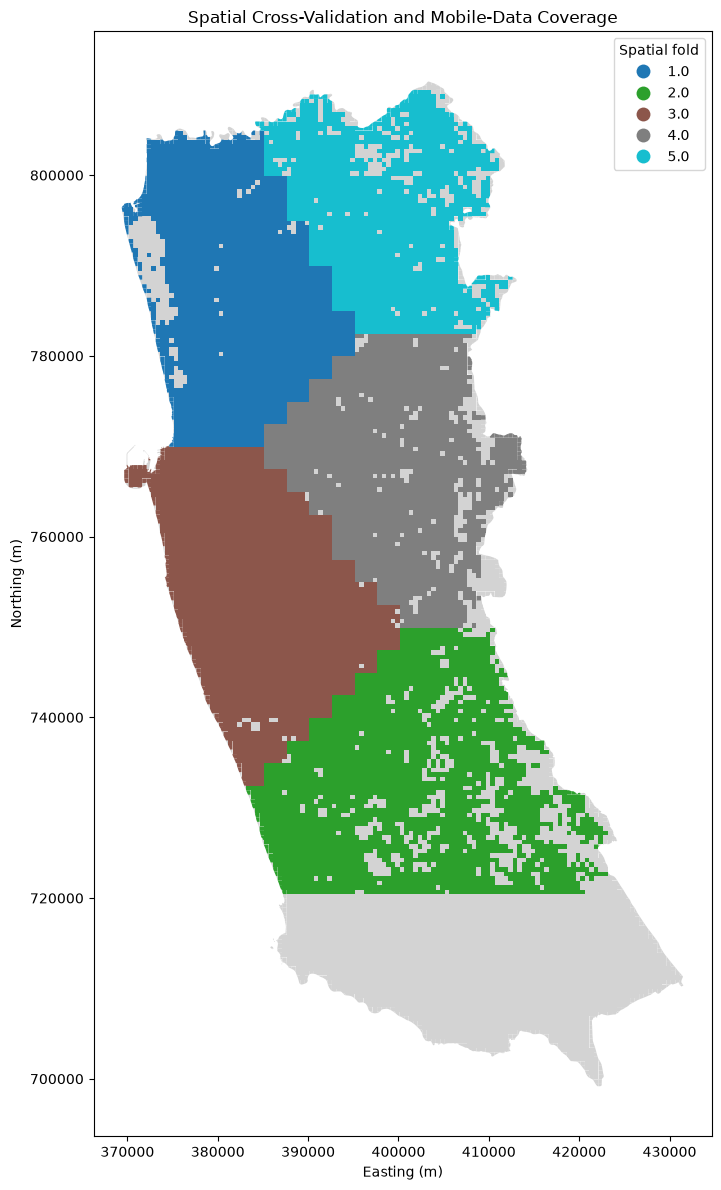

Total grid cells: 15493
Valid modelling cells: 11318
Cells without valid activity data: 4175
Coverage map saved to: C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\spatial_folds_coverage_map.png


In [29]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

base_dir = Path(r"C:\Users\sanojan\Downloads\Roaddd")
output_dir = base_dir / "Spatial_Cross_Validation"

full_grid_path = base_dir / "with_Grid_Entropy_CoreNetwork.shp"
fold_path = output_dir / "spatial_folds_5.gpkg"
map_path = output_dir / "spatial_folds_coverage_map.png"

# 1. Load the full grid and valid modelling cells
full_grid = gpd.read_file(full_grid_path)
fold_grid = gpd.read_file(
    fold_path,
    layer="spatial_folds_5"
)

# 2. Ensure both datasets use the same CRS
if full_grid.crs != fold_grid.crs:
    fold_grid = fold_grid.to_crs(full_grid.crs)

# 3. Mark every grid cell according to mobile-data availability
valid_ids = set(fold_grid["grid_id"])

full_grid["data_status"] = full_grid["grid_id"].isin(valid_ids)
full_grid = full_grid.merge(
    fold_grid[["grid_id", "fold"]],
    on="grid_id",
    how="left",
    validate="one_to_one"
)

# 4. Plot all cells in grey first
fig, ax = plt.subplots(figsize=(12, 12))

missing = full_grid[~full_grid["data_status"]]
valid = full_grid[full_grid["data_status"]]

missing.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="none",
    label="No valid mobile activity data"
)

valid.plot(
    ax=ax,
    column="fold",
    categorical=True,
    legend=True,
    edgecolor="none",
    legend_kwds={"title": "Spatial fold"},
)

ax.set_title("Spatial Cross-Validation and Mobile-Data Coverage")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(map_path, dpi=300, bbox_inches="tight")
plt.show()

print("Total grid cells:", len(full_grid))
print("Valid modelling cells:", len(valid))
print("Cells without valid activity data:", len(missing))
print("Coverage map saved to:", map_path)


In [30]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# FILE PATHS
# --------------------------------------------------
base_dir = Path(r"C:\Users\sanojan\Downloads\Roaddd")

grid_path = base_dir / "with_Grid_Entropy_CoreNetwork.shp"
validated_path = (
    base_dir / "Target_Validation"
    / "validated_targets_all_grids.gpkg"
)

output_dir = base_dir / "Spatial_Cross_Validation"
output_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# PREDICTORS
# --------------------------------------------------
predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------
grid = gpd.read_file(grid_path)

targets = gpd.read_file(
    validated_path,
    layer="validated_targets_all_grids"
)

print("Grid rows:", len(grid))
print("Target rows:", len(targets))

# Confirm unique IDs before joining
assert grid["grid_id"].is_unique, "Duplicate IDs in grid"
assert targets["grid_id"].is_unique, "Duplicate IDs in targets"

# Check required columns
missing_predictors = [
    c for c in predictors if c not in grid.columns
]
if missing_predictors:
    raise ValueError(
        f"Predictors missing from grid: {missing_predictors}"
    )

# Keep only the target fields needed to identify valid observations.
# A cell is observed only if its validated activity target is available.
target_candidates = [
    "total_acti",
    "pulse_cluster",
]

available_target_cols = [
    c for c in target_candidates if c in targets.columns
]

if "total_acti" not in targets.columns:
    raise ValueError(
        "total_acti is not in the target layer. "
        "Check its columns before continuing."
    )

target_subset = targets[
    ["grid_id"] + available_target_cols
].copy()

df = grid[["grid_id"] + predictors].merge(
    target_subset,
    on="grid_id",
    how="left",
    validate="one_to_one"
)

# A valid observed target requires a finite, nonnegative total.
total = pd.to_numeric(df["total_acti"], errors="coerce")
df["data_status"] = (
    total.notna()
    & np.isfinite(total)
    & (total >= 0)
).map({
    True: "Observed",
    False: "Unobserved"
})

print("\nOBSERVATION STATUS")
print(df["data_status"].value_counts())
print("\nObservation percentages:")
print(
    (df["data_status"].value_counts(normalize=True) * 100)
    .round(2)
)

# --------------------------------------------------
# CHECK PREDICTOR MISSINGNESS
# --------------------------------------------------
missingness = df.groupby("data_status")[predictors].apply(
    lambda group: group.isna().mean() * 100
).T

missingness.columns = [
    f"{c}_missing_pct" for c in missingness.columns
]

print("\nPREDICTOR MISSINGNESS (%)")
print(missingness.round(2))

# --------------------------------------------------
# COMPARE PREDICTOR DISTRIBUTIONS
# --------------------------------------------------
rows = []

for col in predictors:
    observed = pd.to_numeric(
        df.loc[df["data_status"] == "Observed", col],
        errors="coerce"
    ).dropna()

    unobserved = pd.to_numeric(
        df.loc[df["data_status"] == "Unobserved", col],
        errors="coerce"
    ).dropna()

    mean_obs = observed.mean()
    mean_unobs = unobserved.mean()
    sd_obs = observed.std()
    sd_unobs = unobserved.std()

    pooled_sd = np.sqrt(
        (sd_obs**2 + sd_unobs**2) / 2
    )

    smd = (
        (mean_obs - mean_unobs) / pooled_sd
        if pd.notna(pooled_sd) and pooled_sd > 0
        else np.nan
    )

    rows.append({
        "predictor": col,
        "observed_n": len(observed),
        "unobserved_n": len(unobserved),
        "observed_mean": mean_obs,
        "unobserved_mean": mean_unobs,
        "observed_median": observed.median(),
        "unobserved_median": unobserved.median(),
        "standardized_mean_difference": smd,
    })

comparison = pd.DataFrame(rows)

print("\nPREDICTOR DISTRIBUTION COMPARISON")
print(comparison.round(3).to_string(index=False))

# Save the results for documentation
comparison_path = output_dir / "coverage_predictor_comparison.csv"
missingness_path = output_dir / "coverage_predictor_missingness.csv"

comparison.to_csv(comparison_path, index=False)
missingness.to_csv(missingness_path)

print("\nSaved:")
print(comparison_path)
print(missingness_path)


Grid rows: 15493
Target rows: 15493

OBSERVATION STATUS
data_status
Observed      11318
Unobserved     4175
Name: count, dtype: int64

Observation percentages:
data_status
Observed      73.05
Unobserved    26.95
Name: proportion, dtype: float64

PREDICTOR MISSINGNESS (%)
            Observed_missing_pct  Unobserved_missing_pct
LConn_wt                     0.0                     0.0
MAD500_wt                    0.0                     0.0
BtA500_wt                    0.0                     0.0
Floor_Inte                   0.0                     0.0
POI_Densit                   0.0                     0.0
Transit_Ac                   0.0                     0.0
IntDen_km2                   0.0                     0.0
land_use_e                   0.0                     0.0

PREDICTOR DISTRIBUTION COMPARISON
 predictor  observed_n  unobserved_n  observed_mean  unobserved_mean  observed_median  unobserved_median  standardized_mean_difference
  LConn_wt       11318          4175         

In [31]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------
base_dir = Path(r"C:\Users\sanojan\Downloads\Roaddd")

data_path = (
    base_dir / "Target_Validation"
    / "validated_modelling_dataset.csv"
)

fold_path = (
    base_dir / "Spatial_Cross_Validation"
    / "spatial_folds_5.csv"
)

output_dir = base_dir / "Spatial_Cross_Validation"
results_path = output_dir / "activity_magnitude_spatial_cv.csv"

# --------------------------------------------------
# 2. PREDICTORS AND TARGET
# --------------------------------------------------
predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

target = "total_acti"

df = pd.read_csv(data_path)
folds = pd.read_csv(fold_path)

# --------------------------------------------------
# 3. VALIDATE INPUT DATA
# --------------------------------------------------
required_data = ["grid_id", target] + predictors
required_folds = ["grid_id", "fold"]

missing_data_cols = [
    c for c in required_data if c not in df.columns
]
missing_fold_cols = [
    c for c in required_folds if c not in folds.columns
]

if missing_data_cols:
    raise ValueError(f"Missing modelling columns: {missing_data_cols}")

if missing_fold_cols:
    raise ValueError(f"Missing fold columns: {missing_fold_cols}")

if df["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values in modelling dataset.")

if folds["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values in fold dataset.")

df = df.merge(
    folds[["grid_id", "fold"]],
    on="grid_id",
    how="left",
    validate="one_to_one"
)

if df["fold"].isna().any():
    raise ValueError("Some modelling cells have no assigned spatial fold.")

if df[required_data].isna().any().any():
    raise ValueError("Missing values found in predictors or target.")

if not np.isfinite(df[predictors + [target]].to_numpy(dtype=float)).all():
    raise ValueError("Infinite or non-finite values found.")

if (df[target] < 0).any():
    raise ValueError("Activity target contains negative values.")

if df["fold"].nunique() != 5:
    raise ValueError("Expected exactly five spatial folds.")

print("Input validation passed.")
print("Modelling rows:", len(df))
print("Spatial folds:", sorted(df["fold"].unique()))
print("Predictors:", len(predictors))

# --------------------------------------------------
# 4. FIVE-FOLD SPATIAL CROSS-VALIDATION
# --------------------------------------------------
X = df[predictors].astype(float)
y = df[target].astype(float)
fold_id = df["fold"].astype(int)

results = []

for fold in sorted(fold_id.unique()):
    train_idx = fold_id != fold
    test_idx = fold_id == fold

    X_train = X.loc[train_idx]
    X_test = X.loc[test_idx]
    y_train = y.loc[train_idx]
    y_test = y.loc[test_idx]

    # Log-transform the target during model training
    y_train_log = np.log1p(y_train)

    model = RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train_log)

    # Convert predictions back to original activity scale
    pred_log = model.predict(X_test)
    y_pred = np.maximum(np.expm1(pred_log), 0)

    # Baseline: training-set median activity
    baseline_pred = np.full(
        len(y_test),
        y_train.median()
    )

    results.append({
        "fold": fold,
        "train_n": len(y_train),
        "test_n": len(y_test),
        "model_R2": r2_score(y_test, y_pred),
        "model_RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "model_MAE": mean_absolute_error(y_test, y_pred),
        "baseline_R2": r2_score(y_test, baseline_pred),
        "baseline_RMSE": np.sqrt(
            mean_squared_error(y_test, baseline_pred)
        ),
        "baseline_MAE": mean_absolute_error(
            y_test, baseline_pred
        ),
    })

results_df = pd.DataFrame(results)
results_df.to_csv(results_path, index=False)

print("\nFIVE-FOLD SPATIAL CV RESULTS")
print(results_df.round(4).to_string(index=False))

metric_cols = [
    "model_R2", "model_RMSE", "model_MAE",
    "baseline_R2", "baseline_RMSE", "baseline_MAE"
]

print("\nMEAN ACROSS THE FIVE FOLDS")
print(results_df[metric_cols].mean().round(4))

print("\nResults saved to:")
print(results_path)


Input validation passed.
Modelling rows: 11318
Spatial folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Predictors: 8

FIVE-FOLD SPATIAL CV RESULTS
 fold  train_n  test_n  model_R2  model_RMSE  model_MAE  baseline_R2  baseline_RMSE  baseline_MAE
    1     9063    2255    0.4002  22157.6575 13951.0214      -0.2594     32107.8433    17477.4838
    2     8671    2647    0.3902   8972.2502  4935.6326      -0.0618     11839.3452     8533.8685
    3     8859    2459    0.2660  53461.2866 28738.9208      -0.5232     77015.7940    45633.1476
    4     9143    2175    0.1818  13307.4787  7672.4175      -0.0177     14841.3434     9145.9186
    5     9536    1782    0.2462   9017.6312  4911.3522      -0.0842     10814.6694     7836.8311

MEAN ACROSS THE FIVE FOLDS
model_R2             0.2969
model_RMSE       21383.2608
model_MAE        12041.8689
baseline_R2         -0.1893
baseline_RMSE    29323.7990
baseline_MAE     17725.4499
dtype: float64

Results saved to:
C:\Users\s

In [32]:

import pandas as pd
import numpy as np
from pathlib import Path

# Validated modelling dataset
csv_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_modelling_dataset.csv"
)

df = pd.read_csv(csv_path)
y = pd.to_numeric(df["total_acti"], errors="coerce").dropna()

print("=" * 55)
print("OBSERVED FUNCTIONAL ACTIVITY DISTRIBUTION")
print("=" * 55)

print(f"Number of observed grid cells: {len(y)}")
print(f"Minimum: {y.min():,.2f}")
print(f"Median: {y.median():,.2f}")
print(f"Mean: {y.mean():,.2f}")
print(f"90th percentile: {y.quantile(0.90):,.2f}")
print(f"95th percentile: {y.quantile(0.95):,.2f}")
print(f"99th percentile: {y.quantile(0.99):,.2f}")
print(f"Maximum: {y.max():,.2f}")

print(f"\nSkewness: {y.skew():.3f}")
print(f"Zero-activity observed cells: {(y == 0).sum()}")


OBSERVED FUNCTIONAL ACTIVITY DISTRIBUTION
Number of observed grid cells: 11318
Minimum: 1.00
Median: 8,049.00
Mean: 20,227.14
90th percentile: 50,912.60
95th percentile: 76,972.00
99th percentile: 175,176.76
Maximum: 671,734.00

Skewness: 5.654
Zero-activity observed cells: 0


In [33]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. FILE PATHS
# ============================================================
data_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_modelling_dataset.csv"
)

fold_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\spatial_folds_5.csv"
)

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation"
)
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD AND VALIDATE DATA
# ============================================================
df = pd.read_csv(data_path)
folds = pd.read_csv(fold_path)

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

required_data = ["grid_id", "pulse_cluster"] + predictors
required_folds = ["grid_id", "fold"]

missing_data = [c for c in required_data if c not in df.columns]
missing_folds = [c for c in required_folds if c not in folds.columns]

if missing_data:
    raise ValueError(f"Missing modelling columns: {missing_data}")

if missing_folds:
    raise ValueError(f"Missing fold columns: {missing_folds}")

if df["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values in modelling dataset.")

if folds["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values in spatial fold file.")

df["pulse_cluster"] = df["pulse_cluster"].astype(str).str.strip()

valid_classes = {"Cluster_1", "Cluster_2"}
unexpected = set(df["pulse_cluster"].unique()) - valid_classes

if unexpected:
    raise ValueError(f"Unexpected pulse classes: {unexpected}")

df[predictors] = df[predictors].apply(
    pd.to_numeric, errors="coerce"
)

if not np.isfinite(df[predictors].to_numpy(dtype=float)).all():
    raise ValueError("Predictors contain missing or non-finite values.")

# Join the previously created spatial folds
df = df.merge(
    folds[["grid_id", "fold"]],
    on="grid_id",
    how="left",
    validate="one_to_one"
)

if df["fold"].isna().any():
    raise ValueError("Some modelling rows do not have a spatial fold.")

if df["fold"].nunique() != 5:
    raise ValueError("Expected exactly five spatial folds.")

df["fold"] = df["fold"].astype(int)

print("Input validation passed.")
print("Modelling rows:", len(df))
print("Predictors:", len(predictors))
print("\nPulse class counts:")
print(df["pulse_cluster"].value_counts())
print("\nFold counts:")
print(df["fold"].value_counts().sort_index())

# ============================================================
# 3. FIVE-FOLD SPATIAL CROSS-VALIDATION
# ============================================================
results = []
oof_predictions = []

for fold in sorted(df["fold"].unique()):

    train = df[df["fold"] != fold].copy()
    test = df[df["fold"] == fold].copy()

    X_train = train[predictors]
    y_train = train["pulse_cluster"]

    X_test = test[predictors]
    y_test = test["pulse_cluster"]

    # Random Forest classifier
    model = RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    # Majority-class baseline learned from training data only
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    baseline_predictions = baseline.predict(X_test)

    # Model metrics
    model_accuracy = accuracy_score(y_test, predictions)
    model_balanced = balanced_accuracy_score(y_test, predictions)
    model_macro_f1 = f1_score(
        y_test, predictions,
        labels=["Cluster_1", "Cluster_2"],
        average="macro",
        zero_division=0
    )

    # Baseline metrics
    baseline_accuracy = accuracy_score(
        y_test, baseline_predictions
    )
    baseline_balanced = balanced_accuracy_score(
        y_test, baseline_predictions
    )
    baseline_macro_f1 = f1_score(
        y_test, baseline_predictions,
        labels=["Cluster_1", "Cluster_2"],
        average="macro",
        zero_division=0
    )

    results.append({
        "fold": fold,
        "train_n": len(train),
        "test_n": len(test),
        "model_accuracy": model_accuracy,
        "model_balanced_accuracy": model_balanced,
        "model_macro_F1": model_macro_f1,
        "baseline_accuracy": baseline_accuracy,
        "baseline_balanced_accuracy": baseline_balanced,
        "baseline_macro_F1": baseline_macro_f1
    })

    fold_predictions = pd.DataFrame({
        "grid_id": test["grid_id"].to_numpy(),
        "fold": fold,
        "actual_pulse": y_test.to_numpy(),
        "predicted_pulse": predictions,
        "baseline_pulse": baseline_predictions
    })

    oof_predictions.append(fold_predictions)

# ============================================================
# 4. REPORT RESULTS
# ============================================================
results_df = pd.DataFrame(results)
predictions_df = pd.concat(oof_predictions, ignore_index=True)

print("\nFIVE-FOLD SPATIAL CV RESULTS")
print(results_df.round(4).to_string(index=False))

metric_columns = [
    "model_accuracy",
    "model_balanced_accuracy",
    "model_macro_F1",
    "baseline_accuracy",
    "baseline_balanced_accuracy",
    "baseline_macro_F1"
]

print("\nMEAN ACROSS THE FIVE FOLDS")
print(results_df[metric_columns].mean().round(4))

# Overall out-of-fold results: each row was predicted
# while its spatial fold was held out from model training.
print("\nOVERALL OUT-OF-FOLD MODEL REPORT")
print(classification_report(
    predictions_df["actual_pulse"],
    predictions_df["predicted_pulse"],
    labels=["Cluster_1", "Cluster_2"],
    zero_division=0,
    digits=4
))

print("OVERALL OUT-OF-FOLD CONFUSION MATRIX")
print("Rows = actual classes; columns = predicted classes")
print(confusion_matrix(
    predictions_df["actual_pulse"],
    predictions_df["predicted_pulse"],
    labels=["Cluster_1", "Cluster_2"]
))

# ============================================================
# 5. SAVE RESULTS
# ============================================================
results_path = output_dir / "pulse_classification_spatial_cv.csv"
predictions_path = output_dir / "pulse_classification_oof_predictions.csv"

results_df.to_csv(results_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

print("\nResults saved to:")
print(results_path)
print(predictions_path)


Input validation passed.
Modelling rows: 11318
Predictors: 8

Pulse class counts:
pulse_cluster
Cluster_2    5907
Cluster_1    5411
Name: count, dtype: int64

Fold counts:
fold
1    2255
2    2647
3    2459
4    2175
5    1782
Name: count, dtype: int64

FIVE-FOLD SPATIAL CV RESULTS
 fold  train_n  test_n  model_accuracy  model_balanced_accuracy  model_macro_F1  baseline_accuracy  baseline_balanced_accuracy  baseline_macro_F1
    1     9063    2255          0.3685                   0.5257          0.3548             0.1486                         0.5             0.1293
    2     8671    2647          0.6105                   0.4361          0.4277             0.1054                         0.5             0.0954
    3     8859    2459          0.5636                   0.6403          0.5499             0.3823                         0.5             0.2766
    4     9143    2175          0.5880                   0.5661          0.5665             0.5986                         0.5       

In [34]:

import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

prediction_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\pulse_classification_oof_predictions.csv"
)

df = pd.read_csv(prediction_path)

classes = ["Cluster_1", "Cluster_2"]
results = []

for fold, part in df.groupby("fold"):

    actual = part["actual_pulse"]
    predicted = part["predicted_pulse"]

    results.append({
        "fold": fold,
        "test_cells": len(part),
        "actual_Cluster_1_pct": 100 * (actual == "Cluster_1").mean(),
        "actual_Cluster_2_pct": 100 * (actual == "Cluster_2").mean(),
        "predicted_Cluster_1_pct": 100 * (predicted == "Cluster_1").mean(),
        "predicted_Cluster_2_pct": 100 * (predicted == "Cluster_2").mean(),
        "accuracy": accuracy_score(actual, predicted),
        "balanced_accuracy": balanced_accuracy_score(actual, predicted),
        "macro_F1": f1_score(
            actual, predicted,
            labels=classes,
            average="macro",
            zero_division=0
        ),
        "Cluster_1_recall": recall_score(
            actual, predicted,
            labels=classes,
            average=None,
            zero_division=0
        )[0],
        "Cluster_2_recall": recall_score(
            actual, predicted,
            labels=classes,
            average=None,
            zero_division=0
        )[1]
    })

report = pd.DataFrame(results).round(4)

print("PULSE CLASSIFICATION: FOLD DIAGNOSTICS")
print(report.to_string(index=False))


PULSE CLASSIFICATION: FOLD DIAGNOSTICS
 fold  test_cells  actual_Cluster_1_pct  actual_Cluster_2_pct  predicted_Cluster_1_pct  predicted_Cluster_2_pct  accuracy  balanced_accuracy  macro_F1  Cluster_1_recall  Cluster_2_recall
    1        2255               85.1441               14.8559                  29.4457                  70.5543    0.3685             0.5257    0.3548            0.3021            0.7493
    2        2647               10.5402               89.4598                  32.9430                  67.0570    0.6105             0.4361    0.4277            0.2151            0.6571
    3        2459               38.2269               61.7731                  79.2599                  20.7401    0.5636             0.6403    0.5499            0.9660            0.3147
    4        2175               40.1379               59.8621                  37.5632                  62.4368    0.5880             0.5661    0.5665            0.4548            0.6774
    5        1782         

In [35]:

import pandas as pd
import numpy as np
from pathlib import Path

data_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_modelling_dataset.csv"
)

df = pd.read_csv(data_path)

pulse_cols = [f"pulse_{h:02d}" for h in range(24)]
required = ["pulse_cluster"] + pulse_cols

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["pulse_cluster"] = df["pulse_cluster"].astype(str).str.strip()
df[pulse_cols] = df[pulse_cols].apply(
    pd.to_numeric, errors="coerce"
)

df = df[
    df["pulse_cluster"].isin(["Cluster_1", "Cluster_2"])
].copy()

df = df.dropna(subset=pulse_cols)

# Keep valid normalized profiles only
profile_sums = df[pulse_cols].sum(axis=1)
df = df[
    np.isfinite(profile_sums)
    & np.isclose(profile_sums, 1.0, atol=0.02)
].copy()

# Mean normalized hourly profile for each cluster
mean_profiles = df.groupby("pulse_cluster")[pulse_cols].mean()

print("VALID PROFILE COUNTS")
print(df["pulse_cluster"].value_counts())

print("\nMEAN NORMALIZED HOURLY PROFILES")
print(mean_profiles.round(4).to_string())

print("\nHOURS WITH HIGHEST MEAN ACTIVITY SHARE")
for cluster in ["Cluster_1", "Cluster_2"]:
    top_hours = (
        mean_profiles.loc[cluster]
        .sort_values(ascending=False)
        .head(6)
    )
    print(f"\n{cluster}:")
    print(top_hours.round(4).to_string())

# Difference in average share by hour
difference = mean_profiles.loc["Cluster_1"] - mean_profiles.loc["Cluster_2"]

print("\nHOURLY PROFILE DIFFERENCE (Cluster_1 - Cluster_2)")
print(difference.round(4).to_string())


VALID PROFILE COUNTS
pulse_cluster
Cluster_2    5907
Cluster_1    5411
Name: count, dtype: int64

MEAN NORMALIZED HOURLY PROFILES
               pulse_00  pulse_01  pulse_02  pulse_03  pulse_04  pulse_05  pulse_06  pulse_07  pulse_08  pulse_09  pulse_10  pulse_11  pulse_12  pulse_13  pulse_14  pulse_15  pulse_16  pulse_17  pulse_18  pulse_19  pulse_20  pulse_21  pulse_22  pulse_23
pulse_cluster                                                                                                                                                                                                                                                
Cluster_1        0.0276    0.0132    0.0166    0.0163     0.022    0.0294    0.0453    0.0558    0.0601    0.0214    0.0651    0.0356    0.0407    0.0534    0.0469    0.0359    0.0545    0.0404    0.0561    0.0636    0.0490    0.0488    0.0503    0.0519
Cluster_2        0.0545    0.0375    0.0206    0.0220     0.031    0.0357    0.0562    0.0536    0.0528    0

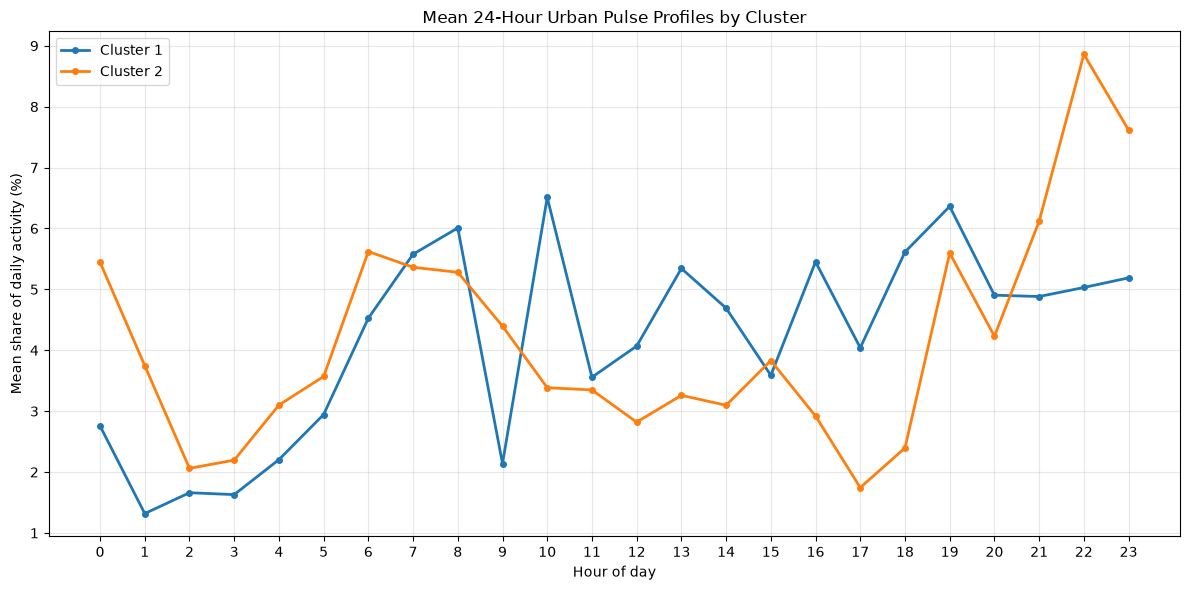

Pulse profile plot saved to:
C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\mean_pulse_profiles.png


In [36]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_modelling_dataset.csv"
)

output_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\mean_pulse_profiles.png"
)

df = pd.read_csv(data_path)

pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

df["pulse_cluster"] = df["pulse_cluster"].astype(str).str.strip()
df = df[df["pulse_cluster"].isin(["Cluster_1", "Cluster_2"])].copy()

for col in pulse_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=pulse_cols)

mean_profiles = df.groupby("pulse_cluster")[pulse_cols].mean()

hours = list(range(24))

plt.figure(figsize=(12, 6))

for cluster in ["Cluster_1", "Cluster_2"]:
    plt.plot(
        hours,
        mean_profiles.loc[cluster].values * 100,
        marker="o",
        markersize=4,
        linewidth=2,
        label=cluster.replace("_", " ")
    )

plt.xticks(hours)
plt.xlabel("Hour of day")
plt.ylabel("Mean share of daily activity (%)")
plt.title("Mean 24-Hour Urban Pulse Profiles by Cluster")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Pulse profile plot saved to:")
print(output_path)


In [37]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

# ============================================================
# 1. FILE PATHS
# ============================================================
data_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_modelling_dataset.csv"
)

fold_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation\spatial_folds_5.csv"
)

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Spatial_Cross_Validation"
)
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD DATA
# ============================================================
df = pd.read_csv(data_path)
folds = pd.read_csv(fold_path)

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

df["pulse_cluster"] = df["pulse_cluster"].astype(str).str.strip()

df = df.merge(
    folds[["grid_id", "fold"]],
    on="grid_id",
    how="left",
    validate="one_to_one"
)

if df["fold"].isna().any():
    raise ValueError("Some rows are missing spatial fold assignments.")

if df["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid IDs detected.")

if df[predictors].isna().any().any():
    raise ValueError("Missing predictor values detected.")

if not np.isfinite(df[predictors].to_numpy(dtype=float)).all():
    raise ValueError("Non-finite predictor values detected.")

# ============================================================
# 3. PERMUTATION IMPORTANCE ON HELD-OUT SPATIAL FOLDS
# ============================================================
fold_results = []

for fold in sorted(df["fold"].unique()):

    train = df[df["fold"] != fold]
    test = df[df["fold"] == fold]

    X_train = train[predictors]
    y_train = train["pulse_cluster"]

    X_test = test[predictors]
    y_test = test["pulse_cluster"]

    model = RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    baseline_predictions = model.predict(X_test)
    baseline_macro_f1 = f1_score(
        y_test,
        baseline_predictions,
        average="macro",
        zero_division=0
    )

    importance = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=5,
        random_state=42,
        n_jobs=1
    )

    for i, predictor in enumerate(predictors):
        fold_results.append({
            "fold": int(fold),
            "test_n": len(test),
            "baseline_macro_F1": baseline_macro_f1,
            "predictor": predictor,
            "importance_mean": importance.importances_mean[i],
            "importance_std": importance.importances_std[i]
        })

    print(
        f"Fold {fold} completed | "
        f"test cells: {len(test)} | "
        f"Macro-F1: {baseline_macro_f1:.4f}"
    )

# ============================================================
# 4. SUMMARIZE IMPORTANCE ACROSS FOLDS
# ============================================================
details = pd.DataFrame(fold_results)

summary = (
    details.groupby("predictor")
    .agg(
        mean_importance=("importance_mean", "mean"),
        sd_across_folds=("importance_mean", "std"),
        mean_permutation_sd=("importance_std", "mean"),
        positive_folds=(
            "importance_mean",
            lambda values: int((values > 0).sum())
        )
    )
    .sort_values("mean_importance", ascending=False)
    .reset_index()
)

print("\nPERMUTATION IMPORTANCE BY PREDICTOR")
print(summary.round(5).to_string(index=False))

print("\nIMPORTANCE WITHIN EACH FOLD")
pivot = details.pivot(
    index="predictor",
    columns="fold",
    values="importance_mean"
)
print(pivot.round(5).to_string())

# ============================================================
# 5. SAVE OUTPUTS
# ============================================================
summary_path = output_dir / "pulse_permutation_importance_summary.csv"
details_path = output_dir / "pulse_permutation_importance_by_fold.csv"

summary.to_csv(summary_path, index=False)
details.to_csv(details_path, index=False)

print("\nSaved summary:")
print(summary_path)

print("\nSaved fold-level details:")
print(details_path)


Fold 1 completed | test cells: 2255 | Macro-F1: 0.3548
Fold 2 completed | test cells: 2647 | Macro-F1: 0.4277
Fold 3 completed | test cells: 2459 | Macro-F1: 0.5499
Fold 4 completed | test cells: 2175 | Macro-F1: 0.5665
Fold 5 completed | test cells: 1782 | Macro-F1: 0.3258

PERMUTATION IMPORTANCE BY PREDICTOR
 predictor  mean_importance  sd_across_folds  mean_permutation_sd  positive_folds
IntDen_km2          0.03189          0.06677              0.00409               4
Floor_Inte          0.02665          0.02845              0.00562               4
land_use_e          0.01408          0.01554              0.00527               5
 BtA500_wt          0.01222          0.01948              0.00486               4
Transit_Ac          0.00891          0.01287              0.00347               4
 MAD500_wt          0.00422          0.00669              0.00361               4
  LConn_wt          0.00047          0.00442              0.00256               3
POI_Densit          0.00005     

District columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']
Grid columns: ['id', 'left', 'top', 'right', 'bottom', 'row_index', 'col_index', 'grid_id', 'Bldg_Cov', 'Floor_Inte', 'POI_Densit', 'Transit_Ac', 'IntDen_km2', 'x_bin', 'y_bin', 'total_acti', 'activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23', 'pulse_00', 'pulse_01', 'pulse_02', 'pulse_03', 'pulse_04', 'pulse_05', 'pulse_06', 'pulse_07', 'pulse_08', 'pulse_09', 'pu

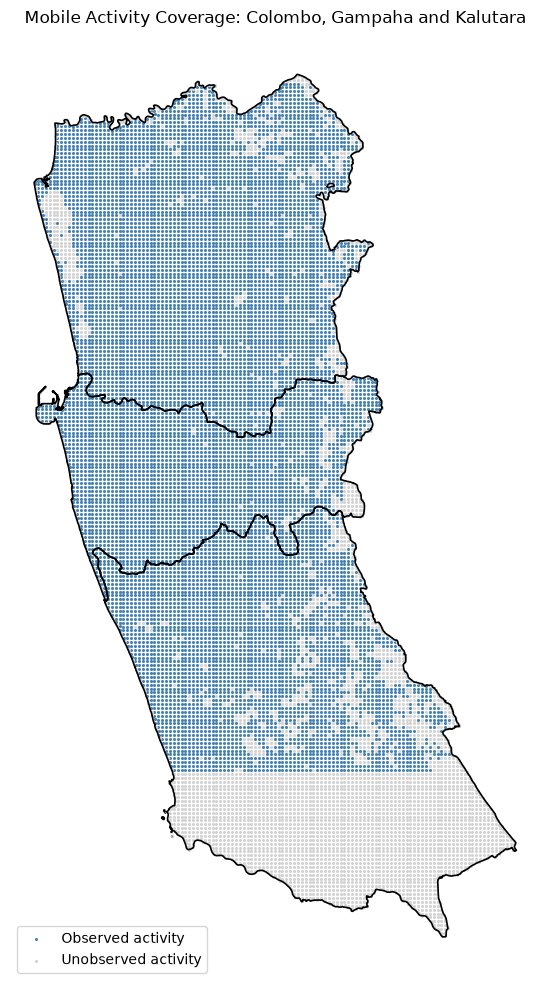


Files saved to: C:\Users\sanojan\Downloads\Roaddd\District_Coverage_Check


In [38]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. FILE PATHS
# ============================================================
district_path = Path(r"C:\Users\sanojan\Downloads\Roaddd\Districts.shp")

grid_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

target_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_targets_all_grids.gpkg"
)

target_layer = "validated_targets_all_grids"

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\District_Coverage_Check"
)
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD DATA
# ============================================================
districts = gpd.read_file(district_path)
grid = gpd.read_file(grid_path)
targets = gpd.read_file(target_path, layer=target_layer)

print("District columns:", districts.columns.tolist())
print("Grid columns:", grid.columns.tolist())
print("Target columns:", targets.columns.tolist())

# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================
if "adm2_name" not in districts.columns:
    raise ValueError("Districts.shp does not contain adm2_name.")

if "grid_id" not in grid.columns:
    raise ValueError("Grid data does not contain grid_id.")

if "grid_id" not in targets.columns:
    raise ValueError("Target data does not contain grid_id.")

if "total_acti" not in targets.columns:
    raise ValueError(
        "total_acti is missing from the target dataset. "
        "Check the target columns printed above."
    )

# ============================================================
# 4. SELECT THE THREE DISTRICTS
# ============================================================
districts["district_name"] = (
    districts["adm2_name"].astype(str).str.strip().str.title()
)

selected_districts = districts[
    districts["district_name"].isin(
        ["Colombo", "Gampaha", "Kalutara"]
    )
].copy()

if selected_districts.empty:
    raise ValueError(
        "No matching districts found. Check the actual adm2_name values."
    )

print("\nSelected district names:")
print(selected_districts["district_name"].value_counts())

# ============================================================
# 5. CHECK UNIQUE GRID IDS
# ============================================================
if grid["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values found in grid data.")

if targets["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values found in target data.")

# A cell is observed only if its total activity target is valid.
targets["observed_activity"] = (
    pd.to_numeric(targets["total_acti"], errors="coerce")
    .notna()
    & pd.to_numeric(targets["total_acti"], errors="coerce").ge(0)
)

target_status = targets[["grid_id", "observed_activity"]].copy()

# ============================================================
# 6. ALIGN COORDINATE REFERENCE SYSTEMS
# ============================================================
if grid.crs is None or selected_districts.crs is None:
    raise ValueError("Grid or district layer has no defined CRS.")

selected_districts = selected_districts.to_crs(grid.crs)

# Use grid centroids to assign each cell to a district.
# This avoids counting the same cell twice along district boundaries.
grid_points = grid[["grid_id", "geometry"]].copy()
grid_points["geometry"] = grid_points.geometry.centroid

# ============================================================
# 7. ASSIGN GRID CELLS TO DISTRICTS
# ============================================================
joined = gpd.sjoin(
    grid_points,
    selected_districts[["district_name", "geometry"]],
    how="inner",
    predicate="within"
)

# Resolve any rare duplicate assignments on shared boundaries.
joined = joined.drop_duplicates(subset="grid_id", keep="first")

joined = joined.merge(
    target_status,
    on="grid_id",
    how="left",
    validate="one_to_one"
)

joined["observed_activity"] = (
    joined["observed_activity"].fillna(False).astype(bool)
)

# ============================================================
# 8. CALCULATE DISTRICT COVERAGE
# ============================================================
report = (
    joined.groupby("district_name")
    .agg(
        total_grid_cells=("grid_id", "nunique"),
        observed_cells=("observed_activity", "sum")
    )
    .reset_index()
)

report["unobserved_cells"] = (
    report["total_grid_cells"] - report["observed_cells"]
)

report["observed_percent"] = (
    100 * report["observed_cells"] / report["total_grid_cells"]
)

report["unobserved_percent"] = (
    100 * report["unobserved_cells"] / report["total_grid_cells"]
)

report = report.sort_values("district_name")

print("\n" + "=" * 70)
print("MOBILE ACTIVITY COVERAGE BY DISTRICT")
print("=" * 70)
print(report.round(2).to_string(index=False))

# ============================================================
# 9. COMPARE COLOMBO + GAMPAHA AGAINST ALL THREE DISTRICTS
# ============================================================
report["study_option"] = report["district_name"]

selected_two = report[
    report["district_name"].isin(["Colombo", "Gampaha"])
]

two_total = selected_two["total_grid_cells"].sum()
two_observed = selected_two["observed_cells"].sum()

three_total = report["total_grid_cells"].sum()
three_observed = report["observed_cells"].sum()

comparison = pd.DataFrame([
    {
        "study_area": "Colombo + Gampaha",
        "total_grid_cells": two_total,
        "observed_cells": two_observed,
        "unobserved_cells": two_total - two_observed,
        "observed_percent": (
            100 * two_observed / two_total if two_total else 0
        )
    },
    {
        "study_area": "Colombo + Gampaha + Kalutara",
        "total_grid_cells": three_total,
        "observed_cells": three_observed,
        "unobserved_cells": three_total - three_observed,
        "observed_percent": (
            100 * three_observed / three_total if three_total else 0
        )
    }
])

print("\n" + "=" * 70)
print("STUDY AREA COMPARISON")
print("=" * 70)
print(comparison.round(2).to_string(index=False))

# ============================================================
# 10. SAVE REPORTS
# ============================================================
report.to_csv(
    output_dir / "district_activity_coverage.csv",
    index=False
)

comparison.to_csv(
    output_dir / "study_area_coverage_comparison.csv",
    index=False
)

# ============================================================
# 11. MAP OBSERVED AND UNOBSERVED CELLS
# ============================================================
joined["coverage_status"] = joined["observed_activity"].map({
    True: "Observed activity",
    False: "Unobserved activity"
})

fig, ax = plt.subplots(figsize=(12, 10))

selected_districts.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.2
)

colors = {
    "Observed activity": "steelblue",
    "Unobserved activity": "lightgray"
}

for status, color in colors.items():
    subset = joined[joined["coverage_status"] == status]
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=color,
            markersize=1.5,
            label=status
        )

ax.set_title(
    "Mobile Activity Coverage: Colombo, Gampaha and Kalutara"
)
ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(
    output_dir / "district_activity_coverage_map.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nFiles saved to:", output_dir)


In [39]:

import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. INPUT PATHS
# ============================================================
district_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Districts.shp"
)

grid_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

target_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_targets_all_grids.gpkg"
)

target_layer = "validated_targets_all_grids"

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD INPUTS
# ============================================================
districts = gpd.read_file(district_path)
grid = gpd.read_file(grid_path)
targets = gpd.read_file(target_path, layer=target_layer)

print("=" * 65)
print("STEP 1A — INPUT DATA")
print("=" * 65)

print("District features:", len(districts))
print("Grid cells:", len(grid))
print("Target records:", len(targets))

print("\nCRS:")
print("Districts:", districts.crs)
print("Grid:", grid.crs)
print("Targets:", targets.crs)

# ============================================================
# 3. CHECK REQUIRED FIELDS
# ============================================================
required_district = {"adm2_name", "geometry"}
required_grid = {"grid_id", "geometry"}
required_targets = {
    "grid_id", "total_acti", "target_valid", "pulse_cluster"
}

for name, data, required in [
    ("Districts", districts, required_district),
    ("Grid", grid, required_grid),
    ("Targets", targets, required_targets),
]:
    missing = required - set(data.columns)
    if missing:
        raise ValueError(f"{name} missing required fields: {sorted(missing)}")

if any(layer.crs is None for layer in [districts, grid, targets]):
    raise ValueError("A layer has no CRS. Check its coordinate reference system.")

# ============================================================
# 4. CHECK DUPLICATE GRID IDS
# ============================================================
print("\n" + "=" * 65)
print("STEP 1B — UNIQUE GRID IDS")
print("=" * 65)

print("Grid duplicate IDs:", grid["grid_id"].duplicated().sum())
print("Target duplicate IDs:", targets["grid_id"].duplicated().sum())

if grid["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid IDs in the complete grid.")

if targets["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid IDs in the target dataset.")

grid_ids = set(grid["grid_id"].dropna())
target_ids = set(targets["grid_id"].dropna())

print("Grid IDs missing from target file:", len(grid_ids - target_ids))
print("Target IDs absent from grid file:", len(target_ids - grid_ids))

# ============================================================
# 5. SELECT COLOMBO AND GAMPAHA
# ============================================================
districts["district_name"] = (
    districts["adm2_name"].astype(str).str.strip().str.title()
)

study_districts = districts[
    districts["district_name"].isin(["Colombo", "Gampaha"])
].copy()

print("\n" + "=" * 65)
print("STEP 1C — SELECTED DISTRICTS")
print("=" * 65)

print(study_districts["district_name"].value_counts())

if set(study_districts["district_name"]) != {"Colombo", "Gampaha"}:
    raise ValueError("Could not find both Colombo and Gampaha.")

# Use the grid CRS for spatial operations
study_districts = study_districts.to_crs(grid.crs)

# Repair invalid district geometries if needed
study_districts["geometry"] = study_districts.geometry.make_valid()

# ============================================================
# 6. ASSIGN CELLS USING THEIR CENTROIDS
# ============================================================
grid_points = grid[["grid_id", "geometry"]].copy()
grid_points["geometry"] = grid_points.geometry.centroid

cells_in_study = gpd.sjoin(
    grid_points,
    study_districts[["district_name", "geometry"]],
    how="inner",
    predicate="within"
)

# Avoid duplicate assignments along boundaries
cells_in_study = cells_in_study.drop_duplicates(
    subset="grid_id",
    keep="first"
)

study_ids = set(cells_in_study["grid_id"])

print("\n" + "=" * 65)
print("STEP 1D — STUDY-AREA GRID")
print("=" * 65)

print("Cells assigned to Colombo/Gampaha:", len(study_ids))
print("Grid cells outside these districts:", len(grid) - len(study_ids))

print("\nCells by district:")
print(
    cells_in_study.groupby("district_name")["grid_id"]
    .nunique()
    .to_string()
)

# ============================================================
# 7. CHECK VALIDATED TARGETS
# ============================================================
study_targets = targets[targets["grid_id"].isin(study_ids)].copy()

study_targets["target_valid"] = (
    study_targets["target_valid"]
    .astype("string")
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes"])
)

# Independently check whether the activity total is numeric and finite
activity = pd.to_numeric(
    study_targets["total_acti"], errors="coerce"
)

study_targets["activity_numeric_valid"] = (
    activity.notna()
    & np.isfinite(activity)
    & (activity >= 0)
)

# Valid modelling target requires the validation flag and a valid total
study_targets["usable_activity"] = (
    study_targets["target_valid"]
    & study_targets["activity_numeric_valid"]
)

print("\n" + "=" * 65)
print("STEP 1E — TARGET COVERAGE")
print("=" * 65)

print("Study-area cells:", len(study_ids))
print("Target records in study area:", len(study_targets))
print("Valid activity targets:", int(study_targets["usable_activity"].sum()))
print("Unobserved/invalid activity targets:",
      int((~study_targets["usable_activity"]).sum()))

if len(study_ids) > 0:
    print(
        "Coverage percentage:",
        round(100 * study_targets["usable_activity"].sum() / len(study_ids), 2),
        "%"
    )

print("\nTarget validity by district:")
district_target_check = cells_in_study[
    ["grid_id", "district_name"]
].merge(
    study_targets[["grid_id", "usable_activity"]],
    on="grid_id",
    how="left",
    validate="one_to_one"
)

district_target_check["usable_activity"] = (
    district_target_check["usable_activity"].fillna(False)
)

print(
    district_target_check.groupby("district_name")
    .agg(
        total_cells=("grid_id", "nunique"),
        valid_targets=("usable_activity", "sum")
    )
    .assign(
        coverage_percent=lambda x:
        100 * x["valid_targets"] / x["total_cells"]
    )
    .round(2)
    .to_string()
)

# ============================================================
# 8. CHECK THE EIGHT PREDICTORS
# ============================================================
predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

missing_predictors = set(predictors) - set(grid.columns)

if missing_predictors:
    raise ValueError(
        f"Missing predictors in grid: {sorted(missing_predictors)}"
    )

study_grid = grid[grid["grid_id"].isin(study_ids)].copy()

print("\n" + "=" * 65)
print("STEP 1F — PREDICTOR QUALITY")
print("=" * 65)

predictor_check = pd.DataFrame({
    "missing": study_grid[predictors].isna().sum(),
    "non_finite": ~np.isfinite(
        study_grid[predictors].apply(pd.to_numeric, errors="coerce")
    ).sum()
})

# Correctly calculate non-finite counts column by column
predictor_check["non_finite"] = [
    (~np.isfinite(pd.to_numeric(study_grid[c], errors="coerce"))).sum()
    for c in predictors
]

print(predictor_check.to_string())

# ============================================================
# 9. CHECK PULSE TARGETS
# ============================================================
pulse_cols = [f"pulse_{h:02d}" for h in range(24)]

missing_pulse_cols = set(pulse_cols) - set(targets.columns)

print("\n" + "=" * 65)
print("STEP 1G — PULSE TARGET QUALITY")
print("=" * 65)

if missing_pulse_cols:
    print("Missing pulse columns:", sorted(missing_pulse_cols))
else:
    pulse = study_targets[pulse_cols].apply(
        pd.to_numeric, errors="coerce"
    )
    finite_profiles = np.isfinite(pulse).all(axis=1)
    sums = pulse.sum(axis=1, min_count=24)

    valid_profiles = (
        finite_profiles
        & np.isclose(sums, 1.0, atol=0.01)
        & pulse.ge(0).all(axis=1)
    )

    print("Rows with finite 24-hour profiles:", int(finite_profiles.sum()))
    print("Profiles summing approximately to 1:",
          int(valid_profiles.sum()))

    print("\nPulse classes among valid activity targets:")
    print(
        study_targets.loc[
            study_targets["usable_activity"], "pulse_cluster"
        ].value_counts(dropna=False).to_string()
    )

# ============================================================
# 10. SAVE INITIAL DIAGNOSTIC OUTPUTS
# ============================================================
district_target_check.to_csv(
    output_dir / "step1_district_target_coverage.csv",
    index=False
)

predictor_check.to_csv(
    output_dir / "step1_predictor_quality.csv"
)

print("\n" + "=" * 65)
print("STEP 1 CHECK FINISHED")
print("=" * 65)
print("Diagnostic files saved in:", output_dir)
print("No original files were changed.")


STEP 1A — INPUT DATA
District features: 3
Grid cells: 15493
Target records: 15493

CRS:
Districts: EPSG:32644
Grid: EPSG:32644
Targets: EPSG:32644

STEP 1B — UNIQUE GRID IDS
Grid duplicate IDs: 0
Target duplicate IDs: 0
Grid IDs missing from target file: 0
Target IDs absent from grid file: 0

STEP 1C — SELECTED DISTRICTS
district_name
Colombo    1
Gampaha    1
Name: count, dtype: int64

STEP 1D — STUDY-AREA GRID
Cells assigned to Colombo/Gampaha: 8696
Grid cells outside these districts: 6797

Cells by district:
district_name
Colombo    2836
Gampaha    5860

STEP 1E — TARGET COVERAGE
Study-area cells: 8696
Target records in study area: 8696
Valid activity targets: 7764
Unobserved/invalid activity targets: 932
Coverage percentage: 89.28 %

Target validity by district:
               total_cells  valid_targets  coverage_percent
district_name                                              
Colombo               2836           2586             91.18
Gampaha               5860           5178  

In [42]:

# ============================================================
# COLOMBO + GAMPAHA
# FINAL DATA PREPARATION AND FIVE-FOLD SPATIAL VALIDATION
#
# Targets:
#   1. Total activity magnitude: total_acti
#   2. 24 hourly activity values: activity_0 ... activity23
#
# No pulse-cluster classification.
# ============================================================

from pathlib import Path
import warnings

import geopandas as gpd
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans


# ============================================================
# 1. FILE PATHS AND SETTINGS
# ============================================================

base = Path(r"C:\Users\sanojan\Downloads\Roaddd")

district_path = base / "Districts.shp"

grid_path = (
    base / "with_Grid_Entropy_CoreNetwork.shp"
)

target_path = (
    base
    / "Target_Validation"
    / "validated_targets_all_grids.gpkg"
)

output_dir = base / "Colombo_Gampaha_Final"
output_dir.mkdir(parents=True, exist_ok=True)

output_csv = (
    output_dir / "colombo_gampaha_two_target_dataset.csv"
)

output_report = (
    output_dir / "colombo_gampaha_regression_fold_check.csv"
)

output_gpkg = (
    output_dir / "colombo_gampaha_two_target_folds.gpkg"
)

output_blocks = (
    output_dir / "colombo_gampaha_spatial_blocks.csv"
)

BLOCK_SIZE_M = 2500
N_FOLDS = 5
RANDOM_STATE = 42

# Your projected CRS from the existing grid and district files.
EXPECTED_CRS = "EPSG:32644"


# ============================================================
# 2. DEFINE PREDICTORS AND TARGETS
# ============================================================

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

# Correct original hourly column names:
# activity_0 ... activity_9
# activity10 ... activity23
hourly_cols = [
    f"activity_{h}" if h < 10 else f"activity{h}"
    for h in range(24)
]

target_cols = ["total_acti"] + hourly_cols

district_names = ["Colombo", "Gampaha"]


# ============================================================
# 3. CHECK INPUT FILES
# ============================================================

for path in [district_path, grid_path, target_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Input file not found:\n{path}"
        )

print("=" * 65)
print("INPUT FILE CHECK")
print("=" * 65)

print("District file:", district_path)
print("Grid file:", grid_path)
print("Target file:", target_path)


# ============================================================
# 4. LOAD DATA
# ============================================================

districts = gpd.read_file(district_path)

grid = gpd.read_file(grid_path)

targets = gpd.read_file(
    target_path,
    layer="validated_targets_all_grids"
)

print("\nLoaded records:")
print("District features:", len(districts))
print("Grid records:", len(grid))
print("Target records:", len(targets))

if grid.crs is None or districts.crs is None:
    raise ValueError(
        "Grid or district file has no CRS. "
        "Set its correct CRS before continuing."
    )

# Convert district and grid data to the same projected CRS.
districts = districts.to_crs(EXPECTED_CRS)
grid = grid.to_crs(EXPECTED_CRS)

# Target attributes are joined by grid_id, so target geometry
# is not required for the merge.


# ============================================================
# 5. CHECK REQUIRED COLUMNS
# ============================================================

if "adm2_name" not in districts.columns:
    raise KeyError(
        "The district file must contain the 'adm2_name' field. "
        f"Available fields: {districts.columns.tolist()}"
    )

if "grid_id" not in grid.columns:
    raise KeyError(
        "The grid file does not contain grid_id."
    )

if "grid_id" not in targets.columns:
    raise KeyError(
        "The target file does not contain grid_id."
    )

missing_predictors = [
    c for c in predictors if c not in grid.columns
]

missing_targets = [
    c for c in target_cols if c not in targets.columns
]

if missing_predictors:
    raise ValueError(
        "Missing predictors in grid file:\n"
        + "\n".join(missing_predictors)
    )

if missing_targets:
    raise ValueError(
        "Missing activity targets in target file:\n"
        + "\n".join(missing_targets)
    )


# ============================================================
# 6. FILTER COLOMBO AND GAMPAHA
#    USING GRID CENTROIDS WITHIN DISTRICT POLYGONS
# ============================================================

districts_selected = districts[
    districts["adm2_name"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .isin([n.casefold() for n in district_names])
].copy()

found_districts = (
    districts_selected["adm2_name"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .unique()
)

if len(found_districts) != 2:
    raise ValueError(
        "Could not identify both Colombo and Gampaha. "
        "Check the exact names in districts['adm2_name'].\n"
        f"Selected names: {found_districts.tolist()}"
    )

# Keep only fields needed from the grid.
# This is important: activity columns are taken from targets,
# not from the grid file.
grid_keep = [
    "grid_id",
    *predictors,
    "geometry"
]

grid_predictors = grid[grid_keep].copy()

if grid_predictors["grid_id"].duplicated().any():
    raise ValueError(
        "Duplicate grid_id values exist in the grid file."
    )

# Use centroids for district assignment.
centroid_points = grid_predictors[
    ["grid_id", "geometry"]
].copy()

centroid_points["geometry"] = (
    centroid_points.geometry.centroid
)

district_polygons = districts_selected[
    ["adm2_name", "geometry"]
].rename(columns={"adm2_name": "district_name"})

# Spatial join: each centroid should fall within one district.
assigned = gpd.sjoin(
    centroid_points,
    district_polygons,
    how="inner",
    predicate="within"
)

# In the unlikely event a centroid intersects multiple
# overlapping district polygons, retain one assignment per ID.
assigned = assigned.drop_duplicates(
    subset=["grid_id"],
    keep="first"
)

study_ids = assigned["grid_id"].unique()

grid_study = grid_predictors[
    grid_predictors["grid_id"].isin(study_ids)
].copy()

grid_study = grid_study.merge(
    assigned[["grid_id", "district_name"]],
    on="grid_id",
    how="left",
    validate="one_to_one"
)

print("\n" + "=" * 65)
print("STUDY AREA")
print("=" * 65)

print("Selected districts:", district_names)
print("Grid cells in study area:", len(grid_study))

print("\nCells per district:")
print(
    grid_study["district_name"]
    .value_counts()
    .to_string()
)


# ============================================================
# 7. PREPARE TARGET TABLE
#    USE ONLY THE ORIGINAL ACTIVITY TARGET COLUMNS
# ============================================================

target_table = targets[
    ["grid_id", *target_cols]
].copy()

if target_table["grid_id"].duplicated().any():
    raise ValueError(
        "Duplicate grid_id values exist in the target file. "
        "Resolve duplicates before merging."
    )

# Convert activity fields to numeric.
for col in target_cols:
    target_table[col] = pd.to_numeric(
        target_table[col],
        errors="coerce"
    )

# Merge predictors and targets.
# No _x / _y suffixes because activity fields are excluded
# from grid_predictors.
data = grid_study.merge(
    target_table,
    on="grid_id",
    how="left",
    validate="one_to_one"
)

print("\n" + "=" * 65)
print("MERGE CHECK")
print("=" * 65)

print("Merged rows:", len(data))
print("Unique grid IDs:", data["grid_id"].nunique())

print("\nActivity fields after merge:")
print(
    [
        c for c in data.columns
        if c == "total_acti" or c.startswith("activity")
    ]
)

if data["grid_id"].duplicated().any():
    raise ValueError(
        "Duplicate grid IDs appeared after merging."
    )

if any(c not in data.columns for c in target_cols):
    raise ValueError(
        "One or more target columns are missing after merging."
    )


# ============================================================
# 8. VALIDATE TOTAL ACTIVITY AND HOURLY ACTIVITY
# ============================================================

total_array = data["total_acti"].to_numpy(dtype=float)

hourly_array = data[hourly_cols].to_numpy(dtype=float)

# Total activity target must be finite and non-negative.
valid_total = (
    np.isfinite(total_array)
    & (total_array >= 0)
)

# All 24 hourly values must be finite and non-negative.
valid_hourly = (
    np.isfinite(hourly_array).all(axis=1)
    & (hourly_array >= 0).all(axis=1)
)

# Compare total activity with the sum of the 24 hourly values.
hourly_sum = np.nansum(hourly_array, axis=1)

total_matches_hours = np.isclose(
    total_array,
    hourly_sum,
    rtol=1e-5,
    atol=1e-3
)

# Do not silently remove records because of a total/hourly
# discrepancy. Report discrepancies separately for inspection.
valid_both_targets = valid_total & valid_hourly

print("\n" + "=" * 65)
print("TARGET VALIDATION")
print("=" * 65)

print("Study-area cells:", len(data))
print("Valid total activity:", int(valid_total.sum()))
print("Complete valid 24-hour profiles:", int(valid_hourly.sum()))
print("Valid for both targets:", int(valid_both_targets.sum()))
print(
    "Total/hourly sum matches:",
    int((valid_both_targets & total_matches_hours).sum())
)
print(
    "Total/hourly sum mismatches among otherwise valid rows:",
    int((valid_both_targets & ~total_matches_hours).sum())
)
print(
    "Rows missing or invalid for at least one target:",
    int((~valid_both_targets).sum())
)

# Save mismatch details for quality checking.
mismatch_mask = valid_both_targets & ~total_matches_hours

if mismatch_mask.any():
    mismatch_report = data.loc[
        mismatch_mask,
        ["grid_id", "total_acti"]
    ].copy()

    mismatch_report["sum_of_24_hours"] = hourly_sum[
        mismatch_mask
    ]

    mismatch_report["difference_total_minus_hourly"] = (
        mismatch_report["total_acti"]
        - mismatch_report["sum_of_24_hours"]
    )

    mismatch_path = (
        output_dir / "total_hourly_mismatch_check.csv"
    )

    mismatch_report.to_csv(
        mismatch_path,
        index=False
    )

    print(
        "\nMismatch details saved to:",
        mismatch_path
    )

# Use one common sample for fair comparison between the two
# target types. The sum mismatch is reported but not used as
# an automatic exclusion criterion.
model_data = data.loc[valid_both_targets].copy()


# ============================================================
# 9. CHECK PREDICTOR QUALITY
# ============================================================

for col in predictors:
    model_data[col] = pd.to_numeric(
        model_data[col],
        errors="coerce"
    )

predictor_array = model_data[
    predictors
].to_numpy(dtype=float)

valid_predictors = np.isfinite(
    predictor_array
).all(axis=1)

print("\n" + "=" * 65)
print("PREDICTOR QUALITY")
print("=" * 65)

print("Rows with valid targets:", len(model_data))
print("Rows with finite predictors:", int(valid_predictors.sum()))
print("Rows excluded due to invalid predictors:", int((~valid_predictors).sum()))

model_data = model_data.loc[valid_predictors].copy()

if len(model_data) == 0:
    raise ValueError(
        "No rows remain after target and predictor validation."
    )

print("\nFinal modelling rows:", len(model_data))

print("\nMissing predictor counts:")
print(model_data[predictors].isna().sum().to_string())

if not np.isfinite(
    model_data[predictors].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Predictors still contain non-finite values."
    )


# ============================================================
# 10. CREATE 2.5 KM SPATIAL BLOCKS
# ============================================================

# Centroids are calculated in the projected coordinate system.
model_data["centroid_x"] = (
    model_data.geometry.centroid.x
)

model_data["centroid_y"] = (
    model_data.geometry.centroid.y
)

# Fixed-size square spatial blocks.
model_data["block_x"] = np.floor(
    model_data["centroid_x"] / BLOCK_SIZE_M
).astype(int)

model_data["block_y"] = np.floor(
    model_data["centroid_y"] / BLOCK_SIZE_M
).astype(int)

model_data["spatial_block"] = (
    model_data["block_x"].astype(str)
    + "_"
    + model_data["block_y"].astype(str)
)

block_table = (
    model_data[
        ["spatial_block", "centroid_x", "centroid_y"]
    ]
    .groupby("spatial_block", as_index=False)
    .agg(
        block_centroid_x=("centroid_x", "mean"),
        block_centroid_y=("centroid_y", "mean"),
        grid_count=("spatial_block", "size")
    )
)

print("\n" + "=" * 65)
print("SPATIAL BLOCK CHECK")
print("=" * 65)

print("Block size:", BLOCK_SIZE_M, "metres")
print("Occupied spatial blocks:", len(block_table))

if len(block_table) < N_FOLDS:
    raise ValueError(
        f"Only {len(block_table)} occupied spatial blocks exist, "
        f"which is fewer than {N_FOLDS} folds. "
        "Reduce the block size or use fewer folds."
    )


# ============================================================
# 11. ASSIGN SPATIAL BLOCKS TO FIVE GEOGRAPHIC FOLDS
# ============================================================

# Group nearby block centroids into five geographic fold groups.
# All cells in a given spatial block will remain in the same fold.
kmeans = KMeans(
    n_clusters=N_FOLDS,
    random_state=RANDOM_STATE,
    n_init=20
)

block_coordinates = block_table[
    ["block_centroid_x", "block_centroid_y"]
].to_numpy()

block_table["fold"] = (
    kmeans.fit_predict(block_coordinates) + 1
)

# Join fold assignments back to the modelling cells.
model_data = model_data.merge(
    block_table[["spatial_block", "fold"]],
    on="spatial_block",
    how="left",
    validate="many_to_one"
)

model_data["fold"] = model_data["fold"].astype(int)

if model_data["fold"].isna().any():
    raise ValueError(
        "Some rows did not receive a spatial fold."
    )

# Check that every spatial block belongs to one fold only.
blocks_per_fold = (
    model_data.groupby("spatial_block")["fold"].nunique()
)

if (blocks_per_fold > 1).any():
    raise ValueError(
        "A spatial block has been assigned to multiple folds."
    )

print("\n" + "=" * 65)
print("FIVE-FOLD SPATIAL VALIDATION CHECK")
print("=" * 65)

fold_summary = (
    model_data.groupby("fold")
    .agg(
        grid_cells=("grid_id", "size"),
        spatial_blocks=("spatial_block", "nunique"),
        total_activity_mean=("total_acti", "mean"),
        total_activity_median=("total_acti", "median"),
        total_activity_sum=("total_acti", "sum")
    )
    .reset_index()
)

print(fold_summary.to_string(index=False))

print("\nCells per fold:")
print(
    model_data["fold"]
    .value_counts()
    .sort_index()
    .to_string()
)

if model_data["fold"].nunique() != N_FOLDS:
    warnings.warn(
        "Not all five folds received cells. Inspect the spatial "
        "distribution before proceeding."
    )


# ============================================================
# 12. SAVE FINAL MODELLING DATASET
# ============================================================

# Export a regular CSV without geometry.
csv_columns = [
    "grid_id",
    "district_name",
    *predictors,
    "total_acti",
    *hourly_cols,
    "centroid_x",
    "centroid_y",
    "spatial_block",
    "fold"
]

model_data[csv_columns].to_csv(
    output_csv,
    index=False
)


# ============================================================
# 13. SAVE SPATIAL FOLD CHECK REPORT
# ============================================================

fold_report = fold_summary.copy()

fold_report["study_area"] = "Colombo_Gampaha"
fold_report["block_size_m"] = BLOCK_SIZE_M
fold_report["requested_folds"] = N_FOLDS

fold_report.to_csv(
    output_report,
    index=False
)


# ============================================================
# 14. SAVE SPATIAL BLOCK TABLE
# ============================================================

block_table.to_csv(
    output_blocks,
    index=False
)


# ============================================================
# 15. SAVE GRID GEOMETRIES AND FOLD ASSIGNMENTS
# ============================================================

fold_gdf = gpd.GeoDataFrame(
    model_data[
        [
            "grid_id",
            "district_name",
            "spatial_block",
            "fold",
            "total_acti",
            *predictors
        ]
    ].copy(),
    geometry=model_data.geometry,
    crs=model_data.crs
)

# Remove an old output file to avoid appending duplicate layers.
if output_gpkg.exists():
    output_gpkg.unlink()

fold_gdf.to_file(
    output_gpkg,
    layer="two_target_folds",
    driver="GPKG"
)


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("PROCESS COMPLETED")
print("=" * 65)

print("Study area: Colombo + Gampaha")
print("Final valid modelling rows:", len(model_data))
print("Unique grid IDs:", model_data["grid_id"].nunique())
print("Predictor count:", len(predictors))
print("Target 1: total_acti")
print("Target 2: 24 hourly activity values")
print("Spatial block size:", BLOCK_SIZE_M, "metres")
print("Number of folds:", model_data["fold"].nunique())

print("\nFiles created:")

print("1. Final modelling dataset:")
print(output_csv)

print("\n2. Five-fold validation report:")
print(output_report)

print("\n3. Spatial fold GeoPackage:")
print(output_gpkg)

print("\n4. Spatial block table:")
print(output_blocks)

print("\nTarget columns saved:")
print(["total_acti", *hourly_cols])

print("\nNext step:")
print(
    "Compare Ridge, Random Forest and XGBoost regression "
    "using the same five spatial folds."
)


INPUT FILE CHECK
District file: C:\Users\sanojan\Downloads\Roaddd\Districts.shp
Grid file: C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp
Target file: C:\Users\sanojan\Downloads\Roaddd\Target_Validation\validated_targets_all_grids.gpkg

Loaded records:
District features: 3
Grid records: 15493
Target records: 15493

STUDY AREA
Selected districts: ['Colombo', 'Gampaha']
Grid cells in study area: 8696

Cells per district:
district_name
Gampaha    5860
Colombo    2836

MERGE CHECK
Merged rows: 8696
Unique grid IDs: 8696

Activity fields after merge:
['total_acti', 'activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23']

TARGET VALIDATION
Study-area cells: 8696
Valid total activity: 7764
Complet

In [45]:

# ============================================================
# MODEL COMPARISON: RIDGE vs RANDOM FOREST vs XGBOOST
#
# Targets:
#   1. Total activity magnitude
#   2. All 24 hourly activity counts
#
# Validation:
#   Existing five spatial folds
#
# Metrics:
#   R2, RMSE, MAE
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore", category=UserWarning)


# ============================================================
# 1. PATHS
# ============================================================

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

dataset_path = (
    output_dir / "colombo_gampaha_two_target_dataset.csv"
)

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{dataset_path}"
    )


# ============================================================
# 2. SETTINGS
# ============================================================

N_FOLDS = 5
RANDOM_STATE = 42

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

hourly_cols = [
    f"activity_{h}" if h < 10 else f"activity{h}"
    for h in range(24)
]

total_target = "total_acti"


# ============================================================
# 3. LOAD DATA AND CHECK REQUIRED FIELDS
# ============================================================

df = pd.read_csv(dataset_path)

required_cols = [
    "grid_id",
    "fold",
    *predictors,
    total_target,
    *hourly_cols
]

missing_cols = [
    c for c in required_cols if c not in df.columns
]

if missing_cols:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(missing_cols)
    )

if df["grid_id"].duplicated().any():
    raise ValueError(
        "Duplicate grid_id values found."
    )

df["fold"] = pd.to_numeric(
    df["fold"], errors="raise"
).astype(int)

if set(df["fold"].unique()) != set(range(1, N_FOLDS + 1)):
    raise ValueError(
        "Expected fold values 1, 2, 3, 4 and 5. "
        f"Found: {sorted(df['fold'].unique())}"
    )

X = df[predictors].apply(
    pd.to_numeric, errors="coerce"
).to_numpy(dtype=float)

y_total = pd.to_numeric(
    df[total_target], errors="coerce"
).to_numpy(dtype=float)

y_hourly = df[hourly_cols].apply(
    pd.to_numeric, errors="coerce"
).to_numpy(dtype=float)

if not np.isfinite(X).all():
    raise ValueError("Predictors contain missing or infinite values.")

if not np.isfinite(y_total).all():
    raise ValueError("Total activity contains missing or infinite values.")

if not np.isfinite(y_hourly).all():
    raise ValueError("Hourly activity contains missing or infinite values.")

if (y_total < 0).any() or (y_hourly < 0).any():
    raise ValueError("Activity targets must be non-negative.")

# Confirm target consistency before modelling.
hourly_sum = y_hourly.sum(axis=1)

if not np.allclose(
    y_total, hourly_sum, rtol=1e-5, atol=1e-3
):
    raise ValueError(
        "Some total activity values do not match their hourly sums."
    )

fold_values = df["fold"].to_numpy()

print("=" * 65)
print("MODELLING DATA CHECK")
print("=" * 65)

print("Rows:", len(df))
print("Predictors:", len(predictors))
print("Hourly targets:", len(hourly_cols))

print("\nCells in each fold:")
print(df["fold"].value_counts().sort_index().to_string())


# ============================================================
# 4. DEFINE MODELS
# ============================================================

models = {
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# XGBoost is optional only if the package is unavailable.
try:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    )

    print("\nXGBoost is available.")

except ImportError:
    print(
        "\nXGBoost is not installed. "
        "Ridge and Random Forest will run first."
    )
    print(
        "To install XGBoost, run in a notebook cell:\n"
        "%pip install xgboost"
    )


# ============================================================
# 5. HELPER FUNCTION FOR METRICS
# ============================================================

def calculate_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(y_true, y_pred)
    }


# ============================================================
# 6. FIVE-FOLD OUT-OF-FOLD PREDICTIONS
# ============================================================

# Predictions are saved only when a row is in its held-out fold.
# This gives one out-of-fold prediction per row per target.

total_predictions = {
    name: np.full(len(df), np.nan)
    for name in models
}

hourly_predictions = {
    name: np.full(
        (len(df), len(hourly_cols)),
        np.nan
    )
    for name in models
}

fold_results = []

print("\n" + "=" * 65)
print("STARTING FIVE-FOLD MODEL VALIDATION")
print("=" * 65)

for fold in range(1, N_FOLDS + 1):

    test_idx = np.where(fold_values == fold)[0]
    train_idx = np.where(fold_values != fold)[0]

    X_train = X[train_idx]
    X_test = X[test_idx]

    # Log-transform both outcomes for training.
    y_total_train_log = np.log1p(
        y_total[train_idx]
    )

    y_hourly_train_log = np.log1p(
        y_hourly[train_idx]
    )

    print(
        f"\nFold {fold}: "
        f"train={len(train_idx)}, test={len(test_idx)}"
    )

    for model_name, base_model in models.items():

        # ----------------------------------------------------
        # A. TOTAL ACTIVITY MODEL
        # ----------------------------------------------------

        total_model = clone(base_model)

        total_model.fit(
            X_train,
            y_total_train_log
        )

        pred_total_log = total_model.predict(X_test)

        pred_total = np.maximum(
            np.expm1(pred_total_log),
            0
        )

        total_predictions[model_name][test_idx] = pred_total

        total_metrics = calculate_metrics(
            y_total[test_idx],
            pred_total
        )

        fold_results.append({
            "model": model_name,
            "target": "Total activity",
            "fold": fold,
            "n_test": len(test_idx),
            **total_metrics
        })

        # ----------------------------------------------------
        # B. 24-HOUR ACTIVITY MODEL
        # ----------------------------------------------------
        # Ridge and Random Forest support multi-output regression.
        # For XGBoost, fit one regressor per hour.

        if model_name == "XGBoost":
            from sklearn.multioutput import MultiOutputRegressor

            hourly_model = MultiOutputRegressor(
                clone(base_model),
                n_jobs=1
            )
        else:
            hourly_model = clone(base_model)

        hourly_model.fit(
            X_train,
            y_hourly_train_log
        )

        pred_hourly_log = hourly_model.predict(X_test)

        pred_hourly = np.maximum(
            np.expm1(pred_hourly_log),
            0
        )

        hourly_predictions[model_name][test_idx, :] = (
            pred_hourly
        )

        hourly_metrics = calculate_metrics(
            y_hourly[test_idx].ravel(),
            pred_hourly.ravel()
        )

        fold_results.append({
            "model": model_name,
            "target": "24-hour activity (all hours)",
            "fold": fold,
            "n_test": len(test_idx),
            **hourly_metrics
        })

        print(
            f"  {model_name}: "
            f"Total RMSE={total_metrics['RMSE']:.2f}, "
            f"Total MAE={total_metrics['MAE']:.2f}, "
            f"Hourly RMSE={hourly_metrics['RMSE']:.2f}, "
            f"Hourly MAE={hourly_metrics['MAE']:.2f}"
        )


# ============================================================
# 7. SAVE FOLD-WISE METRICS
# ============================================================

fold_results_df = pd.DataFrame(fold_results)

fold_results_path = (
    output_dir / "spatial_cv_fold_metrics.csv"
)

fold_results_df.to_csv(
    fold_results_path,
    index=False
)


# ============================================================
# 8. CALCULATE OVERALL OUT-OF-FOLD METRICS
# ============================================================

overall_results = []

for model_name in models:

    # Total activity metrics on the original count scale.
    pred_total = total_predictions[model_name]

    metrics_total = calculate_metrics(
        y_total,
        pred_total
    )

    overall_results.append({
        "model": model_name,
        "target": "Total activity",
        "n_observations": len(df),
        **metrics_total
    })

    # Aggregate hourly metrics across all cells and all 24 hours.
    pred_hourly = hourly_predictions[model_name]

    metrics_hourly = calculate_metrics(
        y_hourly.ravel(),
        pred_hourly.ravel()
    )

    overall_results.append({
        "model": model_name,
        "target": "24-hour activity (all hours)",
        "n_observations": y_hourly.size,
        **metrics_hourly
    })

overall_df = pd.DataFrame(overall_results)

overall_path = (
    output_dir / "spatial_cv_overall_model_comparison.csv"
)

overall_df.to_csv(
    overall_path,
    index=False
)


# ============================================================
# 9. PER-HOUR METRICS
# ============================================================

hourly_metric_rows = []

for model_name in models:

    pred_hourly = hourly_predictions[model_name]

    for h, col in enumerate(hourly_cols):

        metrics = calculate_metrics(
            y_hourly[:, h],
            pred_hourly[:, h]
        )

        hourly_metric_rows.append({
            "model": model_name,
            "hour": h,
            "target_column": col,
            "n_observations": len(df),
            **metrics
        })

hourly_metrics_df = pd.DataFrame(
    hourly_metric_rows
)

hourly_metrics_path = (
    output_dir / "spatial_cv_per_hour_metrics.csv"
)

hourly_metrics_df.to_csv(
    hourly_metrics_path,
    index=False
)


# ============================================================
# 10. SAVE OUT-OF-FOLD PREDICTIONS
# ============================================================

prediction_df = df[
    ["grid_id", "district_name", "fold", total_target, *hourly_cols]
].copy()

for model_name in models:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
    )

    prediction_df[
        f"{safe_name}_pred_total"
    ] = total_predictions[model_name]

    for h, col in enumerate(hourly_cols):
        prediction_df[
            f"{safe_name}_pred_hour_{h:02d}"
        ] = hourly_predictions[model_name][:, h]

predictions_path = (
    output_dir / "spatial_cv_out_of_fold_predictions.csv"
)

prediction_df.to_csv(
    predictions_path,
    index=False
)


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("OVERALL OUT-OF-FOLD MODEL COMPARISON")
print("=" * 75)

print(
    overall_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 75)
print("MEAN AND STANDARD DEVIATION ACROSS SPATIAL FOLDS")
print("=" * 75)

fold_summary = (
    fold_results_df
    .groupby(["model", "target"])[["R2", "RMSE", "MAE"]]
    .agg(["mean", "std"])
)

print(fold_summary.round(4).to_string())

print("\n" + "=" * 75)
print("FILES SAVED")
print("=" * 75)

print("1. Fold-wise metrics:")
print(fold_results_path)

print("\n2. Overall model comparison:")
print(overall_path)

print("\n3. Per-hour metrics:")
print(hourly_metrics_path)

print("\n4. Out-of-fold predictions:")
print(predictions_path)

print("\nModel comparison completed.")


MODELLING DATA CHECK
Rows: 7764
Predictors: 8
Hourly targets: 24

Cells in each fold:
fold
1    1793
2    1591
3    1392
4    1610
5    1378

XGBoost is available.

STARTING FIVE-FOLD MODEL VALIDATION

Fold 1: train=5971, test=1793
  Ridge: Total RMSE=9637.49, Total MAE=5155.64, Hourly RMSE=594.01, Hourly MAE=246.35
  Random Forest: Total RMSE=9273.89, Total MAE=5003.19, Hourly RMSE=584.25, Hourly MAE=245.27
  XGBoost: Total RMSE=9258.29, Total MAE=5045.52, Hourly RMSE=580.16, Hourly MAE=248.83

Fold 2: train=6173, test=1591
  Ridge: Total RMSE=14709.53, Total MAE=7844.04, Hourly RMSE=828.51, Hourly MAE=375.59
  Random Forest: Total RMSE=13603.70, Total MAE=7534.23, Hourly RMSE=795.17, Hourly MAE=365.12
  XGBoost: Total RMSE=13409.81, Total MAE=7438.06, Hourly RMSE=786.39, Hourly MAE=363.97

Fold 3: train=6372, test=1392
  Ridge: Total RMSE=25191.33, Total MAE=11248.78, Hourly RMSE=1377.34, Hourly MAE=548.09
  Random Forest: Total RMSE=17275.01, Total MAE=9957.72, Hourly RMSE=1124.64, 

In [44]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 4.1 MB/s eta 0:00:12
    --------------------------------------- 0.8/48.9 MB 1.9 MB/s eta 0:00:26
    --------------------------------------- 1.0/48.9 MB 1.5 MB/s eta 0:00:33
    --------------------------------------- 1.0/48.9 MB 1.5 MB/s eta 0:00:33
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:33
   - -------------------------------------- 1.8/48.9 MB 1.3 MB/s eta 0:00:36
   - -------------------------------------- 2.1/48.9 MB 1.4 MB/s eta 0:00:34
   - -------------------------------------- 2.4/48.9 MB 1.4 MB/s eta 0:00:35
   -- ------------------------------------- 2.6/48.9 MB 1.3 MB/s eta 0:00:35
   -- ------------------------------------- 2.9/48.9 MB 1.3 MB/s eta 0:00:36
   -- ------------------------------------- 3.1/48.9 MB 1.3 MB/s eta 0:00:36
   -- -------


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:

# ============================================================
# BASELINE CHECK: RANDOM FOREST VS TRAINING-FOLD MEDIAN
# Uses the same five spatial folds and original targets.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

df = pd.read_csv(
    output_dir / "spatial_cv_out_of_fold_predictions.csv"
)

fold_results = []

# Compare total activity and the 24-hour profile.
for fold in sorted(df["fold"].unique()):

    train = df[df["fold"] != fold]
    test = df[df["fold"] == fold]

    # --------------------------------------------------------
    # A. TOTAL ACTIVITY BASELINE
    # Predict the median total activity in the training folds.
    # --------------------------------------------------------

    total_baseline = train["total_acti"].median()

    y_total = test["total_acti"].to_numpy()
    pred_total_baseline = np.full(
        len(test), total_baseline
    )

    pred_total_rf = test[
        "random_forest_pred_total"
    ].to_numpy()

    for model_name, pred in [
        ("Median baseline", pred_total_baseline),
        ("Random Forest", pred_total_rf)
    ]:
        fold_results.append({
            "fold": fold,
            "target": "Total activity",
            "model": model_name,
            "R2": r2_score(y_total, pred),
            "RMSE": np.sqrt(
                mean_squared_error(y_total, pred)
            ),
            "MAE": mean_absolute_error(y_total, pred)
        })

    # --------------------------------------------------------
    # B. 24-HOUR ACTIVITY BASELINE
    # Predict the training median separately for each hour.
    # --------------------------------------------------------

    hourly_cols = [
        f"activity_{h}" if h < 10 else f"activity{h}"
        for h in range(24)
    ]

    observed = test[hourly_cols].to_numpy(dtype=float)

    hourly_baseline = (
        train[hourly_cols]
        .median(axis=0)
        .to_numpy(dtype=float)
    )

    pred_baseline = np.tile(
        hourly_baseline,
        (len(test), 1)
    )

    rf_hourly_cols = [
        f"random_forest_pred_hour_{h:02d}"
        for h in range(24)
    ]

    pred_rf = test[rf_hourly_cols].to_numpy(dtype=float)

    for model_name, pred in [
        ("Median baseline", pred_baseline),
        ("Random Forest", pred_rf)
    ]:
        fold_results.append({
            "fold": fold,
            "target": "24-hour activity",
            "model": model_name,
            "R2": r2_score(
                observed.ravel(), pred.ravel()
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    observed.ravel(), pred.ravel()
                )
            ),
            "MAE": mean_absolute_error(
                observed.ravel(), pred.ravel()
            )
        })

results = pd.DataFrame(fold_results)

print("=" * 70)
print("SPATIAL FOLD BASELINE COMPARISON")
print("=" * 70)

print(
    results.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\n" + "=" * 70)
print("MEAN METRICS ACROSS THE FIVE FOLDS")
print("=" * 70)

summary = (
    results.groupby(["target", "model"])[["R2", "RMSE", "MAE"]]
    .mean()
    .reset_index()
)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

results.to_csv(
    output_dir / "spatial_cv_baseline_comparison.csv",
    index=False
)

summary.to_csv(
    output_dir / "spatial_cv_baseline_summary.csv",
    index=False
)

print("\nBaseline comparison files saved.")


SPATIAL FOLD BASELINE COMPARISON
 fold           target           model     R2      RMSE       MAE
    1   Total activity Median baseline -0.429 12538.583 10477.306
    1   Total activity   Random Forest  0.218  9273.887  5003.192
    1 24-hour activity Median baseline -0.065   624.752   395.208
    1 24-hour activity   Random Forest  0.069   584.253   245.271
    2   Total activity Median baseline -0.012 14558.487 10029.040
    2   Total activity   Random Forest  0.116 13603.697  7534.226
    2 24-hour activity Median baseline  0.007   795.014   436.070
    2 24-hour activity   Random Forest  0.006   795.173   365.116
    3   Total activity Median baseline -0.040 23179.673 12548.573
    3   Total activity   Random Forest  0.423 17275.015  9957.716
    3 24-hour activity Median baseline -0.029  1309.564   569.398
    3 24-hour activity   Random Forest  0.241  1124.636   499.908
    4   Total activity Median baseline -0.238 68672.522 32199.558
    4   Total activity   Random Forest  0.4

In [47]:
import pandas as pd
from pathlib import Path

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

prediction_path = output_dir / "spatial_cv_out_of_fold_predictions.csv"

df = pd.read_csv(prediction_path)

print("=" * 70)
print("OUT-OF-FOLD PREDICTION FILE")
print("=" * 70)

print("Shape:", df.shape)

print("\nAll columns:")
for col in df.columns:
    print(col)

print("\nFirst 5 rows:")
print(df.head().to_string())

print("\nData types:")
print(df.dtypes.to_string())

OUT-OF-FOLD PREDICTION FILE
Shape: (7764, 103)

All columns:
grid_id
district_name
fold
total_acti
activity_0
activity_1
activity_2
activity_3
activity_4
activity_5
activity_6
activity_7
activity_8
activity_9
activity10
activity11
activity12
activity13
activity14
activity15
activity16
activity17
activity18
activity19
activity20
activity21
activity22
activity23
ridge_pred_total
ridge_pred_hour_00
ridge_pred_hour_01
ridge_pred_hour_02
ridge_pred_hour_03
ridge_pred_hour_04
ridge_pred_hour_05
ridge_pred_hour_06
ridge_pred_hour_07
ridge_pred_hour_08
ridge_pred_hour_09
ridge_pred_hour_10
ridge_pred_hour_11
ridge_pred_hour_12
ridge_pred_hour_13
ridge_pred_hour_14
ridge_pred_hour_15
ridge_pred_hour_16
ridge_pred_hour_17
ridge_pred_hour_18
ridge_pred_hour_19
ridge_pred_hour_20
ridge_pred_hour_21
ridge_pred_hour_22
ridge_pred_hour_23
random_forest_pred_total
random_forest_pred_hour_00
random_forest_pred_hour_01
random_forest_pred_hour_02
random_forest_pred_hour_03
random_forest_pred_hour_04
rand

In [48]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ============================================================
# 1. FILE PATHS
# ============================================================

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

prediction_path = output_dir / "spatial_cv_out_of_fold_predictions.csv"

df = pd.read_csv(prediction_path)

# ============================================================
# 2. REQUIRED COLUMNS
# ============================================================

actual_hour_cols = [
    f"activity_{h}" if h < 10 else f"activity{h}"
    for h in range(24)
]

pred_hour_cols = [
    f"random_forest_pred_hour_{h:02d}"
    for h in range(24)
]

required_cols = [
    "grid_id",
    "district_name",
    "fold",
    "total_acti",
    "random_forest_pred_total",
] + actual_hour_cols + pred_hour_cols

missing = [c for c in required_cols if c not in df.columns]

if missing:
    raise ValueError(
        "Missing required columns:\n" + "\n".join(missing)
    )

# Ensure numeric values
numeric_cols = [
    "total_acti",
    "random_forest_pred_total",
] + actual_hour_cols + pred_hour_cols

df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)

df = df.dropna(
    subset=[
        "district_name",
        "total_acti",
        "random_forest_pred_total",
    ]
).copy()

# Predictions are expected to be non-negative.
# Clip only tiny negative numerical values, if any.
df["random_forest_pred_total"] = (
    df["random_forest_pred_total"].clip(lower=0)
)

print("=" * 70)
print("RANDOM FOREST PREDICTION ERROR ANALYSIS")
print("=" * 70)
print("Rows:", len(df))
print("Unique grid IDs:", df["grid_id"].nunique())
print("\nDistrict counts:")
print(df["district_name"].value_counts().to_string())


# ============================================================
# 3. METRIC FUNCTION
# ============================================================

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        return {
            "n": 0,
            "R2": np.nan,
            "RMSE": np.nan,
            "MAE": np.nan,
            "Mean_Error_PredMinusActual": np.nan,
            "Mean_Actual": np.nan,
            "Mean_Predicted": np.nan,
        }

    return {
        "n": len(actual),
        "R2": (
            r2_score(actual, predicted)
            if len(actual) >= 2 and np.unique(actual).size > 1
            else np.nan
        ),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "Mean_Error_PredMinusActual": np.mean(predicted - actual),
        "Mean_Actual": np.mean(actual),
        "Mean_Predicted": np.mean(predicted),
    }


# ============================================================
# 4. DISTRICT-WISE TOTAL ACTIVITY ACCURACY
# ============================================================

district_results = []

for district, group in df.groupby("district_name"):
    metrics = calculate_metrics(
        group["total_acti"],
        group["random_forest_pred_total"],
    )

    metrics["district_name"] = district
    district_results.append(metrics)

district_results = pd.DataFrame(district_results)

district_results = district_results[
    [
        "district_name",
        "n",
        "R2",
        "RMSE",
        "MAE",
        "Mean_Error_PredMinusActual",
        "Mean_Actual",
        "Mean_Predicted",
    ]
]

district_results.to_csv(
    output_dir / "rf_district_total_activity_metrics.csv",
    index=False,
)

print("\n" + "=" * 70)
print("DISTRICT-WISE TOTAL ACTIVITY")
print("=" * 70)
print(district_results.round(3).to_string(index=False))


# ============================================================
# 5. DISTRICT-WISE HOURLY ACTIVITY ACCURACY
# ============================================================

hourly_results = []

for district, group in df.groupby("district_name"):
    actual_values = group[actual_hour_cols].to_numpy().ravel()
    predicted_values = group[pred_hour_cols].to_numpy().ravel()

    metrics = calculate_metrics(actual_values, predicted_values)
    metrics["district_name"] = district

    hourly_results.append(metrics)

hourly_results = pd.DataFrame(hourly_results)

hourly_results = hourly_results[
    [
        "district_name",
        "n",
        "R2",
        "RMSE",
        "MAE",
        "Mean_Error_PredMinusActual",
        "Mean_Actual",
        "Mean_Predicted",
    ]
]

hourly_results.to_csv(
    output_dir / "rf_district_hourly_activity_metrics.csv",
    index=False,
)

print("\n" + "=" * 70)
print("DISTRICT-WISE HOURLY ACTIVITY")
print("=" * 70)
print(hourly_results.round(3).to_string(index=False))


# ============================================================
# 6. ERROR BY OBSERVED TOTAL-ACTIVITY LEVEL
# ============================================================

# Rank first so that tied activity values are less likely to
# prevent the creation of four approximately equal-sized groups.
df["activity_level"] = pd.qcut(
    df["total_acti"].rank(method="first"),
    q=4,
    labels=[
        "Q1_Lowest",
        "Q2_Lower_Middle",
        "Q3_Upper_Middle",
        "Q4_Highest",
    ],
)

level_results = []

for level, group in df.groupby("activity_level", observed=True):
    metrics = calculate_metrics(
        group["total_acti"],
        group["random_forest_pred_total"],
    )

    metrics["activity_level"] = str(level)
    metrics["Actual_Min"] = group["total_acti"].min()
    metrics["Actual_Max"] = group["total_acti"].max()
    metrics["Median_Actual"] = group["total_acti"].median()
    metrics["Median_Predicted"] = (
        group["random_forest_pred_total"].median()
    )

    level_results.append(metrics)

level_results = pd.DataFrame(level_results)

level_results = level_results[
    [
        "activity_level",
        "n",
        "Actual_Min",
        "Actual_Max",
        "Median_Actual",
        "Median_Predicted",
        "R2",
        "RMSE",
        "MAE",
        "Mean_Error_PredMinusActual",
    ]
]

level_results.to_csv(
    output_dir / "rf_error_by_activity_level.csv",
    index=False,
)

print("\n" + "=" * 70)
print("ERROR BY OBSERVED ACTIVITY LEVEL")
print("=" * 70)
print(level_results.round(3).to_string(index=False))


# ============================================================
# 7. DISTRICT x ACTIVITY LEVEL
# ============================================================

district_level_results = []

for (district, level), group in df.groupby(
    ["district_name", "activity_level"],
    observed=True,
):
    metrics = calculate_metrics(
        group["total_acti"],
        group["random_forest_pred_total"],
    )

    metrics["district_name"] = district
    metrics["activity_level"] = str(level)

    district_level_results.append(metrics)

district_level_results = pd.DataFrame(district_level_results)

district_level_results = district_level_results[
    [
        "district_name",
        "activity_level",
        "n",
        "R2",
        "RMSE",
        "MAE",
        "Mean_Error_PredMinusActual",
        "Mean_Actual",
        "Mean_Predicted",
    ]
]

district_level_results.to_csv(
    output_dir / "rf_district_by_activity_level.csv",
    index=False,
)

print("\n" + "=" * 70)
print("DISTRICT x ACTIVITY LEVEL")
print("=" * 70)
print(district_level_results.round(3).to_string(index=False))


# ============================================================
# 8. HOURLY PROFILE: ACTUAL VS PREDICTED
# ============================================================

hourly_profile_rows = []

for h in range(24):
    actual_col = actual_hour_cols[h]
    pred_col = pred_hour_cols[h]

    actual = df[actual_col]
    predicted = df[pred_col]

    valid = actual.notna() & predicted.notna()

    hourly_profile_rows.append({
        "hour": h,
        "n": int(valid.sum()),
        "mean_actual": actual[valid].mean(),
        "mean_predicted": predicted[valid].mean(),
        "mean_error_pred_minus_actual": (
            predicted[valid] - actual[valid]
        ).mean(),
        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ) if valid.any() else np.nan,
        "RMSE": np.sqrt(mean_squared_error(
            actual[valid], predicted[valid]
        )) if valid.any() else np.nan,
    })

hourly_profile = pd.DataFrame(hourly_profile_rows)

hourly_profile.to_csv(
    output_dir / "rf_hourly_profile_comparison.csv",
    index=False,
)

print("\n" + "=" * 70)
print("HOURLY PROFILE: OBSERVED VS PREDICTED")
print("=" * 70)
print(hourly_profile.round(3).to_string(index=False))


# ============================================================
# 9. COMPLETION
# ============================================================

print("\n" + "=" * 70)
print("ERROR ANALYSIS COMPLETED")
print("=" * 70)

print("Saved reports:")
for filename in [
    "rf_district_total_activity_metrics.csv",
    "rf_district_hourly_activity_metrics.csv",
    "rf_error_by_activity_level.csv",
    "rf_district_by_activity_level.csv",
    "rf_hourly_profile_comparison.csv",
]:
    print(output_dir / filename)


RANDOM FOREST PREDICTION ERROR ANALYSIS
Rows: 7764
Unique grid IDs: 7764

District counts:
district_name
Gampaha    5178
Colombo    2586

DISTRICT-WISE TOTAL ACTIVITY
district_name    n    R2      RMSE       MAE  Mean_Error_PredMinusActual  Mean_Actual  Mean_Predicted
      Colombo 2586 0.449 46781.304 25360.896                  -12673.277    45152.311       32479.034
      Gampaha 5178 0.453 15403.499  8540.840                   -2474.904    13745.453       11270.549

DISTRICT-WISE HOURLY ACTIVITY
district_name      n    R2     RMSE      MAE  Mean_Error_PredMinusActual  Mean_Actual  Mean_Predicted
      Colombo  62064 0.351 2791.823 1296.277                    -774.594     1881.346        1106.752
      Gampaha 124272 0.259 1005.397  438.310                    -233.057      572.727         339.670

ERROR BY OBSERVED ACTIVITY LEVEL
 activity_level    n  Actual_Min  Actual_Max  Median_Actual  Median_Predicted      R2      RMSE       MAE  Mean_Error_PredMinusActual
      Q1_Lowest 1941  

In [49]:

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ============================================================
# 1. FILES
# ============================================================

output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

dataset_path = output_dir / "colombo_gampaha_two_target_dataset.csv"
oof_path = output_dir / "spatial_cv_out_of_fold_predictions.csv"

data = pd.read_csv(dataset_path)
oof = pd.read_csv(oof_path)

# ============================================================
# 2. PREDICTORS AND TARGET
# ============================================================

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e",
]

target = "total_acti"

missing_predictors = [
    c for c in predictors if c not in data.columns
]

if missing_predictors:
    raise ValueError(
        "Predictor columns not found in dataset:\n"
        + "\n".join(missing_predictors)
        + "\n\nAvailable columns:\n"
        + ", ".join(data.columns)
    )

if target not in data.columns:
    raise ValueError(f"Target column '{target}' not found.")

if not {"grid_id", "fold"}.issubset(oof.columns):
    raise ValueError("OOF file must contain grid_id and fold.")

# Use the exact previously assigned spatial folds.
fold_assignment = oof[["grid_id", "fold"]].drop_duplicates("grid_id")

if fold_assignment["grid_id"].duplicated().any():
    raise ValueError("Some grid IDs have multiple fold assignments.")

# Remove any existing fold column before joining.
if "fold" in data.columns:
    data = data.drop(columns="fold")

df = data.merge(
    fold_assignment,
    on="grid_id",
    how="inner",
    validate="one_to_one",
)

# Convert fields to numeric.
for col in predictors + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=predictors + [target, "fold"]).copy()

if (df[target] < 0).any():
    raise ValueError("Negative activity counts were found.")

print("Rows used:", len(df))
print("Unique grid IDs:", df["grid_id"].nunique())
print("Fold counts:")
print(df["fold"].value_counts().sort_index().to_string())

# ============================================================
# 3. FIVE-FOLD COMPARISON
# ============================================================

results = []
oof_predictions = []

for fold in sorted(df["fold"].unique()):

    train = df[df["fold"] != fold]
    test = df[df["fold"] == fold]

    X_train = train[predictors]
    X_test = test[predictors]

    y_train = train[target].to_numpy(dtype=float)
    y_test = test[target].to_numpy(dtype=float)

    for target_method in ["log1p", "raw"]:

        model = RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            max_features=1.0,
            random_state=42,
            n_jobs=-1,
        )

        if target_method == "log1p":
            model.fit(X_train, np.log1p(y_train))
            prediction = np.expm1(model.predict(X_test))
        else:
            model.fit(X_train, y_train)
            prediction = model.predict(X_test)

        # Activity cannot be negative.
        prediction = np.clip(prediction, 0, None)

        results.append({
            "fold": int(fold),
            "target_method": target_method,
            "n_test": len(y_test),
            "R2": r2_score(y_test, prediction),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, prediction)
            ),
            "MAE": mean_absolute_error(y_test, prediction),
            "mean_actual": np.mean(y_test),
            "mean_predicted": np.mean(prediction),
            "mean_error_pred_minus_actual": np.mean(
                prediction - y_test
            ),
        })

        oof_predictions.append(pd.DataFrame({
            "grid_id": test["grid_id"].to_numpy(),
            "fold": int(fold),
            "actual_total": y_test,
            "target_method": target_method,
            "predicted_total": prediction,
        }))

    print(f"Completed fold {fold}")

# ============================================================
# 4. SAVE FOLD METRICS
# ============================================================

fold_metrics = pd.DataFrame(results)

fold_metrics.to_csv(
    output_dir / "rf_raw_vs_log_fold_metrics.csv",
    index=False,
)

print("\n" + "=" * 75)
print("FOLD-WISE COMPARISON")
print("=" * 75)

print(
    fold_metrics.round(3).to_string(index=False)
)

# ============================================================
# 5. SUMMARIZE FOLD PERFORMANCE
# ============================================================

summary = (
    fold_metrics
    .groupby("target_method")
    .agg(
        mean_fold_R2=("R2", "mean"),
        sd_fold_R2=("R2", "std"),
        mean_fold_RMSE=("RMSE", "mean"),
        mean_fold_MAE=("MAE", "mean"),
        mean_fold_bias=("mean_error_pred_minus_actual", "mean"),
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("MEAN PERFORMANCE ACROSS FIVE FOLDS")
print("=" * 75)
print(summary.round(3).to_string(index=False))

summary.to_csv(
    output_dir / "rf_raw_vs_log_summary.csv",
    index=False,
)

# ============================================================
# 6. POOLED OUT-OF-FOLD METRICS
# ============================================================

predictions = pd.concat(oof_predictions, ignore_index=True)

pooled_results = []

for method, group in predictions.groupby("target_method"):

    actual = group["actual_total"].to_numpy()
    predicted = group["predicted_total"].to_numpy()

    pooled_results.append({
        "target_method": method,
        "n": len(group),
        "pooled_R2": r2_score(actual, predicted),
        "pooled_RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "pooled_MAE": mean_absolute_error(actual, predicted),
        "mean_actual": actual.mean(),
        "mean_predicted": predicted.mean(),
        "mean_error_pred_minus_actual": np.mean(
            predicted - actual
        ),
    })

pooled = pd.DataFrame(pooled_results)

print("\n" + "=" * 75)
print("POOLED OUT-OF-FOLD COMPARISON")
print("=" * 75)
print(pooled.round(3).to_string(index=False))

pooled.to_csv(
    output_dir / "rf_raw_vs_log_pooled_metrics.csv",
    index=False,
)

predictions.to_csv(
    output_dir / "rf_raw_vs_log_oof_predictions.csv",
    index=False,
)

print("\nSaved all comparison files to:")
print(output_dir)


Rows used: 7764
Unique grid IDs: 7764
Fold counts:
fold
1    1793
2    1591
3    1392
4    1610
5    1378
Completed fold 1
Completed fold 2
Completed fold 3
Completed fold 4
Completed fold 5

FOLD-WISE COMPARISON
 fold target_method  n_test    R2      RMSE       MAE  mean_actual  mean_predicted  mean_error_pred_minus_actual
    1         log1p    1793 0.218  9273.887  5003.192     6914.723        4750.968                     -2163.755
    1           raw    1793 0.203  9362.199  6054.724     6914.723        9005.479                      2090.756
    2         log1p    1591 0.116 13603.697  7534.226    10326.961        4658.841                     -5668.120
    2           raw    1591 0.322 11915.316  7246.336    10326.961        8969.002                     -1357.959
    3         log1p    1392 0.423 17275.015  9957.716    15081.404       11458.216                     -3623.188
    3           raw    1392 0.322 18715.177 11908.247    15081.404       20114.077                      5032.

In [51]:
import pandas as pd
from pathlib import Path

out_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

file_path = out_dir / "rf_raw_vs_log_oof_predictions.csv"

df = pd.read_csv(file_path)

print("File loaded:", file_path)
print("Rows:", len(df))
print("\nExact column names:")

for i, col in enumerate(df.columns):
    print(f"{i}: {repr(col)}")

print("\nFirst 5 rows:")
print(df.head().to_string())

File loaded: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_raw_vs_log_oof_predictions.csv
Rows: 15528

Exact column names:
0: 'grid_id'
1: 'fold'
2: 'actual_total'
3: 'target_method'
4: 'predicted_total'

First 5 rows:
   grid_id  fold  actual_total target_method  predicted_total
0     5190     1       15599.0         log1p      7911.238407
1     5189     1        5551.0         log1p      4217.631933
2     5188     1         702.0         log1p      3032.058212
3     5187     1         266.0         log1p      5847.192050
4     5186     1        4472.0         log1p      6218.400334


In [52]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ============================================================
# 1. FILE PATH
# ============================================================
out_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

file_path = out_dir / "rf_raw_vs_log_oof_predictions.csv"

df = pd.read_csv(file_path)

# ============================================================
# 2. VALIDATE COLUMNS AND DATA
# ============================================================
required = [
    "grid_id", "fold", "actual_total",
    "target_method", "predicted_total"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df.dropna(subset=required).copy()
df["actual_total"] = pd.to_numeric(
    df["actual_total"], errors="coerce"
)
df["predicted_total"] = pd.to_numeric(
    df["predicted_total"], errors="coerce"
)
df = df.dropna(subset=["actual_total", "predicted_total"])

print("Rows:", len(df))
print("Unique grid IDs:", df["grid_id"].nunique())
print("\nRows by method:")
print(df["target_method"].value_counts())

# ============================================================
# 3. CREATE ACTIVITY QUARTILES
#    Use the same observed activity thresholds for both models.
# ============================================================
actual_by_grid = (
    df[["grid_id", "actual_total"]]
    .drop_duplicates(subset="grid_id")
    .copy()
)

actual_by_grid["activity_level"] = pd.qcut(
    actual_by_grid["actual_total"].rank(method="first"),
    q=4,
    labels=[
        "Q1_Lowest",
        "Q2_Lower_Middle",
        "Q3_Upper_Middle",
        "Q4_Highest"
    ]
)

df = df.merge(
    actual_by_grid[["grid_id", "activity_level"]],
    on="grid_id",
    how="left",
    validate="many_to_one"
)

# ============================================================
# 4. PERFORMANCE BY ACTIVITY LEVEL
# ============================================================
results = []

for (level, method), group in df.groupby(
    ["activity_level", "target_method"],
    observed=True
):
    actual = group["actual_total"].to_numpy()
    predicted = group["predicted_total"].to_numpy()
    error = predicted - actual

    results.append({
        "activity_level": str(level),
        "model": method,
        "n": len(group),
        "actual_mean": actual.mean(),
        "predicted_mean": predicted.mean(),
        "bias_pred_minus_actual": error.mean(),
        "R2": r2_score(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted)
    })

by_level = pd.DataFrame(results)

print("\n" + "=" * 85)
print("PERFORMANCE BY OBSERVED ACTIVITY LEVEL")
print("=" * 85)
print(by_level.round(3).to_string(index=False))

by_level.to_csv(
    out_dir / "rf_raw_vs_log_by_activity_level.csv",
    index=False
)

# ============================================================
# 5. PERFORMANCE BY SPATIAL FOLD
# ============================================================
results = []

for (fold, method), group in df.groupby(
    ["fold", "target_method"]
):
    actual = group["actual_total"].to_numpy()
    predicted = group["predicted_total"].to_numpy()
    error = predicted - actual

    results.append({
        "fold": fold,
        "model": method,
        "n": len(group),
        "actual_mean": actual.mean(),
        "predicted_mean": predicted.mean(),
        "bias_pred_minus_actual": error.mean(),
        "R2": r2_score(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted)
    })

by_fold = pd.DataFrame(results)

print("\n" + "=" * 85)
print("PERFORMANCE BY SPATIAL FOLD")
print("=" * 85)
print(by_fold.round(3).to_string(index=False))

by_fold.to_csv(
    out_dir / "rf_raw_vs_log_by_fold_diagnostic.csv",
    index=False
)

print("\nSaved files:")
print(out_dir / "rf_raw_vs_log_by_activity_level.csv")
print(out_dir / "rf_raw_vs_log_by_fold_diagnostic.csv")


Rows: 15528
Unique grid IDs: 7764

Rows by method:
target_method
log1p    7764
raw      7764
Name: count, dtype: int64

PERFORMANCE BY OBSERVED ACTIVITY LEVEL
 activity_level model    n  actual_mean  predicted_mean  bias_pred_minus_actual       R2      RMSE       MAE
      Q1_Lowest log1p 1941     1106.466        4020.841                2914.375  -46.128  5851.364  3135.148
      Q1_Lowest   raw 1941     1106.466        8253.411                7146.945 -148.309 10415.068  7155.954
Q2_Lower_Middle log1p 1941     5825.189        6628.182                 802.993  -15.288  7879.222  4990.334
Q2_Lower_Middle   raw 1941     5825.189       12231.082                6405.893  -41.318 12700.367  7733.192
Q3_Upper_Middle log1p 1941    17206.905       14402.709               -2804.196   -6.436 14361.704 10865.014
Q3_Upper_Middle   raw 1941    17206.905       22252.900                5045.995   -9.797 17305.637 11615.127
     Q4_Highest log1p 1941    72686.703       48286.592              -24400.11

In [53]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ============================================================
# 1. FILE PATHS
# ============================================================
out_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

dataset_path = out_dir / "colombo_gampaha_two_target_dataset.csv"
oof_path = out_dir / "rf_raw_vs_log_oof_predictions.csv"

# ============================================================
# 2. LOAD DATA
# ============================================================
data = pd.read_csv(dataset_path)
oof = pd.read_csv(oof_path)

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

required_data = ["grid_id", "total_acti"] + predictors
missing = [c for c in required_data if c not in data.columns]

if missing:
    raise ValueError(
        f"Missing columns in dataset: {missing}\n"
        f"Available columns: {data.columns.tolist()}"
    )

# Recover one fold assignment per grid cell.
folds = oof[["grid_id", "fold"]].drop_duplicates()

if folds["grid_id"].duplicated().any():
    raise ValueError("Some grid IDs have more than one fold assignment.")

df = data[required_data].merge(
    folds,
    on="grid_id",
    how="inner",
    validate="one_to_one"
)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=required_data + ["fold"]).copy()
df["fold"] = df["fold"].astype(int)

print("Rows used:", len(df))
print("Unique grid IDs:", df["grid_id"].nunique())
print("Fold counts:")
print(df["fold"].value_counts().sort_index())

# ============================================================
# 3. FIVE-FOLD SPATIAL VALIDATION
# ============================================================
fold_results = []
oof_results = []

for fold in sorted(df["fold"].unique()):

    train = df[df["fold"] != fold].copy()
    test = df[df["fold"] == fold].copy()

    X_train = train[predictors]
    y_train = train["total_acti"].to_numpy()

    X_test = test[predictors]
    y_test = test["total_acti"].to_numpy()

    # OOB predictions provide training-only predictions for
    # estimating the calibration relationship.
    rf = RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        max_features=1.0,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    # Ordinary raw-target predictions for the held-out fold.
    raw_pred = np.maximum(rf.predict(X_test), 0)

    # OOB predictions are generated without each training
    # observation's own row being used in the trees predicting it.
    oob_pred = rf.oob_prediction_

    valid_oob = (
        np.isfinite(oob_pred)
        & np.isfinite(y_train)
    )

    if valid_oob.sum() < 100:
        raise ValueError(
            f"Too few valid OOB predictions in fold {fold}."
        )

    # Fit calibration using training data only.
    calibrator = LinearRegression()
    calibrator.fit(
        oob_pred[valid_oob].reshape(-1, 1),
        y_train[valid_oob]
    )

    calibrated_pred = calibrator.predict(
        raw_pred.reshape(-1, 1)
    )
    calibrated_pred = np.maximum(calibrated_pred, 0)

    for method, pred in [
        ("Raw Random Forest", raw_pred),
        ("OOB-calibrated Random Forest", calibrated_pred)
    ]:
        error = pred - y_test

        fold_results.append({
            "fold": fold,
            "model": method,
            "n": len(y_test),
            "R2": r2_score(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE": mean_absolute_error(y_test, pred),
            "mean_actual": y_test.mean(),
            "mean_predicted": pred.mean(),
            "bias_pred_minus_actual": error.mean()
        })

        oof_results.append(pd.DataFrame({
            "grid_id": test["grid_id"].to_numpy(),
            "fold": fold,
            "actual_total": y_test,
            "model": method,
            "predicted_total": pred
        }))

    print(f"Completed fold {fold}")

# ============================================================
# 4. SAVE FOLD RESULTS
# ============================================================
fold_metrics = pd.DataFrame(fold_results)

print("\n" + "=" * 85)
print("FOLD-WISE PERFORMANCE")
print("=" * 85)
print(fold_metrics.round(3).to_string(index=False))

fold_metrics.to_csv(
    out_dir / "rf_calibration_fold_metrics.csv",
    index=False
)

# ============================================================
# 5. MEAN PERFORMANCE ACROSS FOLDS
# ============================================================
summary = (
    fold_metrics.groupby("model")
    .agg(
        mean_fold_R2=("R2", "mean"),
        sd_fold_R2=("R2", "std"),
        mean_fold_RMSE=("RMSE", "mean"),
        mean_fold_MAE=("MAE", "mean"),
        mean_fold_bias=("bias_pred_minus_actual", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 85)
print("MEAN PERFORMANCE ACROSS FIVE FOLDS")
print("=" * 85)
print(summary.round(3).to_string(index=False))

summary.to_csv(
    out_dir / "rf_calibration_summary.csv",
    index=False
)

# ============================================================
# 6. POOLED OUT-OF-FOLD PERFORMANCE
# ============================================================
predictions = pd.concat(oof_results, ignore_index=True)

pooled_results = []

for model, group in predictions.groupby("model"):
    actual = group["actual_total"].to_numpy()
    pred = group["predicted_total"].to_numpy()

    pooled_results.append({
        "model": model,
        "n": len(group),
        "pooled_R2": r2_score(actual, pred),
        "pooled_RMSE": np.sqrt(
            mean_squared_error(actual, pred)
        ),
        "pooled_MAE": mean_absolute_error(actual, pred),
        "mean_actual": actual.mean(),
        "mean_predicted": pred.mean(),
        "bias_pred_minus_actual": (pred - actual).mean()
    })

pooled = pd.DataFrame(pooled_results)

print("\n" + "=" * 85)
print("POOLED OUT-OF-FOLD PERFORMANCE")
print("=" * 85)
print(pooled.round(3).to_string(index=False))

pooled.to_csv(
    out_dir / "rf_calibration_pooled_metrics.csv",
    index=False
)

predictions.to_csv(
    out_dir / "rf_calibration_oof_predictions.csv",
    index=False
)

print("\nAll results saved to:")
print(out_dir)


Rows used: 7764
Unique grid IDs: 7764
Fold counts:
fold
1    1793
2    1591
3    1392
4    1610
5    1378
Name: count, dtype: int64
Completed fold 1
Completed fold 2
Completed fold 3
Completed fold 4
Completed fold 5

FOLD-WISE PERFORMANCE
 fold                        model    n    R2      RMSE       MAE  mean_actual  mean_predicted  bias_pred_minus_actual
    1            Raw Random Forest 1793 0.200  9383.658  6065.955     6914.723        9018.886                2104.163
    1 OOB-calibrated Random Forest 1793 0.197  9397.258  6211.376     6914.723        9313.343                2398.620
    2            Raw Random Forest 1591 0.321 11922.678  7242.684    10326.961        8959.635               -1367.326
    2 OOB-calibrated Random Forest 1591 0.324 11895.277  7271.045    10326.961        9240.813               -1086.148
    3            Raw Random Forest 1392 0.320 18744.766 11915.955    15081.404       20107.620                5026.215
    3 OOB-calibrated Random Forest 1392 0.339 

In [54]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. FILE PATHS
# ============================================================
out_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

dataset_path = out_dir / "colombo_gampaha_two_target_dataset.csv"
fold_path = out_dir / "rf_raw_vs_log_oof_predictions.csv"

# ============================================================
# 2. SETTINGS
# ============================================================
predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

TARGET = "total_acti"
N_TREES = 300
N_REPEATS = 10
RANDOM_STATE = 42

# ============================================================
# 3. LOAD AND VALIDATE DATA
# ============================================================
data = pd.read_csv(dataset_path)
fold_data = pd.read_csv(fold_path)

required = ["grid_id", TARGET] + predictors
missing = [c for c in required if c not in data.columns]

if missing:
    raise ValueError(
        f"Missing columns in dataset: {missing}\n"
        f"Available columns: {data.columns.tolist()}"
    )

if not {"grid_id", "fold"}.issubset(fold_data.columns):
    raise ValueError(
        "Fold file must contain 'grid_id' and 'fold'."
    )

# Keep one fold assignment per grid ID.
fold_assignments = (
    fold_data[["grid_id", "fold"]]
    .drop_duplicates()
)

if fold_assignments["grid_id"].duplicated().any():
    raise ValueError(
        "Some grid IDs have multiple fold assignments."
    )

df = data[required].merge(
    fold_assignments,
    on="grid_id",
    how="inner",
    validate="one_to_one"
)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=required + ["fold"]).copy()
df["fold"] = df["fold"].astype(int)

if (df[TARGET] < 0).any():
    raise ValueError(
        "Negative activity values found; log1p requires "
        "non-negative target values."
    )

print("Rows used:", len(df))
print("Unique grid IDs:", df["grid_id"].nunique())
print("\nFold counts:")
print(df["fold"].value_counts().sort_index())

# ============================================================
# 4. PERMUTATION IMPORTANCE ON HELD-OUT FOLDS
# ============================================================
importance_records = []
baseline_records = []

for fold in sorted(df["fold"].unique()):

    train = df[df["fold"] != fold].copy()
    test = df[df["fold"] == fold].copy()

    X_train = train[predictors]
    y_train = train[TARGET].to_numpy()

    X_test = test[predictors].copy()
    y_test = test[TARGET].to_numpy()

    # Train the same log1p Random Forest approach.
    model = RandomForestRegressor(
        n_estimators=N_TREES,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train, np.log1p(y_train))

    # Predictions returned to original activity scale.
    baseline_pred = np.maximum(
        np.expm1(model.predict(X_test)),
        0
    )

    baseline_mae = mean_absolute_error(
        y_test, baseline_pred
    )
    baseline_rmse = np.sqrt(
        mean_squared_error(y_test, baseline_pred)
    )
    baseline_r2 = r2_score(y_test, baseline_pred)

    baseline_records.append({
        "fold": fold,
        "n_test": len(test),
        "baseline_R2": baseline_r2,
        "baseline_RMSE": baseline_rmse,
        "baseline_MAE": baseline_mae
    })

    rng = np.random.default_rng(RANDOM_STATE + fold)

    for feature in predictors:

        mae_increases = []
        rmse_increases = []
        r2_decreases = []

        for repeat in range(N_REPEATS):

            X_permuted = X_test.copy()

            # Shuffle one predictor while leaving the others intact.
            shuffled_values = X_permuted[feature].to_numpy().copy()
            rng.shuffle(shuffled_values)
            X_permuted[feature] = shuffled_values

            permuted_pred = np.maximum(
                np.expm1(model.predict(X_permuted)),
                0
            )

            permuted_mae = mean_absolute_error(
                y_test, permuted_pred
            )
            permuted_rmse = np.sqrt(
                mean_squared_error(y_test, permuted_pred)
            )
            permuted_r2 = r2_score(
                y_test, permuted_pred
            )

            # Positive MAE increase means shuffling harmed predictions.
            mae_increases.append(
                permuted_mae - baseline_mae
            )

            rmse_increases.append(
                permuted_rmse - baseline_rmse
            )

            # Positive R2 decrease means shuffling harmed predictions.
            r2_decreases.append(
                baseline_r2 - permuted_r2
            )

        importance_records.append({
            "fold": fold,
            "feature": feature,
            "MAE_increase_mean": np.mean(mae_increases),
            "MAE_increase_sd": np.std(mae_increases, ddof=1),
            "RMSE_increase_mean": np.mean(rmse_increases),
            "R2_decrease_mean": np.mean(r2_decreases)
        })

    print(f"Completed fold {fold}")

# ============================================================
# 5. SAVE FOLD-WISE IMPORTANCE
# ============================================================
importance_by_fold = pd.DataFrame(importance_records)
baseline_metrics = pd.DataFrame(baseline_records)

importance_by_fold.to_csv(
    out_dir / "rf_permutation_importance_by_fold.csv",
    index=False
)

baseline_metrics.to_csv(
    out_dir / "rf_permutation_baseline_metrics.csv",
    index=False
)

# ============================================================
# 6. SUMMARISE IMPORTANCE ACROSS THE FIVE FOLDS
# ============================================================
summary = (
    importance_by_fold
    .groupby("feature")
    .agg(
        mean_MAE_increase=("MAE_increase_mean", "mean"),
        sd_MAE_increase_across_folds=("MAE_increase_mean", "std"),
        mean_RMSE_increase=("RMSE_increase_mean", "mean"),
        mean_R2_decrease=("R2_decrease_mean", "mean"),
        folds_with_positive_MAE_importance=(
            "MAE_increase_mean",
            lambda x: int((x > 0).sum())
        )
    )
    .reset_index()
    .sort_values("mean_MAE_increase", ascending=False)
)

print("\n" + "=" * 95)
print("PERMUTATION FEATURE IMPORTANCE — FIVE-FOLD SUMMARY")
print("=" * 95)
print(summary.round(4).to_string(index=False))

print("\n" + "=" * 95)
print("BASELINE MODEL PERFORMANCE BY FOLD")
print("=" * 95)
print(baseline_metrics.round(4).to_string(index=False))

summary.to_csv(
    out_dir / "rf_permutation_importance_summary.csv",
    index=False
)

print("\nAll files saved in:")
print(out_dir)


Rows used: 7764
Unique grid IDs: 7764

Fold counts:
fold
1    1793
2    1591
3    1392
4    1610
5    1378
Name: count, dtype: int64
Completed fold 1
Completed fold 2
Completed fold 3
Completed fold 4
Completed fold 5

PERMUTATION FEATURE IMPORTANCE — FIVE-FOLD SUMMARY
   feature  mean_MAE_increase  sd_MAE_increase_across_folds  mean_RMSE_increase  mean_R2_decrease  folds_with_positive_MAE_importance
Floor_Inte          4124.4797                     3742.6913           8337.9902            0.4062                                   5
IntDen_km2          1471.9508                     1179.8598           4193.4341            0.2022                                   5
 MAD500_wt            47.8960                      204.3790            107.1902            0.0037                                   2
land_use_e            44.0023                      615.5419            118.3157            0.0102                                   4
 BtA500_wt            23.8945                      433.5104 

In [57]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor

# ============================================================
# 1. FILE PATHS
# ============================================================
out_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

dataset_path = out_dir / "colombo_gampaha_two_target_dataset.csv"

# ============================================================
# 2. LOAD DATA
# ============================================================
df = pd.read_csv(dataset_path)

predictors = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

required = ["grid_id", "total_acti"] + predictors
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=required).copy()

if (df["total_acti"] < 0).any():
    raise ValueError("Negative activity values found.")

X = df[predictors]
y_log = np.log1p(df["total_acti"].to_numpy())

print("Rows used:", len(df))

# ============================================================
# 3. IMPORT SHAP
# ============================================================
try:
    import shap
except ImportError:
    raise ImportError(
        "SHAP is not installed. In a Jupyter cell, run:\n"
        "%pip install shap\n"
        "Then restart the kernel and run this script again."
    )

# ============================================================
# 4. FIT THE MODEL ON ALL VALIDATED DATA
# ============================================================
# This model is for explaining the fitted relationships.
# Its SHAP explanations are not an independent performance test.
model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

model.fit(X, y_log)

print("Random Forest fitted.")

# ============================================================
# 5. SELECT A REPRODUCIBLE SAMPLE FOR SHAP
# ============================================================
sample_size = min(1000, len(X))

X_sample = X.sample(
    n=sample_size,
    random_state=42
)

# ============================================================
# 6. CALCULATE SHAP VALUES
# ============================================================
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

shap_array = np.asarray(shap_values)

# For this single-output regression model, expected shape is:
# (number of sampled rows, number of predictors).
if shap_array.ndim != 2:
    raise ValueError(
        f"Unexpected SHAP array shape: {shap_array.shape}"
    )

if shap_array.shape[1] != len(predictors):
    raise ValueError(
        f"Unexpected SHAP dimensions: {shap_array.shape}"
    )

# ============================================================
# 7. GLOBAL SHAP IMPORTANCE
# ============================================================
shap_importance = pd.DataFrame({
    "feature": predictors,
    "mean_absolute_SHAP": np.abs(shap_array).mean(axis=0),
    "mean_SHAP": shap_array.mean(axis=0)
}).sort_values(
    "mean_absolute_SHAP",
    ascending=False
)

print("\n" + "=" * 80)
print("GLOBAL SHAP IMPORTANCE")
print("=" * 80)
print(shap_importance.round(6).to_string(index=False))

shap_importance.to_csv(
    out_dir / "rf_shap_global_importance.csv",
    index=False
)

# ============================================================
# 8. SAVE ROW-LEVEL SHAP VALUES
# ============================================================
shap_detail = pd.DataFrame(
    shap_array,
    columns=[f"SHAP_{c}" for c in predictors],
    index=X_sample.index
)

shap_detail.insert(
    0,
    "grid_id",
    df.loc[X_sample.index, "grid_id"].to_numpy()
)

shap_detail["actual_total"] = (
    df.loc[X_sample.index, "total_acti"].to_numpy()
)

shap_detail["predicted_total"] = np.maximum(
    np.expm1(model.predict(X_sample)),
    0
)

shap_detail.to_csv(
    out_dir / "rf_shap_sample_values.csv",
    index=False
)

# ============================================================
# 9. CREATE AND SAVE SHAP SUMMARY PLOT
# ============================================================
plt.figure()
shap.summary_plot(
    shap_array,
    X_sample,
    feature_names=predictors,
    show=False
)
plt.tight_layout()
plt.savefig(
    out_dir / "rf_shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# ============================================================
# 10. CREATE AND SAVE SHAP BAR PLOT
# ============================================================
plt.figure()
shap.summary_plot(
    shap_array,
    X_sample,
    feature_names=predictors,
    plot_type="bar",
    show=False
)
plt.tight_layout()
plt.savefig(
    out_dir / "rf_shap_bar_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("\nSHAP analysis completed.")
print("Saved files:")
print(out_dir / "rf_shap_global_importance.csv")
print(out_dir / "rf_shap_sample_values.csv")
print(out_dir / "rf_shap_summary_plot.png")
print(out_dir / "rf_shap_bar_plot.png")


Rows used: 7764
Random Forest fitted.

GLOBAL SHAP IMPORTANCE
   feature  mean_absolute_SHAP  mean_SHAP
Floor_Inte            0.855846   0.136299
IntDen_km2            0.355214  -0.013395
Transit_Ac            0.117304  -0.004388
land_use_e            0.100928  -0.027263
 MAD500_wt            0.065756  -0.001191
 BtA500_wt            0.060013  -0.007645
  LConn_wt            0.047498   0.000271
POI_Densit            0.026003  -0.007993

SHAP analysis completed.
Saved files:
C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_shap_global_importance.csv
C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_shap_sample_values.csv
C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_shap_summary_plot.png
C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_shap_bar_plot.png


In [56]:
pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 3.7 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.9 MB/s eta 0:00:00

   ---------------------------------------- 0/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [sh


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


INPUT DATA CHECK
Rows: 7764
Columns: 103

Available columns:
['grid_id', 'district_name', 'fold', 'total_acti', 'activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23', 'ridge_pred_total', 'ridge_pred_hour_00', 'ridge_pred_hour_01', 'ridge_pred_hour_02', 'ridge_pred_hour_03', 'ridge_pred_hour_04', 'ridge_pred_hour_05', 'ridge_pred_hour_06', 'ridge_pred_hour_07', 'ridge_pred_hour_08', 'ridge_pred_hour_09', 'ridge_pred_hour_10', 'ridge_pred_hour_11', 'ridge_pred_hour_12', 'ridge_pred_hour_13', 'ridge_pred_hour_14', 'ridge_pred_hour_15', 'ridge_pred_hour_16', 'ridge_pred_hour_17', 'ridge_pred_hour_18', 'ridge_pred_hour_19', 'ridge_pred_hour_20', 'ridge_pred_hour_21', 'ridge_pred_hour_22', 'ridge_pred_hour_23', 'ran

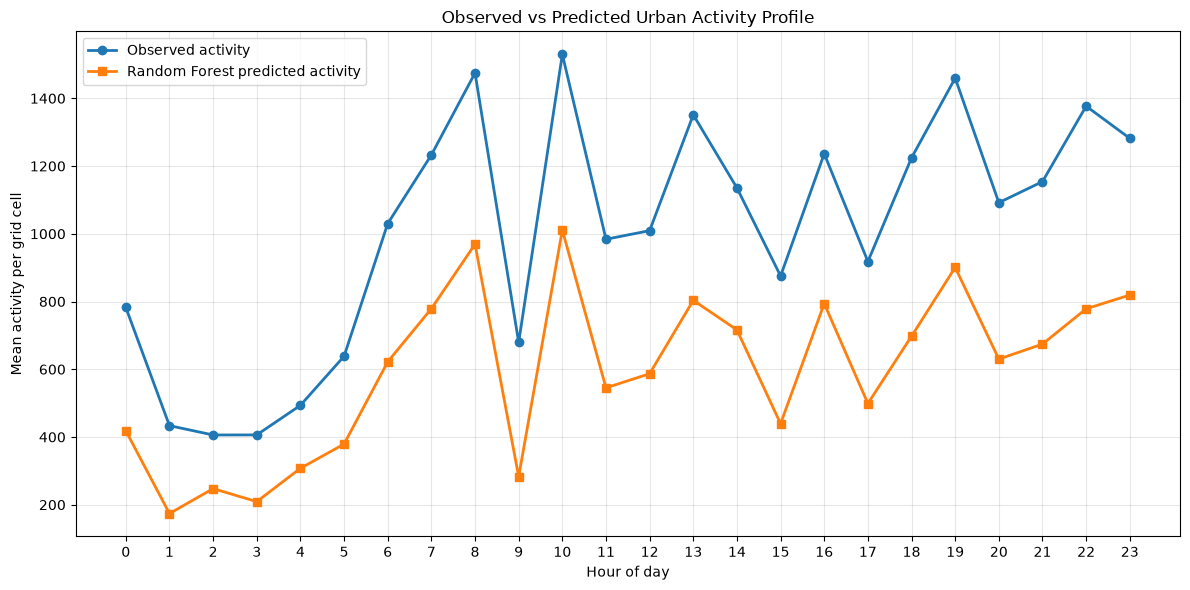


Saved: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_urban_pulse_mean_profile.csv
Saved: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_urban_pulse_observed_vs_predicted.png


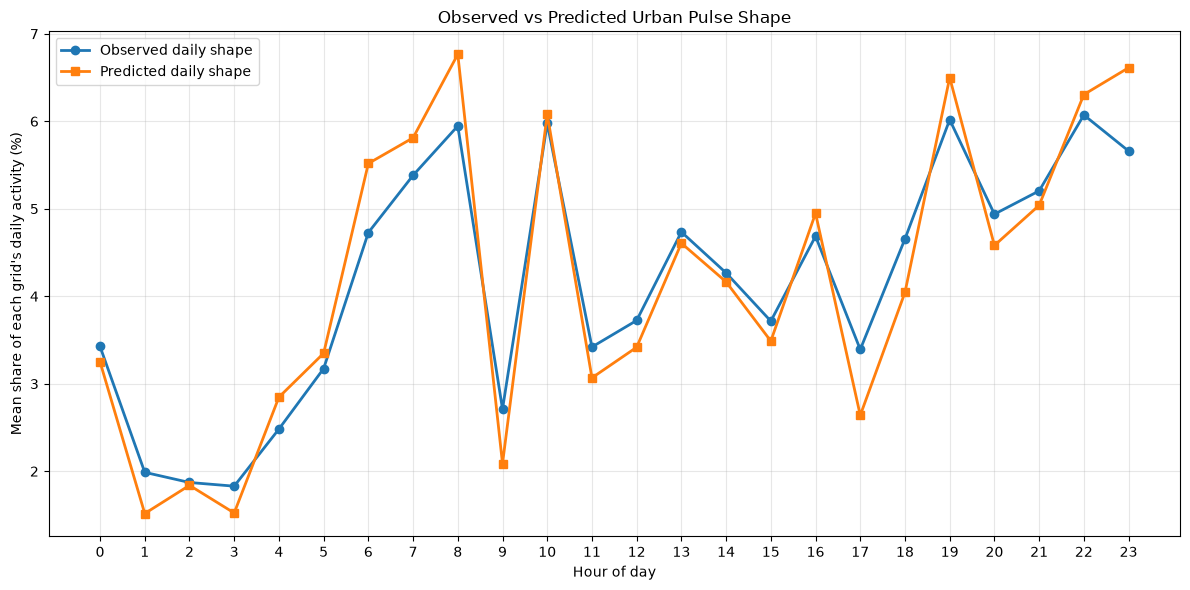


DAILY PULSE SHAPE CHECK
Correlation between mean daily shapes: 0.9713
Mean absolute hourly-share difference: 0.384 percentage points
Saved: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_urban_pulse_normalized_profile.csv
Saved: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_urban_pulse_normalized_profile.png

PEAK-HOUR COMPARISON
Observed peak by activity volume: 10
Predicted peak by activity volume: 10
Observed peak by normalized daily shape: 22
Predicted peak by normalized daily shape: 8

ANALYSIS COMPLETED.
Review both plots and the hourly metrics CSV.


In [58]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ============================================================
# 1. FILE PATHS
# ============================================================
output_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

input_file = output_dir / "spatial_cv_out_of_fold_predictions.csv"

if not input_file.exists():
    raise FileNotFoundError(
        f"Could not find the prediction file:\n{input_file}"
    )

df = pd.read_csv(input_file)

print("=" * 65)
print("INPUT DATA CHECK")
print("=" * 65)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nAvailable columns:")
print(df.columns.tolist())

# ============================================================
# 2. IDENTIFY OBSERVED AND RANDOM FOREST PREDICTION COLUMNS
# ============================================================
# Expected observed columns:
# activity_0 ... activity_9, activity10 ... activity23
#
# Expected RF prediction columns:
# random_forest_pred_hour_00 ... random_forest_pred_hour_23

def find_actual_column(hour):
    candidates = [
        f"activity_{hour}",
        f"activity{hour}",
        f"activity_{hour:02d}",
    ]
    for col in candidates:
        if col in df.columns:
            return col
    return None

def find_prediction_column(hour):
    candidates = [
        f"random_forest_pred_hour_{hour:02d}",
        f"random_forest_pred_hour_{hour}",
        f"rf_pred_hour_{hour:02d}",
        f"rf_pred_hour_{hour}",
    ]
    for col in candidates:
        if col in df.columns:
            return col

    # Fallback: look for a unique RF prediction column for this hour
    matches = [
        col for col in df.columns
        if "random_forest" in col.lower()
        and "pred" in col.lower()
        and f"{hour:02d}" in col
    ]
    if len(matches) == 1:
        return matches[0]

    return None

hour_mapping = []

for hour in range(24):
    actual_col = find_actual_column(hour)
    pred_col = find_prediction_column(hour)

    hour_mapping.append({
        "hour": hour,
        "actual_column": actual_col,
        "prediction_column": pred_col
    })

mapping_df = pd.DataFrame(hour_mapping)

print("\n" + "=" * 65)
print("HOURLY COLUMN CHECK")
print("=" * 65)
print(mapping_df.to_string(index=False))

missing_actual = mapping_df.loc[
    mapping_df["actual_column"].isna(), "hour"
].tolist()

missing_prediction = mapping_df.loc[
    mapping_df["prediction_column"].isna(), "hour"
].tolist()

if missing_actual or missing_prediction:
    print("\nSTOP: Some hourly columns were not identified.")
    print("Missing observed hours:", missing_actual)
    print("Missing RF prediction hours:", missing_prediction)
    print(
        "\nCheck the column names printed above. "
        "Do not continue until all 24 hours are identified."
    )
    raise ValueError("Hourly column names need to be matched.")

# ============================================================
# 3. PREPARE OBSERVED AND PREDICTED HOURLY VALUES
# ============================================================
actual_cols = mapping_df["actual_column"].tolist()
pred_cols = mapping_df["prediction_column"].tolist()

actual = df[actual_cols].apply(pd.to_numeric, errors="coerce")
predicted = df[pred_cols].apply(pd.to_numeric, errors="coerce")

# Keep rows with complete observed and predicted 24-hour profiles
valid = (
    actual.notna().all(axis=1)
    & predicted.notna().all(axis=1)
)

actual = actual.loc[valid].clip(lower=0)
predicted = predicted.loc[valid].clip(lower=0)

print("\n" + "=" * 65)
print("VALIDATION SAMPLE")
print("=" * 65)
print("Valid complete hourly profiles:", len(actual))
print("Excluded incomplete profiles:", len(df) - len(actual))

if len(actual) < 2:
    raise ValueError("Not enough valid rows for hourly evaluation.")

# ============================================================
# 4. CALCULATE METRICS FOR EACH HOUR
# ============================================================
metric_rows = []

for hour in range(24):
    y_true = actual.iloc[:, hour].to_numpy()
    y_pred = predicted.iloc[:, hour].to_numpy()

    metric_rows.append({
        "hour": hour,
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "mean_observed": y_true.mean(),
        "mean_predicted": y_pred.mean(),
        "bias_predicted_minus_observed": (
            y_pred.mean() - y_true.mean()
        )
    })

hourly_metrics = pd.DataFrame(metric_rows)

metrics_path = output_dir / "rf_urban_pulse_hourly_metrics.csv"
hourly_metrics.to_csv(metrics_path, index=False)

print("\n" + "=" * 65)
print("HOURLY MODEL PERFORMANCE")
print("=" * 65)
print(hourly_metrics.round(3).to_string(index=False))
print("\nSaved:", metrics_path)

# ============================================================
# 5. COMPARE MEAN OBSERVED AND PREDICTED DAILY PROFILES
# ============================================================
observed_mean = actual.mean(axis=0).to_numpy()
predicted_mean = predicted.mean(axis=0).to_numpy()

profile_df = pd.DataFrame({
    "hour": range(24),
    "observed_mean_activity": observed_mean,
    "predicted_mean_activity": predicted_mean
})

profile_path = output_dir / "rf_urban_pulse_mean_profile.csv"
profile_df.to_csv(profile_path, index=False)

plt.figure(figsize=(12, 6))
plt.plot(
    range(24), observed_mean,
    marker="o", linewidth=2,
    label="Observed activity"
)
plt.plot(
    range(24), predicted_mean,
    marker="s", linewidth=2,
    label="Random Forest predicted activity"
)
plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Mean activity per grid cell")
plt.title("Observed vs Predicted Urban Activity Profile")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plot_path = output_dir / "rf_urban_pulse_observed_vs_predicted.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved:", profile_path)
print("Saved:", plot_path)

# ============================================================
# 6. COMPARE DAILY SHAPE, NORMALIZED FOR EACH GRID CELL
# ============================================================
# This removes differences in total activity between grid cells
# so we can focus on when activity occurs during the day.

actual_sum = actual.sum(axis=1).replace(0, np.nan)
pred_sum = predicted.sum(axis=1).replace(0, np.nan)

actual_normalized = actual.div(actual_sum, axis=0)
predicted_normalized = predicted.div(pred_sum, axis=0)

observed_shape = actual_normalized.mean(axis=0).to_numpy()
predicted_shape = predicted_normalized.mean(axis=0).to_numpy()

shape_df = pd.DataFrame({
    "hour": range(24),
    "observed_mean_hourly_share": observed_shape,
    "predicted_mean_hourly_share": predicted_shape
})

shape_path = output_dir / "rf_urban_pulse_normalized_profile.csv"
shape_df.to_csv(shape_path, index=False)

plt.figure(figsize=(12, 6))
plt.plot(
    range(24), observed_shape * 100,
    marker="o", linewidth=2,
    label="Observed daily shape"
)
plt.plot(
    range(24), predicted_shape * 100,
    marker="s", linewidth=2,
    label="Predicted daily shape"
)
plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Mean share of each grid's daily activity (%)")
plt.title("Observed vs Predicted Urban Pulse Shape")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

shape_plot_path = (
    output_dir / "rf_urban_pulse_normalized_profile.png"
)
plt.savefig(shape_plot_path, dpi=300, bbox_inches="tight")
plt.show()

# Similarity of the two 24-hour average shapes
shape_correlation = np.corrcoef(
    observed_shape, predicted_shape
)[0, 1]

shape_mae_percentage_points = np.mean(
    np.abs(observed_shape - predicted_shape)
) * 100

print("\n" + "=" * 65)
print("DAILY PULSE SHAPE CHECK")
print("=" * 65)
print(f"Correlation between mean daily shapes: {shape_correlation:.4f}")
print(
    "Mean absolute hourly-share difference: "
    f"{shape_mae_percentage_points:.3f} percentage points"
)
print("Saved:", shape_path)
print("Saved:", shape_plot_path)

# ============================================================
# 7. IDENTIFY PEAK HOURS
# ============================================================
observed_peak_hour = int(np.argmax(observed_mean))
predicted_peak_hour = int(np.argmax(predicted_mean))

observed_shape_peak = int(np.argmax(observed_shape))
predicted_shape_peak = int(np.argmax(predicted_shape))

print("\n" + "=" * 65)
print("PEAK-HOUR COMPARISON")
print("=" * 65)
print("Observed peak by activity volume:", observed_peak_hour)
print("Predicted peak by activity volume:", predicted_peak_hour)
print("Observed peak by normalized daily shape:", observed_shape_peak)
print("Predicted peak by normalized daily shape:", predicted_shape_peak)

print("\nANALYSIS COMPLETED.")
print("Review both plots and the hourly metrics CSV.")


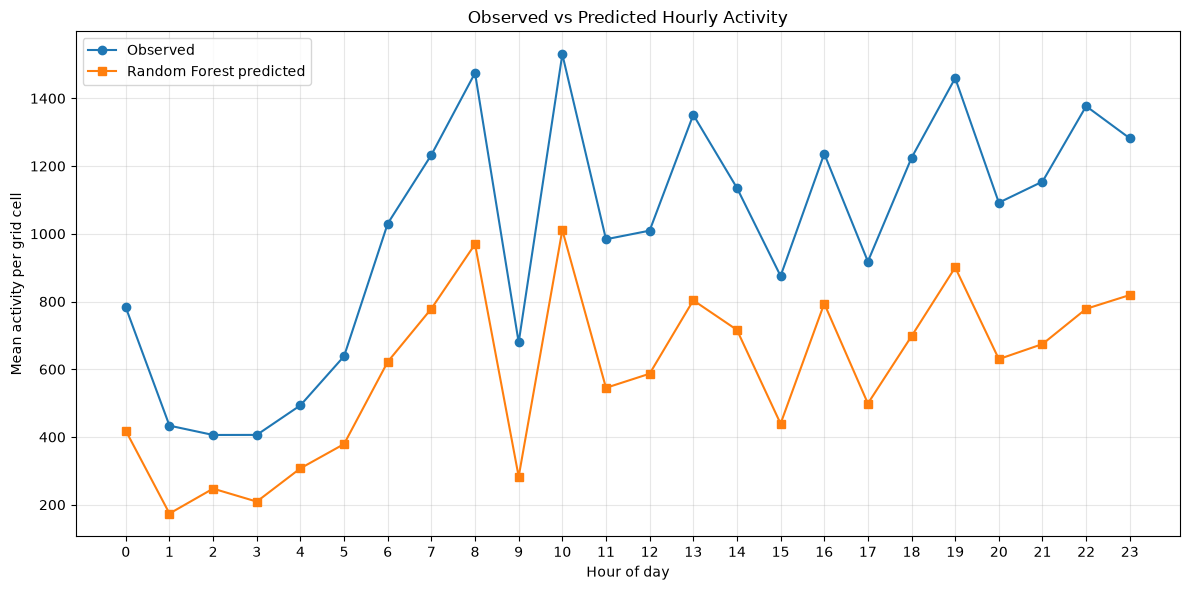

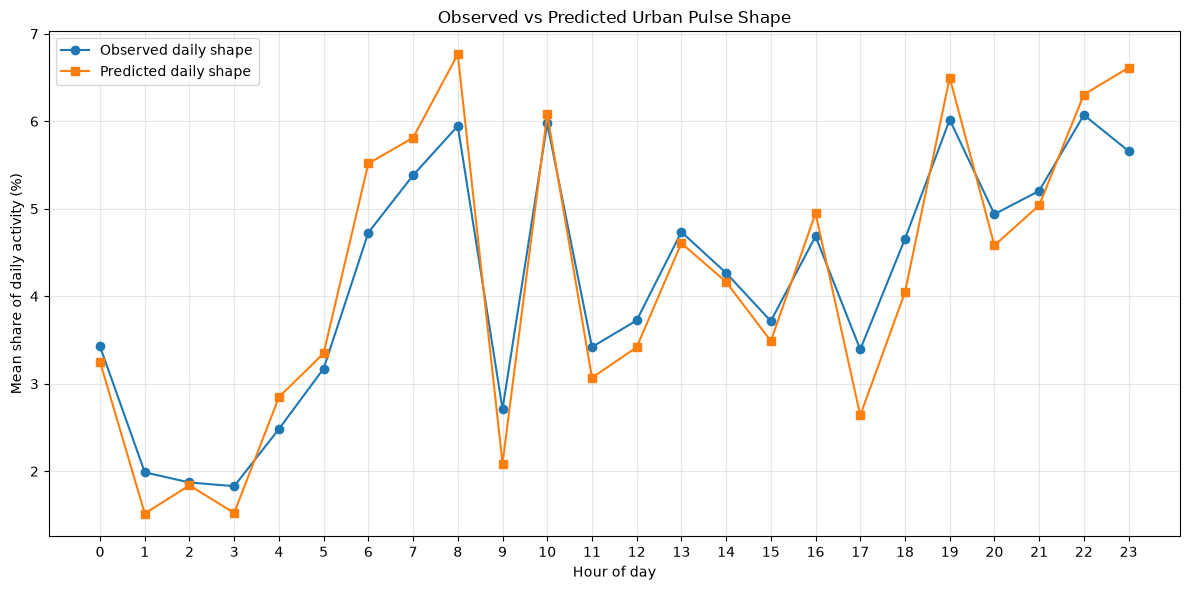

URBAN PULSE SHAPE RESULTS
Grid cells used: 7764
Grid cells used for normalized profiles: 7764
Daily-shape correlation: 0.9713
Mean hourly-share difference: 0.384 percentage points
Observed peak hour: 22
Predicted peak hour: 8

Mean hourly activity volume:
Observed peak hour: 10
Predicted peak hour: 10

Files saved in: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final


In [59]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD EXISTING OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------
out_dir = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

file_path = out_dir / "spatial_cv_out_of_fold_predictions.csv"
df = pd.read_csv(file_path)

actual_cols = [
    f"activity_{h}" if h <= 9 else f"activity{h}"
    for h in range(24)
]

pred_cols = [
    f"random_forest_pred_hour_{h:02d}"
    for h in range(24)
]

actual = df[actual_cols].apply(pd.to_numeric, errors="coerce")
pred = df[pred_cols].apply(pd.to_numeric, errors="coerce")

valid = actual.notna().all(axis=1) & pred.notna().all(axis=1)
actual = actual.loc[valid].clip(lower=0)
pred = pred.loc[valid].clip(lower=0)

hours = np.arange(24)

# ------------------------------------------------------------
# 2. GRAPH A: ACTUAL ACTIVITY VOLUME
# ------------------------------------------------------------
observed_mean = actual.mean(axis=0).to_numpy()
predicted_mean = pred.mean(axis=0).to_numpy()

volume_results = pd.DataFrame({
    "hour": hours,
    "observed_mean": observed_mean,
    "predicted_mean": predicted_mean,
    "underprediction": observed_mean - predicted_mean
})

volume_results.to_csv(
    out_dir / "rf_urban_pulse_mean_profile.csv",
    index=False
)

plt.figure(figsize=(12, 6))
plt.plot(hours, observed_mean, marker="o", label="Observed")
plt.plot(hours, predicted_mean, marker="s", label="Random Forest predicted")
plt.xticks(hours)
plt.xlabel("Hour of day")
plt.ylabel("Mean activity per grid cell")
plt.title("Observed vs Predicted Hourly Activity")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    out_dir / "rf_urban_pulse_observed_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 3. GRAPH B: NORMALIZED DAILY PULSE SHAPE
# ------------------------------------------------------------
# Normalize each grid's hourly values by its total daily activity.
# This focuses on the distribution of activity over the day,
# rather than the absolute activity volume.

actual_total = actual.sum(axis=1)
pred_total = pred.sum(axis=1)

# Exclude rows whose full daily sum is zero, since their shares
# cannot be calculated meaningfully.
nonzero = (actual_total > 0) & (pred_total > 0)

actual_norm = actual.loc[nonzero].div(
    actual_total.loc[nonzero], axis=0
)
pred_norm = pred.loc[nonzero].div(
    pred_total.loc[nonzero], axis=0
)

observed_shape = actual_norm.mean(axis=0).to_numpy()
predicted_shape = pred_norm.mean(axis=0).to_numpy()

shape_results = pd.DataFrame({
    "hour": hours,
    "observed_hourly_share": observed_shape,
    "predicted_hourly_share": predicted_shape,
    "absolute_difference_percentage_points":
        np.abs(observed_shape - predicted_shape) * 100
})

shape_results.to_csv(
    out_dir / "rf_urban_pulse_normalized_profile.csv",
    index=False
)

plt.figure(figsize=(12, 6))
plt.plot(
    hours, observed_shape * 100,
    marker="o", label="Observed daily shape"
)
plt.plot(
    hours, predicted_shape * 100,
    marker="s", label="Predicted daily shape"
)
plt.xticks(hours)
plt.xlabel("Hour of day")
plt.ylabel("Mean share of daily activity (%)")
plt.title("Observed vs Predicted Urban Pulse Shape")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    out_dir / "rf_urban_pulse_normalized_profile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 4. PRINT SUMMARY
# ------------------------------------------------------------
shape_correlation = np.corrcoef(
    observed_shape, predicted_shape
)[0, 1]

shape_mae_pp = np.mean(
    np.abs(observed_shape - predicted_shape)
) * 100

print("=" * 60)
print("URBAN PULSE SHAPE RESULTS")
print("=" * 60)
print("Grid cells used:", len(actual))
print("Grid cells used for normalized profiles:", len(actual_norm))
print(f"Daily-shape correlation: {shape_correlation:.4f}")
print(f"Mean hourly-share difference: {shape_mae_pp:.3f} percentage points")
print("Observed peak hour:", int(np.argmax(observed_shape)))
print("Predicted peak hour:", int(np.argmax(predicted_shape)))
print("\nMean hourly activity volume:")
print("Observed peak hour:", int(np.argmax(observed_mean)))
print("Predicted peak hour:", int(np.argmax(predicted_mean)))
print("\nFiles saved in:", out_dir)


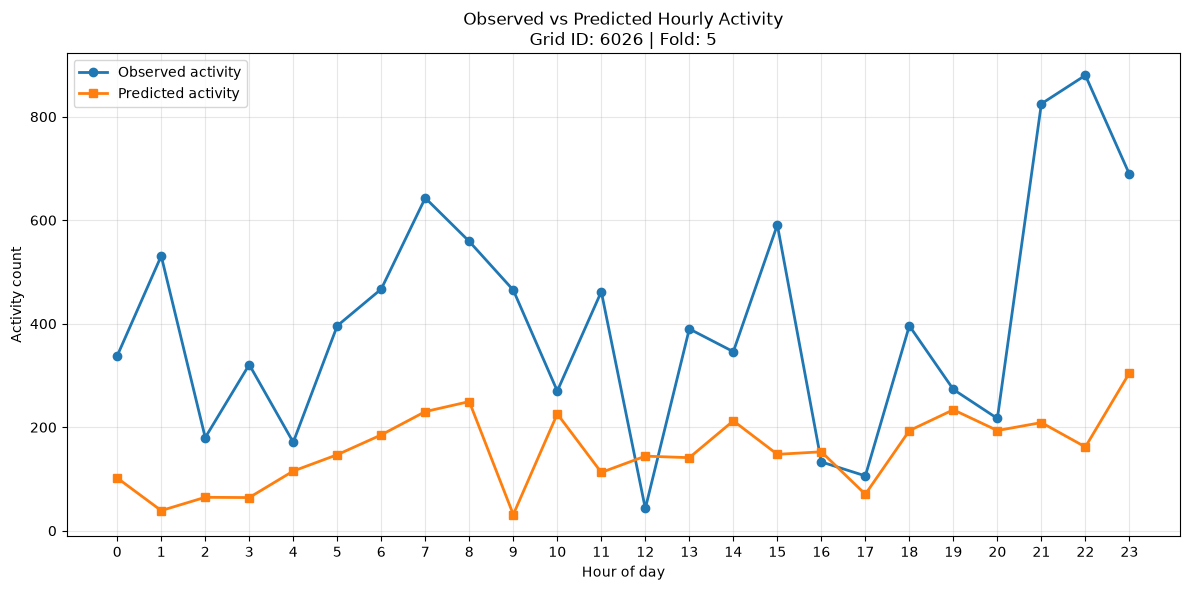

SELECTED GRID PROFILE
Grid ID: 6026
Spatial fold: 5
Observed daily total: 9692.0
Predicted daily total: 3732.04
Observed peak hour: 22
Predicted peak hour: 23
Hourly MAE: 258.39
Saved graph: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_selected_grid_activity_profile.png


In [60]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# FILE PATH
# --------------------------------------------------
folder = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

file_path = folder / "spatial_cv_out_of_fold_predictions.csv"

df = pd.read_csv(file_path)

# --------------------------------------------------
# IDENTIFY THE 24 ACTUAL AND PREDICTED HOURS
# --------------------------------------------------
actual_cols = [
    f"activity_{h}" if h <= 9 else f"activity{h}"
    for h in range(24)
]

pred_cols = [
    f"random_forest_pred_hour_{h:02d}"
    for h in range(24)
]

required_cols = ["grid_id", "fold"] + actual_cols + pred_cols
missing = [c for c in required_cols if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Keep grid cells with complete observed and predicted profiles
valid = df.dropna(subset=actual_cols + pred_cols).copy()

# Select a grid near the median total activity.
# This avoids choosing an unusually quiet or busy grid.
valid["observed_daily_total"] = valid[actual_cols].sum(axis=1)

median_total = valid["observed_daily_total"].median()
selected_idx = (
    valid["observed_daily_total"] - median_total
).abs().idxmin()

grid = valid.loc[selected_idx]

observed = grid[actual_cols].to_numpy(dtype=float)
predicted = grid[pred_cols].to_numpy(dtype=float)

hours = np.arange(24)

# --------------------------------------------------
# PLOT THE SELECTED GRID
# --------------------------------------------------
plt.figure(figsize=(12, 6))

plt.plot(
    hours, observed,
    marker="o", linewidth=2,
    label="Observed activity"
)

plt.plot(
    hours, predicted,
    marker="s", linewidth=2,
    label="Predicted activity"
)

plt.xticks(hours)
plt.xlabel("Hour of day")
plt.ylabel("Activity count")
plt.title(
    f"Observed vs Predicted Hourly Activity\n"
    f"Grid ID: {grid['grid_id']} | Fold: {grid['fold']}"
)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

output_path = folder / "rf_selected_grid_activity_profile.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# REPORT RESULTS
# --------------------------------------------------
print("=" * 55)
print("SELECTED GRID PROFILE")
print("=" * 55)
print("Grid ID:", grid["grid_id"])
print("Spatial fold:", grid["fold"])
print("Observed daily total:", round(observed.sum(), 2))
print("Predicted daily total:", round(predicted.sum(), 2))
print("Observed peak hour:", int(np.argmax(observed)))
print("Predicted peak hour:", int(np.argmax(predicted)))
print("Hourly MAE:", round(np.mean(np.abs(observed - predicted)), 2))
print("Saved graph:", output_path)


Prediction rows: 7764
Grid rows: 15493
Grid columns: ['id', 'left', 'top', 'right', 'bottom', 'row_index', 'col_index', 'grid_id', 'Bldg_Cov', 'Floor_Inte', 'POI_Densit', 'Transit_Ac', 'IntDen_km2', 'x_bin', 'y_bin', 'total_acti', 'activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23', 'pulse_00', 'pulse_01', 'pulse_02', 'pulse_03', 'pulse_04', 'pulse_05', 'pulse_06', 'pulse_07', 'pulse_08', 'pulse_09', 'pulse_10', 'pulse_11', 'pulse_12', 'pulse_13', 'pulse_14', 'pulse_15', 'pulse_16', 'pulse_17', 'pulse_18', 'pulse_19', 'pulse_20', 'pulse_21', 'pulse_22', 'pulse_23', 'land_use_e', 'LConn_wt', 'MAD500_wt', 'BtA500_wt', 'geometry']
Grid ID in predictions: grid_id
Grid ID in spatial layer: grid_id
Observed activi

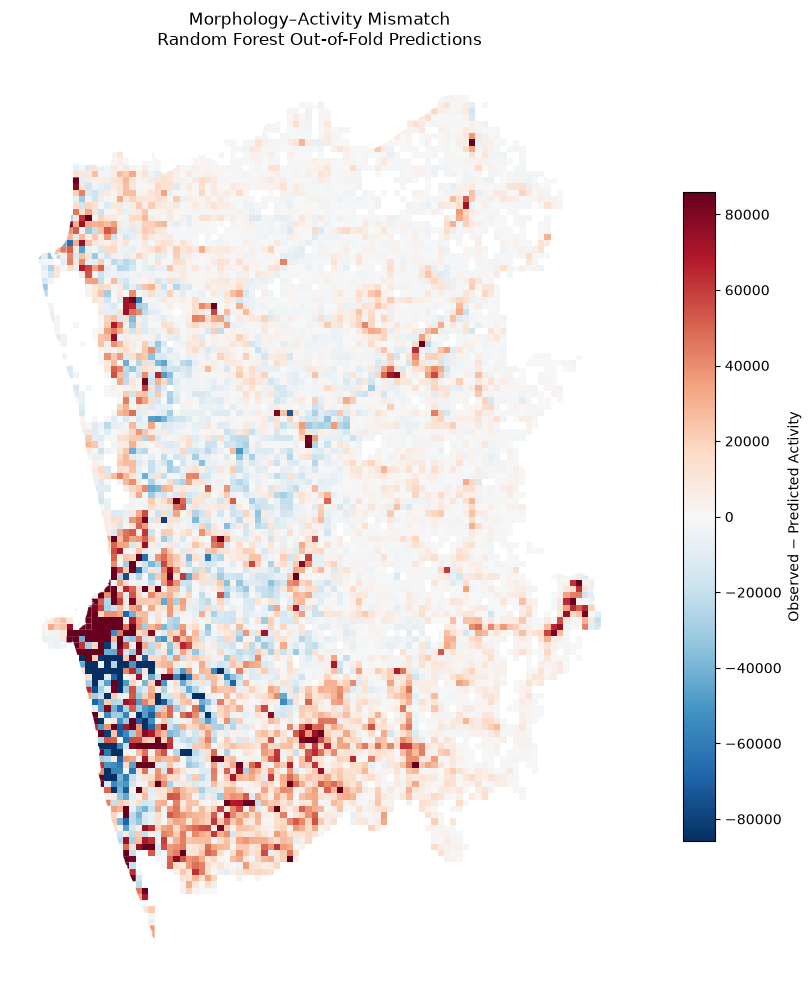


PROCESS COMPLETED
CSV: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_morphology_activity_mismatch.csv
Spatial layer: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_morphology_activity_mismatch.gpkg
Map: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\rf_morphology_activity_mismatch_map.png


In [61]:

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. FILE PATHS
# ============================================================
folder = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

prediction_file = folder / "spatial_cv_out_of_fold_predictions.csv"

grid_file = Path(
    r"C:\Users\sanojan\Downloads\Roaddd"
) / "with_Grid_Entropy_CoreNetwork.shp"

output_csv = folder / "rf_morphology_activity_mismatch.csv"
output_gpkg = folder / "rf_morphology_activity_mismatch.gpkg"
output_png = folder / "rf_morphology_activity_mismatch_map.png"

# ============================================================
# 2. LOAD DATA
# ============================================================
pred = pd.read_csv(prediction_file)
grid = gpd.read_file(grid_file)

print("Prediction rows:", len(pred))
print("Grid rows:", len(grid))
print("Grid columns:", grid.columns.tolist())

# Identify grid ID columns without assuming capitalization
def find_column(df, candidates):
    lookup = {str(c).lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

pred_id = find_column(pred, ["grid_id", "gid", "gridid"])
grid_id = find_column(grid, ["grid_id", "gid", "gridid"])
actual_col = find_column(pred, ["total_acti", "actual_total"])

if pred_id is None or grid_id is None or actual_col is None:
    raise ValueError(
        "Could not identify grid ID or observed total activity.\n"
        f"Prediction columns: {pred.columns.tolist()}\n"
        f"Grid columns: {grid.columns.tolist()}"
    )

# Find the Random Forest total-activity prediction column
pred_candidates = [
    c for c in pred.columns
    if "random_forest" in c.lower()
    and "pred" in c.lower()
    and ("total" in c.lower() or "acti" in c.lower())
]

if len(pred_candidates) != 1:
    print("Possible Random Forest prediction columns:", pred_candidates)
    raise ValueError(
        "Expected exactly one Random Forest total-activity prediction "
        "column. Check the printed column names."
    )

prediction_col = pred_candidates[0]

print("Grid ID in predictions:", pred_id)
print("Grid ID in spatial layer:", grid_id)
print("Observed activity column:", actual_col)
print("Prediction column:", prediction_col)

# ============================================================
# 3. PREPARE OUT-OF-FOLD RESULTS
# ============================================================
pred = pred[[pred_id, actual_col, prediction_col]].copy()

pred = pred.rename(columns={
    pred_id: "grid_id",
    actual_col: "observed_activity",
    prediction_col: "predicted_activity"
})

grid = grid.rename(columns={grid_id: "grid_id"})

# Align ID types before joining
pred["grid_id"] = pred["grid_id"].astype(str).str.strip()
grid["grid_id"] = grid["grid_id"].astype(str).str.strip()

pred["observed_activity"] = pd.to_numeric(
    pred["observed_activity"], errors="coerce"
)
pred["predicted_activity"] = pd.to_numeric(
    pred["predicted_activity"], errors="coerce"
)

pred = pred.dropna(
    subset=["grid_id", "observed_activity", "predicted_activity"]
)

# Prevent accidental duplicate joins
if pred["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid IDs found in prediction results.")

if grid["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid IDs found in the spatial layer.")

# Only grid cells with valid out-of-fold predictions are retained
result = grid.merge(pred, on="grid_id", how="inner")

if result.empty:
    raise ValueError(
        "No grid IDs matched. Check whether both datasets use the same IDs."
    )

# ============================================================
# 4. CALCULATE MORPHOLOGY-ACTIVITY MISMATCH
# ============================================================
result["activity_mismatch"] = (
    result["observed_activity"] - result["predicted_activity"]
)

result["absolute_error"] = result["activity_mismatch"].abs()

result["mismatch_type"] = np.select(
    [
        result["activity_mismatch"] > 0,
        result["activity_mismatch"] < 0
    ],
    [
        "Observed activity higher than predicted",
        "Predicted activity higher than observed"
    ],
    default="Observed and predicted equal"
)

# ============================================================
# 5. SUMMARY
# ============================================================
print("\n" + "=" * 60)
print("MORPHOLOGY-ACTIVITY MISMATCH SUMMARY")
print("=" * 60)

print("Matched grid cells:", len(result))
print("Mean observed activity:",
      round(result["observed_activity"].mean(), 2))
print("Mean predicted activity:",
      round(result["predicted_activity"].mean(), 2))
print("Mean signed mismatch:",
      round(result["activity_mismatch"].mean(), 2))
print("Mean absolute error:",
      round(result["absolute_error"].mean(), 2))

print("\nMismatch categories:")
print(result["mismatch_type"].value_counts())

print("\nLargest positive mismatches:")
print(
    result.nlargest(10, "activity_mismatch")[
        ["grid_id", "observed_activity", "predicted_activity",
         "activity_mismatch"]
    ].to_string(index=False)
)

print("\nLargest negative mismatches:")
print(
    result.nsmallest(10, "activity_mismatch")[
        ["grid_id", "observed_activity", "predicted_activity",
         "activity_mismatch"]
    ].to_string(index=False)
)

# ============================================================
# 6. SAVE CSV AND SPATIAL OUTPUT
# ============================================================
result.drop(columns="geometry").to_csv(output_csv, index=False)

# Remove an old output first if rerunning the cell
if output_gpkg.exists():
    output_gpkg.unlink()

result.to_file(
    output_gpkg,
    layer="activity_mismatch",
    driver="GPKG"
)

# ============================================================
# 7. CREATE MISMATCH MAP
# ============================================================
plot_data = result[
    result.geometry.notna() & ~result.geometry.is_empty
].copy()

if plot_data.empty:
    raise ValueError("No valid grid geometries available for mapping.")

# Symmetric colour scale makes positive and negative errors comparable
limit = np.nanpercentile(
    np.abs(plot_data["activity_mismatch"]), 98
)

if not np.isfinite(limit) or limit <= 0:
    limit = max(
        float(plot_data["activity_mismatch"].abs().max()), 1.0
    )

fig, ax = plt.subplots(figsize=(11, 10))

plot_data.plot(
    column="activity_mismatch",
    ax=ax,
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    legend=True,
    linewidth=0,
    legend_kwds={
        "label": "Observed − Predicted Activity",
        "shrink": 0.7
    }
)

ax.set_title(
    "Morphology–Activity Mismatch\n"
    "Random Forest Out-of-Fold Predictions"
)
ax.set_axis_off()

plt.tight_layout()
plt.savefig(output_png, dpi=300, bbox_inches="tight")
plt.show()

print("\n" + "=" * 60)
print("PROCESS COMPLETED")
print("=" * 60)
print("CSV:", output_csv)
print("Spatial layer:", output_gpkg)
print("Map:", output_png)


In [62]:

import json
import joblib
import numpy as np
import pandas as pd
import geopandas as gpd

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor

# ============================================================
# 1. PATHS
# ============================================================
data_path = Path(
    r"C:\Users\sanojan\Downloads\Roaddd"
    r"\with_Grid_Entropy_CoreNetwork.shp"
)

output_folder = Path(
    r"C:\Users\sanojan\Downloads\Roaddd"
    r"\Colombo_Gampaha_Final"
)
output_folder.mkdir(parents=True, exist_ok=True)

model_path = output_folder / "final_rf_activity_model.joblib"
metadata_path = output_folder / "final_rf_model_metadata.json"

# ============================================================
# 2. FINAL PREDICTORS — KEEP THIS ORDER
# ============================================================
features = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

target = "total_acti"

# ============================================================
# 3. LOAD DATA
# ============================================================
gdf = gpd.read_file(data_path)

required = features + [target]
missing = [c for c in required if c not in gdf.columns]

if missing:
    raise ValueError(f"Required columns missing: {missing}")

df = pd.DataFrame(gdf[required]).copy()

# Convert inputs to numeric and replace infinite values
for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

# Remove rows without valid predictors or target
df = df.dropna(subset=required).copy()

# Activity counts cannot be negative
if (df[target] < 0).any():
    raise ValueError(
        "Negative activity counts found. Inspect the target data first."
    )

X = df[features]
y = df[target].astype(float)

print("=" * 60)
print("FINAL MODEL TRAINING DATA")
print("=" * 60)
print("Valid training grids:", len(df))
print("Number of predictors:", len(features))
print("Target:", target)
print("Mean observed activity:", round(y.mean(), 2))

if len(df) != 7764:
    print(
        "\nWARNING: The valid row count differs from the 7,764 "
        "grid cells used in our previous evaluation. Check the "
        "source data and target filtering before proceeding."
    )

# ============================================================
# 4. TRAIN FINAL RANDOM FOREST
# ============================================================
model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

model.fit(X, np.log1p(y))

# ============================================================
# 5. SAVE MODEL AND METADATA
# ============================================================
artifact = {
    "model": model,
    "features": features,
    "target": target,
    "target_transform": "log1p",
    "prediction_inverse_transform": "expm1",
    "prediction_clip_minimum": 0,
    "model_type": "RandomForestRegressor",
    "training_rows": int(len(df))
}

joblib.dump(artifact, model_path)

metadata = {
    "model_type": "RandomForestRegressor",
    "training_rows": int(len(df)),
    "features": features,
    "target": target,
    "target_transform": "log1p",
    "inverse_transform": "expm1",
    "parameters": {
        "n_estimators": 300,
        "min_samples_leaf": 2,
        "max_features": 1.0,
        "random_state": 42
    }
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

# ============================================================
# 6. VERIFY SAVED MODEL
# ============================================================
saved_artifact = joblib.load(model_path)
saved_model = saved_artifact["model"]

test_prediction = np.expm1(
    saved_model.predict(X.iloc[:5])
)
test_prediction = np.clip(test_prediction, 0, None)

print("\n" + "=" * 60)
print("FINAL MODEL SAVED AND VERIFIED")
print("=" * 60)
print("Model:", model_path)
print("Metadata:", metadata_path)
print("Test predictions for first 5 rows:")
print(np.round(test_prediction, 2))
print("\nNote: These five predictions verify that the saved model runs.")
print("They are not independent evaluation results.")


FINAL MODEL TRAINING DATA
Valid training grids: 11318
Number of predictors: 8
Target: total_acti
Mean observed activity: 20227.14


FINAL MODEL SAVED AND VERIFIED
Model: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\final_rf_activity_model.joblib
Metadata: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\final_rf_model_metadata.json
Test predictions for first 5 rows:
[22994.26  4976.62   754.14  1461.92  6978.69]

Note: These five predictions verify that the saved model runs.
They are not independent evaluation results.


District


In [63]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

base = Path(r"C:\Users\sanojan\Downloads\Roaddd")
grid_path = base / "with_Grid_Entropy_CoreNetwork.shp"
oof_path = (
    base / "Colombo_Gampaha_Final"
    / "spatial_cv_out_of_fold_predictions.csv"
)

gdf = gpd.read_file(grid_path)
oof = pd.read_csv(oof_path)

# Identify grid ID columns
grid_id_col = "grid_id"
oof_id_col = "grid_id"

print("=" * 60)
print("DISTRICT CHECK")
print("=" * 60)

district_candidates = [
    c for c in gdf.columns
    if "district" in c.lower() or "adm2" in c.lower()
]
print("District columns:", district_candidates)

for col in district_candidates:
    print(f"\nCounts for {col}:")
    print(gdf[col].value_counts(dropna=False).to_string())

print("\n" + "=" * 60)
print("GRID ID OVERLAP CHECK")
print("=" * 60)

grid_ids = set(gdf[grid_id_col].dropna().astype(str))
oof_ids = set(oof[oof_id_col].dropna().astype(str))

print("Unique grid IDs in spatial layer:", len(grid_ids))
print("Unique grid IDs in evaluated predictions:", len(oof_ids))
print("IDs present in both:", len(grid_ids & oof_ids))
print("IDs only in spatial layer:", len(grid_ids - oof_ids))
print("IDs only in evaluated predictions:", len(oof_ids - grid_ids))

# Check whether the evaluation dataset contains district information
if "district_name" in oof.columns:
    print("\nDistrict counts in evaluated predictions:")
    print(oof["district_name"].value_counts(dropna=False).to_string())

print("\n" + "=" * 60)
print("TOTAL ACTIVITY TARGET CHECK")
print("=" * 60)

if "total_acti" in gdf.columns:
    print("Non-missing targets:", gdf["total_acti"].notna().sum())
    print("Zero targets:", (gdf["total_acti"] == 0).sum())
    print("Negative targets:", (gdf["total_acti"] < 0).sum())

print("\nDiagnostic completed. No files were changed.")


DISTRICT CHECK
District columns: []

GRID ID OVERLAP CHECK
Unique grid IDs in spatial layer: 15493
Unique grid IDs in evaluated predictions: 7764
IDs present in both: 7764
IDs only in spatial layer: 7729
IDs only in evaluated predictions: 0

District counts in evaluated predictions:
district_name
Gampaha    5178
Colombo    2586

TOTAL ACTIVITY TARGET CHECK
Non-missing targets: 11318
Zero targets: 0
Negative targets: 0

Diagnostic completed. No files were changed.


In [64]:

import json
import joblib
import numpy as np
import pandas as pd
import geopandas as gpd

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor

# ============================================================
# 1. PATHS
# ============================================================
base = Path(r"C:\Users\sanojan\Downloads\Roaddd")
out = base / "Colombo_Gampaha_Final"

grid_path = base / "with_Grid_Entropy_CoreNetwork.shp"
oof_path = out / "spatial_cv_out_of_fold_predictions.csv"

# ============================================================
# 2. FINAL EIGHT PREDICTORS
# ============================================================
features = [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
]

hour_cols = [f"activity_{h}" for h in range(10)] + [
    f"activity{h}" for h in range(10, 24)
]
target = "total_acti"

# ============================================================
# 3. LOAD FILES AND SELECT EVALUATED GRID IDS
# ============================================================
gdf = gpd.read_file(grid_path)
oof = pd.read_csv(oof_path)

if "grid_id" not in gdf.columns or "grid_id" not in oof.columns:
    raise ValueError("grid_id is missing from one of the files.")

# Normalize ID types for a reliable join
gdf["grid_id"] = gdf["grid_id"].astype(str)
oof["grid_id"] = oof["grid_id"].astype(str)

# The evaluation file defines the exact sample used in evaluation
evaluation_ids = oof["grid_id"].dropna().unique()
sample = gdf[gdf["grid_id"].isin(evaluation_ids)].copy()

# Verify one row per grid
sample = sample.drop_duplicates(subset="grid_id")

required = features + [target] + hour_cols
missing = [c for c in required if c not in sample.columns]

if missing:
    raise ValueError(
        "Required columns are missing from the spatial layer:\n"
        + "\n".join(missing)
    )

# Convert all model columns to numeric
for col in required:
    sample[col] = pd.to_numeric(sample[col], errors="coerce")

sample = sample.replace([np.inf, -np.inf], np.nan)

# Total-activity model sample
total_sample = sample.dropna(subset=features + [target]).copy()
total_sample = total_sample[total_sample[target] >= 0]

# Pulse models need complete hourly profiles
pulse_sample = sample.dropna(subset=features + hour_cols).copy()
pulse_sample = pulse_sample[(pulse_sample[hour_cols] >= 0).all(axis=1)]

print("=" * 60)
print("FINAL SAMPLE CHECK")
print("=" * 60)
print("Unique IDs in evaluation file:", len(evaluation_ids))
print("Matched spatial grid cells:", len(sample))
print("Total-activity model rows:", len(total_sample))
print("Complete hourly-profile rows:", len(pulse_sample))

if len(sample) != len(evaluation_ids):
    raise ValueError(
        "Some evaluated grid IDs did not match the spatial layer. "
        "Check grid_id formatting before training."
    )

if len(total_sample) != 7764:
    print(
        "\nWARNING: Total-activity training rows are not 7,764. "
        "Check missing predictor/target values and target consistency."
    )

if len(pulse_sample) != 7764:
    print(
        "\nWARNING: Hourly-profile training rows are not 7,764. "
        "Check missing hourly values."
    )

# ============================================================
# 4. TRAIN FINAL TOTAL-ACTIVITY MODEL
# ============================================================
X_total = total_sample[features]
y_total = total_sample[target].astype(float)

rf_total = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

rf_total.fit(X_total, np.log1p(y_total))

# ============================================================
# 5. TRAIN FINAL HOURLY ACTIVITY MODEL
# ============================================================
X_pulse = pulse_sample[features]
Y_hourly = pulse_sample[hour_cols].astype(float)

# One multi-output Random Forest predicts all 24 hours
rf_pulse = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

rf_pulse.fit(X_pulse, np.log1p(Y_hourly))

# ============================================================
# 6. SAVE BOTH MODELS
# ============================================================
model_bundle = {
    "total_model": rf_total,
    "pulse_model": rf_pulse,
    "features": features,
    "hour_columns": hour_cols,
    "total_target": target,
    "target_transform": "log1p",
    "inverse_transform": "expm1",
    "training_grid_ids": total_sample["grid_id"].tolist(),
    "total_training_rows": int(len(total_sample)),
    "pulse_training_rows": int(len(pulse_sample))
}

model_file = out / "final_rf_agent_models.joblib"
metadata_file = out / "final_rf_agent_models_metadata.json"

joblib.dump(model_bundle, model_file)

metadata = {
    "model_type": "RandomForestRegressor",
    "features": features,
    "hour_columns": hour_cols,
    "total_target": target,
    "target_transform": "log1p",
    "inverse_transform": "expm1",
    "training_grid_count_total": int(len(total_sample)),
    "training_grid_count_pulse": int(len(pulse_sample)),
    "parameters": {
        "n_estimators": 300,
        "min_samples_leaf": 2,
        "max_features": 1.0,
        "random_state": 42
    },
    "sample_source": str(oof_path)
}

with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

# ============================================================
# 7. VERIFY PREDICTIONS
# ============================================================
first_X = X_total.iloc[:5]
pred_total = np.clip(np.expm1(rf_total.predict(first_X)), 0, None)

first_pulse_X = X_pulse.iloc[:5]
pred_hourly = np.clip(
    np.expm1(rf_pulse.predict(first_pulse_X)),
    0,
    None
)

print("\n" + "=" * 60)
print("FINAL AGENT MODELS SAVED")
print("=" * 60)
print("Bundle:", model_file)
print("Metadata:", metadata_file)
print("\nFirst 5 total-activity predictions:")
print(np.round(pred_total, 2))
print("\nFirst grid's predicted hourly profile:")
print(np.round(pred_hourly[0], 2))
print("Sum of predicted hourly values:", round(pred_hourly[0].sum(), 2))
print("\nThese predictions verify the models run; they are not evaluation metrics.")


FINAL SAMPLE CHECK
Unique IDs in evaluation file: 7764
Matched spatial grid cells: 7764
Total-activity model rows: 7764
Complete hourly-profile rows: 7764

FINAL AGENT MODELS SAVED
Bundle: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\final_rf_agent_models.joblib
Metadata: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\final_rf_agent_models_metadata.json

First 5 total-activity predictions:
[20900.8   4933.06   880.28  1056.23  8245.78]

First grid's predicted hourly profile:
[ 500.92   16.38  303.13  294.1   340.95  425.32  796.8   513.5    74.62
   21.61  986.69  354.08  485.03   34.1    52.3   313.22   55.01  597.22
   57.06  619.47   56.61  720.57 1033.85  894.09]
Sum of predicted hourly values: 9546.62

These predictions verify the models run; they are not evaluation metrics.


URBAN ACTIVITY PREDICTION — GRID 6026
Predicted total activity: 7,865.66
Sum of predicted hourly activity: 6,734.73
Difference (hourly sum − predicted total): -1,130.93
Predicted peak hour: 23:00

Spatial characteristics:
  LConn_wt: 4.0000
  MAD500_wt: 54.7962
  BtA500_wt: 0.3333
  Floor_Inte: 0.0685
  POI_Densit: 0.0000
  Transit_Ac: 2446.1245
  IntDen_km2: 30.2222
  land_use_e: 0.3244

Predicted hourly profile:
 Hour  Predicted_Activity
    0          237.521281
    1          182.351775
    2          126.798298
    3          154.264492
    4          180.433592
    5          267.089722
    6          348.608650
    7          434.995644
    8          437.270394
    9          179.040775
   10          277.443921
   11          264.285194
   12          126.160253
   13          273.351656
   14          325.877676
   15          319.065248
   16          187.666620
   17          116.279349
   18          287.960056
   19          317.464341
   20          249.457850
   21     

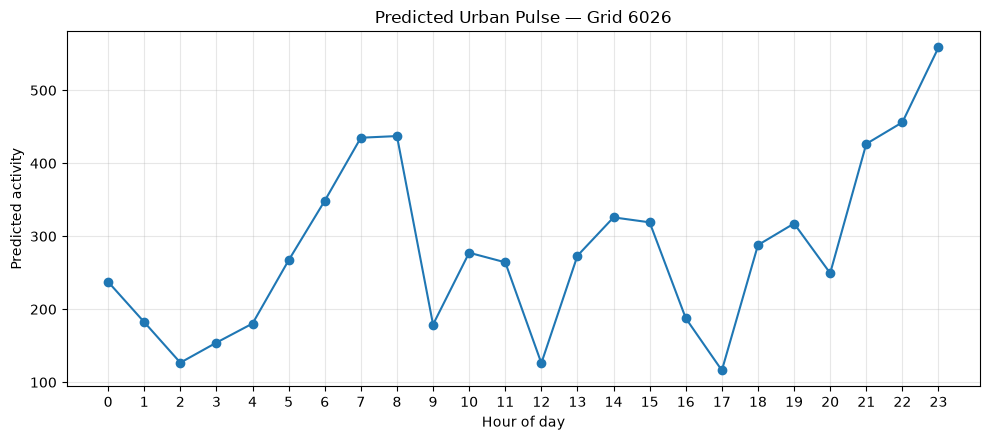

In [65]:

import joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================================
# 1. LOAD SAVED MODELS AND GRID DATA
# ============================================================
base = Path(r"C:\Users\sanojan\Downloads\Roaddd")
out = base / "Colombo_Gampaha_Final"

model_file = out / "final_rf_agent_models.joblib"
grid_file = base / "with_Grid_Entropy_CoreNetwork.shp"

bundle = joblib.load(model_file)
gdf = gpd.read_file(grid_file)

features = bundle["features"]
hour_columns = bundle["hour_columns"]

gdf["grid_id"] = gdf["grid_id"].astype(str)

# ============================================================
# 2. GRID PREDICTION FUNCTION
# ============================================================
def predict_grid(grid_id):
    grid_id = str(grid_id)

    matches = gdf[gdf["grid_id"] == grid_id].copy()

    if matches.empty:
        raise ValueError(
            f"Grid ID {grid_id} was not found in the spatial layer."
        )

    grid = matches.iloc[[0]]

    missing = [c for c in features if c not in grid.columns]
    if missing:
        raise ValueError(f"Missing predictor columns: {missing}")

    X = grid[features].apply(pd.to_numeric, errors="coerce")

    if X.isna().any().any() or not np.isfinite(X.to_numpy()).all():
        raise ValueError(
            f"Grid {grid_id} has missing or invalid predictor values."
        )

    # Predict total activity
    total_prediction = float(
        np.clip(
            np.expm1(bundle["total_model"].predict(X)[0]),
            0,
            None
        )
    )

    # Predict 24 hourly activity values
    hourly_prediction = np.clip(
        np.expm1(bundle["pulse_model"].predict(X)[0]),
        0,
        None
    )

    hourly_sum = float(hourly_prediction.sum())

    # Main predictor values for this grid
    predictor_values = X.iloc[0].to_dict()

    hourly_table = pd.DataFrame({
        "Hour": np.arange(24),
        "Predicted_Activity": hourly_prediction
    })

    print("=" * 60)
    print(f"URBAN ACTIVITY PREDICTION — GRID {grid_id}")
    print("=" * 60)
    print(f"Predicted total activity: {total_prediction:,.2f}")
    print(f"Sum of predicted hourly activity: {hourly_sum:,.2f}")
    print(
        "Difference (hourly sum − predicted total): "
        f"{hourly_sum - total_prediction:,.2f}"
    )
    print(
        "Predicted peak hour: "
        f"{int(hourly_prediction.argmax()):02d}:00"
    )

    print("\nSpatial characteristics:")
    for name, value in predictor_values.items():
        print(f"  {name}: {value:.4f}")

    print("\nPredicted hourly profile:")
    print(hourly_table.to_string(index=False))

    # Plot hourly activity
    plt.figure(figsize=(10, 4.5))
    plt.plot(
        hourly_table["Hour"],
        hourly_table["Predicted_Activity"],
        marker="o"
    )
    plt.xticks(range(24))
    plt.xlabel("Hour of day")
    plt.ylabel("Predicted activity")
    plt.title(f"Predicted Urban Pulse — Grid {grid_id}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {
        "grid_id": grid_id,
        "predicted_total_activity": total_prediction,
        "predicted_hourly_sum": hourly_sum,
        "predicted_peak_hour": int(hourly_prediction.argmax()),
        "predictors": predictor_values,
        "hourly_profile": hourly_table
    }

# ============================================================
# 3. SELECT A GRID AND RUN THE AGENT PREDICTION
# ============================================================
grid_to_test = "6026"  # Change this to another grid ID if desired

result = predict_grid(grid_to_test)


LOCAL MODEL EXPLANATION — GRID 6026

SHAP baseline (log1p activity scale):
8.9326

Feature contributions:
   Feature  Grid_Value  SHAP_Contribution_Log_Scale                Direction
Floor_Inte    0.068463                    -0.459139  Pushes prediction lower
IntDen_km2   30.222222                     0.390152 Pushes prediction higher
 MAD500_wt   54.796162                     0.124228 Pushes prediction higher
 BtA500_wt    0.333333                    -0.028213  Pushes prediction lower
  LConn_wt    4.000000                     0.022434 Pushes prediction higher
land_use_e    0.324401                     0.018051 Pushes prediction higher
Transit_Ac 2446.124512                    -0.014989  Pushes prediction lower
POI_Densit    0.000000                    -0.014786  Pushes prediction lower

Saved explanation table: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\shap_local_grid_6026.csv


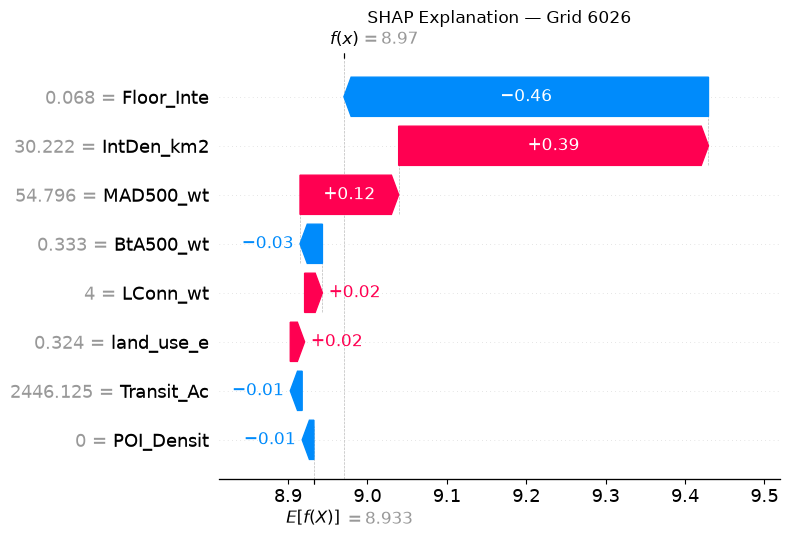

Saved explanation plot: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\shap_local_grid_6026.png


In [66]:

# If SHAP is not installed, run this in a separate cell first:
# %pip install shap

import joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import shap

from pathlib import Path

# ============================================================
# 1. LOAD MODEL AND GRID DATA
# ============================================================
base = Path(r"C:\Users\sanojan\Downloads\Roaddd")
out = base / "Colombo_Gampaha_Final"

bundle = joblib.load(out / "final_rf_agent_models.joblib")
gdf = gpd.read_file(
    base / "with_Grid_Entropy_CoreNetwork.shp"
)

features = bundle["features"]
grid_id = "6026"

gdf["grid_id"] = gdf["grid_id"].astype(str)
selected = gdf[gdf["grid_id"] == grid_id]

if selected.empty:
    raise ValueError(f"Grid {grid_id} not found.")

X_grid = selected[features].apply(
    pd.to_numeric, errors="coerce"
)

if X_grid.isna().any().any():
    raise ValueError("Selected grid has missing predictor values.")

# ============================================================
# 2. CREATE SHAP EXPLAINER
# ============================================================
model = bundle["total_model"]
explainer = shap.TreeExplainer(model)

shap_values = explainer(X_grid)

# ============================================================
# 3. DISPLAY FEATURE CONTRIBUTIONS
# ============================================================
contributions = pd.DataFrame({
    "Feature": features,
    "Grid_Value": X_grid.iloc[0].values,
    "SHAP_Contribution_Log_Scale": shap_values.values[0]
})

contributions["Direction"] = np.where(
    contributions["SHAP_Contribution_Log_Scale"] > 0,
    "Pushes prediction higher",
    np.where(
        contributions["SHAP_Contribution_Log_Scale"] < 0,
        "Pushes prediction lower",
        "No contribution"
    )
)

contributions["Absolute_Contribution"] = (
    contributions["SHAP_Contribution_Log_Scale"].abs()
)

contributions = contributions.sort_values(
    "Absolute_Contribution", ascending=False
)

print("=" * 65)
print(f"LOCAL MODEL EXPLANATION — GRID {grid_id}")
print("=" * 65)

print("\nSHAP baseline (log1p activity scale):")
print(round(float(np.asarray(explainer.expected_value).reshape(-1)[0]), 4))

print("\nFeature contributions:")
print(
    contributions[
        [
            "Feature",
            "Grid_Value",
            "SHAP_Contribution_Log_Scale",
            "Direction"
        ]
    ].to_string(index=False)
)

# Save explanation table
csv_path = out / f"shap_local_grid_{grid_id}.csv"
contributions.to_csv(csv_path, index=False)
print(f"\nSaved explanation table: {csv_path}")

# ============================================================
# 4. CREATE LOCAL EXPLANATION PLOT
# ============================================================
plt.figure()
shap.plots.waterfall(shap_values[0], max_display=8, show=False)
plt.title(f"SHAP Explanation — Grid {grid_id}")
plt.tight_layout()

plot_path = out / f"shap_local_grid_{grid_id}.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved explanation plot: {plot_path}")


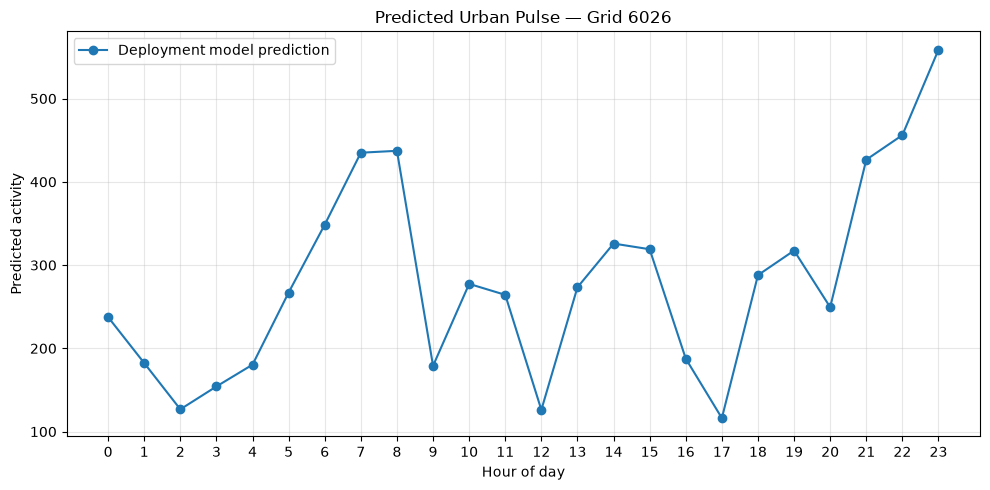

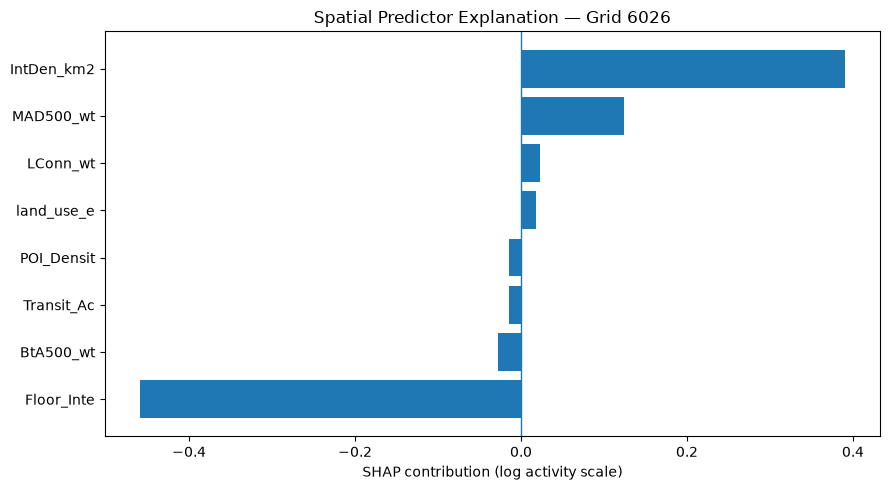


INTEGRATED GRID REPORT CREATED
grid_id  deployment_predicted_total  deployment_predicted_hourly_sum deployment_predicted_peak_hour  oof_observed_total  oof_predicted_total  oof_observed_minus_predicted  oof_absolute_error
   6026                  7865.65772                      6734.731751                          23:00              9692.0          6278.085214                   3413.914786         3413.914786

Top SHAP contributions:
   feature  feature_value  shap_contribution_log_scale                direction  absolute_contribution
Floor_Inte       0.068463                    -0.459139  Pushes prediction lower               0.459139
IntDen_km2      30.222222                     0.390152 Pushes prediction higher               0.390152
 MAD500_wt      54.796162                     0.124228 Pushes prediction higher               0.124228
 BtA500_wt       0.333333                    -0.028213  Pushes prediction lower               0.028213
  LConn_wt       4.000000                     

In [67]:

import os
import joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# =========================================================
# 1. FILE PATHS
# =========================================================
BASE = r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"

MODEL_PATH = os.path.join(BASE, "final_rf_agent_models.joblib")
GRID_PATH = r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
OOF_PATH = os.path.join(BASE, "spatial_cv_out_of_fold_predictions.csv")

OUT = os.path.join(BASE, "AI_Agent_Results")
os.makedirs(OUT, exist_ok=True)

GRID_ID = 6026

# =========================================================
# 2. LOAD DATA
# =========================================================
bundle = joblib.load(MODEL_PATH)
grid = gpd.read_file(GRID_PATH)
oof = pd.read_csv(OOF_PATH)

features = list(bundle["features"])
hours = list(bundle["hour_columns"])

id_col = next(
    (c for c in ["grid_id", "gridid", "grid_ID", "gid", "GID"]
     if c in grid.columns),
    None
)

if id_col is None:
    raise ValueError(f"Grid ID column not found: {grid.columns.tolist()}")

if "grid_id" not in oof.columns:
    raise ValueError("The OOF file must contain grid_id.")

missing = [f for f in features if f not in grid.columns]
if missing:
    raise ValueError(f"Missing predictors in grid file: {missing}")

# Match IDs as strings to avoid integer/string mismatch
grid[id_col] = grid[id_col].astype(str)
oof["grid_id"] = oof["grid_id"].astype(str)

grid_rows = grid[grid[id_col] == str(GRID_ID)]
oof_rows = oof[oof["grid_id"] == str(GRID_ID)]

if grid_rows.empty:
    raise ValueError(f"Grid {GRID_ID} not found in spatial data.")

if len(oof_rows) != 1:
    raise ValueError(
        f"Expected one OOF row for grid {GRID_ID}, found {len(oof_rows)}."
    )

# =========================================================
# 3. DEPLOYMENT PREDICTIONS
# =========================================================
X = grid_rows[features].apply(pd.to_numeric, errors="coerce")

if X.isna().any().any():
    raise ValueError("Selected grid has missing predictor values.")

pred_total = max(
    0.0,
    float(np.expm1(bundle["total_model"].predict(X)[0]))
)

pred_hourly = np.maximum(
    0.0,
    np.expm1(bundle["pulse_model"].predict(X).reshape(-1))
)

hourly_report = pd.DataFrame({
    "hour": range(len(hours)),
    "hour_label": [f"{h:02d}:00" for h in range(len(hours))],
    "predicted_activity": pred_hourly
})

# =========================================================
# 4. OUT-OF-FOLD EVALUATION FOR THE SAME GRID
# =========================================================
oof_row = oof_rows.iloc[0]

oof_observed = pd.to_numeric(
    pd.Series([oof_row.get("total_acti", np.nan)]),
    errors="coerce"
).iloc[0]

oof_predicted = pd.to_numeric(
    pd.Series([oof_row.get("random_forest_pred_total", np.nan)]),
    errors="coerce"
).iloc[0]

if pd.notna(oof_observed) and pd.notna(oof_predicted):
    oof_error = float(oof_observed - oof_predicted)
    oof_absolute_error = abs(oof_error)
else:
    oof_error = np.nan
    oof_absolute_error = np.nan

# =========================================================
# 5. LOCAL SHAP EXPLANATION
# =========================================================
import shap

explainer = shap.TreeExplainer(bundle["total_model"])
shap_output = explainer(X)
shap_values = np.asarray(shap_output.values)

if shap_values.ndim == 3:
    shap_values = shap_values[0, :, 0]
elif shap_values.ndim == 2:
    shap_values = shap_values[0]
else:
    shap_values = shap_values.reshape(-1)

shap_report = pd.DataFrame({
    "feature": features,
    "feature_value": X.iloc[0].values,
    "shap_contribution_log_scale": shap_values
})

shap_report["direction"] = np.select(
    [
        shap_report["shap_contribution_log_scale"] > 0,
        shap_report["shap_contribution_log_scale"] < 0
    ],
    [
        "Pushes prediction higher",
        "Pushes prediction lower"
    ],
    default="No contribution"
)

shap_report["absolute_contribution"] = (
    shap_report["shap_contribution_log_scale"].abs()
)

shap_report = shap_report.sort_values(
    "absolute_contribution", ascending=False
)

# =========================================================
# 6. SAVE REPORTS
# =========================================================
summary = pd.DataFrame([{
    "grid_id": str(GRID_ID),
    "deployment_predicted_total": pred_total,
    "deployment_predicted_hourly_sum": float(pred_hourly.sum()),
    "deployment_predicted_peak_hour": (
        f"{int(np.argmax(pred_hourly)):02d}:00"
    ),
    "oof_observed_total": oof_observed,
    "oof_predicted_total": oof_predicted,
    "oof_observed_minus_predicted": oof_error,
    "oof_absolute_error": oof_absolute_error
}])

summary.to_csv(
    os.path.join(OUT, f"grid_{GRID_ID}_summary.csv"),
    index=False
)
hourly_report.to_csv(
    os.path.join(OUT, f"grid_{GRID_ID}_hourly_profile.csv"),
    index=False
)
shap_report.to_csv(
    os.path.join(OUT, f"grid_{GRID_ID}_shap_explanation.csv"),
    index=False
)

# =========================================================
# 7. CREATE THE TWO CHARTS
# =========================================================
plt.figure(figsize=(10, 5))
plt.plot(
    hourly_report["hour"],
    hourly_report["predicted_activity"],
    marker="o",
    label="Deployment model prediction"
)
plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Predicted activity")
plt.title(f"Predicted Urban Pulse — Grid {GRID_ID}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUT, f"grid_{GRID_ID}_urban_pulse.png"),
    dpi=200
)
plt.show()

plot_shap = shap_report.sort_values("shap_contribution_log_scale")

plt.figure(figsize=(9, 5))
plt.barh(
    plot_shap["feature"],
    plot_shap["shap_contribution_log_scale"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("SHAP contribution (log activity scale)")
plt.title(f"Spatial Predictor Explanation — Grid {GRID_ID}")
plt.tight_layout()
plt.savefig(
    os.path.join(OUT, f"grid_{GRID_ID}_shap.png"),
    dpi=200
)
plt.show()

print("\nINTEGRATED GRID REPORT CREATED")
print(summary.to_string(index=False))
print("\nTop SHAP contributions:")
print(shap_report.head(5).to_string(index=False))
print("\nOutput folder:", OUT)


In [68]:

%pip install streamlit


  Using cached packaging-25.0-py3-none-any.whl.metadata (3.3 kB)
Using cached packaging-25.0-py3-none-any.whl (66 kB)
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
    --------------------------------------- 0.3/11.0 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.0 MB 1.2 MB/s eta 0:00:10
   ---- ----------------------------------- 1.3/11.0 MB 2.1 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.0 MB 2.7 MB/s eta 0:00:04
   -------------- ------------------------- 3.9/11.0 MB 4.3 MB/s eta 0:00:02
   ------------------------- -------------- 7.1/11.0 MB 6.0 MB/s eta 0:00:01
   ------------------------------------- -- 10.2/11.0 MB 7.5 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 7.5 MB/s eta

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ultralytics 8.4.41 requires torch!=2.4.0,>=1.8.0; sys_platform == "win32", which is not installed.
ultralytics 8.4.41 requires torch>=1.8.0, which is not installed.
ultralytics 8.4.41 requires torchvision>=0.9.0, which is not installed.

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import sys
print(sys.executable)

c:\Users\sanojan\Desktop\Sano\python\python.exe


In [2]:
%pip install -U streamlit langgraph langchain-ollama

   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/10.4 MB 9.3 MB/s eta 0:00:02
   ------------------ --------------------- 4.7/10.4 MB 15.3 MB/s eta 0:00:01
   ---------------------------------- ----- 8.9/10.4 MB 17.7 MB/s eta 0:00:01
   ---------------------------------------- 10.4/10.4 MB 16.7 MB/s eta 0:00:00

   ---------------------------------------- 0/3 [ollama]
  Attempting uninstall: streamlit
   ---------------------------------------- 0/3 [ollama]
    Found existing installation: streamlit 1.46.1
   ---------------------------------------- 0/3 [ollama]
   ------------- -------------------------- 1/3 [streamlit]
   ------------- -------------------------- 1/3 [streamlit]
    Uninstalling streamlit-1.46.1:
   ------------- -------------------------- 1/3 [streamlit]
      Successfully uninstalled streamlit-1.46.1
   ------------- -------------------------- 1/3 [streamlit]
   ------------- ----------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import requests

try:
    r = requests.get(
        "http://localhost:11434/api/tags",
        timeout=10
    )
    print("Status:", r.status_code)
    print("Models:", r.json())
except Exception as e:
    print("Error:", repr(e))

Status: 200
Models: {'models': [{'name': 'qwen3:4b', 'model': 'qwen3:4b', 'modified_at': '2026-10-21T22:16:32.3782805+05:30', 'size': 2497293931, 'digest': '359d7dd4bcdab3d86b87d73ac27966f4dbb9f5efdfcc75d34a8764a09474fae7', 'details': {'parent_model': '', 'format': 'gguf', 'family': 'qwen3', 'families': ['qwen3'], 'parameter_size': '4.0B', 'quantization_level': 'Q4_K_M', 'context_length': 262144, 'embedding_length': 2560, 'runner': 'ggml'}, 'capabilities': ['completion', 'tools', 'thinking']}]}


In [9]:
import langchain_ollama
import ollama

print("langchain-ollama:", langchain_ollama.__version__
      if hasattr(langchain_ollama, "__version__") else "version unavailable")
print("ollama package:", ollama.__version__
      if hasattr(ollama, "__version__") else "version unavailable")

langchain-ollama: 1.1.0
ollama package: version unavailable


In [10]:

from langchain_ollama import ChatOllama
import langchain_ollama

print("1. Package location:", langchain_ollama.__file__)

llm = ChatOllama(
    model="qwen3:4b",
    temperature=0,
    num_predict=100,
)

print("\n2. Sending test request...")
response = llm.invoke(
    "Reply with exactly this sentence: "
    "SHAP explains model predictions, not causation."
)

print("\n3. Full response object:")
print(repr(response))

print("\n4. Response content:")
print(repr(response.content))

print("\n5. Response metadata:")
print(response.response_metadata)

print("\n6. Additional content blocks:")
print(getattr(response, "content_blocks", "Not available"))


1. Package location: c:\Users\sanojan\Desktop\Sano\python\Lib\site-packages\langchain_ollama\__init__.py

2. Sending test request...

3. Full response object:
AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-21T17:10:14.0543296Z', 'done': True, 'done_reason': 'length', 'total_duration': 3514237400, 'load_duration': 7863100, 'prompt_eval_count': 26, 'prompt_eval_duration': 331949000, 'eval_count': 100, 'eval_duration': 2384552000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a15f71-1b6a-711c-bcfc-ebef75f85c07-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 26, 'output_tokens': 100, 'total_tokens': 126})

4. Response content:
''

5. Response metadata:
{'model': 'qwen3:4b', 'created_at': '2026-10-21T17:10:14.0543296Z', 'done': True, 'done_reason': 'length', 'total_duration': 3514237400, 'load_duration': 7863100, 'prompt_eval_count': 26, 'prompt_eval_duration': 3319

In [11]:

import requests

url = "http://localhost:11434/api/chat"

payload = {
    "model": "qwen3:4b",
    "messages": [
        {
            "role": "user",
            "content": "Explain in one sentence why SHAP does not prove causation."
        }
    ],
    "think": False,
    "stream": False,
    "options": {
        "num_predict": 250,
        "temperature": 0
    }
}

try:
    r = requests.post(url, json=payload, timeout=180)
    print("HTTP status:", r.status_code)
    r.raise_for_status()

    data = r.json()
    print("Message:", repr(data.get("message")))
    print("Content:", repr(data.get("message", {}).get("content")))
    print("Thinking:", repr(data.get("message", {}).get("thinking")))
    print("Done reason:", data.get("done_reason"))

except Exception as e:
    print("Error:", repr(e))
    if getattr(e, "response", None) is not None:
        print("Server response:", e.response.text[:2000])


HTTP status: 200
Message: {'role': 'assistant', 'content': "Okay, the user is asking why SHAP doesn't prove causation in one sentence. Let me start by recalling what SHAP is. SHAP stands for SHapley Additive exPlanations, which is a method for explaining machine learning models. It's used to attribute importance to features in predictions.\n\nThe user wants a concise explanation. They might be someone familiar with machine learning, maybe a data scientist or a student. They probably encountered SHAP in their work or studies and are confused about causation versus correlation. Their main need is a quick, clear answer without jargon overload. But deeper, they might be trying to understand the limitations of SHAP for their project, like whether they can trust SHAP values for making causal claims. \n\nI remember that SHAP is based on game theory, calculating feature contributions. But causation requires more than correlation—like temporal precedence, mechanism, ruling out confounders. SHAP

In [13]:

import requests

payload = {
    "model": "qwen3:4b",
    "messages": [
        {
            "role": "user",
            "content": "Reply with exactly: TEST SUCCESS"
        }
    ],
    "think": False,
    "stream": False,
    "options": {
        "num_predict": 500,
        "temperature": 0
    }
}

r = requests.post(
    "http://localhost:11434/api/chat",
    json=payload,
    timeout=180
)

print("HTTP status:", r.status_code)
r.raise_for_status()

data = r.json()
message = data.get("message", {})

print("Content:", repr(message.get("content")))
print("Thinking:", repr(message.get("thinking")))
print("Done reason:", data.get("done_reason"))
print("Output tokens:", data.get("eval_count"))
print("Full message:", message)


HTTP status: 200
Content: 'We are to reply with exactly the string "TEST SUCCESS"\n Since the instruction says: "Reply with exactly: TEST SUCCESS"\n We must output only that string without any additional text or newlines.\n</think>\n\nTEST SUCCESS'
Thinking: None
Done reason: stop
Output tokens: 44
Full message: {'role': 'assistant', 'content': 'We are to reply with exactly the string "TEST SUCCESS"\n Since the instruction says: "Reply with exactly: TEST SUCCESS"\n We must output only that string without any additional text or newlines.\n</think>\n\nTEST SUCCESS'}


In [14]:

from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="qwen3:4b",
    temperature=0,
    num_predict=500,
    model_kwargs={"think": False},
)

response = llm.invoke("Reply with exactly: TEST SUCCESS")

print("Content:", repr(response.content))
print("Done reason:", response.response_metadata.get("done_reason"))


Content: 'TEST SUCCESS'
Done reason: stop


In [16]:

from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="qwen3:4b",
    temperature=0,
    num_predict=500,
    model_kwargs={"think": False},
)

response = llm.invoke(
    "Explain functional centrality in one sentence."
)

print("Content:", repr(response.content))
print("Metadata:", response.response_metadata)


Content: "Functional centrality quantifies a node's critical role in enabling the network's core functions, such as information flow or resource distribution."
Metadata: {'model': 'qwen3:4b', 'created_at': '2026-10-21T17:14:05.5870272Z', 'done': True, 'done_reason': 'stop', 'total_duration': 8608071100, 'load_duration': 6506400, 'prompt_eval_count': 19, 'prompt_eval_duration': 289568000, 'eval_count': 424, 'eval_duration': 8254311000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}


In [17]:

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class AgentState(TypedDict):
    question: str
    answer: str

def explanation_agent(state: AgentState):
    response = llm.invoke(state["question"])
    answer = response.content

    print("Inside node, content:", repr(answer))

    if not answer or not answer.strip():
        raise ValueError(
            "The LLM returned empty content. "
            "Check the Ollama response before continuing."
        )

    return {"answer": answer.strip()}

builder = StateGraph(AgentState)
builder.add_node("explanation_agent", explanation_agent)
builder.add_edge(START, "explanation_agent")
builder.add_edge("explanation_agent", END)

research_graph = builder.compile()

result = research_graph.invoke({
    "question": "What is functional centrality? Answer in one sentence.",
    "answer": "",
})

print("Final answer:", repr(result["answer"]))


Inside node, content: 'Functional centrality measures the extent to which a node is critical for facilitating information flow and system functionality within a network.'
Final answer: 'Functional centrality measures the extent to which a node is critical for facilitating information flow and system functionality within a network.'


In [18]:

from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

required_files = [
    "final_rf_agent_models.joblib",
    "final_rf_agent_models_metadata.json",
    "spatial_cv_out_of_fold_predictions.csv",
]

for filename in required_files:
    path = PROJECT_DIR / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    if path.exists():
        print(f"  Size: {path.stat().st_size / (1024 * 1024):.2f} MB")

print("\nProject directory exists:", PROJECT_DIR.exists())


final_rf_agent_models.joblib: FOUND
  Size: 402.05 MB
final_rf_agent_models_metadata.json: FOUND
  Size: 0.00 MB
spatial_cv_out_of_fold_predictions.csv: FOUND
  Size: 11.33 MB

Project directory exists: True


In [19]:

from pathlib import Path
import json
import joblib
import geopandas as gpd

PROJECT_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

MODEL_PATH = PROJECT_DIR / "final_rf_agent_models.joblib"
METADATA_PATH = PROJECT_DIR / "final_rf_agent_models_metadata.json"
OOF_PATH = PROJECT_DIR / "spatial_cv_out_of_fold_predictions.csv"

GRID_PATH = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)

# 1. Load saved models
models = joblib.load(MODEL_PATH)
print("Model bundle loaded:", type(models).__name__)

if isinstance(models, dict):
    print("Bundle keys:", list(models.keys()))
    print("Features:", models.get("features"))
    print("Hourly columns:", models.get("hour_columns"))

# 2. Read metadata
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print("\nMetadata:")
print(json.dumps(metadata, indent=2)[:5000])

# 3. Inspect grid layer
grid = gpd.read_file(GRID_PATH)

print("\nGrid rows:", len(grid))
print("CRS:", grid.crs)
print("Columns:", grid.columns.tolist())

print("\nPossible grid ID columns:")
print([
    c for c in grid.columns
    if "grid" in c.lower() and "id" in c.lower()
])

# 4. Verify predictor availability
features = models.get("features", []) if isinstance(models, dict) else []
print("\nMissing model features:", [c for c in features if c not in grid.columns])


Model bundle loaded: dict
Bundle keys: ['total_model', 'pulse_model', 'features', 'hour_columns', 'total_target', 'target_transform', 'inverse_transform', 'training_grid_ids', 'total_training_rows', 'pulse_training_rows']
Features: ['LConn_wt', 'MAD500_wt', 'BtA500_wt', 'Floor_Inte', 'POI_Densit', 'Transit_Ac', 'IntDen_km2', 'land_use_e']
Hourly columns: ['activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23']

Metadata:
{
  "model_type": "RandomForestRegressor",
  "features": [
    "LConn_wt",
    "MAD500_wt",
    "BtA500_wt",
    "Floor_Inte",
    "POI_Densit",
    "Transit_Ac",
    "IntDen_km2",
    "land_use_e"
  ],
  "hour_columns": [
    "activity_0",
    "activity_1",
    "activity_2",
    "activity_3",


In [20]:

import pandas as pd
import numpy as np

# Load the out-of-fold evaluation data
oof = pd.read_csv(OOF_PATH, low_memory=False)

print("=" * 60)
print("OOF DATA CHECK")
print("=" * 60)
print("Rows:", len(oof))
print("Columns:", len(oof.columns))
print("\nOOF columns:")
print(oof.columns.tolist())

# Confirm grid IDs exist in both datasets
if "grid_id" not in oof.columns:
    raise KeyError("OOF file has no 'grid_id' column.")

if "grid_id" not in grid.columns:
    raise KeyError("Grid layer has no 'grid_id' column.")

oof["grid_id"] = oof["grid_id"].astype(str).str.strip()
grid["grid_id"] = grid["grid_id"].astype(str).str.strip()

oof_ids = set(oof["grid_id"].dropna())
grid_ids = set(grid["grid_id"].dropna())

matched_ids = oof_ids & grid_ids

print("\n" + "=" * 60)
print("GRID ID MATCH CHECK")
print("=" * 60)
print("Unique OOF grid IDs:", len(oof_ids))
print("Unique shapefile grid IDs:", len(grid_ids))
print("Matched grid IDs:", len(matched_ids))
print("OOF IDs missing from shapefile:", len(oof_ids - grid_ids))
print("Shapefile IDs absent from OOF:", len(grid_ids - oof_ids))

# Inspect likely district and prediction-related columns
print("\nDistrict-related columns:")
print([
    c for c in oof.columns
    if "district" in c.lower() or "province" in c.lower()
])

print("\nPrediction/evaluation-related columns:")
print([
    c for c in oof.columns
    if any(word in c.lower() for word in
           ["observed", "predicted", "actual", "oof", "fold", "total_acti"])
])

print("\nFirst 5 OOF rows:")
print(oof.head().to_string(index=False))

# Check duplicate IDs before joining
print("\nDuplicate grid IDs in OOF:", oof["grid_id"].duplicated().sum())
print("Duplicate grid IDs in shapefile:", grid["grid_id"].duplicated().sum())


OOF DATA CHECK
Rows: 7764
Columns: 103

OOF columns:
['grid_id', 'district_name', 'fold', 'total_acti', 'activity_0', 'activity_1', 'activity_2', 'activity_3', 'activity_4', 'activity_5', 'activity_6', 'activity_7', 'activity_8', 'activity_9', 'activity10', 'activity11', 'activity12', 'activity13', 'activity14', 'activity15', 'activity16', 'activity17', 'activity18', 'activity19', 'activity20', 'activity21', 'activity22', 'activity23', 'ridge_pred_total', 'ridge_pred_hour_00', 'ridge_pred_hour_01', 'ridge_pred_hour_02', 'ridge_pred_hour_03', 'ridge_pred_hour_04', 'ridge_pred_hour_05', 'ridge_pred_hour_06', 'ridge_pred_hour_07', 'ridge_pred_hour_08', 'ridge_pred_hour_09', 'ridge_pred_hour_10', 'ridge_pred_hour_11', 'ridge_pred_hour_12', 'ridge_pred_hour_13', 'ridge_pred_hour_14', 'ridge_pred_hour_15', 'ridge_pred_hour_16', 'ridge_pred_hour_17', 'ridge_pred_hour_18', 'ridge_pred_hour_19', 'ridge_pred_hour_20', 'ridge_pred_hour_21', 'ridge_pred_hour_22', 'ridge_pred_hour_23', 'random_fore

In [21]:

from pathlib import Path
import pandas as pd
import geopandas as gpd
import numpy as np

PROJECT_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)
GRID_PATH = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\with_Grid_Entropy_CoreNetwork.shp"
)
OOF_PATH = PROJECT_DIR / "spatial_cv_out_of_fold_predictions.csv"
OUTPUT_DIR = PROJECT_DIR / "AI_Agent_Results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load source files
grid = gpd.read_file(GRID_PATH)
oof = pd.read_csv(OOF_PATH)

features = [
    "LConn_wt", "MAD500_wt", "BtA500_wt", "Floor_Inte",
    "POI_Densit", "Transit_Ac", "IntDen_km2", "land_use_e"
]

# Normalize IDs to avoid mismatches such as 6026 vs 6026.0
def normalize_id(series):
    def clean(value):
        if pd.isna(value):
            return None
        value = str(value).strip()
        if value.endswith(".0"):
            value = value[:-2]
        return value
    return series.map(clean)

grid["_id_key"] = normalize_id(grid["grid_id"])
oof["_id_key"] = normalize_id(oof["grid_id"])

if oof["_id_key"].duplicated().any():
    raise ValueError("Duplicate grid IDs found in OOF data.")

eligible_ids = set(oof["_id_key"].dropna())

agent_grid = grid[grid["_id_key"].isin(eligible_ids)].copy()
agent_oof = oof[oof["_id_key"].isin(set(agent_grid["_id_key"]))].copy()

# Keep the observed values, spatial fold, district, and all model predictions
oof_columns = [
    c for c in oof.columns
    if c not in ["grid_id", "_id_key"]
]
oof_for_merge = agent_oof[["_id_key"] + oof_columns].copy()

agent_grid = agent_grid.merge(
    oof_for_merge,
    on="_id_key",
    how="left",
    validate="one_to_one",
    suffixes=("", "_oof")
)

# Check predictor availability and data quality
missing_features = [c for c in features if c not in agent_grid.columns]
if missing_features:
    raise ValueError(f"Missing model predictors: {missing_features}")

for col in features:
    agent_grid[col] = pd.to_numeric(agent_grid[col], errors="coerce")

print("=" * 55)
print("AGENT DATASET VALIDATION")
print("=" * 55)
print("Eligible spatial cells:", len(agent_grid))
print("Unique grid IDs:", agent_grid["_id_key"].nunique())
print("OOF records without matched geometry:",
      len(agent_oof) - len(agent_grid))
print("Missing predictor values:")
print(agent_grid[features].isna().sum())
print("\nDistrict counts:")
print(agent_grid["district_name"].value_counts(dropna=False))
print("\nOOF fold counts:")
print(agent_grid["fold"].value_counts(dropna=False).sort_index())

# Confirm key OOF evaluation fields are available
required_oof = [
    "total_acti", "random_forest_pred_total",
    "ridge_pred_total", "xgboost_pred_total"
]
print("\nMissing evaluation columns:",
      [c for c in required_oof if c not in agent_grid.columns])

# Save both spatial and tabular versions
gpkg_path = OUTPUT_DIR / "agent_eligible_grids.gpkg"
csv_path = OUTPUT_DIR / "agent_eligible_grids.csv"

agent_grid.drop(columns=["_id_key"]).to_file(
    gpkg_path, layer="eligible_grids", driver="GPKG"
)

agent_grid.drop(columns=["geometry", "_id_key"]).to_csv(
    csv_path, index=False
)

print("\nSaved spatial dataset:", gpkg_path)
print("Saved tabular dataset:", csv_path)
print("\nFirst five eligible grid records:")
print(
    agent_grid[
        ["grid_id", "district_name", "fold", "total_acti",
         "random_forest_pred_total"]
    ].head().to_string(index=False)
)



AGENT DATASET VALIDATION
Eligible spatial cells: 7764
Unique grid IDs: 7764
OOF records without matched geometry: 0
Missing predictor values:
LConn_wt      0
MAD500_wt     0
BtA500_wt     0
Floor_Inte    0
POI_Densit    0
Transit_Ac    0
IntDen_km2    0
land_use_e    0
dtype: int64

District counts:
district_name
Gampaha    5178
Colombo    2586
Name: count, dtype: int64

OOF fold counts:
fold
1    1793
2    1591
3    1392
4    1610
5    1378
Name: count, dtype: int64

Missing evaluation columns: []

Saved spatial dataset: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\AI_Agent_Results\agent_eligible_grids.gpkg
Saved tabular dataset: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\AI_Agent_Results\agent_eligible_grids.csv

First five eligible grid records:
 grid_id district_name  fold  total_acti  random_forest_pred_total
       1       Gampaha     3     21464.0              26362.735741
       0       Gampaha     3       419.0              31404.976547
      19       C

In [22]:

from pathlib import Path
import joblib
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)
RESULTS_DIR = PROJECT_DIR / "AI_Agent_Results"

BUNDLE_PATH = PROJECT_DIR / "final_rf_agent_models.joblib"
DATA_PATH = RESULTS_DIR / "agent_eligible_grids.csv"

models = joblib.load(BUNDLE_PATH)
data = pd.read_csv(DATA_PATH)

features = models["features"]
hour_columns = models["hour_columns"]

# Select an eligible grid for a reproducible test
test_grid_id = "6026"
id_values = data["grid_id"].astype(str).str.replace(r"\.0$", "", regex=True)
matches = data.loc[id_values == test_grid_id]

if matches.empty:
    print(f"Grid {test_grid_id} not found; testing the first eligible grid.")
    row = data.iloc[[0]].copy()
else:
    row = matches.iloc[[0]].copy()

X = row[features].apply(pd.to_numeric, errors="raise")

print("=" * 60)
print("LANGGRAPH PREDICTION-LAYER DIAGNOSTIC")
print("=" * 60)
print("Grid ID:", row["grid_id"].iloc[0])
print("District:", row["district_name"].iloc[0])
print("Predictor count:", len(features))
print("Predictor values:")
print(X.to_string(index=False))

# 1. Total activity model
total_model = models["total_model"]
total_raw = np.asarray(total_model.predict(X)).reshape(-1)

if models.get("target_transform") == "log1p":
    total_prediction = np.expm1(total_raw)
else:
    total_prediction = total_raw

total_prediction = np.maximum(total_prediction, 0)

print("\nTOTAL ACTIVITY MODEL")
print("Estimator:", type(total_model).__name__)
print("Raw prediction:", total_raw.tolist())
print("Transformed prediction:", total_prediction.tolist())

# 2. Hourly/pulse model: inspect output before deciding how to interpret it
pulse_model = models["pulse_model"]
pulse_raw = np.asarray(pulse_model.predict(X))

print("\nHOURLY / PULSE MODEL")
print("Estimator:", type(pulse_model).__name__)
print("Output shape:", pulse_raw.shape)
print("Output sample:", pulse_raw.reshape(-1)[:24].tolist())

if pulse_raw.ndim == 2 and pulse_raw.shape[1] == len(hour_columns):
    profile = pulse_raw[0].astype(float)
    print("Hourly columns:", len(hour_columns))
    print("Profile minimum:", float(np.nanmin(profile)))
    print("Profile maximum:", float(np.nanmax(profile)))
    print("Profile sum:", float(np.nansum(profile)))
    print("Largest predicted hourly value:",
          hour_columns[int(np.nanargmax(profile))])
else:
    print(
        "Output does not directly match the 24-hour column count. "
        "Inspect the model target format before interpreting it."
    )

# 3. Compare with OOF evaluation record (evaluation only)
print("\nOOF EVALUATION RECORD — NOT THE DEPLOYMENT PREDICTION")
for col in [
    "total_acti",
    "random_forest_pred_total",
    "fold"
]:
    if col in row.columns:
        print(f"{col}: {row[col].iloc[0]}")

print("\nDiagnostic complete. No source files were modified.")


LANGGRAPH PREDICTION-LAYER DIAGNOSTIC
Grid ID: 6026
District: Colombo
Predictor count: 8
Predictor values:
 LConn_wt  MAD500_wt  BtA500_wt  Floor_Inte  POI_Densit  Transit_Ac  IntDen_km2  land_use_e
      4.0  54.796162   0.333333    0.068463         0.0 2446.124512   30.222222    0.324401

TOTAL ACTIVITY MODEL
Estimator: RandomForestRegressor
Raw prediction: [8.970388565089666]
Transformed prediction: [7865.657720258468]

HOURLY / PULSE MODEL
Estimator: RandomForestRegressor
Output shape: (1, 24)
Output sample: [5.474458534395214, 5.211406576520034, 4.850453226416059, 5.045130063913272, 5.200889702837565, 5.591321707572965, 5.856814385538127, 6.077632252089994, 6.0828360572764995, 5.193183353090974, 5.629216679356788, 5.580805451155275, 4.845448128217824, 5.614410700800402, 5.789586020704695, 5.7685248764734345, 5.239981541624153, 4.764558689992879, 5.666288463683809, 5.763510508486712, 5.5232906447033265, 6.058155273279807, 6.124932424106913, 6.3273030312093645]
Hourly columns: 24
Pr

In [23]:

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

PROJECT_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)
RESULTS_DIR = PROJECT_DIR / "AI_Agent_Results"

models = joblib.load(PROJECT_DIR / "final_rf_agent_models.joblib")
data = pd.read_csv(RESULTS_DIR / "agent_eligible_grids.csv")
oof = pd.read_csv(PROJECT_DIR / "spatial_cv_out_of_fold_predictions.csv")

grid_id = "6026"
ids = data["grid_id"].astype(str).str.replace(r"\.0$", "", regex=True)
row = data.loc[ids == grid_id]

if row.empty:
    raise ValueError(f"Grid {grid_id} not found.")

X = row[models["features"]].apply(pd.to_numeric, errors="raise")
raw = np.asarray(models["pulse_model"].predict(X)).reshape(-1)

hour_columns = models["hour_columns"]
hourly_expm1 = np.maximum(np.expm1(raw), 0)
hourly_share = hourly_expm1 / hourly_expm1.sum()

print("Grid:", grid_id)
print("Raw hourly output sum:", raw.sum())
print("After expm1 — hourly sum:", hourly_expm1.sum())
print("After expm1 — peak hour:", int(np.argmax(hourly_expm1)))
print("Normalized-profile sum:", hourly_share.sum())

print("\nFirst 24-hour values:")
print(pd.DataFrame({
    "hour": list(range(24)),
    "model_raw_output": raw,
    "expm1_candidate": hourly_expm1,
    "normalized_share": hourly_share
}).round(4).to_string(index=False))

# Compare with the existing saved report, if available
report_path = RESULTS_DIR / "grid_6026_hourly_profile.csv"
if report_path.exists():
    report = pd.read_csv(report_path)
    print("\nExisting hourly report columns:", report.columns.tolist())
    print(report.head(10).to_string(index=False))
else:
    print("\nNo existing hourly report found at:", report_path)

# Check the OOF hourly predictions for this grid
oof_ids = oof["grid_id"].astype(str).str.replace(r"\.0$", "", regex=True)
oof_row = oof.loc[oof_ids == grid_id]

if not oof_row.empty:
    oof_hour_cols = [
        f"random_forest_pred_hour_{h:02d}" for h in range(24)
    ]
    if all(c in oof_row.columns for c in oof_hour_cols):
        oof_hourly = oof_row.iloc[0][oof_hour_cols].to_numpy(dtype=float)
        print("\nOOF RF hourly prediction sum:", oof_hourly.sum())
        print("OOF RF hourly peak hour:", int(np.argmax(oof_hourly)))
    else:
        print("\nExpected OOF hourly prediction columns are incomplete.")
else:
    print("\nGrid not found in OOF records.")


Grid: 6026
Raw hourly output sum: 133.2801382934461
After expm1 — hourly sum: 6734.731751469782
After expm1 — peak hour: 23
Normalized-profile sum: 1.0000000000000002

First 24-hour values:
 hour  model_raw_output  expm1_candidate  normalized_share
    0            5.4745         237.5213            0.0353
    1            5.2114         182.3518            0.0271
    2            4.8505         126.7983            0.0188
    3            5.0451         154.2645            0.0229
    4            5.2009         180.4336            0.0268
    5            5.5913         267.0897            0.0397
    6            5.8568         348.6086            0.0518
    7            6.0776         434.9956            0.0646
    8            6.0828         437.2704            0.0649
    9            5.1932         179.0408            0.0266
   10            5.6292         277.4439            0.0412
   11            5.5808         264.2852            0.0392
   12            4.8454         126.1603   

In [24]:

from pathlib import Path
import joblib
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)
RESULTS_DIR = PROJECT_DIR / "AI_Agent_Results"

models = joblib.load(PROJECT_DIR / "final_rf_agent_models.joblib")
grid_data = pd.read_csv(RESULTS_DIR / "agent_eligible_grids.csv")

FEATURES = models["features"]
HOUR_COLUMNS = models["hour_columns"]

def normalize_grid_id(value):
    value = str(value).strip()
    return value[:-2] if value.endswith(".0") else value

grid_data["_grid_key"] = grid_data["grid_id"].map(normalize_grid_id)

if grid_data["_grid_key"].duplicated().any():
    raise ValueError("Duplicate grid IDs in agent dataset.")

def get_grid_report(grid_id):
    """Return deployment predictions and separate OOF evaluation evidence."""
    key = normalize_grid_id(grid_id)
    match = grid_data.loc[grid_data["_grid_key"] == key]

    if match.empty:
        return {
            "success": False,
            "message": (
                f"Grid {grid_id} is not in the eligible 7,764-grid "
                "Colombo–Gampaha evaluation dataset."
            )
        }

    row = match.iloc[0]
    X = row[FEATURES].to_frame().T.apply(
        pd.to_numeric, errors="raise"
    )

    # Deployment prediction: total activity
    raw_total = float(
        np.asarray(models["total_model"].predict(X)).reshape(-1)[0]
    )

    if models.get("target_transform") == "log1p":
        predicted_total = float(np.expm1(raw_total))
    else:
        predicted_total = raw_total

    predicted_total = max(0.0, predicted_total)

    # Deployment prediction: 24 hourly values
    raw_hourly = np.asarray(
        models["pulse_model"].predict(X)
    ).reshape(-1)

    if len(raw_hourly) != 24:
        raise ValueError(
            f"Expected 24 hourly predictions, got {len(raw_hourly)}."
        )

    predicted_hourly = (
        np.expm1(raw_hourly)
        if models.get("target_transform") == "log1p"
        else raw_hourly.copy()
    )
    predicted_hourly = np.maximum(predicted_hourly, 0.0)

    hourly_sum = float(predicted_hourly.sum())
    if hourly_sum > 0:
        normalized_profile = predicted_hourly / hourly_sum
    else:
        normalized_profile = np.zeros(24)

    peak_hour = int(np.argmax(predicted_hourly))

    # Evaluation evidence: the saved OOF predictions, not deployment output
    observed_total = float(row["total_acti"])
    oof_predicted_total = float(row["random_forest_pred_total"])

    hourly_report = [
        {
            "hour": h,
            "hour_label": f"{h:02d}:00",
            "predicted_activity": float(predicted_hourly[h]),
            "normalized_share": float(normalized_profile[h])
        }
        for h in range(24)
    ]

    return {
        "success": True,
        "grid_id": str(row["grid_id"]),
        "district": str(row["district_name"]),
        "spatial_fold": int(row["fold"]),
        "predictors": {
            feature: float(row[feature]) for feature in FEATURES
        },
        "deployment_prediction": {
            "predicted_total_activity": predicted_total,
            "predicted_hourly_sum": hourly_sum,
            "predicted_peak_hour": f"{peak_hour:02d}:00",
            "hourly_profile": hourly_report
        },
        "oof_evaluation": {
            "observed_total_activity": observed_total,
            "oof_predicted_total_activity": oof_predicted_total,
            "observed_minus_oof_predicted": (
                observed_total - oof_predicted_total
            ),
            "absolute_oof_error": abs(
                observed_total - oof_predicted_total
            ),
            "evaluation_fold": int(row["fold"])
        },
        "interpretation_note": (
            "Deployment predictions are distinct from OOF evaluation "
            "predictions. Total activity and hourly activity are produced "
            "by separate models and need not sum to the same value."
        )
    }

# Test with the known grid
report = get_grid_report("6026")

print("Success:", report["success"])
if report["success"]:
    print("Grid:", report["grid_id"])
    print("District:", report["district"])
    print("\nDeployment prediction:")
    print(report["deployment_prediction"]["predicted_total_activity"])
    print("Hourly sum:",
          report["deployment_prediction"]["predicted_hourly_sum"])
    print("Peak hour:",
          report["deployment_prediction"]["predicted_peak_hour"])

    print("\nOOF evaluation:")
    print(report["oof_evaluation"])

    print("\nFirst 5 hourly predictions:")
    print(pd.DataFrame(
        report["deployment_prediction"]["hourly_profile"]
    ).head().to_string(index=False))
else:
    print(report["message"])


Success: True
Grid: 6026
District: Colombo

Deployment prediction:
7865.657720258481
Hourly sum: 6734.731751469781
Peak hour: 23:00

OOF evaluation:
{'observed_total_activity': 9692.0, 'oof_predicted_total_activity': 6278.085213655163, 'observed_minus_oof_predicted': 3413.914786344837, 'absolute_oof_error': 3413.914786344837, 'evaluation_fold': 5}

First 5 hourly predictions:
 hour hour_label  predicted_activity  normalized_share
    0      00:00          237.521281          0.035268
    1      01:00          182.351775          0.027076
    2      02:00          126.798298          0.018828
    3      03:00          154.264492          0.022906
    4      04:00          180.433592          0.026792


In [25]:

import json
import re
from typing import TypedDict, Any

from langchain_ollama import ChatOllama
from langgraph.graph import StateGraph, START, END

# Local LLM — no external API key required
llm = ChatOllama(
    model="qwen3:4b",
    temperature=0,
    num_predict=600,
    model_kwargs={"think": False},
)

class AgentState(TypedDict):
    question: str
    grid_id: str
    report: dict[str, Any]
    answer: str
    review_status: str

# Node 1: Identify the grid requested by the user
def planner_node(state: AgentState):
    question = state["question"]

    # Accept examples such as "Grid 6026", "grid_id: 6026"
    match = re.search(
        r"\b(?:grid(?:\s*id)?\s*[:#]?\s*)(\d+)\b",
        question,
        flags=re.IGNORECASE
    )

    if not match:
        # Also accept a numeric ID as the entire question
        stripped = question.strip()
        if stripped.isdigit():
            grid_id = stripped
        else:
            return {
                "grid_id": "",
                "report": {},
                "answer": (
                    "Which grid would you like me to analyse? "
                    "Please provide its numeric grid ID, for example 6026."
                ),
                "review_status": "needs_grid_id"
            }
    else:
        grid_id = match.group(1)

    return {
        "grid_id": grid_id,
        "report": {},
        "answer": "",
        "review_status": "pending"
    }

# Node 2: Run the verified data and prediction function
def prediction_node(state: AgentState):
    report = get_grid_report(state["grid_id"])

    if not report.get("success", False):
        return {
            "report": report,
            "answer": report.get("message", "Grid lookup failed."),
            "review_status": "grid_not_eligible"
        }

    return {"report": report, "review_status": "pending"}

# Node 3: Deterministic review before the LLM writes an answer
def review_node(state: AgentState):
    report = state["report"]

    if not report.get("success", False):
        return {
            "review_status": "grid_not_eligible",
            "answer": report.get("message", "Grid lookup failed.")
        }

    deployment = report["deployment_prediction"]
    evaluation = report["oof_evaluation"]

    required_values = [
        deployment["predicted_total_activity"],
        deployment["predicted_hourly_sum"],
        evaluation["observed_total_activity"],
        evaluation["oof_predicted_total_activity"],
        evaluation["observed_minus_oof_predicted"],
    ]

    if not all(np.isfinite(float(v)) for v in required_values):
        return {
            "review_status": "failed",
            "answer": "The result failed numerical validation."
        }

    expected_error = (
        evaluation["observed_total_activity"]
        - evaluation["oof_predicted_total_activity"]
    )

    if not np.isclose(
        expected_error,
        evaluation["observed_minus_oof_predicted"],
        atol=1e-6
    ):
        return {
            "review_status": "failed",
            "answer": "The OOF mismatch failed numerical validation."
        }

    if len(deployment["hourly_profile"]) != 24:
        return {
            "review_status": "failed",
            "answer": "The hourly profile did not contain 24 values."
        }

    return {"review_status": "passed"}

# Node 4: Explain only the validated report
def explanation_node(state: AgentState):
    report = state["report"]

    prompt = f"""
You are a research assistant for an urban morphology and urban pulse study
in Colombo and Gampaha, Sri Lanka.

Answer the user's question using ONLY the validated data below.

USER QUESTION:
{state["question"]}

VALIDATED REPORT:
{json.dumps(report, ensure_ascii=False, allow_nan=False)}

RULES:
- Clearly distinguish deployment predictions from OOF evaluation values.
- State activity values as model estimates, not guaranteed outcomes.
- Explain that observed minus OOF-predicted is the evaluation mismatch.
- The peak hour refers to the maximum predicted hourly activity.
- Do not claim SHAP explanations, causal effects, or intervention impacts;
  those have not been supplied in this report.
- Do not invent morphology interpretations or planning interventions.
- Mention that total activity and hourly predictions come from separate
  models and may not sum to the same total.
- Use clear, concise language suitable for an undergraduate research demo.
"""

    response = llm.invoke(prompt)
    answer = str(response.content).strip()

    if not answer:
        answer = (
            f"Grid {report['grid_id']} in {report['district']} has a "
            f"deployment-predicted total activity of "
            f"{report['deployment_prediction']['predicted_total_activity']:.2f}. "
            "The accompanying OOF values are evaluation evidence, not the "
            "deployment prediction."
        )

    return {"answer": answer}

# Build the graph
builder = StateGraph(AgentState)

builder.add_node("planner", planner_node)
builder.add_node("prediction", prediction_node)
builder.add_node("review", review_node)
builder.add_node("explanation", explanation_node)

builder.add_edge(START, "planner")

def route_after_planner(state):
    if state["review_status"] == "needs_grid_id":
        return END
    return "prediction"

builder.add_conditional_edges(
    "planner",
    route_after_planner,
    {"prediction": "prediction", END: END}
)

builder.add_edge("prediction", "review")

def route_after_review(state):
    if state["review_status"] == "passed":
        return "explanation"
    return END

builder.add_conditional_edges(
    "review",
    route_after_review,
    {"explanation": "explanation", END: END}
)

builder.add_edge("explanation", END)

research_graph = builder.compile()

print("LangGraph workflow compiled successfully.")


LangGraph workflow compiled successfully.


In [30]:

test_questions = [
    "What is expected in Grid 6026?",
    "What does the model predict for Grid 6026, and how accurate was it on the OOF evaluation?"
]

for question in test_questions:
    print("\n" + "=" * 70)
    print("QUESTION:", question)

    result = research_graph.invoke({
        "question": question,
        "grid_id": "",
        "report": {},
        "answer": "",
        "review_status": "pending"
    })

    print("REVIEW:", result["review_status"])
    print("ANSWER:\n", result["answer"])

# Check that missing IDs are handled safely
result = research_graph.invoke({
    "question": "Explain urban pulse.",
    "grid_id": "",
    "report": {},
    "answer": "",
    "review_status": "pending"
})

print("\nMISSING-GRID TEST:")
print(result["answer"])



QUESTION: What is expected in Grid 6026?
REVIEW: passed
ANSWER:
 Based **strictly on the validated report data** for Grid 6026 in Colombo:  

1. **Deployment predictions** (what the model *expects* for this grid) show:  
   - **Total predicted activity**: 7,866 (rounded)  
   - **Peak hour**: 23:00 (with 5

QUESTION: What does the model predict for Grid 6026, and how accurate was it on the OOF evaluation?
REVIEW: passed
ANSWER:
 Grid 6026 in Colombo has a deployment-predicted total activity of 7865.66. The accompanying OOF values are evaluation evidence, not the deployment prediction.

MISSING-GRID TEST:
Which grid would you like me to analyse? Please provide its numeric grid ID, for example 6026.


In [29]:

def explanation_node(state: AgentState):
    report = state["report"]
    deployment = report["deployment_prediction"]
    evaluation = report["oof_evaluation"]

    peak = max(
        deployment["hourly_profile"],
        key=lambda item: item["predicted_activity"]
    )

    # Construct the key facts deterministically in Python
    facts = f"""
GRID: {report['grid_id']}
DISTRICT: {report['district']}
SPATIAL FOLD: {report['spatial_fold']}

DEPLOYMENT PREDICTIONS:
- Predicted total activity: {deployment['predicted_total_activity']:,.2f}
- Sum of predicted hourly activity: {deployment['predicted_hourly_sum']:,.2f}
- Peak hour: {peak['hour_label']}
- Predicted activity at peak hour: {peak['predicted_activity']:,.2f}

OOF EVALUATION:
- Observed total activity: {evaluation['observed_total_activity']:,.2f}
- OOF Random Forest prediction: {evaluation['oof_predicted_total_activity']:,.2f}
- Observed minus OOF prediction: {evaluation['observed_minus_oof_predicted']:+,.2f}
- Absolute OOF error: {evaluation['absolute_oof_error']:,.2f}
- Evaluation fold: {evaluation['evaluation_fold']}
"""

    prompt = f"""
You are an assistant for an undergraduate urban morphology research project.

User question:
{state['question']}

Verified facts from Python:
{facts}

Write a concise answer that addresses the user's question.

Rules:
1. Include the deployment-predicted total when relevant.
2. If the user asks about evaluation or accuracy, include the observed total,
   OOF prediction, signed mismatch, and absolute OOF error.
3. Explain that a positive observed-minus-predicted value means
   the model underpredicted this grid's observed activity.
4. Do not call a single-grid error the model's overall accuracy.
5. Clearly separate deployment predictions from OOF evaluation values.
6. Explain that the total and hourly predictions come from separate models.
7. Do not invent causal claims, SHAP explanations, or intervention effects.
8. Use clear, direct language.
"""

    response = llm.invoke(prompt)
    answer = str(response.content).strip()

    # Reliable fallback if the LLM returns empty content
    if not answer:
        answer = (
            f"Grid {report['grid_id']} in {report['district']}: "
            f"deployment-predicted total activity is "
            f"{deployment['predicted_total_activity']:,.2f}. "
            f"The OOF prediction was "
            f"{evaluation['oof_predicted_total_activity']:,.2f}, "
            f"against observed activity of "
            f"{evaluation['observed_total_activity']:,.2f}. "
            f"The absolute OOF error was "
            f"{evaluation['absolute_oof_error']:,.2f}."
        )

    return {"answer": answer}


In [35]:

# STEP 1: TEST THE REBUILT LANGGRAPH AGENT
# No grandalf installation required.

print("Graph rebuilt successfully.")
print("Skipping optional ASCII graph drawing.")

test_questions = [
    "What is expected in Grid 6026?",
    "What does the model predict for Grid 6026, and how accurate was it on the OOF evaluation?",
    "What is expected in Grid 999999?"
]

for question in test_questions:
    print("\n" + "=" * 80)
    print("QUESTION:", question)
    print("=" * 80)

    initial_state = {
        "question": question,
        "grid_id": "",
        "report": {},
        "answer": "",
        "review_status": ""
    }

    try:
        result = research_graph.invoke(initial_state)

        print("Grid ID:", result.get("grid_id"))
        print("Review status:", result.get("review_status"))
        print("\nAGENT ANSWER:\n")
        print(result.get("answer", "No answer returned."))

        report = result.get("report", {})
        if report:
            print("\nReport success:", report.get("success"))
            if not report.get("success"):
                print("Report message:", report.get("message"))

    except Exception as exc:
        print("TEST FAILED:", repr(exc))


Graph rebuilt successfully.
Skipping optional ASCII graph drawing.

QUESTION: What is expected in Grid 6026?
Grid ID: 6026
Review status: passed

AGENT ANSWER:

For Grid 6026 in Colombo (Spatial Fold 5):  

**Deployment Predictions** (model's forecast for this grid):  
- Total activity: 7,865.66  
- Peak hour: 23:00 (predicted activity: 558.65)  

**OOF Evaluation** (actual vs. model's prediction for this grid):  
- Observed total activity: 9,692.00  
- OOF prediction: 6,278.09

Report success: True

QUESTION: What does the model predict for Grid 6026, and how accurate was it on the OOF evaluation?
Grid ID: 6026
Review status: passed

AGENT ANSWER:

Grid 6026 in Colombo: deployment-predicted total activity is 7,865.66. The OOF prediction was 6,278.09, against observed activity of 9,692.00. The absolute OOF error was 3,413.91.

Report success: True

QUESTION: What is expected in Grid 999999?
Grid ID: 999999
Review status: grid_not_eligible

AGENT ANSWER:

Grid 999999 is not in the eligi

In [32]:
pip install grandalf

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:

def explanation_node(state: AgentState) -> dict:
    """Generate an answer grounded in the validated grid report."""

    report = state.get("report", {})

    if not report or not report.get("success"):
        return {
            "answer": report.get(
                "message",
                "I could not retrieve a valid report for that grid."
            ),
            "review_status": state.get("review_status", "failed")
        }

    # Read values directly from the verified report
    deployment = report.get("deployment_prediction", {})
    evaluation = report.get("oof_evaluation", {})

    # Support the flat report structure used by the current function
    predicted_total = report.get("predicted_total_activity")
    hourly_sum = report.get("predicted_hourly_sum")
    peak_hour = report.get("predicted_peak_hour")
    hourly_profile = report.get("hourly_profile", [])

    observed_total = report.get("observed_total_activity")
    oof_predicted = report.get("oof_predicted_total_activity")
    signed_error = report.get("observed_minus_oof_predicted")
    absolute_error = report.get("absolute_oof_error")
    fold = report.get("evaluation_fold", report.get("spatial_fold"))
    district = report.get("district", "Unknown")

    # If the report uses nested sections, use those values as fallbacks
    if isinstance(deployment, dict):
        predicted_total = deployment.get(
            "predicted_total_activity", predicted_total
        )
        hourly_sum = deployment.get("predicted_hourly_sum", hourly_sum)
        peak_hour = deployment.get("predicted_peak_hour", peak_hour)
        hourly_profile = deployment.get("hourly_profile", hourly_profile)

    if isinstance(evaluation, dict):
        observed_total = evaluation.get(
            "observed_total_activity", observed_total
        )
        oof_predicted = evaluation.get(
            "oof_predicted_total_activity", oof_predicted
        )
        signed_error = evaluation.get(
            "observed_minus_oof_predicted", signed_error
        )
        absolute_error = evaluation.get("absolute_oof_error", absolute_error)
        fold = evaluation.get("evaluation_fold", fold)

    peak_value = None
    if isinstance(hourly_profile, list) and hourly_profile:
        valid_points = [
            p for p in hourly_profile
            if isinstance(p, dict)
            and p.get("predicted_activity") is not None
        ]
        if valid_points:
            peak_value = max(
                valid_points, key=lambda p: float(p["predicted_activity"])
            ).get("predicted_activity")

    def fmt(value):
        try:
            return f"{float(value):,.2f}"
        except (TypeError, ValueError):
            return "Not available"

    facts = f"""
Grid: {report.get('grid_id', state.get('grid_id', 'Unknown'))}
District: {district}
Spatial fold: {fold}

Full-model deployment prediction:
Predicted total activity: {fmt(predicted_total)}
Predicted sum of hourly outputs: {fmt(hourly_sum)}
Predicted peak hour: {peak_hour}
Predicted peak-hour activity: {fmt(peak_value)}

Out-of-fold evaluation:
Observed total activity: {fmt(observed_total)}
Out-of-fold predicted total activity: {fmt(oof_predicted)}
Signed difference (observed minus OOF prediction): {fmt(signed_error)}
Absolute OOF error: {fmt(absolute_error)}

Important:
Deployment predictions come from the final model trained on the full eligible sample.
OOF predictions are generated for evaluation from held-out folds.
Do not treat these as the same prediction.
The signed difference is an error measure, not a causal explanation.
"""

    prompt = f"""
You are an urban analytics research assistant.
Answer the user's question using ONLY the report facts below.
Do not invent values or claim that association proves causation.

User question:
{state.get('question', '')}

Verified facts:
{facts}

Instructions:
- Use clear headings and concise bullet points.
- If asked about accuracy, report observed activity, OOF prediction,
  signed difference and absolute OOF error when available.
- Explain that a positive signed difference means the model underpredicted
  this grid's observed total.
- Keep deployment predictions separate from OOF evaluation.
- If a value is unavailable, say so rather than guessing.
"""

    try:
        response = llm.invoke(prompt)
        answer = getattr(response, "content", str(response)).strip()

        if not answer:
            answer = (
                f"Grid {report.get('grid_id', state.get('grid_id'))}: "
                f"deployment predicted total = {fmt(predicted_total)}; "
                f"OOF observed = {fmt(observed_total)}; "
                f"OOF predicted = {fmt(oof_predicted)}; "
                f"signed difference = {fmt(signed_error)}; "
                f"absolute OOF error = {fmt(absolute_error)}."
            )

    except Exception as exc:
        answer = (
            f"Grid {report.get('grid_id', state.get('grid_id'))}\n"
            f"Deployment predicted total: {fmt(predicted_total)}\n"
            f"Predicted peak hour: {peak_hour}\n"
            f"OOF observed total: {fmt(observed_total)}\n"
            f"OOF predicted total: {fmt(oof_predicted)}\n"
            f"Signed OOF difference: {fmt(signed_error)}\n"
            f"Absolute OOF error: {fmt(absolute_error)}\n"
            f"(Language-model explanation unavailable: {exc})"
        )

    return {
        "answer": answer,
        "review_status": state.get("review_status", "passed")
    }


In [41]:
result = research_graph.invoke({
    "question": (
        "For Grid 6026, report the deployment prediction and "
        "all available OOF evaluation values. Explain the signed error."
    ),
    "grid_id": "",
    "report": {},
    "answer": "",
    "review_status": ""
})

print(result["answer"])

Grid 6026 in Colombo: deployment-predicted total activity is 7,865.66. The OOF prediction was 6,278.09, against observed activity of 9,692.00. The absolute OOF error was 3,413.91.


In [40]:

report = get_grid_report(6026)

print("REPORT KEYS:")
print(list(report.keys()))

print("\nDEPLOYMENT PREDICTION:")
print(report.get("deployment_prediction"))

print("\nOOF EVALUATION:")
print(report.get("oof_evaluation"))

print("\nFLAT EVALUATION FIELDS:")
for key in [
    "predicted_total_activity",
    "predicted_hourly_sum",
    "predicted_peak_hour",
    "hourly_profile",
    "observed_total_activity",
    "oof_predicted_total_activity",
    "observed_minus_oof_predicted",
    "absolute_oof_error",
    "evaluation_fold",
    "district",
]:
    if key in report:
        value = report[key]
        if key == "hourly_profile" and isinstance(value, list):
            print(key, "—", len(value), "items")
            print("First item:", value[0] if value else None)
        else:
            print(key, "=", value)


REPORT KEYS:
['success', 'grid_id', 'district', 'spatial_fold', 'predictors', 'deployment_prediction', 'oof_evaluation', 'interpretation_note']

DEPLOYMENT PREDICTION:
{'predicted_total_activity': 7865.657720258454, 'predicted_hourly_sum': 6734.731751469781, 'predicted_peak_hour': '23:00', 'hourly_profile': [{'hour': 0, 'hour_label': '00:00', 'predicted_activity': 237.52128088930587, 'normalized_share': 0.035268113067379335}, {'hour': 1, 'hour_label': '01:00', 'predicted_activity': 182.35177520378855, 'normalized_share': 0.027076323442873917}, {'hour': 2, 'hour_label': '02:00', 'predicted_activity': 126.79829828693096, 'normalized_share': 0.018827520228887906}, {'hour': 3, 'hour_label': '03:00', 'predicted_activity': 154.26449219258868, 'normalized_share': 0.022905810934328922}, {'hour': 4, 'hour_label': '04:00', 'predicted_activity': 180.43359206933843, 'normalized_share': 0.026791503912529373}, {'hour': 5, 'hour_label': '05:00', 'predicted_activity': 267.08972186797604, 'normalized_s

In [39]:

def explanation_node(state: AgentState) -> dict:
    """Explain predictions using the confirmed nested report structure."""

    report = state.get("report", {})

    if not report or not report.get("success"):
        return {
            "answer": report.get(
                "message",
                "No eligible grid report is available."
            ),
            "review_status": state.get("review_status", "failed")
        }

    deployment = report["deployment_prediction"]
    evaluation = report["oof_evaluation"]

    grid_id = report["grid_id"]
    district = report["district"]
    fold = evaluation["evaluation_fold"]

    predicted_total = float(deployment["predicted_total_activity"])
    hourly_sum = float(deployment["predicted_hourly_sum"])
    peak_hour = deployment["predicted_peak_hour"]

    hourly_profile = deployment["hourly_profile"]
    peak_item = max(
        hourly_profile,
        key=lambda item: float(item["predicted_activity"])
    )
    peak_value = float(peak_item["predicted_activity"])
    peak_share = float(peak_item["normalized_share"]) * 100

    observed = float(evaluation["observed_total_activity"])
    oof_predicted = float(evaluation["oof_predicted_total_activity"])
    signed_error = float(evaluation["observed_minus_oof_predicted"])
    absolute_error = float(evaluation["absolute_oof_error"])

    direction = (
        "underpredicted"
        if signed_error > 0
        else "overpredicted"
        if signed_error < 0
        else "matched"
    )

    facts = f"""
Grid {grid_id}, District: {district}

DEPLOYMENT PREDICTION (final model trained on the full eligible sample)
- Predicted total activity: {predicted_total:,.2f}
- Sum of predicted hourly outputs: {hourly_sum:,.2f}
- Predicted peak hour: {peak_hour}
- Predicted activity at peak hour: {peak_value:,.2f}
- Normalized peak-hour share: {peak_share:.2f}%

OUT-OF-FOLD EVALUATION (held-out fold {fold})
- Observed total activity: {observed:,.2f}
- OOF predicted total activity: {oof_predicted:,.2f}
- Signed difference (observed minus OOF prediction): {signed_error:+,.2f}
- Absolute OOF error: {absolute_error:,.2f}
- Interpretation: the model {direction} observed total activity for this grid.

Keep deployment predictions separate from OOF evaluation.
The signed difference describes prediction error, not causation.
Do not claim these two sets of predictions are the same.
"""

    fallback_answer = f"""## Grid {grid_id} — {district}

### Deployment prediction
- Predicted total activity: **{predicted_total:,.2f}**
- Predicted hourly-output sum: **{hourly_sum:,.2f}**
- Peak hour: **{peak_hour}**
- Peak-hour activity: **{peak_value:,.2f}**
- Peak-hour share of normalized profile: **{peak_share:.2f}%**

### Out-of-fold evaluation — Fold {fold}
- Observed total activity: **{observed:,.2f}**
- OOF predicted total activity: **{oof_predicted:,.2f}**
- Signed difference (observed − OOF prediction): **{signed_error:+,.2f}**
- Absolute OOF error: **{absolute_error:,.2f}**

The positive signed difference means the model underpredicted this grid's
observed activity by {absolute_error:,.2f} in the OOF evaluation.

Deployment values come from the final model trained on the full eligible
sample; OOF values evaluate predictions made for held-out data.
The error is predictive evidence, not a causal explanation.
"""

    try:
        prompt = f"""
You are an urban analytics research assistant.

Answer the user's question using only the verified facts below.
Preserve all numbers exactly. Do not invent metrics or claim causation.

User question:
{state.get('question', '')}

Verified facts:
{facts}

If the user asks for prediction and evaluation details, include:
1. Deployment total and peak-hour prediction.
2. Observed and OOF predicted totals.
3. Signed difference and absolute error.
4. A brief interpretation of the error.
5. A clear distinction between deployment and OOF predictions.
"""
        response = llm.invoke(prompt)
        answer = getattr(response, "content", str(response)).strip()

        # Enforce completeness: use deterministic report if the LLM
        # omits any required evaluation figure.
        required_values = [
            f"{observed:,.2f}",
            f"{oof_predicted:,.2f}",
            f"{signed_error:+,.2f}",
            f"{absolute_error:,.2f}",
        ]

        if not answer or not all(v in answer for v in required_values):
            answer = fallback_answer

    except Exception:
        answer = fallback_answer

    return {
        "answer": answer,
        "review_status": state.get("review_status", "passed")
    }


In [43]:

# ================================================================
# URBAN PULSE AI AGENT
# LangGraph + Random Forest + Ollama
# Research: Learning Functional Centrality from Urban Morphology
# ================================================================

# If needed, install these in a separate notebook cell:
# %pip install -U pandas numpy joblib langgraph langchain-ollama

import re
import math
import json
from pathlib import Path
from typing import TypedDict, Any

import numpy as np
import pandas as pd
import joblib

from langgraph.graph import StateGraph, START, END
from langchain_ollama import ChatOllama


# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

MODEL_PATH = BASE_DIR / "final_rf_agent_models.joblib"
RESULTS_DIR = BASE_DIR / "AI_Agent_Results"
GRID_CSV_PATH = RESULTS_DIR / "agent_eligible_grids.csv"

MODEL_NAME = "qwen3:4b"

# ================================================================
# 2. LOAD MODELS AND DATA
# ================================================================

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model bundle not found: {MODEL_PATH}")

if not GRID_CSV_PATH.exists():
    raise FileNotFoundError(
        f"Eligible grid CSV not found: {GRID_CSV_PATH}"
    )

models = joblib.load(MODEL_PATH)
grid_data = pd.read_csv(GRID_CSV_PATH)

FEATURES = list(models["features"])
HOUR_COLUMNS = list(models["hour_columns"])

REQUIRED_FEATURES = FEATURES
REQUIRED_GRID_COLUMNS = ["grid_id"] + REQUIRED_FEATURES

missing_columns = [
    c for c in REQUIRED_GRID_COLUMNS
    if c not in grid_data.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from eligible grid CSV: "
        f"{missing_columns}"
    )

print("Model bundle loaded:", type(models).__name__)
print("Eligible grid rows:", len(grid_data))
print("Model features:", FEATURES)
print("Hourly outputs:", len(HOUR_COLUMNS))


# ================================================================
# 3. NORMALIZE GRID IDS
# ================================================================

def normalize_grid_id(value):
    """Normalize IDs such as 6026 and 6026.0 to the same string."""

    if value is None or pd.isna(value):
        return None

    value = str(value).strip()

    if not value:
        return None

    try:
        numeric_value = float(value)

        if not math.isfinite(numeric_value):
            return None

        if numeric_value.is_integer():
            return str(int(numeric_value))

    except (TypeError, ValueError):
        pass

    return value


grid_data = grid_data.copy()

grid_data["_normalized_grid_id"] = (
    grid_data["grid_id"].apply(normalize_grid_id)
)

# Avoid ambiguous results if duplicate IDs exist.
duplicate_ids = grid_data[
    grid_data["_normalized_grid_id"].duplicated(keep=False)
]

if not duplicate_ids.empty:
    raise ValueError(
        "Duplicate grid IDs found in the eligible grid CSV. "
        "Resolve duplicates before running the agent."
    )

GRID_LOOKUP = grid_data.set_index("_normalized_grid_id", drop=False)

print("Unique eligible grid IDs:", len(GRID_LOOKUP))


# ================================================================
# 4. LOAD LOCAL LANGUAGE MODEL
# ================================================================

llm = ChatOllama(
    model=MODEL_NAME,
    temperature=0,
    num_predict=500,
    model_kwargs={"think": False},
)

print("Ollama language model configured:", MODEL_NAME)


# ================================================================
# 5. GRID REPORT FUNCTION
# ================================================================

def get_grid_report(grid_id) -> dict:
    """
    Generate deployment predictions and attach OOF evaluation evidence.

    Deployment predictions come from the final fitted model.
    OOF values come from held-out-fold evaluation and are not the
    same predictions.
    """

    normalized_id = normalize_grid_id(grid_id)

    if normalized_id is None:
        return {
            "success": False,
            "message": "Please provide a valid numeric grid ID."
        }

    if normalized_id not in GRID_LOOKUP.index:
        return {
            "success": False,
            "grid_id": normalized_id,
            "message": (
                f"Grid {normalized_id} is not in the eligible "
                f"{len(GRID_LOOKUP):,}-grid Colombo–Gampaha "
                f"evaluation dataset."
            )
        }

    row = GRID_LOOKUP.loc[normalized_id]

    # Build the predictor row in the exact training feature order.
    X = pd.DataFrame(
        [[row[feature] for feature in FEATURES]],
        columns=FEATURES
    ).apply(pd.to_numeric, errors="raise")

    if X.isna().any().any():
        missing = X.columns[X.isna().any()].tolist()
        return {
            "success": False,
            "grid_id": normalized_id,
            "message": f"Missing predictor values: {missing}"
        }

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        return {
            "success": False,
            "grid_id": normalized_id,
            "message": "Predictor values contain non-finite numbers."
        }

    # ------------------------------------------------------------
    # 5A. DEPLOYMENT TOTAL-ACTIVITY PREDICTION
    # ------------------------------------------------------------

    total_raw = float(models["total_model"].predict(X)[0])

    if not math.isfinite(total_raw):
        raise ValueError("Total-activity model returned a non-finite value.")

    if models.get("target_transform") == "log1p":
        predicted_total = float(np.expm1(total_raw))
    else:
        predicted_total = total_raw

    predicted_total = max(0.0, predicted_total)

    # ------------------------------------------------------------
    # 5B. DEPLOYMENT HOURLY-PROFILE PREDICTION
    # ------------------------------------------------------------

    hourly_raw = np.asarray(
        models["pulse_model"].predict(X)
    ).reshape(-1)

    if len(hourly_raw) != len(HOUR_COLUMNS):
        raise ValueError(
            f"Expected {len(HOUR_COLUMNS)} hourly predictions, "
            f"but received {len(hourly_raw)}."
        )

    if not np.isfinite(hourly_raw).all():
        raise ValueError(
            "Hourly model returned non-finite predictions."
        )

    # Your existing saved hourly report confirms that the hourly
    # model's outputs are inverse-transformed with expm1.
    hourly_predictions = np.expm1(hourly_raw)
    hourly_predictions = np.clip(hourly_predictions, 0, None)

    hourly_sum = float(hourly_predictions.sum())

    if hourly_sum > 0:
        normalized_shares = hourly_predictions / hourly_sum
    else:
        normalized_shares = np.zeros_like(hourly_predictions)

    peak_index = int(np.argmax(hourly_predictions))

    # Build the 24-hour profile.
    hourly_profile = []

    for i, value in enumerate(hourly_predictions):
        hour_number = i
        hour_label = f"{hour_number:02d}:00"

        hourly_profile.append({
            "hour": hour_number,
            "hour_label": hour_label,
            "predicted_activity": float(value),
            "normalized_share": float(normalized_shares[i])
        })

    predicted_peak_hour = hourly_profile[peak_index]["hour_label"]

    # ------------------------------------------------------------
    # 5C. OOF EVALUATION VALUES
    # ------------------------------------------------------------

    # These fields are copied from the evaluation CSV, if available.
    # They must not be replaced with deployment predictions.
    oof_fields = {
        "observed_total_activity": "total_acti",
        "oof_predicted_total_activity": "oof_rf_predicted_total",
        "observed_minus_oof_predicted": "oof_observed_minus_predicted",
        "absolute_oof_error": "oof_absolute_error",
        "evaluation_fold": "fold",
    }

    # Identify columns using existing known schema variants.
    column_candidates = {
        "observed_total_activity": [
            "total_acti",
            "total_activity",
            "observed_total_activity"
        ],
        "oof_predicted_total_activity": [
            "oof_rf_predicted_total",
            "oof_predicted_total_activity",
            "rf_oof_predicted_total",
            "oof_predicted_total"
        ],
        "observed_minus_oof_predicted": [
            "oof_observed_minus_predicted",
            "observed_minus_oof_predicted"
        ],
        "absolute_oof_error": [
            "oof_absolute_error",
            "absolute_oof_error"
        ],
        "evaluation_fold": ["fold", "evaluation_fold"],
    }

    def find_value(possible_columns):
        for column in possible_columns:
            if column in row.index:
                value = row[column]

                if pd.isna(value):
                    return None

                return value

        return None

    observed_total = find_value(
        column_candidates["observed_total_activity"]
    )

    oof_predicted_total = find_value(
        column_candidates["oof_predicted_total_activity"]
    )

    signed_error = find_value(
        column_candidates["observed_minus_oof_predicted"]
    )

    absolute_error = find_value(
        column_candidates["absolute_oof_error"]
    )

    evaluation_fold = find_value(
        column_candidates["evaluation_fold"]
    )

    # Compute error values only when both actual and OOF prediction
    # are available from the eligible evaluation data.
    if observed_total is not None and oof_predicted_total is not None:
        observed_total = float(observed_total)
        oof_predicted_total = float(oof_predicted_total)

        if signed_error is None:
            signed_error = observed_total - oof_predicted_total

        if absolute_error is None:
            absolute_error = abs(observed_total - oof_predicted_total)

    def safe_float(value):
        if value is None:
            return None

        value = float(value)

        if not math.isfinite(value):
            return None

        return value

    oof_evaluation = {
        "observed_total_activity": safe_float(observed_total),
        "oof_predicted_total_activity": safe_float(oof_predicted_total),
        "observed_minus_oof_predicted": safe_float(signed_error),
        "absolute_oof_error": safe_float(absolute_error),
        "evaluation_fold": (
            int(evaluation_fold)
            if evaluation_fold is not None
            else None
        )
    }

    # ------------------------------------------------------------
    # 5D. REPORT
    # ------------------------------------------------------------

    predictors = {
        feature: float(row[feature])
        for feature in FEATURES
    }

    return {
        "success": True,
        "grid_id": normalized_id,
        "district": (
            str(row["district_name"])
            if "district_name" in row.index
            and pd.notna(row["district_name"])
            else "Unknown"
        ),
        "spatial_fold": (
            int(evaluation_fold)
            if evaluation_fold is not None
            else None
        ),
        "predictors": predictors,
        "deployment_prediction": {
            "predicted_total_activity": predicted_total,
            "predicted_hourly_sum": hourly_sum,
            "predicted_peak_hour": predicted_peak_hour,
            "hourly_profile": hourly_profile,
        },
        "oof_evaluation": oof_evaluation,
        "interpretation_note": (
            "Deployment predictions are produced by the final fitted "
            "models. OOF predictions are held-out evaluation results. "
            "They represent different prediction contexts."
        )
    }


# ================================================================
# 6. AGENT STATE
# ================================================================

class AgentState(TypedDict):
    question: str
    grid_id: str
    report: dict[str, Any]
    answer: str
    review_status: str


# ================================================================
# 7. PLANNER NODE
# ================================================================

def planner_node(state: AgentState) -> dict:
    """Extract a grid ID from the question."""

    question = state.get("question", "")

    match = re.search(
        r"\bgrid(?:\s+id)?\s*[:#]?\s*(\d+(?:\.0+)?)\b",
        question,
        flags=re.IGNORECASE
    )

    if match:
        grid_id = normalize_grid_id(match.group(1))
        return {"grid_id": grid_id}

    # Also allow a standalone numeric ID.
    standalone = re.fullmatch(
        r"\s*(\d+(?:\.0+)?)\s*",
        question
    )

    if standalone:
        return {
            "grid_id": normalize_grid_id(standalone.group(1))
        }

    return {
        "grid_id": "",
        "answer": (
            "Which grid would you like me to analyse? "
            "Please provide its numeric grid ID, for example 6026."
        )
    }


def route_after_planner(state: AgentState):
    if not state.get("grid_id"):
        return END

    return "prediction"


# ================================================================
# 8. PREDICTION NODE
# ================================================================

def prediction_node(state: AgentState) -> dict:
    """Retrieve predictions and evaluation evidence for the grid."""

    report = get_grid_report(state["grid_id"])

    return {"report": report}


# ================================================================
# 9. REVIEW NODE
# ================================================================

def review_node(state: AgentState) -> dict:
    """Check report structure and numerical consistency."""

    report = state.get("report", {})

    if not report.get("success"):
        return {
            "review_status": "grid_not_eligible",
            "answer": report.get(
                "message",
                "No report available for this grid."
            )
        }

    try:
        dep = report["deployment_prediction"]
        oof = report["oof_evaluation"]

        required_deployment = [
            "predicted_total_activity",
            "predicted_hourly_sum",
            "predicted_peak_hour",
            "hourly_profile"
        ]

        missing = [
            key for key in required_deployment
            if key not in dep
        ]

        if missing:
            raise ValueError(
                f"Deployment fields missing: {missing}"
            )

        profile = dep["hourly_profile"]

        if len(profile) != len(HOUR_COLUMNS):
            raise ValueError(
                f"Expected {len(HOUR_COLUMNS)} hourly entries; "
                f"found {len(profile)}."
            )

        numeric_values = [
            dep["predicted_total_activity"],
            dep["predicted_hourly_sum"]
        ]

        numeric_values.extend(
            point["predicted_activity"]
            for point in profile
        )

        for key in [
            "observed_total_activity",
            "oof_predicted_total_activity",
            "observed_minus_oof_predicted",
            "absolute_oof_error"
        ]:
            value = oof.get(key)

            if value is not None:
                numeric_values.append(value)

        if not np.isfinite(
            np.asarray(numeric_values, dtype=float)
        ).all():
            raise ValueError("Non-finite report values detected.")

        observed = oof.get("observed_total_activity")
        predicted = oof.get("oof_predicted_total_activity")
        signed = oof.get("observed_minus_oof_predicted")
        absolute = oof.get("absolute_oof_error")

        if (
            observed is not None
            and predicted is not None
            and signed is not None
        ):
            expected_signed = observed - predicted

            if not np.isclose(
                signed, expected_signed, rtol=1e-6, atol=1e-5
            ):
                raise ValueError(
                    "Signed OOF difference is inconsistent."
                )

        if signed is not None and absolute is not None:
            if not np.isclose(
                absolute, abs(signed), rtol=1e-6, atol=1e-5
            ):
                raise ValueError(
                    "Absolute OOF error is inconsistent."
                )

        return {"review_status": "passed"}

    except Exception as exc:
        return {
            "review_status": "failed",
            "answer": f"Report validation failed: {exc}"
        }


def route_after_review(state: AgentState):
    if state.get("review_status") != "passed":
        return END

    return "explanation"


# ================================================================
# 10. DETERMINISTIC EXPLANATION NODE
# ================================================================

def explanation_node(state: AgentState) -> dict:
    """
    Produce a numerically reliable answer from verified report fields.
    This intentionally does not depend on the LLM for core metrics.
    """

    report = state.get("report", {})

    if not report or not report.get("success"):
        return {
            "answer": report.get(
                "message",
                "No eligible grid report is available."
            ),
            "review_status": state.get("review_status", "failed")
        }

    dep = report["deployment_prediction"]
    oof = report["oof_evaluation"]

    grid_id = report["grid_id"]
    district = report["district"]

    peak = max(
        dep["hourly_profile"],
        key=lambda item: float(item["predicted_activity"])
    )

    def fmt(value):
        if value is None:
            return "Not available"

        return f"{float(value):,.2f}"

    observed = oof.get("observed_total_activity")
    predicted_oof = oof.get("oof_predicted_total_activity")
    signed_error = oof.get("observed_minus_oof_predicted")
    absolute_error = oof.get("absolute_oof_error")

    if signed_error is None:
        interpretation = (
            "The signed OOF difference is unavailable."
        )
    elif signed_error > 0:
        interpretation = (
            f"The model underpredicted observed activity by "
            f"{fmt(signed_error)} for this grid."
        )
    elif signed_error < 0:
        interpretation = (
            f"The model overpredicted observed activity by "
            f"{fmt(abs(signed_error))} for this grid."
        )
    else:
        interpretation = (
            "The OOF prediction matched observed activity."
        )

    fold = oof.get("evaluation_fold")
    fold_text = str(fold) if fold is not None else "Not available"

    answer = f"""## Grid {grid_id} — {district}

### Deployment prediction
- **Predicted total activity:** {fmt(dep['predicted_total_activity'])}
- **Sum of predicted hourly outputs:** {fmt(dep['predicted_hourly_sum'])}
- **Predicted peak hour:** {peak['hour_label']}
- **Predicted activity at peak hour:** {fmt(peak['predicted_activity'])}
- **Peak-hour share of normalized profile:** {float(peak['normalized_share']) * 100:.2f}%

### Out-of-fold evaluation
- **Evaluation fold:** {fold_text}
- **Observed total activity:** {fmt(observed)}
- **OOF predicted total activity:** {fmt(predicted_oof)}
- **Signed difference (observed − OOF prediction):** {
    f"{float(signed_error):+,.2f}" if signed_error is not None
    else "Not available"
}
- **Absolute OOF error:** {fmt(absolute_error)}

**Interpretation:** {interpretation}

**Important:** Deployment predictions come from the final model trained on the full eligible sample. OOF predictions evaluate the model on held-out folds. These are different prediction contexts. The prediction error does not establish causation."""

    return {
        "answer": answer,
        "review_status": "passed"
    }


# ================================================================
# 11. BUILD LANGGRAPH
# ================================================================

builder = StateGraph(AgentState)

builder.add_node("planner", planner_node)
builder.add_node("prediction", prediction_node)
builder.add_node("review", review_node)
builder.add_node("explanation", explanation_node)

builder.add_edge(START, "planner")

builder.add_conditional_edges(
    "planner",
    route_after_planner,
    {
        "prediction": "prediction",
        END: END
    }
)

builder.add_edge("prediction", "review")

builder.add_conditional_edges(
    "review",
    route_after_review,
    {
        "explanation": "explanation",
        END: END
    }
)

builder.add_edge("explanation", END)

research_graph = builder.compile()

print("\nLangGraph workflow compiled successfully.")


# ================================================================
# 12. TEST THE AGENT
# ================================================================

test_questions = [
    "What is expected in Grid 6026?",
    (
        "For Grid 6026, report the deployment prediction, peak hour, "
        "observed total, OOF prediction, signed difference, and "
        "absolute error."
    ),
    "What is expected in Grid 999999?",
    "What is expected in a grid?"
]

for question in test_questions:
    print("\n" + "=" * 75)
    print("QUESTION:", question)
    print("=" * 75)

    initial_state = {
        "question": question,
        "grid_id": "",
        "report": {},
        "answer": "",
        "review_status": ""
    }

    try:
        result = research_graph.invoke(initial_state)

        print("Grid ID:", result.get("grid_id"))
        print("Review status:", result.get("review_status"))
        print("\nANSWER:\n")
        print(result.get("answer", "No answer returned."))

    except Exception as exc:
        print("TEST FAILED:", repr(exc))


# ================================================================
# 13. OPTIONAL: SAVE ONE GRID REPORT
# ================================================================

sample_report = get_grid_report(6026)

if sample_report.get("success"):
    output_path = RESULTS_DIR / "grid_6026_agent_report.json"

    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(sample_report, f, indent=2, ensure_ascii=False)

    print("\nSample grid report saved to:")
    print(output_path)


Model bundle loaded: dict
Eligible grid rows: 7764
Model features: ['LConn_wt', 'MAD500_wt', 'BtA500_wt', 'Floor_Inte', 'POI_Densit', 'Transit_Ac', 'IntDen_km2', 'land_use_e']
Hourly outputs: 24
Unique eligible grid IDs: 7764
Ollama language model configured: qwen3:4b

LangGraph workflow compiled successfully.

QUESTION: What is expected in Grid 6026?
Grid ID: 6026
Review status: passed

ANSWER:

## Grid 6026 — Colombo

### Deployment prediction
- **Predicted total activity:** 7,865.66
- **Sum of predicted hourly outputs:** 6,734.73
- **Predicted peak hour:** 23:00
- **Predicted activity at peak hour:** 558.65
- **Peak-hour share of normalized profile:** 8.29%

### Out-of-fold evaluation
- **Evaluation fold:** 5
- **Observed total activity:** 9,692.00
- **OOF predicted total activity:** Not available
- **Signed difference (observed − OOF prediction):** Not available
- **Absolute OOF error:** Not available

**Interpretation:** The signed OOF difference is unavailable.

**Important:** De

In [44]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

OOF_PATH = BASE_DIR / "spatial_cv_out_of_fold_predictions.csv"

if not OOF_PATH.exists():
    raise FileNotFoundError(f"OOF file not found: {OOF_PATH}")

oof_df = pd.read_csv(OOF_PATH)

print("OOF rows:", len(oof_df))
print("\nColumns containing relevant terms:")

for col in oof_df.columns:
    if any(term in col.lower() for term in [
        "grid", "total", "observ", "rf", "fold", "predict"
    ]):
        print("-", col)

print("\nGrid 6026 source row:")
grid_id_col = next(
    (c for c in oof_df.columns if c.lower() == "grid_id"),
    None
)

if grid_id_col is None:
    raise ValueError("Could not find grid_id in the OOF file.")

oof_df["_grid_key"] = (
    pd.to_numeric(oof_df[grid_id_col], errors="coerce")
    .astype("Int64")
    .astype("string")
)

sample = oof_df.loc[oof_df["_grid_key"] == "6026"]

if sample.empty:
    print("Grid 6026 was not found in the OOF file.")
else:
    print(sample.to_string(index=False))


OOF rows: 7764

Columns containing relevant terms:
- grid_id
- fold
- total_acti
- ridge_pred_total
- random_forest_pred_total
- xgboost_pred_total

Grid 6026 source row:
 grid_id district_name  fold  total_acti  activity_0  activity_1  activity_2  activity_3  activity_4  activity_5  activity_6  activity_7  activity_8  activity_9  activity10  activity11  activity12  activity13  activity14  activity15  activity16  activity17  activity18  activity19  activity20  activity21  activity22  activity23  ridge_pred_total  ridge_pred_hour_00  ridge_pred_hour_01  ridge_pred_hour_02  ridge_pred_hour_03  ridge_pred_hour_04  ridge_pred_hour_05  ridge_pred_hour_06  ridge_pred_hour_07  ridge_pred_hour_08  ridge_pred_hour_09  ridge_pred_hour_10  ridge_pred_hour_11  ridge_pred_hour_12  ridge_pred_hour_13  ridge_pred_hour_14  ridge_pred_hour_15  ridge_pred_hour_16  ridge_pred_hour_17  ridge_pred_hour_18  ridge_pred_hour_19  ridge_pred_hour_20  ridge_pred_hour_21  ridge_pred_hour_22  ridge_pred_hour_23  r

In [45]:

from pathlib import Path
import numpy as np
import pandas as pd

BASE_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)
RESULTS_DIR = BASE_DIR / "AI_Agent_Results"

OOF_PATH = BASE_DIR / "spatial_cv_out_of_fold_predictions.csv"
GRID_PATH = RESULTS_DIR / "agent_eligible_grids.csv"

oof = pd.read_csv(OOF_PATH)
grids = pd.read_csv(GRID_PATH)

def normalize_id(series):
    return (
        pd.to_numeric(series, errors="coerce")
        .astype("Int64")
        .astype("string")
    )

oof["_grid_key"] = normalize_id(oof["grid_id"])
grids["_grid_key"] = normalize_id(grids["grid_id"])

# Confirm the expected source fields exist.
required_oof = [
    "grid_id",
    "fold",
    "total_acti",
    "random_forest_pred_total",
]
missing = [c for c in required_oof if c not in oof.columns]

if missing:
    raise ValueError(f"Missing OOF columns: {missing}")

# Keep the original OOF prediction and observed target.
oof_join = oof[
    [
        "_grid_key",
        "fold",
        "total_acti",
        "random_forest_pred_total",
    ]
].copy()

oof_join = oof_join.rename(columns={
    "fold": "oof_fold",
    "total_acti": "oof_observed_total",
    "random_forest_pred_total": "oof_rf_predicted_total",
})

if oof_join["_grid_key"].duplicated().any():
    raise ValueError("Duplicate grid IDs found in the OOF file.")

# Remove stale evaluation columns before rebuilding the join.
stale_columns = [
    "oof_fold",
    "oof_observed_total",
    "oof_rf_predicted_total",
    "oof_observed_minus_predicted",
    "oof_absolute_error",
]

grids = grids.drop(
    columns=[c for c in stale_columns if c in grids.columns]
)

merged = grids.merge(
    oof_join,
    on="_grid_key",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# Every eligible grid should match the OOF evaluation dataset.
unmatched = merged["_merge"] != "both"

if unmatched.any():
    examples = merged.loc[unmatched, "grid_id"].head(10).tolist()
    raise ValueError(
        f"{int(unmatched.sum())} eligible grids did not match OOF data. "
        f"Examples: {examples}"
    )

merged["oof_observed_minus_predicted"] = (
    merged["oof_observed_total"]
    - merged["oof_rf_predicted_total"]
)

merged["oof_absolute_error"] = (
    merged["oof_observed_minus_predicted"].abs()
)

merged["fold"] = merged["oof_fold"].astype("Int64")

merged = merged.drop(columns=["_grid_key", "_merge"])

OUTPUT_PATH = RESULTS_DIR / "agent_eligible_grids_with_oof.csv"
merged.to_csv(OUTPUT_PATH, index=False)

print("Corrected dataset saved:")
print(OUTPUT_PATH)

print("\nRows:", len(merged))
print(
    "Missing OOF predictions:",
    int(merged["oof_rf_predicted_total"].isna().sum())
)

sample = merged.loc[
    pd.to_numeric(merged["grid_id"], errors="coerce") == 6026,
    [
        "grid_id",
        "district_name",
        "fold",
        "oof_observed_total",
        "oof_rf_predicted_total",
        "oof_observed_minus_predicted",
        "oof_absolute_error",
    ],
]

print("\nGrid 6026 verification:")
print(sample.to_string(index=False))


Corrected dataset saved:
C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\AI_Agent_Results\agent_eligible_grids_with_oof.csv

Rows: 7764
Missing OOF predictions: 0

Grid 6026 verification:
 grid_id district_name  fold  oof_observed_total  oof_rf_predicted_total  oof_observed_minus_predicted  oof_absolute_error
    6026       Colombo     5              9692.0             6278.085214                   3413.914786         3413.914786


In [46]:
GRID_CSV_PATH = (
    RESULTS_DIR / "agent_eligible_grids_with_oof.csv"
)

In [47]:
column_candidates = {
    "observed_total_activity": [
        "oof_observed_total",
        "total_acti",
        "total_activity",
        "observed_total_activity",
    ],
    "oof_predicted_total_activity": [
        "oof_rf_predicted_total",
        "random_forest_pred_total",
        "oof_predicted_total_activity",
    ],
    "observed_minus_oof_predicted": [
        "oof_observed_minus_predicted",
        "observed_minus_oof_predicted",
    ],
    "absolute_oof_error": [
        "oof_absolute_error",
        "absolute_oof_error",
    ],
    "evaluation_fold": [
        "oof_fold",
        "fold",
        "evaluation_fold",
    ],
}

In [48]:

# ================================================================
# URBAN PULSE AI AGENT
# Research: Learning Functional Centrality from Urban Morphology
# Framework: Random Forest + LangGraph + optional Ollama
# Evaluation: Existing 5-fold spatial-block OOF predictions
# ================================================================

from pathlib import Path
from typing import TypedDict, Any
import json
import re
import warnings

import numpy as np
import pandas as pd
import joblib

from langgraph.graph import StateGraph, START, END

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------------------------
# 1. FILE PATHS
# ------------------------------------------------

BASE_DIR = Path(
    r"C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final"
)

RESULTS_DIR = BASE_DIR / "AI_Agent_Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = BASE_DIR / "final_rf_agent_models.joblib"
OOF_PATH = BASE_DIR / "spatial_cv_out_of_fold_predictions.csv"
GRID_PATH = RESULTS_DIR / "agent_eligible_grids.csv"

JOINED_GRID_PATH = (
    RESULTS_DIR / "agent_eligible_grids_with_oof.csv"
)

REPORT_PATH = RESULTS_DIR / "grid_6026_agent_report.json"

for path in [MODEL_PATH, OOF_PATH, GRID_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

print("=" * 70)
print("URBAN PULSE AI AGENT — INITIALIZATION")
print("=" * 70)

# ------------------------------------------------
# 2. LOAD TRAINED MODELS AND DATA
# ------------------------------------------------

bundle = joblib.load(MODEL_PATH)

required_bundle_keys = [
    "total_model",
    "pulse_model",
    "features",
    "hour_columns",
]

missing_keys = [
    key for key in required_bundle_keys
    if key not in bundle
]

if missing_keys:
    raise KeyError(
        f"Missing model bundle keys: {missing_keys}"
    )

total_model = bundle["total_model"]
pulse_model = bundle["pulse_model"]

FEATURES = list(bundle["features"])
HOUR_COLUMNS = list(bundle["hour_columns"])

grid_df = pd.read_csv(GRID_PATH)
oof_df = pd.read_csv(OOF_PATH)

print("Model bundle:", MODEL_PATH.name)
print("Eligible grid rows:", len(grid_df))
print("OOF evaluation rows:", len(oof_df))
print("Predictor count:", len(FEATURES))
print("Hourly outputs:", len(HOUR_COLUMNS))

# ------------------------------------------------
# 3. NORMALIZE GRID IDS
# ------------------------------------------------

def normalize_grid_id(series):
    """
    Normalize numeric grid IDs so values such as 6026,
    6026.0 and '6026' match consistently.
    """
    numeric = pd.to_numeric(series, errors="coerce")
    return numeric.astype("Int64").astype("string")


if "grid_id" not in grid_df.columns:
    raise KeyError("grid_id is missing from eligible grid data.")

if "grid_id" not in oof_df.columns:
    raise KeyError("grid_id is missing from the OOF dataset.")

grid_df["_grid_key"] = normalize_grid_id(grid_df["grid_id"])
oof_df["_grid_key"] = normalize_grid_id(oof_df["grid_id"])

# ------------------------------------------------
# 4. VALIDATE REQUIRED MODEL FEATURES
# ------------------------------------------------

missing_features = [
    feature for feature in FEATURES
    if feature not in grid_df.columns
]

if missing_features:
    raise ValueError(
        "Required predictor columns are missing from the grid data:\n"
        + "\n".join(missing_features)
    )

# Convert model features to numeric values.
for feature in FEATURES:
    grid_df[feature] = pd.to_numeric(
        grid_df[feature], errors="coerce"
    )

if grid_df[FEATURES].isna().any().any():
    missing_counts = (
        grid_df[FEATURES].isna().sum()
    )
    missing_counts = missing_counts[missing_counts > 0]

    raise ValueError(
        "Missing or non-numeric predictor values detected:\n"
        + missing_counts.to_string()
        + "\nResolve these using the same preprocessing as model training."
    )

if grid_df["_grid_key"].isna().any():
    raise ValueError("Some eligible grid IDs are invalid.")

if grid_df["_grid_key"].duplicated().any():
    raise ValueError("Duplicate grid IDs found in eligible grid data.")

# ------------------------------------------------
# 5. JOIN OOF EVALUATION RESULTS
# ------------------------------------------------

required_oof_columns = [
    "grid_id",
    "fold",
    "total_acti",
    "random_forest_pred_total",
]

missing_oof_columns = [
    column for column in required_oof_columns
    if column not in oof_df.columns
]

if missing_oof_columns:
    raise KeyError(
        f"Required OOF columns missing: {missing_oof_columns}"
    )

oof_join = oof_df[
    [
        "_grid_key",
        "fold",
        "total_acti",
        "random_forest_pred_total",
    ]
].copy()

oof_join = oof_join.rename(columns={
    "fold": "oof_fold",
    "total_acti": "oof_observed_total",
    "random_forest_pred_total": "oof_rf_predicted_total",
})

if oof_join["_grid_key"].duplicated().any():
    raise ValueError("Duplicate grid IDs found in OOF dataset.")

# Remove any previous OOF join fields before rebuilding.
stale_columns = [
    "oof_fold",
    "oof_observed_total",
    "oof_rf_predicted_total",
    "oof_observed_minus_predicted",
    "oof_absolute_error",
    "fold",
]

grid_df = grid_df.drop(
    columns=[
        column for column in stale_columns
        if column in grid_df.columns
    ]
)

grid_df = grid_df.merge(
    oof_join,
    on="_grid_key",
    how="left",
    validate="one_to_one",
    indicator="_oof_merge",
)

unmatched = grid_df["_oof_merge"] != "both"

if unmatched.any():
    example_ids = (
        grid_df.loc[unmatched, "grid_id"]
        .head(10)
        .tolist()
    )

    raise ValueError(
        f"{int(unmatched.sum())} eligible grids could not be joined "
        f"to OOF results. Example IDs: {example_ids}"
    )

grid_df["oof_observed_minus_predicted"] = (
    grid_df["oof_observed_total"]
    - grid_df["oof_rf_predicted_total"]
)

grid_df["oof_absolute_error"] = (
    grid_df["oof_observed_minus_predicted"].abs()
)

# Preserve the evaluation fold under both names for compatibility.
grid_df["fold"] = grid_df["oof_fold"].astype("Int64")

grid_df = grid_df.drop(columns=["_oof_merge"])

grid_df.to_csv(JOINED_GRID_PATH, index=False)

print("\nOOF join successful.")
print("Joined rows:", len(grid_df))
print(
    "Missing OOF predictions:",
    int(grid_df["oof_rf_predicted_total"].isna().sum())
)
print("Corrected grid dataset:", JOINED_GRID_PATH)

# ------------------------------------------------
# 6. BUILD THE GRID LOOKUP
# ------------------------------------------------

GRID_LOOKUP = {
    str(row["_grid_key"]): row
    for _, row in grid_df.iterrows()
}

print("Unique eligible grid IDs:", len(GRID_LOOKUP))

# ------------------------------------------------
# 7. PREDICTION TRANSFORMATION
# ------------------------------------------------

def inverse_activity_transform(values):
    """
    Convert model predictions back to the activity scale.

    The existing model uses log1p-transformed activity targets.
    expm1 reverses that transformation.
    """
    values = np.asarray(values, dtype=float)
    values = np.expm1(values)
    return np.maximum(values, 0.0)


def predict_deployment_total(X):
    """
    Predict total activity using the final deployment model.
    """
    prediction = np.asarray(
        total_model.predict(X),
        dtype=float
    ).reshape(-1)

    if len(prediction) != 1:
        raise ValueError(
            "Expected one total-activity prediction for one grid."
        )

    return float(inverse_activity_transform(prediction)[0])


def predict_deployment_hourly(X):
    """
    Predict the hourly activity profile using the pulse model.
    """
    prediction = np.asarray(
        pulse_model.predict(X),
        dtype=float
    )

    if prediction.ndim == 1:
        prediction = prediction.reshape(1, -1)

    if prediction.shape[0] != 1:
        raise ValueError(
            "Expected one hourly profile for one grid."
        )

    prediction = inverse_activity_transform(prediction[0])

    if len(prediction) != len(HOUR_COLUMNS):
        raise ValueError(
            "Hourly model output length does not match the saved "
            f"hour_columns list: {len(prediction)} versus "
            f"{len(HOUR_COLUMNS)}."
        )

    return prediction


# ------------------------------------------------
# 8. GRID REPORT FUNCTION
# ------------------------------------------------

def get_grid_report(grid_id):
    """
    Produce a complete report for one eligible grid.

    Deployment prediction and OOF evaluation remain separate.
    """

    # Normalize the requested grid ID.
    try:
        numeric_id = float(str(grid_id).strip())

        if not np.isfinite(numeric_id) or not numeric_id.is_integer():
            return {
                "success": False,
                "error": "Grid ID must be a valid integer."
            }

        grid_key = str(int(numeric_id))

    except (ValueError, TypeError):
        return {
            "success": False,
            "error": "Grid ID must be a valid integer."
        }

    if grid_key not in GRID_LOOKUP:
        return {
            "success": False,
            "grid_id": grid_key,
            "error": (
                "Grid ID not found in the eligible "
                "7,764-grid Colombo–Gampaha evaluation dataset."
            ),
        }

    row = GRID_LOOKUP[grid_key]

    # Build model input in exactly the training feature order.
    X = pd.DataFrame(
        [[float(row[feature]) for feature in FEATURES]],
        columns=FEATURES
    )

    # ---- Deployment predictions ----
    predicted_total = predict_deployment_total(X)
    predicted_hourly = predict_deployment_hourly(X)

    hourly_sum = float(predicted_hourly.sum())

    if hourly_sum > 0:
        normalized_shares = predicted_hourly / hourly_sum
    else:
        normalized_shares = np.zeros_like(predicted_hourly)

    # Hourly labels are based on the saved column order.
    hourly_profile = []

    for i, column in enumerate(HOUR_COLUMNS):
        # Supports activity_0, activity_00, pulse_00, etc.
        match = re.search(r"(\d{1,2})$", str(column))

        hour_number = (
            int(match.group(1)) if match else i
        ) % 24

        hourly_profile.append({
            "hour": hour_number,
            "hour_label": f"{hour_number:02d}:00",
            "predicted_activity": float(predicted_hourly[i]),
            "normalized_share": float(normalized_shares[i]),
            "normalized_share_percent": float(
                normalized_shares[i] * 100
            ),
        })

    peak_index = int(np.argmax(predicted_hourly))
    peak_hour = hourly_profile[peak_index]["hour_label"]

    # Sort by hour for display, keeping the model's values attached.
    hourly_profile = sorted(
        hourly_profile,
        key=lambda item: item["hour"]
    )

    # ---- Observed predictors ----
    predictors = {
        feature: float(row[feature])
        for feature in FEATURES
    }

    district = (
        str(row["district_name"])
        if "district_name" in row.index
        and pd.notna(row["district_name"])
        else "Not available"
    )

    evaluation_fold = (
        int(row["oof_fold"])
        if pd.notna(row.get("oof_fold", np.nan))
        else None
    )

    # ---- OOF evaluation ----
    observed_total = row.get("oof_observed_total", np.nan)
    oof_predicted_total = row.get(
        "oof_rf_predicted_total", np.nan
    )

    if (
        pd.notna(observed_total)
        and pd.notna(oof_predicted_total)
    ):
        observed_total = float(observed_total)
        oof_predicted_total = float(oof_predicted_total)

        signed_error = observed_total - oof_predicted_total
        absolute_error = abs(signed_error)

        oof_evaluation = {
            "available": True,
            "observed_total_activity": observed_total,
            "oof_predicted_total_activity": oof_predicted_total,
            "observed_minus_oof_predicted": float(signed_error),
            "absolute_oof_error": float(absolute_error),
            "evaluation_fold": evaluation_fold,
            "interpretation": (
                "Positive observed-minus-predicted means the OOF "
                "model underpredicted observed activity. Negative "
                "means it overpredicted."
            ),
        }

    else:
        oof_evaluation = {
            "available": False,
            "observed_total_activity": None,
            "oof_predicted_total_activity": None,
            "observed_minus_oof_predicted": None,
            "absolute_oof_error": None,
            "evaluation_fold": evaluation_fold,
            "interpretation": "OOF evaluation values unavailable.",
        }

    report = {
        "success": True,
        "grid_id": grid_key,
        "district": district,
        "spatial_fold": evaluation_fold,

        "predictors": predictors,

        "deployment_prediction": {
            "model_type": type(total_model).__name__,
            "predicted_total_activity": predicted_total,
            "predicted_hourly_sum": hourly_sum,
            "predicted_peak_hour": peak_hour,
            "predicted_peak_activity": float(
                predicted_hourly[peak_index]
            ),
            "predicted_peak_normalized_share": float(
                normalized_shares[peak_index]
            ),
            "hourly_profile": hourly_profile,
            "note": (
                "These are deployment predictions from the final "
                "models. Total activity and hourly sum come from "
                "separately trained models and need not be equal."
            ),
        },

        "oof_evaluation": oof_evaluation,

        "interpretation_note": (
            "Predictions represent learned statistical relationships "
            "between the supplied spatial predictors and observed "
            "mobile activity. They do not prove causation. Suggested "
            "planning interventions should be treated as hypotheses, "
            "not guaranteed effects."
        ),
    }

    return report


# ------------------------------------------------
# 9. AGENT STATE
# ------------------------------------------------

class AgentState(TypedDict, total=False):
    question: str
    grid_id: str
    status: str
    report: dict
    answer: str
    error: str


# ------------------------------------------------
# 10. PLANNER NODE
# ------------------------------------------------

def planner_node(state: AgentState) -> dict:
    """
    Identify the requested grid ID from a natural-language question.
    """

    question = str(state.get("question", "")).strip()

    if not question and not state.get("grid_id"):
        return {
            "status": "missing_id",
            "answer": (
                "Please provide a grid ID. For example: "
                "'What is expected in Grid 6026?'"
            ),
        }

    supplied_id = state.get("grid_id")

    if supplied_id is not None and str(supplied_id).strip():
        candidate = str(supplied_id).strip()
    else:
        # Match forms such as Grid 6026, grid_id=6026, or ID: 6026.
        patterns = [
            r"\bgrid(?:[\s_-]*id)?\s*[:=#]?\s*(\d+)\b",
            r"\bID\s*[:=#]\s*(\d+)\b",
        ]

        candidate = None

        for pattern in patterns:
            match = re.search(
                pattern, question, flags=re.IGNORECASE
            )

            if match:
                candidate = match.group(1)
                break

        if candidate is None:
            # Accept a standalone integer if the user gave one.
            match = re.search(r"\b(\d{1,})\b", question)

            if match:
                candidate = match.group(1)

    if candidate is None:
        return {
            "status": "missing_id",
            "answer": (
                "I could not identify a grid ID. Please ask about "
                "a specific grid, such as Grid 6026."
            ),
        }

    return {
        "grid_id": candidate,
        "status": "ready",
    }


def route_after_planner(state: AgentState) -> str:
    if state.get("status") == "ready":
        return "prediction"
    return "finish"


# ------------------------------------------------
# 11. PREDICTION NODE
# ------------------------------------------------

def prediction_node(state: AgentState) -> dict:
    report = get_grid_report(state["grid_id"])

    if not report.get("success", False):
        return {
            "status": "not_found",
            "report": report,
            "error": report.get("error", "Prediction failed."),
        }

    return {
        "status": "predicted",
        "report": report,
    }


# ------------------------------------------------
# 12. EXPLANATION NODE
# ------------------------------------------------

def explanation_node(state: AgentState) -> dict:
    """
    Create a deterministic, evidence-grounded report.
    This avoids an LLM accidentally omitting or changing numbers.
    """

    report = state.get("report", {})

    if not report.get("success", False):
        return {
            "status": "not_found",
            "answer": (
                f"Grid {state.get('grid_id', 'unknown')} could not "
                "be processed.\n"
                f"Reason: {report.get('error', 'Unknown error')}"
            ),
        }

    grid_id = report["grid_id"]
    district = report["district"]
    deployment = report["deployment_prediction"]
    oof = report["oof_evaluation"]
    predictors = report["predictors"]

    lines = [
        f"URBAN PULSE REPORT — GRID {grid_id}",
        "=" * 52,
        f"District: {district}",
        "",
        "1. MORPHOLOGICAL AND BUILT-ENVIRONMENT PREDICTORS",
    ]

    for feature, value in predictors.items():
        lines.append(f"- {feature}: {value:.6g}")

    lines.extend([
        "",
        "2. DEPLOYMENT MODEL PREDICTION",
        f"- Predicted total activity: "
        f"{deployment['predicted_total_activity']:,.2f}",
        f"- Sum of predicted hourly activity: "
        f"{deployment['predicted_hourly_sum']:,.2f}",
        f"- Predicted peak hour: "
        f"{deployment['predicted_peak_hour']}",
        f"- Predicted activity at peak: "
        f"{deployment['predicted_peak_activity']:,.2f}",
        f"- Peak share of predicted hourly activity: "
        f"{deployment['predicted_peak_normalized_share'] * 100:.2f}%",
        "",
        "3. HOURLY URBAN-PULSE PROFILE",
    ])

    for item in deployment["hourly_profile"]:
        lines.append(
            f"- {item['hour_label']}: "
            f"activity={item['predicted_activity']:,.2f}; "
            f"share={item['normalized_share_percent']:.2f}%"
        )

    lines.extend([
        "",
        "4. HELD-OUT SPATIAL-CV EVALUATION",
    ])

    if oof.get("available"):
        lines.extend([
            f"- Evaluation fold: {oof['evaluation_fold']}",
            f"- Observed total activity: "
            f"{oof['observed_total_activity']:,.2f}",
            f"- OOF predicted total activity: "
            f"{oof['oof_predicted_total_activity']:,.2f}",
            f"- Observed minus OOF prediction: "
            f"{oof['observed_minus_oof_predicted']:+,.2f}",
            f"- Absolute OOF error: "
            f"{oof['absolute_oof_error']:,.2f}",
        ])

        if oof["observed_minus_oof_predicted"] > 0:
            lines.append(
                "- Evaluation interpretation: the model "
                "underpredicted observed activity."
            )
        elif oof["observed_minus_oof_predicted"] < 0:
            lines.append(
                "- Evaluation interpretation: the model "
                "overpredicted observed activity."
            )
        else:
            lines.append(
                "- Evaluation interpretation: observed and "
                "predicted totals are equal."
            )
    else:
        lines.append(
            "- OOF evaluation values are unavailable for this grid."
        )

    lines.extend([
        "",
        "5. INTERPRETATION AND LIMITATIONS",
        "- Deployment predictions and OOF evaluation predictions "
        "are different quantities.",
        "- The hourly profile describes predicted temporal "
        "distribution, not a causal explanation of activity.",
        "- Predictor values alone do not establish which "
        "intervention will cause activity to increase.",
        "- Planning recommendations should be developed as "
        "hypotheses and assessed using local evidence.",
    ])

    return {
        "status": "explained",
        "answer": "\n".join(lines),
    }


# ------------------------------------------------
# 13. REVIEW NODE
# ------------------------------------------------

def review_node(state: AgentState) -> dict:
    """
    Basic quality checks before returning the report.
    """

    report = state.get("report", {})

    if not report.get("success", False):
        return {
            "status": "review_failed",
            "answer": state.get(
                "answer",
                report.get("error", "The report could not be generated.")
            ),
        }

    deployment = report.get("deployment_prediction", {})
    hourly = deployment.get("hourly_profile", [])

    if len(hourly) != len(HOUR_COLUMNS):
        return {
            "status": "review_failed",
            "answer": (
                "Report review failed: hourly output count does "
                "not match the saved model configuration."
            ),
        }

    if not np.isfinite(
        deployment["predicted_total_activity"]
    ):
        return {
            "status": "review_failed",
            "answer": (
                "Report review failed: predicted total activity "
                "is not finite."
            ),
        }

    shares = [
        item["normalized_share"]
        for item in hourly
    ]

    if any(not np.isfinite(value) for value in shares):
        return {
            "status": "review_failed",
            "answer": (
                "Report review failed: invalid hourly shares."
            ),
        }

    # If the hourly sum is positive, shares should sum to one.
    if deployment["predicted_hourly_sum"] > 0:
        if not np.isclose(sum(shares), 1.0, atol=1e-5):
            return {
                "status": "review_failed",
                "answer": (
                    "Report review failed: normalized hourly shares "
                    "do not sum to approximately 1."
                ),
            }

    return {
        "status": "review_passed",
    }


def route_after_review(state: AgentState) -> str:
    if state.get("status") == "review_passed":
        return "finish"
    return "finish"


# ------------------------------------------------
# 14. BUILD LANGGRAPH WORKFLOW
# ------------------------------------------------

workflow = StateGraph(AgentState)

workflow.add_node("planner", planner_node)
workflow.add_node("prediction", prediction_node)
workflow.add_node("explanation", explanation_node)
workflow.add_node("review", review_node)

workflow.add_edge(START, "planner")

workflow.add_conditional_edges(
    "planner",
    route_after_planner,
    {
        "prediction": "prediction",
        "finish": END,
    },
)

workflow.add_conditional_edges(
    "prediction",
    lambda state: (
        "explanation"
        if state.get("status") == "predicted"
        else "finish"
    ),
    {
        "explanation": "explanation",
        "finish": END,
    },
)

workflow.add_edge("explanation", "review")

workflow.add_conditional_edges(
    "review",
    route_after_review,
    {
        "finish": END,
    },
)

research_graph = workflow.compile()

print("\nLangGraph workflow compiled successfully.")

# ------------------------------------------------
# 15. RUN A SINGLE GRID QUERY
# ------------------------------------------------

def ask_agent(question=None, grid_id=None, save_report=False):
    """
    Ask the agent about a grid.

    Examples:
        ask_agent("What is expected in Grid 6026?")
        ask_agent(grid_id=6026)
    """

    initial_state = {
        "question": question or "",
    }

    if grid_id is not None:
        initial_state["grid_id"] = str(grid_id)

    result = research_graph.invoke(initial_state)

    print("\n" + "=" * 70)
    print("AGENT RESPONSE")
    print("=" * 70)

    print(result.get("answer", "No answer was generated."))

    if save_report and result.get("report", {}).get("success"):
        output_path = (
            RESULTS_DIR
            / f"grid_{result['report']['grid_id']}_agent_report.json"
        )

        with open(output_path, "w", encoding="utf-8") as file:
            json.dump(
                result["report"],
                file,
                indent=2,
                ensure_ascii=False,
                default=str,
            )

        print("\nJSON report saved:", output_path)

    return result


# ------------------------------------------------
# 16. TEST GRID 6026
# ------------------------------------------------

test_result = ask_agent(
    question="What does the model predict for Grid 6026?",
    save_report=True,
)

# ------------------------------------------------
# 17. TEST INVALID GRID
# ------------------------------------------------

invalid_result = research_graph.invoke({
    "question": "What is expected in Grid 999999?"
})

print("\n" + "=" * 70)
print("INVALID GRID TEST")
print("=" * 70)
print(invalid_result.get("answer", invalid_result.get("error", "")))

# ------------------------------------------------
# 18. TEST MISSING GRID ID
# ------------------------------------------------

missing_id_result = research_graph.invoke({
    "question": "Explain the urban pulse methodology."
})

print("\n" + "=" * 70)
print("MISSING GRID ID TEST")
print("=" * 70)
print(missing_id_result.get("answer", ""))

# ------------------------------------------------
# 19. FINAL STATUS
# ------------------------------------------------

print("\n" + "=" * 70)
print("INITIALIZATION AND TESTING COMPLETE")
print("=" * 70)
print("Eligible grids:", len(GRID_LOOKUP))
print("Predictors:", FEATURES)
print("Hourly outputs:", len(HOUR_COLUMNS))
print("Joined dataset:", JOINED_GRID_PATH)
print("Report folder:", RESULTS_DIR)


URBAN PULSE AI AGENT — INITIALIZATION
Model bundle: final_rf_agent_models.joblib
Eligible grid rows: 7764
OOF evaluation rows: 7764
Predictor count: 8
Hourly outputs: 24

OOF join successful.
Joined rows: 7764
Missing OOF predictions: 0
Corrected grid dataset: C:\Users\sanojan\Downloads\Roaddd\Colombo_Gampaha_Final\AI_Agent_Results\agent_eligible_grids_with_oof.csv
Unique eligible grid IDs: 7764

LangGraph workflow compiled successfully.

AGENT RESPONSE
URBAN PULSE REPORT — GRID 6026
District: Colombo

1. MORPHOLOGICAL AND BUILT-ENVIRONMENT PREDICTORS
- LConn_wt: 4
- MAD500_wt: 54.7962
- BtA500_wt: 0.333333
- Floor_Inte: 0.0684635
- POI_Densit: 0
- Transit_Ac: 2446.12
- IntDen_km2: 30.2222
- land_use_e: 0.324401

2. DEPLOYMENT MODEL PREDICTION
- Predicted total activity: 7,865.66
- Sum of predicted hourly activity: 6,734.73
- Predicted peak hour: 23:00
- Predicted activity at peak: 558.65
- Peak share of predicted hourly activity: 8.29%

3. HOURLY URBAN-PULSE PROFILE
- 00:00: activity=

In [1]:
pip install overturemaps

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 413.5 kB/s eta 0:00:04
   ----------- ---------------------------- 0.5/1.8 MB 413.5 kB/s eta 0:00:04
   ----------- ---------------------------- 0.5/1.8 MB 413.5 kB/s eta 0:00:04
   ----------- ---------------------------- 0.5/1.8 MB 413.5 kB/s eta 0:00:04
   ----------------- ---------------------- 0.8/1.8 MB 328.2 kB/s eta 0:00:04
   ----------------- ---------------------- 0.8/1.8 MB 328.2 kB/s 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import geopandas as gpd

# Load the downloaded GeoJSON
gdf = gpd.read_file("gampaha_buildings.geojson")

# Inspect available columns
print(f"Total buildings found: {len(gdf)}")

# Filter records that contain building use information
buildings_with_use = gdf[gdf['subtype'].notnull() | gdf['class'].notnull()]
print(f"Buildings with use attributes: {len(buildings_with_use)}")

# View the tagged building use records
print(buildings_with_use[['id', 'subtype', 'class', 'height']].head(10))

In [5]:
pip install duckdb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


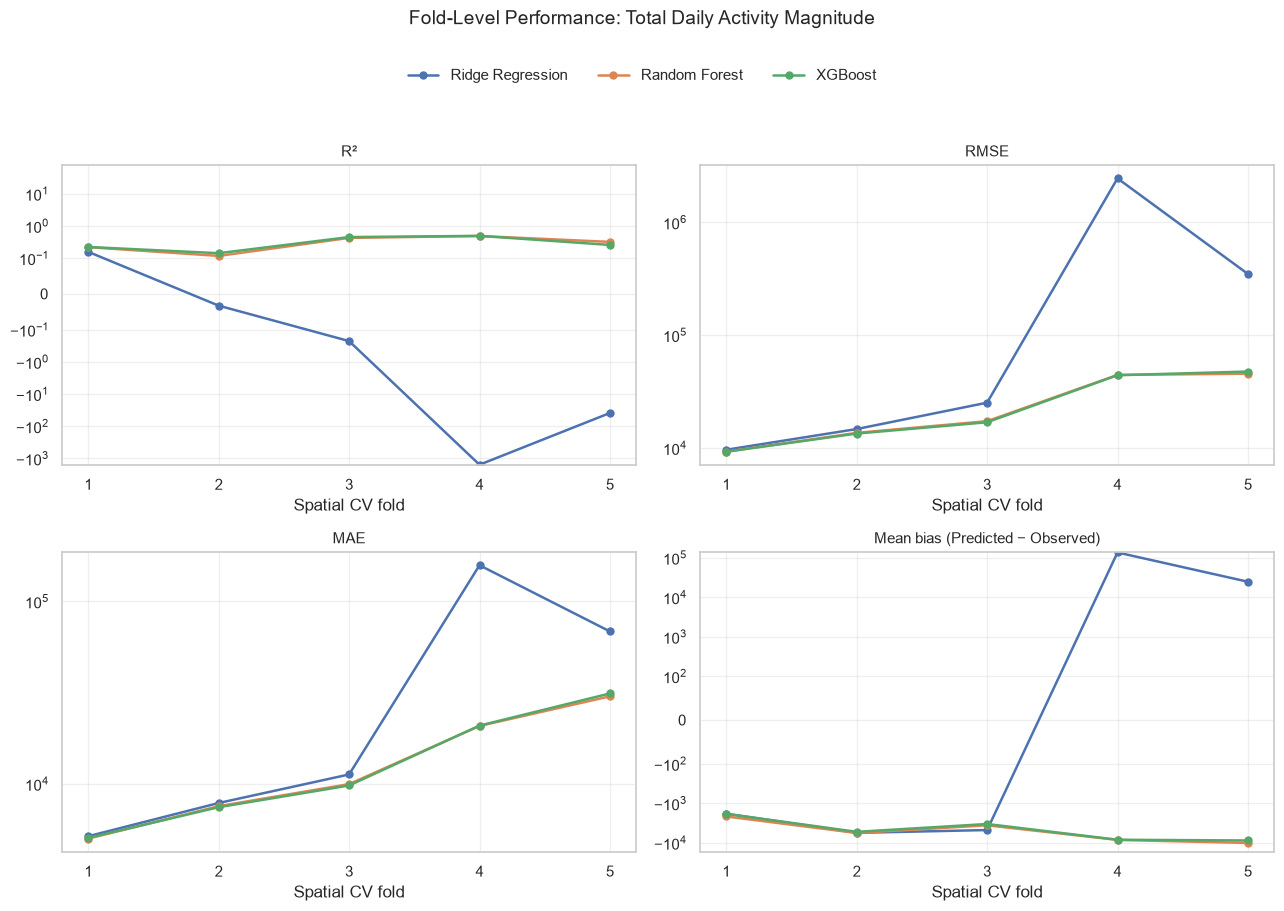

Saved: C:\Users\sanojan\Desktop\Research\Colombo_Gampaha_Final\Figure_4_5_Daily_Fold_Performance.png


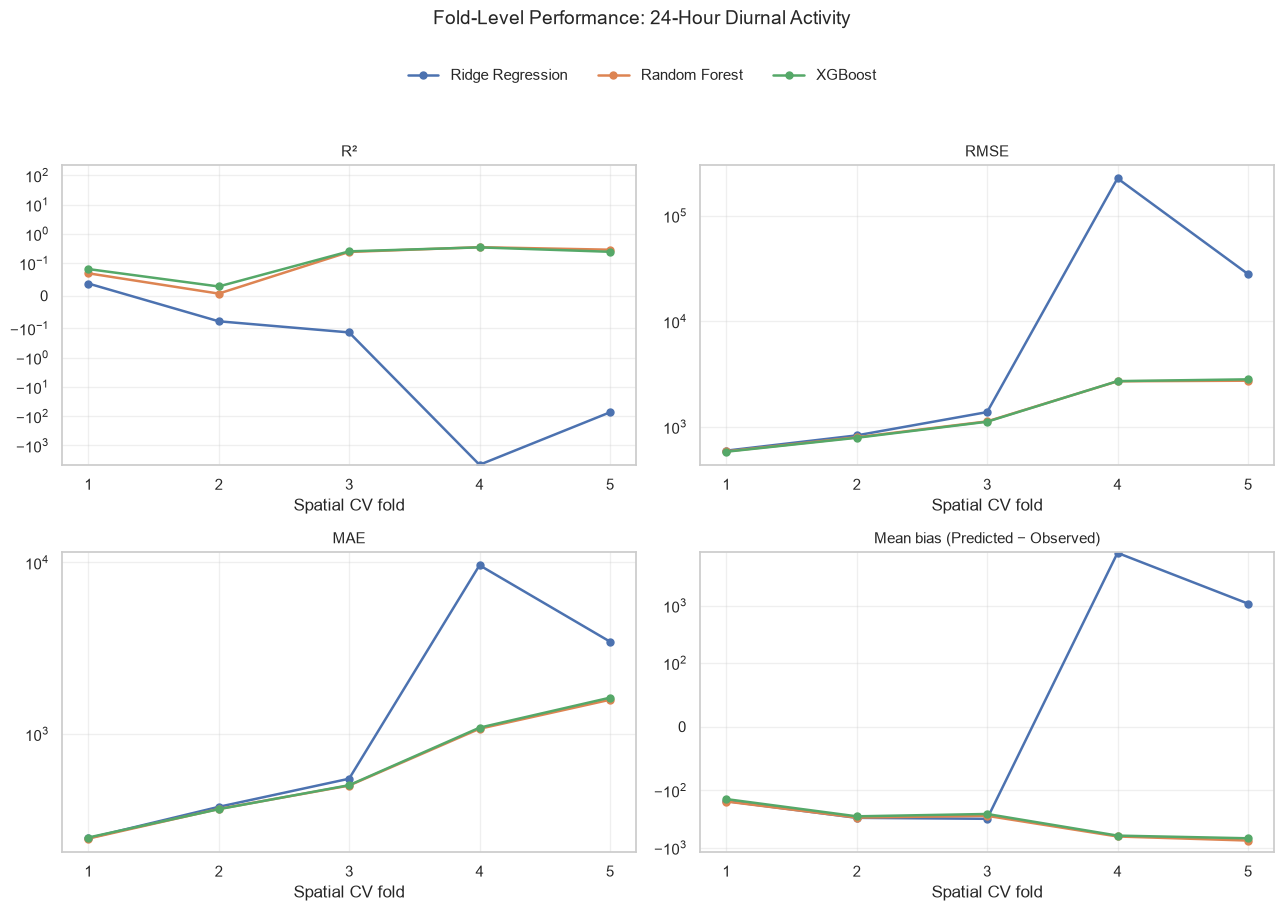

Saved: C:\Users\sanojan\Desktop\Research\Colombo_Gampaha_Final\Figure_4_6_Hourly_Fold_Performance.png


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. DAILY ACTIVITY MAGNITUDE
# --------------------------------------------------

daily_data = [
    ["Ridge Regression", 1, 0.1556, 9637.49, 5155.64, -1844.01],
    ["Ridge Regression", 2, -0.0331, 14709.53, 7844.04, -5618.38],
    ["Ridge Regression", 3, -0.2278, 25191.33, 11248.78, -4777.54],
    ["Ridge Regression", 4, -1575.6619, 2450977.71, 157948.25, 136187.39],
    ["Ridge Regression", 5, -38.9908, 348394.07, 68474.67, 24678.75],

    ["Random Forest", 1, 0.2181, 9273.89, 5003.19, -2163.76],
    ["Random Forest", 2, 0.1164, 13603.70, 7534.23, -5668.12],
    ["Random Forest", 3, 0.4226, 17275.01, 9957.72, -3623.19],
    ["Random Forest", 4, 0.4833, 44368.98, 20753.92, -8482.80],
    ["Random Forest", 5, 0.3175, 45513.56, 30170.62, -10152.22],

    ["XGBoost", 1, 0.2208, 9258.29, 5045.52, -1855.60],
    ["XGBoost", 2, 0.1414, 13409.81, 7438.06, -5301.04],
    ["XGBoost", 3, 0.4482, 16888.27, 9784.89, -3354.79],
    ["XGBoost", 4, 0.4885, 44145.90, 20842.82, -8409.66],
    ["XGBoost", 5, 0.2551, 47548.10, 31284.60, -8779.44],
]

# --------------------------------------------------
# 2. 24-HOUR DIURNAL ACTIVITY
# --------------------------------------------------

hourly_data = [
    ["Ridge Regression", 1, 0.0374, 594.01, 246.35, -154.19],
    ["Ridge Regression", 2, -0.0786, 828.51, 375.59, -301.93],
    ["Ridge Regression", 3, -0.1387, 1377.34, 548.09, -314.11],
    ["Ridge Regression", 4, -4562.2375, 225991.58, 9629.89, 8289.11],
    ["Ridge Regression", 5, -74.0473, 28044.35, 3454.83, 1082.63],

    ["Random Forest", 1, 0.0688, 584.25, 245.27, -156.72],
    ["Random Forest", 2, 0.0064, 795.17, 365.12, -299.52],
    ["Random Forest", 3, 0.2408, 1124.64, 499.91, -278.60],
    ["Random Forest", 4, 0.3498, 2697.55, 1071.58, -638.83],
    ["Random Forest", 5, 0.2871, 2733.42, 1581.97, -751.83],

    ["XGBoost", 1, 0.0818, 580.16, 248.83, -142.20],
    ["XGBoost", 2, 0.0283, 786.39, 363.97, -284.28],
    ["XGBoost", 3, 0.2521, 1116.24, 502.49, -258.68],
    ["XGBoost", 4, 0.3450, 2707.60, 1087.77, -616.60],
    ["XGBoost", 5, 0.2437, 2815.25, 1626.69, -686.42],
]

columns = ["Model", "Fold", "R2", "RMSE", "MAE", "Bias"]
daily = pd.DataFrame(daily_data, columns=columns)
hourly = pd.DataFrame(hourly_data, columns=columns)

# --------------------------------------------------
# 3. FUNCTION TO CREATE EACH FIGURE
# --------------------------------------------------

def create_performance_figure(df, title, filename):

    metrics = [
        ("R2", "R²"),
        ("RMSE", "RMSE"),
        ("MAE", "MAE"),
        ("Bias", "Mean bias (Predicted − Observed)")
    ]

    models = ["Ridge Regression", "Random Forest", "XGBoost"]

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    axes = axes.flatten()

    for ax, (metric, label) in zip(axes, metrics):

        for model in models:
            subset = df[df["Model"] == model].sort_values("Fold")

            ax.plot(
                subset["Fold"],
                subset[metric],
                marker="o",
                linewidth=1.8,
                markersize=5,
                label=model
            )

        ax.set_title(label, fontsize=11)
        ax.set_xlabel("Spatial CV fold")
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.grid(True, alpha=0.3)

        # Scale adjustments for extreme Ridge values
        if metric in ["RMSE", "MAE"]:
            ax.set_yscale("log")

        elif metric in ["R2", "Bias"]:
            ax.set_yscale("symlog", linthresh=0.1 if metric == "R2" else 100)

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=3,
        frameon=False,
        bbox_to_anchor=(0.5, 0.96)
    )

    fig.suptitle(title, fontsize=14, y=1.01)
    fig.tight_layout(rect=[0, 0, 1, 0.92])

    output = Path(filename)
    fig.savefig(output, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {output.resolve()}")


# --------------------------------------------------
# 4. EXPORT TWO SEPARATE FIGURES
# --------------------------------------------------

create_performance_figure(
    daily,
    "Fold-Level Performance: Total Daily Activity Magnitude",
    "Figure_4_5_Daily_Fold_Performance.png"
)

create_performance_figure(
    hourly,
    "Fold-Level Performance: 24-Hour Diurnal Activity",
    "Figure_4_6_Hourly_Fold_Performance.png"
)

# Optional: export the numerical tables as CSV files
daily.to_csv("Table_4_5_Daily_Fold_Performance.csv", index=False)
hourly.to_csv("Table_4_6_Hourly_Fold_Performance.csv", index=False)
